# NV05 – Phân tích hàng tồn kho

### Hướng dẫn đọc và chạy bản bàn giao — 15/11/2026

**Nội dung hiện hành:** NV05.1–5: sản phẩm–tháng, độ phủ, snapshot, lượng/cờ nguồn và đối chiếu giao dịch. Bảng giới hạn đi cùng kết luận, chưa phát lệnh bổ sung tồn.

**Đọc nhanh để trình bày:** **Cấu trúc và độ phủ inventory** — ô 1, ID `nv051-01`; **Snapshot và biến động thành phần mẫu** — ô 28, ID `nv052-01`; **Các lượng và chỉ báo tồn kho** — ô 61, ID `nv053-f01818d8`; **Đối chiếu giao dịch và snapshot liền tháng** — ô 92, ID `nv054-eefbcfd7`; **Kết luận và giới hạn tồn kho** — ô 120, ID `nv055-4555ccdf`. Có thể dùng mục lục của Jupyter/VS Code để đến tiêu đề tương ứng; mọi bảng/hình/kết luận cần thiết đã nằm trong notebook. Chi tiết kiểm toán dài được giữ để truy vết, không cần trình chiếu toàn bộ. Đề xuất liên nghiệp vụ và KPI đánh giá xem [TH01.5](TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb#th01-step4-01).

**Chạy lại:** dùng Python ≥3.11, cài `python -m pip install -r requirements.txt` từ project root; trong VS Code/Jupyter chọn kernel của môi trường đó, rồi **Restart Kernel → Run All**. Chạy NV01→NV06→TH01, không cần biến tạo tay. Mở từ project root hoặc `notebook/04_phan_tich_kinh_doanh/`; các cell tự tìm root qua thư mục cha. Không lưu đè output lịch sử khi chỉ kiểm chứng; chạy trên bản sao ngoài repository nếu cần lưu lượt mới. Chưa chứng nhận cài đặt trên môi trường sạch hoặc mọi phiên bản trong khoảng requirements.

**Đầu vào:** CSV gốc, hai bảng tiền xử lý ở data/processed khi phần phân tích cần, và notebook hàm dùng chung.

**Cách đọc phạm vi:** Không điền tháng thiếu hoặc suy vắng snapshot thành tồn0/hết hàng. units_sold chưa thay quantity; tương quan cao hoặc residual0 chưa xác nhận kho vật lý. Tổng snapshot không là luồng tồn theo năm.

**Lịch sử và kiểm chứng hiện tại:** các phát biểu “chưa triển khai” trong phần nối trước mô tả thời điểm của phần đó; ưu tiên phạm vi hiện hành ở đây. Output/execution_count/metadata cũ được bảo toàn. Các mốc lịch sử cần đối chiếu được lưu trong notebook hàm dùng chung.

---

## NV05.1 – Tổng quan dữ liệu tồn kho và cấu trúc nghiệp vụ

**Phạm vi hiện tại (đồng bộ 15/11/2026):** NV05.1–NV05.5 đã có: cấu trúc kho, biến động, đối chiếu bán hàng, tín hiệu bổ sung và tổng hợp. Các chỉ số vòng quay/stockout/overstock thực tế hay mức nhập tối ưu vẫn chưa đủ cơ sở. Không suy diễn tồn vắng bản ghi bằng 0.

Đọc lại inventory và products; orders/order_items chỉ phục vụ khóa, phạm vi quan sát và **một ví dụ xác nhận** từ đối chiếu V04 đã lưu. Không tái chạy toàn bộ đối soát bán hàng V04; số liệu toàn bộ đối chiếu được dẫn lại khi hash ba nguồn và các kiểm chứng V04 còn khớp. V05 dùng làm đối chiếu nhãn reorder, không gọi CLI hoặc ghi lại báo cáo.

Mọi kết luận về kho chỉ là diễn giải sơ bộ theo trường và giá trị quan sát. Nhãn có chữ stock/sold/reorder không thay định nghĩa nghiệp vụ đã xác nhận. Kỳ hoặc sản phẩm vắng bản ghi không được điền mức tồn bằng 0. Giữ mọi bản ghi, kể cả cực trị; không xây dựng nhãn, đặc trưng hay mô hình học máy.

Chạy bằng **Restart Kernel → Run All** từ gốc repo hoặc thư mục notebook; đường dẫn tự tìm gốc qua `data/raw/inventory.csv`. Bảng/biểu đồ lưu trực tiếp trong notebook; không xuất tệp phụ.

### Đồng bộ với tiền xử lý chung GD2 — 15/11/2026

GD2 đã nghiệm thu tại commit `fdff37f`, hợp đồng `2.3.1.3-v1`; 139/139 là số kiểm thử của lần nghiệm thu GD2, không phải số chạy lại trong notebook này. Tham chiếu `docs/gd2/preprocessing_contract.md`, `docs/gd2/handoff.md` và báo cáo `docs/reviews/bai_toan_1_gd2_step2_20261115.md`.

`orders_common`: 646.945 dòng, khóa order_id, 30 cột; `order_items_common`: 714.669 dòng, khóa item_row_id, 19 cột. Đọc bằng `src.preprocessing.delivery.read_processed` và schema tương ứng; `\N` là NULL, ID là chuỗi và tiền là Decimal. Giữ 16 lần lặp thêm của cặp đơn–sản phẩm và cả hai slot mã. Tổng Payment/Refund ở cấp đơn; không cộng tiền cấp đơn sau JOIN nhiều dòng hàng.

Quy ước chung: Gross = quantity × unit_price; Discount là số tiền giảm dòng hàng; Net = Gross − Discount, chưa trừ Refund. Payment và Refund là giá trị ghi nhận, chưa là quyết toán/thực thu. Không có bản ghi Returns thì refund_amount_observed là NULL, không phải xác nhận hoàn bằng 0. COGS kiểm chứng từ danh mục phải tách khỏi sales.COGS; ĐVT tiền nguồn vẫn chưa xác minh. Các điều kiện/phát hiện nghiệp vụ thiếu chứng từ không được đóng chỉ vì GD2 hoàn tất.

Giữ các ledger raw để đối chứng độc lập, các kiểm tra khóa/JOIN và xử lý riêng theo nghiệp vụ. Chưa thay toàn bộ nguồn bằng view chung. Output/execution_count/metadata trên đĩa là bằng chứng lịch sử, được bảo toàn; kết quả chạy kiểm chứng Bước 2 được lưu riêng trong báo cáo và hồ sơ JSON. Các ghi chú “chưa triển khai” theo từng lần nối phần ở bên dưới mô tả lịch sử tại thời điểm đó, không thay thế trạng thái hiện tại ở đầu notebook.

Hai view GD2 không định nghĩa sổ kho hay xử lý độ phủ inventory. Giữ lịch quan sát, cặp sản phẩm–kỳ, đối chiếu sold_qty với lượng đặt/delivered, residual và reorder riêng; returned_quantity không tự là hàng nhập lại kho. Không đổi mẫu số chỉ vì chuyển view.


In [1]:
import sys,csv,json,hashlib,math,statistics,calendar
from pathlib import Path
from decimal import Decimal,InvalidOperation
from datetime import datetime
from collections import Counter,defaultdict
sys.dont_write_bytecode=True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
get_ipython().run_line_magic('matplotlib','inline')
from pathlib import Path
import json
import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next(
    (path for path in (start, *start.parents)
     if (path / "notebook/00_ham_dung_chung.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")

support_file = ROOT / "notebook/00_ham_dung_chung.ipynb"
support_doc = json.loads(support_file.read_text(encoding="utf-8"))
loader = "".join(support_doc["cells"][1]["source"])
exec(compile(loader, str(support_file), "exec"), {"SUPPORT_FILE": support_file})
from datathon.runtime import read_reference, reference_path

from datathon.notebook_integrity import load_notebook_for_audit, snapshot_files
TARGET=ROOT/'notebook/04_phan_tich_kinh_doanh/NV05_phan_tich_hang_ton_kho.ipynb'
paths={name:ROOT/f'data/raw/{name}.csv' for name in ['inventory','products','orders','order_items']}
def sha(path):
    with path.open('rb') as stream:return hashlib.file_digest(stream,'sha256').hexdigest()
def protected_snapshot():
    excluded={'.git','__pycache__','.ipynb_checkpoints'}
    return {p.relative_to(ROOT).as_posix():sha(p) for p in ROOT.rglob('*') if p.is_file() and p!=TARGET and not (set(p.relative_to(ROOT).parts)&excluded)}
protected_before=protected_snapshot()
source_hashes={name:sha(path) for name,path in paths.items()}
report_paths={name:reference_path(f'reports/tables/gd1/validations/{name}.json') for name in ['v04','v05']}
report_hashes={name:sha(path) for name,path in report_paths.items()}
v04=json.loads(report_paths['v04'].read_bytes());v05=json.loads(report_paths['v05'].read_bytes())
v04_hash_match=all(source_hashes[name]==info['sha256'] for name,info in v04['sources'].items())
v05_hash_match=source_hashes['inventory']==v05['sources']['inventory']['sha256']
assert v04_hash_match and v05_hash_match and v04['checks'] and all(v04['checks'].values()) and all(v05['checks'].values())
headers={}
for name,path in paths.items():
    with path.open(encoding='utf-8-sig',newline='') as stream:headers[name]=next(csv.reader(stream))
    assert len(headers[name])==len(set(headers[name])) and all(c.strip() for c in headers[name])
def read_source(name,cols=None):
    return pd.read_csv(paths[name],encoding='utf-8-sig',dtype='string',keep_default_na=False,
        skip_blank_lines=False,on_bad_lines='error',low_memory=False,usecols=cols)
inventory=read_source('inventory');inventory_original=inventory.copy(deep=True)
products=read_source('products')
orders=read_source('orders',['order_id','order_date'])
items=read_source('order_items',['order_id','product_id','quantity'])
inferred_inventory=pd.read_csv(paths['inventory'],encoding='utf-8-sig',low_memory=False)
MISSING={'','null','none','na','n/a','nan','<na>'};ZERO=Decimal('0')
def missing_mask(series):return series.isna()|series.str.strip().str.casefold().isin(MISSING)
table_count=figure_count=0
def vn(value,digits=0):
    if value is None or pd.isna(value):return '—'
    return format(value,f',.{digits}f').replace(',','_').replace('.',',').replace('_','.')
def pct(n,d):return 100*n/d if d else float('nan')
def note(text):display(Markdown(text))
def show(title,frame,formats=None):
    global table_count
    table_count+=1;note('**'+title+'**')
    with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
        display(frame.style.format(formats or {},na_rep='—').hide(axis='index'))
def plot_done(fig):
    global figure_count
    figure_count+=1;fig.tight_layout();display(fig);plt.close(fig)
source_table=pd.DataFrame([{'Nguồn':name,'Dòng đọc':len(frame),'Trường thực có trong CSV':', '.join(headers[name]),
    'Trường đọc cho NV05.1':', '.join(frame.columns),'SHA-256 khớp mốc':v04_hash_match if name in v04['sources'] else 'Nguồn products đọc mới; bảo toàn hash'}
    for name,frame in [('inventory',inventory),('products',products),('orders',orders),('order_items',items)]])
show('Nguồn NV05.1 — toàn bộ dòng CSV; bảng tham chiếu chỉ dùng khóa/phạm vi và một ví dụ V04',source_table)
note(f"V04: **{v04['status']}**, V05: **{v05['status']}**; hash nguồn khớp và các kiểm chứng kỹ thuật đã lưu đều đạt. "
    "Trạng thái V04 có khác biệt số học, không có nghĩa dữ liệu bán và inventory đã đồng nhất. "
    "Các số V04 dẫn lại ở NV05.1.7 được phân biệt với phép tính mới của notebook này.")

**Nguồn NV05.1 — toàn bộ dòng CSV; bảng tham chiếu chỉ dùng khóa/phạm vi và một ví dụ V04**

Nguồn,Dòng đọc,Trường thực có trong CSV,Trường đọc cho NV05.1,SHA-256 khớp mốc
inventory,60247,"snapshot_date, product_id, stock_on_hand, units_received, units_sold, stockout_days, days_of_supply, fill_rate, stockout_flag, overstock_flag, reorder_flag, sell_through_rate, product_name, category, segment, year, month","snapshot_date, product_id, stock_on_hand, units_received, units_sold, stockout_days, days_of_supply, fill_rate, stockout_flag, overstock_flag, reorder_flag, sell_through_rate, product_name, category, segment, year, month",True
products,2412,"product_id, product_name, category, segment, size, color, price, cogs","product_id, product_name, category, segment, size, color, price, cogs",Nguồn products đọc mới; bảo toàn hash
orders,646945,"order_id, order_date, customer_id, zip, order_status, payment_method, device_type, order_source","order_id, order_date",True
order_items,714669,"order_id, product_id, quantity, unit_price, discount_amount, promo_id, promo_id_2","order_id, product_id, quantity",True


V04: **completed_with_differences**, V05: **completed_with_assessment**; hash nguồn khớp và các kiểm chứng kỹ thuật đã lưu đều đạt. Trạng thái V04 có khác biệt số học, không có nghĩa dữ liệu bán và inventory đã đồng nhất. Các số V04 dẫn lại ở NV05.1.7 được phân biệt với phép tính mới của notebook này.

### NV05.1.1 – Trường thực tế, kiểu đọc và chất lượng cấu trúc

CSV không khai báo kiểu. Cột “kiểu suy ra” là kết quả Pandas đọc mặc định; dữ liệu phân tích được đọc dạng chuỗi để giữ mã và nhãn gốc, các biến số/ngày tạo riêng. Thiếu được đếm bằng NULL thật hoặc các chuỗi rỗng/NULL/NA thông dụng sau bỏ khoảng trắng và không phân biệt hoa thường; không sửa chuỗi nguồn.

Các nghĩa dưới đây chỉ dựa trên tên và giá trị. `stock_on_hand` có thể mô tả mức tồn ghi nhận, `units_received`/`units_sold` có thể mô tả lượng nhận/bán của kỳ; chưa xác nhận thời điểm, đơn vị vật lý, quy tắc trạng thái hoặc sổ kế toán kho. `days_of_supply`, `fill_rate`, `sell_through_rate` và các flag có thể là trường dẫn xuất, nhưng **chưa tái lập hay xác minh công thức/chính sách**. Không dùng chúng để kết luận hiệu suất kho ở bước này.

In [2]:
meaning={
 'snapshot_date':('Thời gian','Ngày mang tên snapshot_date','Nhãn kỳ hay thời điểm kiểm kê/cập nhật thực tế?'),
 'product_id':('Mã tham chiếu','Mã sản phẩm','Có khóa dòng và khóa kho/địa điểm ở nguồn khác không?'),
 'stock_on_hand':('Số đếm dự kiến','Mức tồn ghi nhận theo tên trường','Đầu/cuối kỳ, khả dụng/vật lý, đơn vị và phạm vi kho?'),
 'units_received':('Số đếm dự kiến','Lượng nhận ghi nhận theo tên trường','Định nghĩa nhận hàng, phạm vi kỳ và điều chỉnh?'),
 'units_sold':('Số đếm dự kiến','Lượng mang tên bán trong inventory','Có cùng phạm vi/đơn vị/ghi nhận với quantity của đơn không?'),
 'stockout_days':('Số ngày dự kiến','Số ngày mang nhãn stockout','Ngày lịch hay ngày hoạt động; tiêu chí stockout là gì?'),
 'days_of_supply':('Đại lượng liên tục','Số mang nhãn số ngày cung ứng','Mẫu số tốc độ bán, thời gian và công thức?'),
 'fill_rate':('Tỷ số ghi nhận','Tỷ số mang nhãn fill_rate','Tử số, mẫu số và mốc dịch vụ nào?'),
 'stockout_flag':('Cờ nguồn','Nhãn stockout_flag','Chưa xác minh là thiếu hàng thực tế hoặc quy tắc kích hoạt.'),
 'overstock_flag':('Cờ nguồn','Nhãn overstock_flag','Chưa xác minh là dư tồn thực tế hoặc ngưỡng chính thức.'),
 'reorder_flag':('Cờ nguồn','Nhãn reorder_flag','Nghĩa 0/1, trạng thái hoạt động và quy tắc tạo nhãn?'),
 'sell_through_rate':('Tỷ số ghi nhận','Tỷ số mang nhãn sell-through','Công thức, mẫu số và phạm vi kỳ nào?'),
 'product_name':('Nhãn mô tả','Tên nguồn của sản phẩm','Không mặc định tên là khóa duy nhất.'),
 'category':('Nhãn mô tả','Danh mục nguồn','Lịch sử nhãn và định nghĩa danh mục?'),
 'segment':('Nhãn mô tả','Phân nhóm sản phẩm nguồn','Định nghĩa, thời điểm phân nhóm?'),
 'year':('Nhãn thời gian','Năm ghi riêng','Có khớp năm snapshot_date không?'),
 'month':('Nhãn thời gian','Tháng ghi riêng','Không dùng month một mình để phân biệt nhiều năm.')}
schema=pd.DataFrame([{'Trường':c,'Kiểu đọc giữ nguồn':str(inventory[c].dtype),'Kiểu Pandas suy ra':str(inferred_inventory[c].dtype),
    'Vai trò sơ bộ':meaning.get(c,('Chưa phân loại','',''))[0],'Ý nghĩa sơ bộ':meaning.get(c,('','Chưa xác định',''))[1],
    'NULL/thiếu quy ước':int(missing_mask(inventory[c]).sum()),'% thiếu / dòng inventory':pct(int(missing_mask(inventory[c]).sum()),len(inventory)),
    'Phân biệt không thiếu':inventory.loc[~missing_mask(inventory[c]),c].nunique(),
    'Ví dụ nhãn gốc':'; '.join(repr(x) for x in inventory[c].drop_duplicates().head(3)),
    'Cần xác minh':meaning.get(c,('','','Cần từ điển nguồn'))[2]} for c in inventory.columns])
show('Cấu trúc inventory — N là toàn bộ dòng inventory, nghĩa trường chưa được xác nhận nghiệp vụ',schema,{'% thiếu / dòng inventory':lambda x:vn(x,3)})
numeric_columns=[c for c in inventory if c in ['stock_on_hand','units_received','units_sold','stockout_days','days_of_supply','fill_rate','sell_through_rate','stockout_flag','overstock_flag','reorder_flag','year','month']]
count_columns=['stock_on_hand','units_received','units_sold','stockout_days']
flag_columns=['stockout_flag','overstock_flag','reorder_flag']
def parse_number(text):
    if text is None or pd.isna(text) or str(text).strip().casefold() in MISSING:return None,'missing'
    try:value=Decimal(str(text))
    except InvalidOperation:return None,'non_numeric'
    return (value,'finite') if value.is_finite() else (None,'non_finite')
numeric={};numeric_quality_rows=[]
for c in numeric_columns:
    parsed=[parse_number(x) for x in inventory[c]];vals=[v for v,state in parsed if state=='finite']
    numeric[c]=pd.Series([v for v,_ in parsed],index=inventory.index,dtype=object)
    numeric_quality_rows.append({'Trường':c,'Mẫu số dòng':len(inventory),'Hữu hạn hợp lệ cú pháp':len(vals),
        'Thiếu':sum(state=='missing' for _,state in parsed),'Sai cú pháp':sum(state=='non_numeric' for _,state in parsed),
        'Không hữu hạn':sum(state=='non_finite' for _,state in parsed),'Âm':sum(v<0 for v in vals),'Bằng 0':sum(v==0 for v in vals),
        'Dương':sum(v>0 for v in vals),'Không nguyên':sum(v!=v.to_integral_value() for v in vals),
        'Kỳ vọng khảo sát':'Số đếm nguyên (chưa là quy tắc nghiệp vụ)' if c in count_columns else 'Nhãn 0/1 khảo sát' if c in flag_columns else 'Nhãn năm/tháng' if c in ['year','month'] else 'Đại lượng liên tục; chưa xác minh công thức'})
numeric_quality=pd.DataFrame(numeric_quality_rows)
show('Khả năng chuyển số và phân loại dấu — mọi dòng; âm/không nguyên là mô tả, chưa tự coi lỗi nghiệp vụ',numeric_quality)
duplicate_full=int(inventory.duplicated().sum())
assert list(inventory.columns)==headers['inventory'] and len(inventory)==len(inferred_inventory)
assert numeric_quality[['Thiếu','Sai cú pháp','Không hữu hạn']].to_numpy().sum()==0,'Dừng tổng hợp: phải trình bày và làm rõ giá trị không dùng được, không loại dòng.'
note(f"**Quan sát/bằng chứng:** {vn(len(inventory))} dòng × {len(inventory.columns)} cột; {int(schema['NULL/thiếu quy ước'].sum())} ô thiếu, "
    f"{duplicate_full} dòng trùng hoàn toàn. Các cột số đều chuyển được và hữu hạn. "
    "**Ý nghĩa:** có thể mô tả dữ liệu theo đơn vị ghi nhận, nhưng kiểu số không xác nhận nghĩa kho. "
    "**Giới hạn:** miền không âm/nguyên của số đếm và [0;1] của tỷ số mới là kỳ vọng khảo sát; không xóa âm hoặc cực trị nếu xuất hiện. "
    "**Câu hỏi tiếp:** có từ điển trường, công thức và lịch ghi nhận nào để xác minh từng đại lượng?")

**Cấu trúc inventory — N là toàn bộ dòng inventory, nghĩa trường chưa được xác nhận nghiệp vụ**

Trường,Kiểu đọc giữ nguồn,Kiểu Pandas suy ra,Vai trò sơ bộ,Ý nghĩa sơ bộ,NULL/thiếu quy ước,% thiếu / dòng inventory,Phân biệt không thiếu,Ví dụ nhãn gốc,Cần xác minh
snapshot_date,string,object,Thời gian,Ngày mang tên snapshot_date,0,"0,000",126,'2022-10-31'; '2022-11-30'; '2022-12-31',Nhãn kỳ hay thời điểm kiểm kê/cập nhật thực tế?
product_id,string,int64,Mã tham chiếu,Mã sản phẩm,0,"0,000",1624,'1'; '3'; '4',Có khóa dòng và khóa kho/địa điểm ở nguồn khác không?
stock_on_hand,string,int64,Số đếm dự kiến,Mức tồn ghi nhận theo tên trường,0,"0,000",1895,'3'; '35'; '36',"Đầu/cuối kỳ, khả dụng/vật lý, đơn vị và phạm vi kho?"
units_received,string,int64,Số đếm dự kiến,Lượng nhận ghi nhận theo tên trường,0,"0,000",360,'1'; '13'; '11',"Định nghĩa nhận hàng, phạm vi kỳ và điều chỉnh?"
units_sold,string,int64,Số đếm dự kiến,Lượng mang tên bán trong inventory,0,"0,000",303,'1'; '11'; '10',Có cùng phạm vi/đơn vị/ghi nhận với quantity của đơn không?
stockout_days,string,int64,Số ngày dự kiến,Số ngày mang nhãn stockout,0,"0,000",29,'2'; '1'; '0',Ngày lịch hay ngày hoạt động; tiêu chí stockout là gì?
days_of_supply,string,float64,Đại lượng liên tục,Số mang nhãn số ngày cung ứng,0,"0,000",9289,'90.0'; '95.5'; '108.0',"Mẫu số tốc độ bán, thời gian và công thức?"
fill_rate,string,float64,Tỷ số ghi nhận,Tỷ số mang nhãn fill_rate,0,"0,000",29,'0.9333'; '0.9667'; '1.0',"Tử số, mẫu số và mốc dịch vụ nào?"
stockout_flag,string,int64,Cờ nguồn,Nhãn stockout_flag,0,"0,000",2,'1'; '0',Chưa xác minh là thiếu hàng thực tế hoặc quy tắc kích hoạt.
overstock_flag,string,int64,Cờ nguồn,Nhãn overstock_flag,0,"0,000",2,'0'; '1',Chưa xác minh là dư tồn thực tế hoặc ngưỡng chính thức.


**Khả năng chuyển số và phân loại dấu — mọi dòng; âm/không nguyên là mô tả, chưa tự coi lỗi nghiệp vụ**

Trường,Mẫu số dòng,Hữu hạn hợp lệ cú pháp,Thiếu,Sai cú pháp,Không hữu hạn,Âm,Bằng 0,Dương,Không nguyên,Kỳ vọng khảo sát
stock_on_hand,60247,60247,0,0,0,0,0,60247,0,Số đếm nguyên (chưa là quy tắc nghiệp vụ)
units_received,60247,60247,0,0,0,0,0,60247,0,Số đếm nguyên (chưa là quy tắc nghiệp vụ)
units_sold,60247,60247,0,0,0,0,0,60247,0,Số đếm nguyên (chưa là quy tắc nghiệp vụ)
stockout_days,60247,60247,0,0,0,0,19676,40571,0,Số đếm nguyên (chưa là quy tắc nghiệp vụ)
days_of_supply,60247,60247,0,0,0,0,0,60247,22784,Đại lượng liên tục; chưa xác minh công thức
fill_rate,60247,60247,0,0,0,0,0,60247,40571,Đại lượng liên tục; chưa xác minh công thức
stockout_flag,60247,60247,0,0,0,0,19676,40571,0,Nhãn 0/1 khảo sát
overstock_flag,60247,60247,0,0,0,0,14305,45942,0,Nhãn 0/1 khảo sát
reorder_flag,60247,60247,0,0,0,0,60247,0,0,Nhãn 0/1 khảo sát
sell_through_rate,60247,60247,0,0,0,0,0,60247,60247,Đại lượng liên tục; chưa xác minh công thức


**Quan sát/bằng chứng:** 60.247 dòng × 17 cột; 0 ô thiếu, 0 dòng trùng hoàn toàn. Các cột số đều chuyển được và hữu hạn. **Ý nghĩa:** có thể mô tả dữ liệu theo đơn vị ghi nhận, nhưng kiểu số không xác nhận nghĩa kho. **Giới hạn:** miền không âm/nguyên của số đếm và [0;1] của tỷ số mới là kỳ vọng khảo sát; không xóa âm hoặc cực trị nếu xuất hiện. **Câu hỏi tiếp:** có từ điển trường, công thức và lịch ghi nhận nào để xác minh từng đại lượng?

### NV05.1.2 – Đơn vị quan sát và khóa ứng viên

Kiểm tra từng mã riêng và các tổ hợp, không chọn đơn vị chỉ từ tên tệp. `product_id` là mã tham chiếu duy nhất có mặt; không thấy mã bản ghi riêng hoặc cột kho/địa điểm trong 17 cột thực tế. Tạo nhãn tháng từ ngày hợp lệ rồi kiểm tra cả khóa sản phẩm–ngày và sản phẩm–tháng. Phép đếm cặp phân biệt chỉ phục vụ kiểm tra, không khử trùng dữ liệu nguồn.

Một tổ hợp duy nhất trong tệp là **khóa ứng viên đã kiểm chứng trên dữ liệu này**, chưa chứng minh hợp đồng khóa của hệ thống nguồn. Nếu không có cột kho, không suy rằng mỗi bản ghi là toàn bộ tồn kho doanh nghiệp hoặc một sự kiện nhập/xuất.

In [3]:
required={'snapshot_date','product_id','year','month','stock_on_hand','units_received','units_sold','reorder_flag'}
assert required<=set(inventory)
lexical=inventory.snapshot_date.str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
snapshot_day=pd.to_datetime(inventory.snapshot_date.where(lexical),format='%Y-%m-%d',errors='coerce')
invalid_dates=int((~missing_mask(inventory.snapshot_date)&snapshot_day.isna()).sum())
assert snapshot_day.notna().all(),'Ngày không dùng được: không bỏ bản ghi để tiếp tục.'
work=inventory.copy(deep=True)
work['_source_row']=np.arange(len(work))+2
work['snapshot_day']=snapshot_day
work['period']=snapshot_day.dt.to_period('M')
work['period_label']=work.period.astype(str)
year_mismatch=sum(v!=Decimal(int(y)) for v,y in zip(numeric['year'],snapshot_day.dt.year))
month_mismatch=sum(v!=Decimal(int(m)) for v,m in zip(numeric['month'],snapshot_day.dt.month))
def key_profile(frame,cols):
    return {'Dòng':len(frame),'Khóa thiếu':int(frame[cols].apply(missing_mask).any(axis=1).sum()),
        'Tổ hợp phân biệt':len(frame.drop_duplicates(cols)),'Dòng dư do lặp':int(frame.duplicated(cols).sum()),
        'Mọi dòng thuộc khóa lặp':int(frame.duplicated(cols,keep=False).sum())}
key_specs=[(['product_id'],'Mã sản phẩm, thiếu kỳ'),(['snapshot_date'],'Ngày chung của nhiều sản phẩm'),
    (['year','month'],'Kỳ chung của nhiều sản phẩm'),(['product_id','snapshot_date'],'Khóa ứng viên theo ngày nguồn'),
    (['product_id','year','month'],'Khóa ứng viên nếu năm/tháng khớp ngày'),(['product_id','period_label'],'Khóa ứng viên sản phẩm–tháng dẫn xuất'),
    (['product_name','snapshot_date'],'Kiểm tra khả năng dùng tên thay mã')]
key_table=pd.DataFrame([{'Khóa ứng viên':' + '.join(cols),**key_profile(work,cols),'Đánh giá':label} for cols,label in key_specs])
show('Khóa ứng viên inventory — cùng N dòng, không xóa dòng trùng hoặc tự cộng nhiều dòng vào một cặp',key_table)
pair_counts=work.groupby(['product_id','period_label'],sort=True).size()
pair_repeated=int(pair_counts.gt(1).sum())
has_record_id=bool({'inventory_id','snapshot_id','record_id'}&set(inventory))
warehouse_fields=[c for c in inventory if c in ['warehouse_id','warehouse','store_id','location_id','location','warehouse_name']]
note(f"**Quan sát/bằng chứng:** {work.product_id.nunique()} sản phẩm, {work.period.nunique()} tháng, {vn(len(pair_counts))} cặp; "
    f"{pair_repeated} cặp có nhiều dòng. Mã bản ghi riêng: {has_record_id}; cột kho/địa điểm nhận diện: {warehouse_fields}. "
    f"Năm/tháng không khớp ngày: {year_mismatch}/{month_mismatch} dòng. "
    "**Ý nghĩa:** dữ liệu hiện có một dòng cho mỗi product_id–tháng quan sát; ngày nguồn cũng phân biệt duy nhất trên từng sản phẩm. "
    "Tên sản phẩm không thay mã vì có tổ hợp tên–ngày bị lặp. "
    "**Giới hạn:** chưa biết bản ghi tổng nhiều kho hay một phạm vi khác, và chưa có hợp đồng khóa hệ thống. "
    "**Câu hỏi tiếp:** nguồn tạo snapshot, cấp kho và lịch sử cập nhật có thể được cung cấp không?")
assert not work.duplicated(['product_id','period_label']).any() and year_mismatch==month_mismatch==0

**Khóa ứng viên inventory — cùng N dòng, không xóa dòng trùng hoặc tự cộng nhiều dòng vào một cặp**

Khóa ứng viên,Dòng,Khóa thiếu,Tổ hợp phân biệt,Dòng dư do lặp,Mọi dòng thuộc khóa lặp,Đánh giá
product_id,60247,0,1624,58623,60137,"Mã sản phẩm, thiếu kỳ"
snapshot_date,60247,0,126,60121,60247,Ngày chung của nhiều sản phẩm
year + month,60247,0,126,60121,60247,Kỳ chung của nhiều sản phẩm
product_id + snapshot_date,60247,0,60247,0,0,Khóa ứng viên theo ngày nguồn
product_id + year + month,60247,0,60247,0,0,Khóa ứng viên nếu năm/tháng khớp ngày
product_id + period_label,60247,0,60247,0,0,Khóa ứng viên sản phẩm–tháng dẫn xuất
product_name + snapshot_date,60247,0,58483,1764,3346,Kiểm tra khả năng dùng tên thay mã


**Quan sát/bằng chứng:** 1624 sản phẩm, 126 tháng, 60.247 cặp; 0 cặp có nhiều dòng. Mã bản ghi riêng: False; cột kho/địa điểm nhận diện: []. Năm/tháng không khớp ngày: 0/0 dòng. **Ý nghĩa:** dữ liệu hiện có một dòng cho mỗi product_id–tháng quan sát; ngày nguồn cũng phân biệt duy nhất trên từng sản phẩm. Tên sản phẩm không thay mã vì có tổ hợp tên–ngày bị lặp. **Giới hạn:** chưa biết bản ghi tổng nhiều kho hay một phạm vi khác, và chưa có hợp đồng khóa hệ thống. **Câu hỏi tiếp:** nguồn tạo snapshot, cấp kho và lịch sử cập nhật có thể được cung cấp không?

### NV05.1.3 – Phạm vi và độ hạt thời gian quan sát

Ngày phải đúng ISO `YYYY-MM-DD` và tồn tại trong lịch. Kiểm tra năm/tháng ghi riêng, ngày đầu/cuối tháng, số ngày nguồn khác nhau trong mỗi tháng và các tháng toàn cục vắng bản ghi. Mẫu quan sát có thể nhận diện độ hạt **tháng với nhãn ngày cuối tháng**; chưa xác nhận đó là ngày kiểm kê thực tế, thời điểm vật lý hay timestamp trích xuất.

Bảng năm đếm kỳ và sản phẩm, không cộng mức tồn qua thời gian. Bảng tháng chỉ chọn các tháng biên cùng 5 tháng ít/nhiều bản ghi nhất; bảng đầy đủ vẫn ở trong bộ nhớ và được kiểm chứng. Biểu đồ mô tả **độ phủ bản ghi**, không là xu hướng lượng tồn hoặc hiệu suất kho.

**Phạm vi ngày và tháng thực có — N là mọi bản ghi inventory, không khẳng định ngày kiểm kê**

Trường thời gian,Dòng có ngày hợp lệ,Thiếu,Sai định dạng/ngày lịch,Ngày đầu,Ngày cuối,Ngày nguồn phân biệt,Tháng phân biệt,Dòng ngày đầu tháng,Dòng ngày cuối tháng,Tháng toàn cục không có dòng
snapshot_date,60247,0,0,2012-07-31,2022-12-31,126,126,0,60247,0


**Độ phủ theo năm snapshot_date — số dòng, sản phẩm và tháng, không cộng lượng tồn**

Năm,Dòng inventory,Sản phẩm phân biệt trong năm,Tháng có bản ghi
2012,2539,543,6
2013,5570,655,12
2014,5787,692,12
2015,5872,705,12
2016,5927,726,12
2017,6084,737,12
2018,6106,758,12
2019,5835,782,12
2020,5686,827,12
2021,5609,827,12


**Tháng biên và tháng có độ phủ thấp/cao — mẫu số tỷ lệ là mọi mã trong products**

Tháng nguồn,Dòng inventory,Sản phẩm phân biệt,Ngày nguồn phân biệt trong tháng,% / danh mục products
2012-07,395,395,1,"16,376"
2012-08,423,423,1,"17,537"
2018-04,550,550,1,"22,803"
2018-05,562,562,1,"23,300"
2018-06,550,550,1,"22,803"
2020-01,383,383,1,"15,879"
2021-01,377,377,1,"15,630"
2021-03,551,551,1,"22,844"
2021-04,548,548,1,"22,720"
2021-11,389,389,1,"16,128"


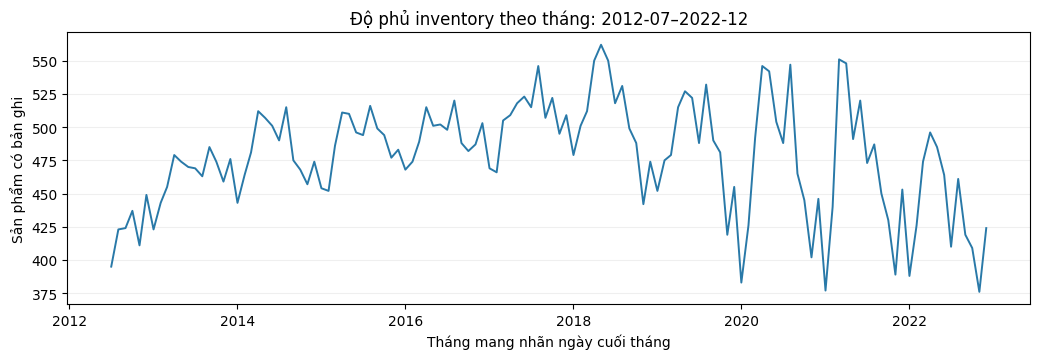

**Quan sát/bằng chứng:** 31/07/2012–31/12/2022, 126 tháng; 60.247/60.247 dòng mang ngày cuối tháng; 0 tháng toàn cục vắng bản ghi. Độ phủ từng tháng từ 376 đến 562 sản phẩm; 2012 chỉ có 6 tháng. **Ý nghĩa:** có lịch tháng để khảo sát tiếp, nhưng tập sản phẩm quan sát thay đổi; không dùng biến động số dòng làm biến động lượng tồn. **Giới hạn:** tháng hiện diện không chứng minh mọi sản phẩm/kho có đủ dữ liệu; kỳ vắng không là tồn 0. **Câu hỏi tiếp:** sản phẩm nào thuộc phạm vi ghi nhận bắt buộc từng kỳ và nhãn cuối tháng được tạo khi nào?

In [4]:
all_periods=pd.period_range(work.period.min(),work.period.max(),freq='M')
observed_periods=set(work.period)
missing_global_periods=sorted(set(all_periods)-observed_periods)
period_table=work.groupby('period',sort=True).agg(rows=('product_id','size'),products=('product_id','nunique'),source_days=('snapshot_date','nunique'))
period_table['% / danh mục products']=100*period_table.products/products.product_id.nunique()
year_table=work.assign(snapshot_year=snapshot_day.dt.year).groupby('snapshot_year').agg(rows=('product_id','size'),products=('product_id','nunique'),periods=('period','nunique'))
date_summary=pd.DataFrame([{'Trường thời gian':'snapshot_date','Dòng có ngày hợp lệ':int(snapshot_day.notna().sum()),
    'Thiếu':int(missing_mask(inventory.snapshot_date).sum()),'Sai định dạng/ngày lịch':invalid_dates,
    'Ngày đầu':str(snapshot_day.min().date()),'Ngày cuối':str(snapshot_day.max().date()),'Ngày nguồn phân biệt':snapshot_day.nunique(),
    'Tháng phân biệt':len(observed_periods),'Dòng ngày đầu tháng':int(snapshot_day.dt.is_month_start.sum()),
    'Dòng ngày cuối tháng':int(snapshot_day.dt.is_month_end.sum()),'Tháng toàn cục không có dòng':len(missing_global_periods)}])
show('Phạm vi ngày và tháng thực có — N là mọi bản ghi inventory, không khẳng định ngày kiểm kê',date_summary)
show('Độ phủ theo năm snapshot_date — số dòng, sản phẩm và tháng, không cộng lượng tồn',year_table.reset_index().rename(columns={
    'snapshot_year':'Năm','rows':'Dòng inventory','products':'Sản phẩm phân biệt trong năm','periods':'Tháng có bản ghi'}))
selected_periods=sorted(set(period_table.head(2).index)|set(period_table.tail(2).index)|set(period_table.nsmallest(5,'rows').index)|set(period_table.nlargest(5,'rows').index))
month_display=period_table.loc[selected_periods].reset_index().rename(columns={'period':'Tháng nguồn','rows':'Dòng inventory','products':'Sản phẩm phân biệt','source_days':'Ngày nguồn phân biệt trong tháng'})
month_display['Tháng nguồn']=month_display['Tháng nguồn'].astype(str)
show('Tháng biên và tháng có độ phủ thấp/cao — mẫu số tỷ lệ là mọi mã trong products',month_display,{'% / danh mục products':lambda x:vn(x,3)})
fig,ax=plt.subplots(figsize=(10.5,3.7))
ax.plot(period_table.index.to_timestamp(),period_table.products,color='#2979a8',linewidth=1.4)
ax.set(title=f'Độ phủ inventory theo tháng: {all_periods.min()}–{all_periods.max()}',xlabel='Tháng mang nhãn ngày cuối tháng',
    ylabel='Sản phẩm có bản ghi')
ax.grid(axis='y',alpha=.2);plot_done(fig)
note(f"**Quan sát/bằng chứng:** {snapshot_day.min():%d/%m/%Y}–{snapshot_day.max():%d/%m/%Y}, {len(observed_periods)} tháng; "
    f"{vn(int(snapshot_day.dt.is_month_end.sum()))}/{vn(len(work))} dòng mang ngày cuối tháng; "
    f"{len(missing_global_periods)} tháng toàn cục vắng bản ghi. Độ phủ từng tháng từ {int(period_table.products.min())} "
    f"đến {int(period_table.products.max())} sản phẩm; 2012 chỉ có {int(year_table.loc[2012,'periods'])} tháng. "
    "**Ý nghĩa:** có lịch tháng để khảo sát tiếp, nhưng tập sản phẩm quan sát thay đổi; không dùng biến động số dòng làm biến động lượng tồn. "
    "**Giới hạn:** tháng hiện diện không chứng minh mọi sản phẩm/kho có đủ dữ liệu; kỳ vắng không là tồn 0. "
    "**Câu hỏi tiếp:** sản phẩm nào thuộc phạm vi ghi nhận bắt buộc từng kỳ và nhãn cuối tháng được tạo khi nào?")
assert period_table.rows.sum()==year_table.rows.sum()==len(work)

### NV05.1.4 – Độ phủ sản phẩm và những kỳ không quan sát

Xác minh product_id trong products duy nhất/không thiếu trước khi nối nhiều–một. Chỉ lấy tên/category/segment để kiểm tra nhãn trùng lặp giữa hai nguồn, không phân tích hiệu quả theo danh mục. Dùng mã, không nối bằng tên.

Số tháng/sản phẩm được mô tả trên **các sản phẩm thực sự có inventory**; các sản phẩm thuộc products nhưng không có inventory được báo riêng. “Kỳ vắng bên trong khoảng quan sát” = số tháng lịch từ kỳ đầu đến kỳ cuối của một sản phẩm trừ số tháng có dòng. Đây là vị trí chưa quan sát, **chưa là bản ghi bắt buộc bị mất**; không tính thời gian trước lần đầu/sau lần cuối là lỗi. Không gán mức tồn 0 vào các vị trí này.

Ba trạng thái được tách riêng: không có bản ghi, có dòng với stock_on_hand=0, có dòng với stock_on_hand thiếu. Hai trạng thái sau có thể giao nhau ở cấp sản phẩm nếu xuất hiện tại các kỳ khác nhau; không cộng chúng thành một phân hoạch.

**Độ phủ và ba trạng thái khác nhau — sản phẩm không có dòng, stock=0 và stock thiếu**

Trạng thái/chỉ tiêu,Số lượng,Đơn vị/mẫu số
Mã product_id trong products,2412,Mã trong danh mục products
Mã có inventory,1624,Mã / 2412 mã products
Mã inventory không thuộc products,0,Mã inventory
Mã products không có inventory,788,Mã products; không tự gán stock=0
Có dòng stock_on_hand=0,0,Sản phẩm / 1624 sản phẩm có inventory; 0 dòng
Có dòng stock_on_hand thiếu,0,Sản phẩm / 1624 sản phẩm có inventory; 0 dòng
Có đủ tất cả tháng trong phạm vi toàn cục,22,Sản phẩm / 1624 có inventory
Có kỳ vắng bên trong khoảng đầu–cuối,1302,Sản phẩm; 25456 vị trí sản phẩm–tháng chưa quan sát


**Số tháng quan sát trên từng sản phẩm — chỉ tập có inventory, không thêm sản phẩm vắng thành dòng tồn 0**

Mẫu số sản phẩm có inventory,Min tháng,Max tháng,Mean tháng,Median tháng,P25 tháng,P75 tháng,Chỉ một tháng,Không quá 6 tháng,Nhãn sản phẩm không khớp products
1624,1,126,"37,0979",27.000000,12.000000,53.000000,110,302,0


**Phân bố số tháng quan sát — mẫu số là sản phẩm có inventory; tổng dòng được bảo toàn**

Nhóm số tháng,Sản phẩm,Dòng nguồn trong nhóm,Tổng tháng–sản phẩm quan sát,% / sản phẩm có inventory
1 tháng,110,110,110,"6,773"
2–6 tháng,192,730,730,"11,823"
7–12 tháng,122,1159,1159,"7,512"
13–24 tháng,343,6382,6382,"21,121"
25–60 tháng,512,20365,20365,"31,527"
61–125 tháng,323,28729,28729,"19,889"
126 tháng,22,2772,2772,"1,355"


**Ví dụ độ phủ giới hạn 15 sản phẩm — đồng hạng chọn mã dạng chuỗi tăng dần, ô thiếu giữ là không quan sát**

Tiêu chí,Mã sản phẩm,Dòng inventory,Tháng có dòng,Kỳ đầu,Kỳ cuối,Khoảng đầu–cuối (tháng),Tháng vắng trong khoảng,% / 126 tháng toàn cục,Tên nguồn
5 sản phẩm ít tháng nhất,1029,1.000000,1.000000,2012-08,2012-08,1.000000,0.000000,"0,794",MekongStyle UC-01
5 sản phẩm ít tháng nhất,1035,1.000000,1.000000,2012-09,2012-09,1.000000,0.000000,"0,794",MekongStyle UC-07
5 sản phẩm ít tháng nhất,1037,1.000000,1.000000,2013-07,2013-07,1.000000,0.000000,"0,794",MekongStyle UC-09
5 sản phẩm ít tháng nhất,1048,1.000000,1.000000,2021-08,2021-08,1.000000,0.000000,"0,794",MekongFit MA-06
5 sản phẩm ít tháng nhất,1054,1.000000,1.000000,2020-08,2020-08,1.000000,0.000000,"0,794",MekongFit MA-12
5 sản phẩm nhiều tháng nhất,1053,126.000000,126.000000,2012-07,2022-12,126.000000,0.000000,"100,000",MekongFit MA-11
5 sản phẩm nhiều tháng nhất,1085,126.000000,126.000000,2012-07,2022-12,126.000000,0.000000,"100,000",MekongFit RP-31
5 sản phẩm nhiều tháng nhất,1086,126.000000,126.000000,2012-07,2022-12,126.000000,0.000000,"100,000",MekongFit RP-32
5 sản phẩm nhiều tháng nhất,1182,126.000000,126.000000,2012-07,2022-12,126.000000,0.000000,"100,000",MekongFit UE-18
5 sản phẩm nhiều tháng nhất,2054,126.000000,126.000000,2012-07,2022-12,126.000000,0.000000,"100,000",UrbanVN UE-14


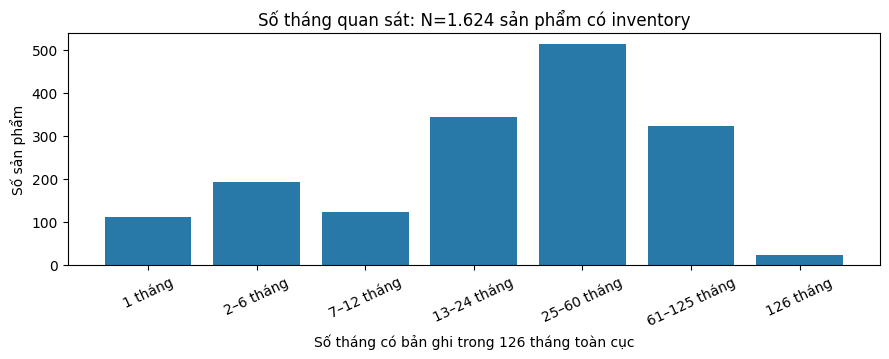

**Quan sát/bằng chứng:** 1.624/2.412 sản phẩm có inventory; 788 mã vắng. Mean/median số tháng 37,0979/27; 110 sản phẩm chỉ một tháng, 22 sản phẩm đủ 126 tháng. 1302 sản phẩm có 25.456 vị trí tháng vắng bên trong khoảng. JOIN giữ 60.247 dòng; khác nhãn tên/category/segment: {'product_name': 0, 'category': 0, 'segment': 0}. **Ý nghĩa:** có thể khảo sát tiếp nhưng cần giữ cùng tập sản phẩm hoặc công bố độ phủ khi so kỳ. **Giới hạn:** không biết vòng đời sản phẩm/lịch báo cáo bắt buộc; mã vắng không chứng minh ngừng bán hoặc hết hàng. **Câu hỏi tiếp:** sản phẩm được đưa vào/ra phạm vi quan sát theo quy tắc nào và các khoảng vắng có dữ liệu ở nguồn khác không?

In [5]:
assert products.product_id.is_unique and not missing_mask(products.product_id).any()
inv_product_ids=set(inventory.product_id);catalog_ids=set(products.product_id)
orphan_product_ids=inv_product_ids-catalog_ids;catalog_without_inventory=catalog_ids-inv_product_ids
assert not orphan_product_ids
joined=work.merge(products[['product_id','product_name','category','segment']],on='product_id',how='left',validate='many_to_one',suffixes=('_inventory','_products'),sort=False)
assert len(joined)==len(work) and joined._source_row.is_unique
attribute_mismatch={c:int(joined[c+'_inventory'].ne(joined[c+'_products']).sum()) for c in ['product_name','category','segment']}
coverage=work.groupby('product_id',sort=True).agg(rows=('period','size'),periods=('period','nunique'),first=('period','min'),last=('period','max'))
coverage['calendar_span']=[last.ordinal-first.ordinal+1 for first,last in zip(coverage['first'],coverage['last'])]
coverage['internal_unobserved']=coverage.calendar_span-coverage.periods
coverage['observed_pct_global']=100*coverage.periods/len(all_periods)
zero_stock_mask=numeric['stock_on_hand'].eq(0)
missing_stock_mask=missing_mask(inventory.stock_on_hand)
coverage_scale=pd.DataFrame([
 {'Trạng thái/chỉ tiêu':'Mã product_id trong products','Số lượng':len(catalog_ids),'Đơn vị/mẫu số':'Mã trong danh mục products'},
 {'Trạng thái/chỉ tiêu':'Mã có inventory','Số lượng':len(inv_product_ids),'Đơn vị/mẫu số':f'Mã / {len(catalog_ids)} mã products'},
 {'Trạng thái/chỉ tiêu':'Mã inventory không thuộc products','Số lượng':len(orphan_product_ids),'Đơn vị/mẫu số':'Mã inventory'},
 {'Trạng thái/chỉ tiêu':'Mã products không có inventory','Số lượng':len(catalog_without_inventory),'Đơn vị/mẫu số':'Mã products; không tự gán stock=0'},
 {'Trạng thái/chỉ tiêu':'Có dòng stock_on_hand=0','Số lượng':inventory.loc[zero_stock_mask,'product_id'].nunique(),'Đơn vị/mẫu số':f'Sản phẩm / {len(inv_product_ids)} sản phẩm có inventory; {int(zero_stock_mask.sum())} dòng'},
 {'Trạng thái/chỉ tiêu':'Có dòng stock_on_hand thiếu','Số lượng':inventory.loc[missing_stock_mask,'product_id'].nunique(),'Đơn vị/mẫu số':f'Sản phẩm / {len(inv_product_ids)} sản phẩm có inventory; {int(missing_stock_mask.sum())} dòng'},
 {'Trạng thái/chỉ tiêu':'Có đủ tất cả tháng trong phạm vi toàn cục','Số lượng':int(coverage.periods.eq(len(all_periods)).sum()),'Đơn vị/mẫu số':f'Sản phẩm / {len(inv_product_ids)} có inventory'},
 {'Trạng thái/chỉ tiêu':'Có kỳ vắng bên trong khoảng đầu–cuối','Số lượng':int(coverage.internal_unobserved.gt(0).sum()),'Đơn vị/mẫu số':f'Sản phẩm; {int(coverage.internal_unobserved.sum())} vị trí sản phẩm–tháng chưa quan sát'}])
show('Độ phủ và ba trạng thái khác nhau — sản phẩm không có dòng, stock=0 và stock thiếu',coverage_scale)
coverage_stats=pd.DataFrame([{'Mẫu số sản phẩm có inventory':len(coverage),'Min tháng':int(coverage.periods.min()),'Max tháng':int(coverage.periods.max()),
    'Mean tháng':coverage.periods.mean(),'Median tháng':coverage.periods.median(),'P25 tháng':coverage.periods.quantile(.25),'P75 tháng':coverage.periods.quantile(.75),
    'Chỉ một tháng':int(coverage.periods.eq(1).sum()),'Không quá 6 tháng':int(coverage.periods.le(6).sum()),'Nhãn sản phẩm không khớp products':sum(attribute_mismatch.values())}])
show('Số tháng quan sát trên từng sản phẩm — chỉ tập có inventory, không thêm sản phẩm vắng thành dòng tồn 0',coverage_stats,{'Mean tháng':lambda x:vn(x,4)})
def coverage_bucket(n):
    return '1 tháng' if n==1 else '2–6 tháng' if n<=6 else '7–12 tháng' if n<=12 else '13–24 tháng' if n<=24 else '25–60 tháng' if n<=60 else '61–125 tháng' if n<126 else '126 tháng'
coverage_bucket_order=['1 tháng','2–6 tháng','7–12 tháng','13–24 tháng','25–60 tháng','61–125 tháng','126 tháng']
coverage_dist=coverage.assign(bucket=coverage.periods.map(coverage_bucket)).groupby('bucket').agg(products=('periods','size'),rows=('rows','sum'),observed_months=('periods','sum')).reindex(coverage_bucket_order)
coverage_dist['% / sản phẩm có inventory']=100*coverage_dist.products/len(coverage)
show('Phân bố số tháng quan sát — mẫu số là sản phẩm có inventory; tổng dòng được bảo toàn',coverage_dist.reset_index().rename(columns={
    'bucket':'Nhóm số tháng','products':'Sản phẩm','rows':'Dòng nguồn trong nhóm','observed_months':'Tổng tháng–sản phẩm quan sát'}),{'% / sản phẩm có inventory':lambda x:vn(x,3)})
coverage_examples=[]
for label,part in [('5 sản phẩm ít tháng nhất',coverage.reset_index().sort_values(['periods','product_id'],ascending=[True,True]).head(5)),
    ('5 sản phẩm nhiều tháng nhất',coverage.reset_index().sort_values(['periods','product_id'],ascending=[False,True]).head(5))]:
    for row in part.to_dict('records'):coverage_examples.append({'Tiêu chí':label,**row})
for pid in sorted(catalog_without_inventory)[:5]:coverage_examples.append({'Tiêu chí':'5 mã products không có inventory','product_id':pid})
example_coverage=pd.DataFrame(coverage_examples).merge(products[['product_id','product_name']],on='product_id',how='left',validate='many_to_one')
show('Ví dụ độ phủ giới hạn 15 sản phẩm — đồng hạng chọn mã dạng chuỗi tăng dần, ô thiếu giữ là không quan sát',example_coverage.rename(columns={
    'product_id':'Mã sản phẩm','product_name':'Tên nguồn','rows':'Dòng inventory','periods':'Tháng có dòng','first':'Kỳ đầu','last':'Kỳ cuối',
    'calendar_span':'Khoảng đầu–cuối (tháng)','internal_unobserved':'Tháng vắng trong khoảng','observed_pct_global':'% / 126 tháng toàn cục'}),{'% / 126 tháng toàn cục':lambda x:vn(x,3)})
fig,ax=plt.subplots(figsize=(9,3.7))
ax.bar(coverage_dist.index,coverage_dist.products,color='#2979a8')
ax.set(title=f'Số tháng quan sát: N={vn(len(coverage))} sản phẩm có inventory',xlabel='Số tháng có bản ghi trong 126 tháng toàn cục',ylabel='Số sản phẩm')
ax.tick_params(axis='x',rotation=25);plot_done(fig)
note(f"**Quan sát/bằng chứng:** {vn(len(inv_product_ids))}/{vn(len(catalog_ids))} sản phẩm có inventory; {vn(len(catalog_without_inventory))} mã vắng. "
    f"Mean/median số tháng {vn(coverage.periods.mean(),4)}/{vn(coverage.periods.median())}; {int(coverage.periods.eq(1).sum())} sản phẩm chỉ một tháng, "
    f"{int(coverage.periods.eq(len(all_periods)).sum())} sản phẩm đủ {len(all_periods)} tháng. "
    f"{int(coverage.internal_unobserved.gt(0).sum())} sản phẩm có {vn(int(coverage.internal_unobserved.sum()))} vị trí tháng vắng bên trong khoảng. "
    f"JOIN giữ {vn(len(joined))} dòng; khác nhãn tên/category/segment: {attribute_mismatch}. "
    "**Ý nghĩa:** có thể khảo sát tiếp nhưng cần giữ cùng tập sản phẩm hoặc công bố độ phủ khi so kỳ. "
    "**Giới hạn:** không biết vòng đời sản phẩm/lịch báo cáo bắt buộc; mã vắng không chứng minh ngừng bán hoặc hết hàng. "
    "**Câu hỏi tiếp:** sản phẩm được đưa vào/ra phạm vi quan sát theo quy tắc nào và các khoảng vắng có dữ liệu ở nguồn khác không?")
assert coverage_dist.products.sum()==len(inv_product_ids) and coverage_dist.rows.sum()==len(work)

### NV05.1.5 – Phân bố số lượng và các đại lượng số khác

Bốn trường số đếm dự kiến được tách với ba đại lượng liên tục/tỷ số. Mẫu số thống kê là **dòng sản phẩm–tháng có số hữu hạn**, không phải số sản phẩm hoặc số ngày. Mean theo dòng không tự là mean của từng sản phẩm; không cộng các snapshot qua tháng rồi gọi là tổng tồn vật lý toàn kỳ.

Độ lệch chuẩn mẫu dùng `N−1`; phân vị nội suy tuyến tính tại `(N−1)×p`. Gắn cờ cực trị bằng hàng rào `P75 + 1,5×(P75−P25)`, chỉ là quy tắc mô tả, không là xác nhận sai dữ liệu hoặc ngưỡng nghiệp vụ. Giữ các giá trị ngoài hàng rào. Biểu đồ sử dụng mọi số hữu hạn của stock_on_hand và units_sold, trục giá trị log khi tất cả dương; không cắt tại P99.

**Thống kê theo dòng inventory — đơn vị gốc theo tên trường; số đếm/ngày/tỷ số chưa được xác minh nghiệp vụ**

Trường,N hữu hạn,Min,Max,Mean,Median,Std mẫu,P25,P75,P90,P95,P99,Hàng rào IQR trên,Dòng vượt hàng rào
stock_on_hand,60247,"3,0000","2.673,0000","189,2985","62,0000","316,9761","15,0000","210,0000","532,0000","820,7000","1.525,0800","502,5000",6432
units_received,60247,"1,0000","817,0000","18,0468","6,0000","34,0802","2,0000","19,0000","47,0000","75,0000","163,0000","44,5000",6392
units_sold,60247,"1,0000","670,0000","15,4178","6,0000","28,4044","2,0000","16,0000","39,0000","63,0000","135,0000","37,0000",6388
stockout_days,60247,"0,0000","28,0000","1,1606","1,0000","1,6245","0,0000","2,0000","2,0000","2,0000","7,0000","5,0000",724
days_of_supply,60247,"5,2000","68.100,0000","912,6776","240,0000","2.587,6241","96,0000","683,1000","1.926,1200","3.660,0000","12.030,0000","1.563,7500",7455
fill_rate,60247,"0,0667","1,0000","0,9613","0,9667","0,0542","0,9333","1,0000","1,0000","1,0000","1,0000","1,1000",0
sell_through_rate,60247,"0,0004","0,8531","0,1523","0,1111","0,1393","0,0421","0,2381","0,3500","0,4348","0,6000","0,5321",1284


**Bốn cực đại có mã/ngày truy vết — chỉ minh họa, không loại hoặc thay giá trị**

Trường,Cực đại ghi nhận,Số dòng đồng cực đại,Mã sản phẩm minh họa,Ngày nguồn,Bản ghi CSV thứ,Trạng thái
stock_on_hand,"2.673,0000",1,791,2022-12-31,16920,Giữ nguyên; chưa kết luận lỗi hoặc hiệu suất
units_received,"817,0000",1,786,2012-12-31,16525,Giữ nguyên; chưa kết luận lỗi hoặc hiệu suất
units_sold,"670,0000",2,785,2012-12-31,16479,Giữ nguyên; chưa kết luận lỗi hoặc hiệu suất
days_of_supply,"68.100,0000",1,604,2020-12-31,10709,Giữ nguyên; chưa kết luận lỗi hoặc hiệu suất


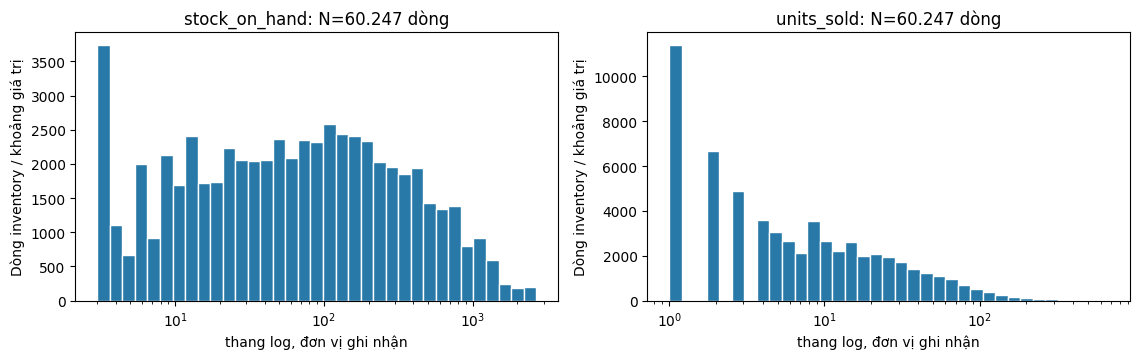

**Quan sát/bằng chứng:** stock_on_hand min/median/max 3/62/2.673; units_sold 1/6/670. days_of_supply đạt cực đại 68.100,0 ở đơn vị mang tên ngày. **Ý nghĩa:** phân bố lệch và cực trị cần được đọc trước các bước phân tích tiếp, không dùng riêng bình quân để mô tả mọi dòng. **Giới hạn:** đây là biến trong tệp, chưa xác nhận lượng vật lý, công thức KPI, tốc độ bán hay hiệu suất; không suy công thức luân chuyển tồn. **Câu hỏi tiếp:** nguồn tính và mẫu số các tỷ số/số ngày là gì, đơn vị lượng có nhất quán theo sản phẩm không?

In [6]:
quantity_fields=[c for c in ['stock_on_hand','units_received','units_sold','stockout_days','days_of_supply','fill_rate','sell_through_rate'] if c in inventory]
def quantile_exact(vals,q):
    ordered=sorted(vals);pos=Decimal(len(ordered)-1)*Decimal(str(q));lo=int(pos);hi=min(lo+1,len(ordered)-1)
    return ordered[lo]+(ordered[hi]-ordered[lo])*(pos-lo)
statistics_rows=[];extreme_thresholds={}
for c in quantity_fields:
    vals=list(numeric[c].dropna());p25=quantile_exact(vals,.25);p75=quantile_exact(vals,.75);fence=p75+Decimal('1.5')*(p75-p25)
    extreme_thresholds[c]=fence
    statistics_rows.append({'Trường':c,'N hữu hạn':len(vals),'Min':min(vals),'Max':max(vals),'Mean':statistics.mean(vals),'Median':statistics.median(vals),
        'Std mẫu':statistics.stdev(vals),'P25':p25,'P75':p75,'P90':quantile_exact(vals,.9),'P95':quantile_exact(vals,.95),'P99':quantile_exact(vals,.99),
        'Hàng rào IQR trên':fence,'Dòng vượt hàng rào':sum(v>fence for v in vals)})
quantity_statistics=pd.DataFrame(statistics_rows)
show('Thống kê theo dòng inventory — đơn vị gốc theo tên trường; số đếm/ngày/tỷ số chưa được xác minh nghiệp vụ',quantity_statistics,
    {c:lambda x:vn(x,4) for c in ['Min','Max','Mean','Median','Std mẫu','P25','P75','P90','P95','P99','Hàng rào IQR trên']})
extreme_examples=[]
for c in ['stock_on_hand','units_received','units_sold','days_of_supply']:
    vmax=max(numeric[c]);mask=numeric[c].eq(vmax)
    idx=work.loc[mask].sort_values(['product_id','snapshot_date']).index[0]
    extreme_examples.append({'Trường':c,'Cực đại ghi nhận':vmax,'Số dòng đồng cực đại':int(mask.sum()),'Mã sản phẩm minh họa':inventory.loc[idx,'product_id'],
        'Ngày nguồn':inventory.loc[idx,'snapshot_date'],'Bản ghi CSV thứ':int(idx)+2,'Trạng thái':'Giữ nguyên; chưa kết luận lỗi hoặc hiệu suất'})
show('Bốn cực đại có mã/ngày truy vết — chỉ minh họa, không loại hoặc thay giá trị',pd.DataFrame(extreme_examples),{'Cực đại ghi nhận':lambda x:vn(x,4)})
fig,axes=plt.subplots(1,2,figsize=(11.5,3.7))
for ax,c in zip(axes,['stock_on_hand','units_sold']):
    vals=np.array([float(v) for v in numeric[c]])
    if vals.min()>0:
        edges=np.geomspace(vals.min(),vals.max()+1,36);ax.hist(vals,bins=edges,color='#2979a8',edgecolor='white');ax.set_xscale('log')
        scale='thang log, đơn vị ghi nhận'
    else:ax.hist(vals,bins=50,color='#2979a8',edgecolor='white');scale='thang tuyến tính, đơn vị ghi nhận'
    ax.set(title=f'{c}: N={vn(len(vals))} dòng',xlabel=scale,ylabel='Dòng inventory / khoảng giá trị')
plot_done(fig)
note(f"**Quan sát/bằng chứng:** stock_on_hand min/median/max {vn(min(numeric['stock_on_hand']))}/"
    f"{vn(statistics.median(numeric['stock_on_hand']))}/{vn(max(numeric['stock_on_hand']))}; units_sold "
    f"{vn(min(numeric['units_sold']))}/{vn(statistics.median(numeric['units_sold']))}/{vn(max(numeric['units_sold']))}. "
    f"days_of_supply đạt cực đại {vn(max(numeric['days_of_supply']),1)} ở đơn vị mang tên ngày. "
    "**Ý nghĩa:** phân bố lệch và cực trị cần được đọc trước các bước phân tích tiếp, không dùng riêng bình quân để mô tả mọi dòng. "
    "**Giới hạn:** đây là biến trong tệp, chưa xác nhận lượng vật lý, công thức KPI, tốc độ bán hay hiệu suất; không suy công thức luân chuyển tồn. "
    "**Câu hỏi tiếp:** nguồn tính và mẫu số các tỷ số/số ngày là gì, đơn vị lượng có nhất quán theo sản phẩm không?")

### NV05.1.6 – Cờ bổ sung hàng và nhãn nghiệp vụ khác

Giữ các giá trị nguồn; khảo sát miền số 0/1 như V05 nhưng chưa coi đó là quy tắc hoạt động được nghiệp vụ cam kết. Bảng phân bố ghi riêng từng flag, từng nhãn và mẫu số mọi dòng inventory. Ngoài miền khảo sát hoặc thiếu phải được báo, không tự sửa.

Nếu reorder_flag chỉ có một lớp thì **trường không cung cấp khả năng phân biệt các lớp để học mô hình dự đoán nhãn reorder trong dữ liệu hiện tại**. Điều đó không chứng minh không cần nhập hàng, không thiếu hàng, flag sai hoặc flag chưa hoạt động. Không dùng stockout_flag/overstock_flag hoặc ngưỡng lượng để tạo nhãn reorder mới; không xác nhận thiếu/dư tồn thực tế từ tên cờ.

In [7]:
flag_records=[]
for c in flag_columns:
    for raw,count in inventory[c].value_counts(dropna=False,sort=False).items():
        value,state=parse_number(raw)
        flag_records.append({'Trường cờ':c,'Nhãn nguồn (repr)':repr(raw),'Dòng':int(count),'Mẫu số dòng inventory':len(inventory),
            '% / mọi dòng':pct(int(count),len(inventory)),'Thiếu':state=='missing',
            'Ngoài miền nhị phân khảo sát':state not in ['finite','missing'] or (state=='finite' and value not in [ZERO,Decimal(1)])})
flag_distribution=pd.DataFrame(flag_records)
show('Giá trị từng cờ nguồn — toàn kỳ, mỗi flag phân loại toàn bộ dòng riêng',flag_distribution,{'% / mọi dòng':lambda x:vn(x,4)})
reorder_values=set(numeric['reorder_flag'].dropna())
reorder_has_two_classes=ZERO in reorder_values and Decimal(1) in reorder_values
reorder_is_complete_constant=not missing_mask(inventory.reorder_flag).any() and len(reorder_values)==1
reorder_zero=int(numeric['reorder_flag'].eq(0).sum())
note(f"**Quan sát/bằng chứng:** reorder_flag có {len(reorder_values)} giá trị số phân biệt, {vn(reorder_zero)}/{vn(len(inventory))} dòng bằng 0, "
    f"{int(missing_mask(inventory.reorder_flag).sum())} thiếu; khớp mốc V05 khi hash nguồn không đổi. "
    f"Có đủ hai lớp 0/1 để phân biệt: {reorder_has_two_classes}. "
    "**Ý nghĩa:** có thể mô tả trạng thái cờ được cung cấp; trường hiện không cung cấp khả năng phân biệt các lớp để học mô hình dự đoán nhãn reorder. "
    "**Giới hạn:** chưa xác minh quy tắc hoặc nhu cầu nhập hàng; flag bằng 0 không đồng nghĩa không thiếu hàng. "
    "**Câu hỏi tiếp:** nhãn phản ánh đề xuất, phê duyệt hay sự kiện nào; điều kiện và thời điểm kích hoạt được định nghĩa ra sao?")
assert reorder_zero==v05['metrics']['reorder_zero_rows'] and len(reorder_values)==v05['metrics']['observed_non_null_distinct']

**Giá trị từng cờ nguồn — toàn kỳ, mỗi flag phân loại toàn bộ dòng riêng**

Trường cờ,Nhãn nguồn (repr),Dòng,Mẫu số dòng inventory,% / mọi dòng,Thiếu,Ngoài miền nhị phân khảo sát
stockout_flag,'1',40571,60247,"67,3411",False,False
stockout_flag,'0',19676,60247,"32,6589",False,False
overstock_flag,'1',45942,60247,"76,2561",False,False
overstock_flag,'0',14305,60247,"23,7439",False,False
reorder_flag,'0',60247,60247,"100,0000",False,False


**Quan sát/bằng chứng:** reorder_flag có 1 giá trị số phân biệt, 60.247/60.247 dòng bằng 0, 0 thiếu; khớp mốc V05 khi hash nguồn không đổi. Có đủ hai lớp 0/1 để phân biệt: False. **Ý nghĩa:** có thể mô tả trạng thái cờ được cung cấp; trường hiện không cung cấp khả năng phân biệt các lớp để học mô hình dự đoán nhãn reorder. **Giới hạn:** chưa xác minh quy tắc hoặc nhu cầu nhập hàng; flag bằng 0 không đồng nghĩa không thiếu hàng. **Câu hỏi tiếp:** nhãn phản ánh đề xuất, phê duyệt hay sự kiện nào; điều kiện và thời điểm kích hoạt được định nghĩa ra sao?

### NV05.1.7 – Units_sold và xác nhận ngắn kết quả V04

Phân bố units_sold ở cấp dòng đã có trong NV05.1.5. Bảng dưới chỉ bổ sung phạm vi số dòng/số tháng trên sản phẩm và số dòng có units_sold hợp lệ trong mỗi kỳ; không tổng hợp lượng bán theo danh mục hoặc phân tích quan hệ tồn–bán.

V04 so ở **cặp exact product_id–tháng lịch**: một dòng inventory/cặp, order_items được nối vào orders nhiều–một rồi cộng quantity **trên mọi trạng thái đơn** theo tháng order_date. Chỉ so giá trị và Pearson trên **phần giao hai tập cặp**; cặp vắng một phía vẫn là không quan sát, không gán 0. `difference = inventory.units_sold − Σorder_items.quantity`. Tương quan cao không chứng minh bằng nhau hoặc cùng ngữ nghĩa.

NV05.1 đọc lại CSV để kiểm tra khóa/phạm vi và các hash, dẫn lại các thống kê đối chiếu toàn bộ từ V04 đã kiểm chứng; **không tính lại Pearson hoặc toàn bộ tổng quantity theo cặp**. Chỉ kiểm tra mới một cặp minh họa đã có trong V04 để xác nhận có sự khác nhau. Không thay units_sold, không mặc định các trạng thái đã được xử lý giống nhau và không suy tồn cuối kỳ từ chênh hai số.

In [8]:
assert orders.order_id.is_unique and not missing_mask(orders.order_id).any()
assert orders.order_date.str.fullmatch(r'\d{4}-\d{2}-\d{2}').all()
order_days=pd.to_datetime(orders.order_date,format='%Y-%m-%d',errors='coerce');assert order_days.notna().all()
order_period=orders[['order_id']].assign(order_month=order_days.dt.strftime('%Y-%m'))
item_order_orphans=int((~items.order_id.isin(orders.order_id)).sum())
item_product_orphans=int((~items.product_id.isin(products.product_id)).sum())
assert item_order_orphans==item_product_orphans==0
reference_items=items.merge(order_period,on='order_id',how='left',validate='many_to_one',sort=False)
reference_pairs=set(zip(reference_items.product_id,reference_items.order_month))
inventory_pairs=set(zip(work.product_id,work.period_label))
reference_pair_scope={'both':len(inventory_pairs&reference_pairs),'inventory_only':len(inventory_pairs-reference_pairs),'transactions_only':len(reference_pairs-inventory_pairs)}
witness_report=v04['examples']['largest_absolute_differences']['records'][0]
witness_pid=str(witness_report['product_id']);witness_month=witness_report['month']
witness_items=reference_items.loc[reference_items.product_id.eq(witness_pid)&reference_items.order_month.eq(witness_month)]
witness_transaction_quantity=sum((Decimal(x) for x in witness_items.quantity),ZERO)
witness_inv=work.loc[work.product_id.eq(witness_pid)&work.period_label.eq(witness_month)]
assert len(witness_inv)==1
witness_inventory_units=numeric['units_sold'].loc[witness_inv.index[0]]
witness_difference=witness_inventory_units-witness_transaction_quantity
v04_metrics=v04['metrics']
v04_confirmation=pd.DataFrame([
 {'Chỉ tiêu':'Cặp inventory','Giá trị':str(len(inventory_pairs)),'Mẫu số/phạm vi':'Toàn bộ sản phẩm–tháng inventory','Nguồn xác nhận':'Tính mới từ khóa CSV; khớp V04'},
 {'Chỉ tiêu':'Cặp order_items theo tháng order_date','Giá trị':str(len(reference_pairs)),'Mẫu số/phạm vi':'Mọi dòng items, không lọc trạng thái','Nguồn xác nhận':'Tính mới chỉ tập khóa; khớp V04'},
 {'Chỉ tiêu':'Giao hai nguồn','Giá trị':str(reference_pair_scope['both']),'Mẫu số/phạm vi':'Cặp có mặt cả hai phía','Nguồn xác nhận':'Tính mới chỉ phạm vi; khớp V04'},
 {'Chỉ tiêu':'Chỉ inventory / chỉ giao dịch','Giá trị':f"{reference_pair_scope['inventory_only']} / {reference_pair_scope['transactions_only']}",'Mẫu số/phạm vi':'Không điền 0 cho phía vắng','Nguồn xác nhận':'Tính mới chỉ phạm vi; khớp V04'},
 {'Chỉ tiêu':'Cặp bằng giá trị chính xác','Giá trị':f"{v04_metrics['equal_pairs']} / {v04_metrics['both_pairs']} = {vn(pct(v04_metrics['equal_pairs'],v04_metrics['both_pairs']),4)}%",'Mẫu số/phạm vi':'Chỉ phần giao; so số nguyên không dung sai','Nguồn xác nhận':'Dẫn V04; hash ba nguồn và kiểm chứng độc lập V04 còn khớp, không tính lại toàn bộ ở NV05.1'},
 {'Chỉ tiêu':'Pearson trên phần giao','Giá trị':vn(v04_metrics['pearson'],6),'Mẫu số/phạm vi':f"{v04_metrics['both_pairs']} cặp phần giao",'Nguồn xác nhận':'Dẫn V04 đã kiểm chứng; không tính lại tương quan trong NV05.1'}])
show('Xác nhận ngắn V04 — phân biệt phép kiểm tra phạm vi mới với thống kê đối chiếu dẫn lại',v04_confirmation)
witness_table=pd.DataFrame([{'Mã sản phẩm':witness_pid,'Tháng order_date/snapshot':witness_month,'Số dòng items trong ví dụ':len(witness_items),
    'Inventory.units_sold':witness_inventory_units,'Σquantity của cặp':witness_transaction_quantity,'Chênh inventory − quantity':witness_difference,
    'Trạng thái':'Tính mới một cặp đã được chọn ở V04; giữ nguyên hai đại lượng'}])
show('Một cặp kiểm tra trực tiếp từ CSV — chỉ xác nhận không thể đồng nhất hai đại lượng',witness_table)
units_profile=pd.DataFrame([{'Cấp':'Sản phẩm có inventory','Số đơn vị':len(coverage),'Min dòng/tháng quan sát':int(coverage.rows.min()),
    'Median dòng/tháng quan sát':coverage.rows.median(),'Max dòng/tháng quan sát':int(coverage.rows.max()),'Giới hạn':'Số quan sát, không là số lượng bán của sản phẩm'},
    {'Cấp':'Tháng có inventory','Số đơn vị':len(period_table),'Min dòng/tháng quan sát':int(period_table.rows.min()),
    'Median dòng/tháng quan sát':period_table.rows.median(),'Max dòng/tháng quan sát':int(period_table.rows.max()),'Giới hạn':'Các dòng units_sold hữu hạn; không cộng để suy lượng bán thực tế'}])
show('Phạm vi quan sát units_sold theo sản phẩm và kỳ — phân bố lượng trên dòng nằm ở NV05.1.5',units_profile)
note(f"**Quan sát/bằng chứng:** units_sold hữu hạn trên {vn(len(numeric['units_sold']))} dòng, không thiếu; "
    f"tham chiếu V04 bằng nhau chính xác {vn(pct(v04_metrics['equal_pairs'],v04_metrics['both_pairs']),4)}% trên giao, Pearson {vn(v04_metrics['pearson'],6)}. "
    f"Ví dụ {witness_pid}–{witness_month}: {vn(witness_inventory_units)} so {vn(witness_transaction_quantity)}, chênh {vn(witness_difference)}. "
    "**Ý nghĩa:** tương quan cao và khác biệt giá trị cùng tồn tại; không thay units_sold bằng quantity. "
    "**Giới hạn:** chưa biết cùng đại lượng/đơn vị hay cùng xử lý đơn hủy/hoàn; số liệu toàn bộ được dẫn từ V04 chứ không phải đối soát mới tại NV05.1. "
    "**Câu hỏi tiếp:** nghĩa và quy tắc ghi nhận hai trường có được thống nhất trước NV05.3–NV05.4 không?")
assert reference_pair_scope['both']==v04_metrics['both_pairs'] and reference_pair_scope['inventory_only']==v04_metrics['inventory_only_pairs'] and reference_pair_scope['transactions_only']==v04_metrics['transactions_only_pairs']
assert witness_difference==Decimal(str(witness_report['difference'])) and witness_inventory_units!=witness_transaction_quantity

**Xác nhận ngắn V04 — phân biệt phép kiểm tra phạm vi mới với thống kê đối chiếu dẫn lại**

Chỉ tiêu,Giá trị,Mẫu số/phạm vi,Nguồn xác nhận
Cặp inventory,60247,Toàn bộ sản phẩm–tháng inventory,Tính mới từ khóa CSV; khớp V04
Cặp order_items theo tháng order_date,57309,"Mọi dòng items, không lọc trạng thái",Tính mới chỉ tập khóa; khớp V04
Giao hai nguồn,56615,Cặp có mặt cả hai phía,Tính mới chỉ phạm vi; khớp V04
Chỉ inventory / chỉ giao dịch,3632 / 694,Không điền 0 cho phía vắng,Tính mới chỉ phạm vi; khớp V04
Cặp bằng giá trị chính xác,"1716 / 56615 = 3,0310%",Chỉ phần giao; so số nguyên không dung sai,"Dẫn V04; hash ba nguồn và kiểm chứng độc lập V04 còn khớp, không tính lại toàn bộ ở NV05.1"
Pearson trên phần giao,"0,989704",56615 cặp phần giao,Dẫn V04 đã kiểm chứng; không tính lại tương quan trong NV05.1


**Một cặp kiểm tra trực tiếp từ CSV — chỉ xác nhận không thể đồng nhất hai đại lượng**

Mã sản phẩm,Tháng order_date/snapshot,Số dòng items trong ví dụ,Inventory.units_sold,Σquantity của cặp,Chênh inventory − quantity,Trạng thái
786,2012-12,547,670,2502,-1832,Tính mới một cặp đã được chọn ở V04; giữ nguyên hai đại lượng


**Phạm vi quan sát units_sold theo sản phẩm và kỳ — phân bố lượng trên dòng nằm ở NV05.1.5**

Cấp,Số đơn vị,Min dòng/tháng quan sát,Median dòng/tháng quan sát,Max dòng/tháng quan sát,Giới hạn
Sản phẩm có inventory,1624,1,27.000000,126,"Số quan sát, không là số lượng bán của sản phẩm"
Tháng có inventory,126,376,481.500000,562,Các dòng units_sold hữu hạn; không cộng để suy lượng bán thực tế


**Quan sát/bằng chứng:** units_sold hữu hạn trên 60.247 dòng, không thiếu; tham chiếu V04 bằng nhau chính xác 3,0310% trên giao, Pearson 0,989704. Ví dụ 786–2012-12: 670 so 2.502, chênh -1.832. **Ý nghĩa:** tương quan cao và khác biệt giá trị cùng tồn tại; không thay units_sold bằng quantity. **Giới hạn:** chưa biết cùng đại lượng/đơn vị hay cùng xử lý đơn hủy/hoàn; số liệu toàn bộ được dẫn từ V04 chứ không phải đối soát mới tại NV05.1. **Câu hỏi tiếp:** nghĩa và quy tắc ghi nhận hai trường có được thống nhất trước NV05.3–NV05.4 không?

### NV05.1.8 – Vấn đề kỹ thuật, hiện tượng nghiệp vụ và giới hạn

Nhóm A chỉ dành cho vi phạm ràng buộc kỹ thuật đã kiểm tra, không tạo lỗi để lấp bảng. Nhóm B là hiện tượng quan sát cần làm rõ; C là thiếu định nghĩa/độ phủ để kết luận. Dòng A có số 0 được ghi rõ “không phát hiện”, không gọi đó là một lỗi tồn tại. Âm/không nguyên hoặc nhiều cờ khác nhau chưa được quy thành vi phạm nghiệp vụ nếu chưa có định nghĩa xác nhận.

In [9]:
technical_violations=duplicate_full+invalid_dates+year_mismatch+month_mismatch+len(orphan_product_ids)+int(not products.product_id.is_unique)
issues=pd.DataFrame([
 {'Mã':'A01','Nhóm':'A','Hiện tượng':'Kiểm tra cấu trúc/ngày/khóa tham chiếu không phát hiện vi phạm','Bằng chứng':f'{technical_violations} vi phạm trên các điều kiện đã kiểm tra; 0 cặp sản phẩm–tháng lặp',
  'Đơn vị phân tích':'Dòng, khóa ứng viên, mã sản phẩm','Mức độ xác minh':'Ràng buộc kỹ thuật trong tệp đã kiểm tra; không báo lỗi giả',
  'Giới hạn':'Khóa duy nhất thực nghiệm chưa là hợp đồng hệ thống; không suy mọi nghiệp vụ đều đúng','Câu hỏi cần làm rõ':'Có hợp đồng schema/khóa và cấp kho nào?','Bước tiếp':'Giữ kiểm tra khóa khi bổ sung dữ liệu'},
 {'Mã':'B01','Nhóm':'B','Hiện tượng':'Độ phủ sản phẩm khác nhau và có kỳ không quan sát','Bằng chứng':f'{len(catalog_without_inventory)} mã products không có inventory; {int(coverage.internal_unobserved.gt(0).sum())} sản phẩm có {int(coverage.internal_unobserved.sum())} tháng vắng trong khoảng đầu–cuối',
  'Đơn vị phân tích':'Sản phẩm và sản phẩm–tháng','Mức độ xác minh':'Tập khóa/kỳ đã tính; nguyên nhân chưa rõ',
  'Giới hạn':'Không biết kỳ bắt buộc, vòng đời sản phẩm; vắng không là stock=0','Câu hỏi cần làm rõ':'Cơ chế chọn sản phẩm/kỳ và dữ liệu ở nguồn khác?','Bước tiếp':'NV05.2: xác định tập so sánh và phạm vi'},
 {'Mã':'B02','Nhóm':'B','Hiện tượng':'Một số sản phẩm có rất ít kỳ','Bằng chứng':f"{int(coverage.periods.eq(1).sum())} sản phẩm một tháng; {int(coverage.periods.le(6).sum())} sản phẩm ≤6 tháng",
  'Đơn vị phân tích':'Sản phẩm có inventory','Mức độ xác minh':'Số kỳ đã kiểm chứng','Giới hạn':'Ngưỡng 6 chỉ mô tả độ phủ; chưa suy ngừng bán/hết hàng',
  'Câu hỏi cần làm rõ':'Có ngày bắt đầu/kết thúc phạm vi hay báo cáo không?','Bước tiếp':'NV05.2: ghi rõ mẫu số và lịch quan sát'},
 {'Mã':'B03','Nhóm':'B','Hiện tượng':'Giá trị cực đại và dòng ngoài hàng rào IQR được giữ','Bằng chứng':'; '.join(f"{r['Trường']}: max {vn(r['Max'],2)}, ngoài IQR {r['Dòng vượt hàng rào']} dòng" for r in statistics_rows),
  'Đơn vị phân tích':'Dòng sản phẩm–tháng, từng trường số','Mức độ xác minh':'Giá trị và ngưỡng mô tả đã tính','Giới hạn':'Cực trị không là lỗi, thiếu/dư tồn hoặc KPI tốt/xấu',
  'Câu hỏi cần làm rõ':'Đơn vị và công thức, bối cảnh sản phẩm/kỳ?','Bước tiếp':'NV05.2–NV05.4: chỉ sau xác minh phạm vi'},
 {'Mã':'C01','Nhóm':'C','Hiện tượng':'reorder_flag chỉ một giá trị','Bằng chứng':f'{reorder_zero}/{len(inventory)} dòng bằng 0; {len(reorder_values)} lớp số quan sát',
  'Đơn vị phân tích':'Dòng inventory','Mức độ xác minh':'Giá trị đã kiểm chứng, quy tắc chưa xác nhận','Giới hạn':'Không phân biệt lớp reorder; không suy không cần nhập hoặc tạo nhãn thay thế',
  'Câu hỏi cần làm rõ':'Nghĩa cờ, điều kiện, thời điểm và trạng thái kích hoạt?','Bước tiếp':'Xác minh metadata trước cân nhắc mục tiêu mô hình ở bước được giao'},
 {'Mã':'C02','Nhóm':'C','Hiện tượng':'units_sold chưa đồng nhất với quantity giao dịch','Bằng chứng':f"V04: {v04_metrics['equal_pairs']}/{v04_metrics['both_pairs']} cặp phần giao bằng nhau; một ví dụ kiểm tra mới chênh {witness_difference}",
  'Đơn vị phân tích':'Cặp sản phẩm–tháng trên phần giao','Mức độ xác minh':'V04 được bảo đảm nguồn/checks; một cặp xác nhận trực tiếp','Giới hạn':'Chưa xác minh đơn vị/trạng thái; không thay số hoặc suy tồn cuối kỳ',
  'Câu hỏi cần làm rõ':'Định nghĩa lượng bán và xử lý hủy/hoàn ở mỗi nguồn?','Bước tiếp':'NV05.3–NV05.4: đối soát sâu sau xác minh'},
 {'Mã':'C03','Nhóm':'C','Hiện tượng':'Nghĩa snapshot và các đại lượng/cờ kho chưa đủ','Bằng chứng':f'{len(inventory.columns)} trường, không có cột kho hay mã sự kiện; ngày nguồn đều cuối tháng',
  'Đơn vị phân tích':'Cấu trúc nguồn và sản phẩm–kỳ','Mức độ xác minh':'Đặc điểm tệp xác minh; ngữ nghĩa chưa đủ','Giới hạn':'Không xác nhận kiểm kê thực tế, luân chuyển, stockout/overstock hoặc hiệu suất',
  'Câu hỏi cần làm rõ':'Kho/phạm vi, lịch ghi nhận, công thức days_of_supply/fill_rate/sell_through_rate và quy tắc cờ?','Bước tiếp':'Từ điển và sự kiện kho trước NV05.2–NV05.4'}])
show('Vấn đề NV05.1 — tách kỹ thuật A, hiện tượng B và định nghĩa/giới hạn C',issues)
note(f"**Quan sát/bằng chứng:** {technical_violations} vi phạm ở tập kỹ thuật đã kiểm tra; {len(issues)} mục báo cáo có nguồn định lượng. "
    "**Ý nghĩa:** cần xử lý vấn đề định nghĩa và độ phủ trước khi đọc số lượng như hiệu suất. "
    "**Giới hạn:** kỳ vắng, cực trị, cờ nguồn và chênh lượng không tự là lỗi nghiệp vụ. "
    "**Câu hỏi tiếp:** ai xác nhận được từ điển, lịch báo cáo và khóa sự kiện để xác định phạm vi tin cậy cho bước tiếp theo?")

**Vấn đề NV05.1 — tách kỹ thuật A, hiện tượng B và định nghĩa/giới hạn C**

Mã,Nhóm,Hiện tượng,Bằng chứng,Đơn vị phân tích,Mức độ xác minh,Giới hạn,Câu hỏi cần làm rõ,Bước tiếp
A01,A,Kiểm tra cấu trúc/ngày/khóa tham chiếu không phát hiện vi phạm,0 vi phạm trên các điều kiện đã kiểm tra; 0 cặp sản phẩm–tháng lặp,"Dòng, khóa ứng viên, mã sản phẩm",Ràng buộc kỹ thuật trong tệp đã kiểm tra; không báo lỗi giả,Khóa duy nhất thực nghiệm chưa là hợp đồng hệ thống; không suy mọi nghiệp vụ đều đúng,Có hợp đồng schema/khóa và cấp kho nào?,Giữ kiểm tra khóa khi bổ sung dữ liệu
B01,B,Độ phủ sản phẩm khác nhau và có kỳ không quan sát,788 mã products không có inventory; 1302 sản phẩm có 25456 tháng vắng trong khoảng đầu–cuối,Sản phẩm và sản phẩm–tháng,Tập khóa/kỳ đã tính; nguyên nhân chưa rõ,"Không biết kỳ bắt buộc, vòng đời sản phẩm; vắng không là stock=0",Cơ chế chọn sản phẩm/kỳ và dữ liệu ở nguồn khác?,NV05.2: xác định tập so sánh và phạm vi
B02,B,Một số sản phẩm có rất ít kỳ,110 sản phẩm một tháng; 302 sản phẩm ≤6 tháng,Sản phẩm có inventory,Số kỳ đã kiểm chứng,Ngưỡng 6 chỉ mô tả độ phủ; chưa suy ngừng bán/hết hàng,Có ngày bắt đầu/kết thúc phạm vi hay báo cáo không?,NV05.2: ghi rõ mẫu số và lịch quan sát
B03,B,Giá trị cực đại và dòng ngoài hàng rào IQR được giữ,"stock_on_hand: max 2.673,00, ngoài IQR 6432 dòng; units_received: max 817,00, ngoài IQR 6392 dòng; units_sold: max 670,00, ngoài IQR 6388 dòng; stockout_days: max 28,00, ngoài IQR 724 dòng; days_of_supply: max 68.100,00, ngoài IQR 7455 dòng; fill_rate: max 1,00, ngoài IQR 0 dòng; sell_through_rate: max 0,85, ngoài IQR 1284 dòng","Dòng sản phẩm–tháng, từng trường số",Giá trị và ngưỡng mô tả đã tính,"Cực trị không là lỗi, thiếu/dư tồn hoặc KPI tốt/xấu","Đơn vị và công thức, bối cảnh sản phẩm/kỳ?",NV05.2–NV05.4: chỉ sau xác minh phạm vi
C01,C,reorder_flag chỉ một giá trị,60247/60247 dòng bằng 0; 1 lớp số quan sát,Dòng inventory,"Giá trị đã kiểm chứng, quy tắc chưa xác nhận",Không phân biệt lớp reorder; không suy không cần nhập hoặc tạo nhãn thay thế,"Nghĩa cờ, điều kiện, thời điểm và trạng thái kích hoạt?",Xác minh metadata trước cân nhắc mục tiêu mô hình ở bước được giao
C02,C,units_sold chưa đồng nhất với quantity giao dịch,V04: 1716/56615 cặp phần giao bằng nhau; một ví dụ kiểm tra mới chênh -1832,Cặp sản phẩm–tháng trên phần giao,V04 được bảo đảm nguồn/checks; một cặp xác nhận trực tiếp,Chưa xác minh đơn vị/trạng thái; không thay số hoặc suy tồn cuối kỳ,Định nghĩa lượng bán và xử lý hủy/hoàn ở mỗi nguồn?,NV05.3–NV05.4: đối soát sâu sau xác minh
C03,C,Nghĩa snapshot và các đại lượng/cờ kho chưa đủ,"17 trường, không có cột kho hay mã sự kiện; ngày nguồn đều cuối tháng",Cấu trúc nguồn và sản phẩm–kỳ,Đặc điểm tệp xác minh; ngữ nghĩa chưa đủ,"Không xác nhận kiểm kê thực tế, luân chuyển, stockout/overstock hoặc hiệu suất","Kho/phạm vi, lịch ghi nhận, công thức days_of_supply/fill_rate/sell_through_rate và quy tắc cờ?",Từ điển và sự kiện kho trước NV05.2–NV05.4


**Quan sát/bằng chứng:** 0 vi phạm ở tập kỹ thuật đã kiểm tra; 7 mục báo cáo có nguồn định lượng. **Ý nghĩa:** cần xử lý vấn đề định nghĩa và độ phủ trước khi đọc số lượng như hiệu suất. **Giới hạn:** kỳ vắng, cực trị, cờ nguồn và chênh lượng không tự là lỗi nghiệp vụ. **Câu hỏi tiếp:** ai xác nhận được từ điển, lịch báo cáo và khóa sự kiện để xác định phạm vi tin cậy cho bước tiếp theo?

### Ví dụ nhỏ – kiểm tra đơn vị, kỳ vắng, số 0 và cực trị

Bộ ví dụ chỉ trong bộ nhớ, không gắn vào nguồn. Cố ý tạo khóa A–tháng 02 bị lặp để kiểm tra việc phát hiện; chưa có hợp đồng khóa thì không tự xóa. B–tháng 01 không có bản ghi, khác A–tháng 01 có stock=0. Giá trị cực đại và cờ chỉ một lớp được giữ; không suy quy tắc bổ sung hàng.

In [10]:
fixture=pd.DataFrame([['A','2022-01-31',0,'0'],['A','2022-02-28',10,'0'],['A','2022-02-28',11,'0'],
    ['B','2022-02-28',4,'0'],['C','2022-01-31',1000000,'0']],columns=['product_id','snapshot_date','stock_on_hand','reorder_flag'])
fixture['period']=pd.to_datetime(fixture.snapshot_date).dt.to_period('M').astype(str)
fixture_periods=fixture.groupby('product_id').period.nunique()
fixture_matrix=fixture.groupby(['product_id','period']).stock_on_hand.first().unstack()
fixture_flags={
 'Một sản phẩm nhiều kỳ, không nhầm dòng và tháng':fixture_periods['A']==2 and len(fixture.loc[fixture.product_id.eq('A')])==3,
 'Một sản phẩm chỉ một kỳ':fixture_periods['B']==1,
 'Kỳ vắng sản phẩm giữ thiếu, không gán stock=0':pd.isna(fixture_matrix.loc['B','2022-01']),
 'Stock=0 được phân biệt với kỳ vắng':fixture_matrix.loc['A','2022-01']==0 and not pd.isna(fixture_matrix.loc['A','2022-01']),
 'Cờ chỉ một giá trị không cung cấp hai lớp':fixture.reorder_flag.nunique()==1 and set(fixture.reorder_flag)=={'0'},
 'Khóa ứng viên lặp được phát hiện, không tự xóa':key_profile(fixture,['product_id','period'])['Dòng dư do lặp']==1 and len(fixture)==5,
 'Cực trị vẫn trong bộ nhớ và thống kê':fixture.stock_on_hand.max()==1000000 and len(fixture)==5}
show('Bảy ví dụ độc lập — kỳ vọng cố định; dữ liệu tổng hợp không phải nguồn inventory',pd.DataFrame([{'Ví dụ kiểm chứng':label,'Đạt':bool(ok)} for label,ok in fixture_flags.items()]))
note("**Quan sát/bằng chứng:** mẫu tách 5 dòng khỏi 4 cặp và 3 sản phẩm; có cả stock 0, vị trí không quan sát, khóa lặp và cực trị. "
    "**Ý nghĩa:** kiểm tra cơ chế phân biệt đơn vị và không tự điền/xóa. **Giới hạn:** mẫu không mô phỏng chính sách kho thực tế. "
    "**Câu hỏi tiếp:** có tài liệu nào xác nhận khóa và cách xử lý các tình huống tương tự ở nguồn thật không?")

**Bảy ví dụ độc lập — kỳ vọng cố định; dữ liệu tổng hợp không phải nguồn inventory**

Ví dụ kiểm chứng,Đạt
"Một sản phẩm nhiều kỳ, không nhầm dòng và tháng",True
Một sản phẩm chỉ một kỳ,True
"Kỳ vắng sản phẩm giữ thiếu, không gán stock=0",True
Stock=0 được phân biệt với kỳ vắng,True
Cờ chỉ một giá trị không cung cấp hai lớp,True
"Khóa ứng viên lặp được phát hiện, không tự xóa",True
Cực trị vẫn trong bộ nhớ và thống kê,True


**Quan sát/bằng chứng:** mẫu tách 5 dòng khỏi 4 cặp và 3 sản phẩm; có cả stock 0, vị trí không quan sát, khóa lặp và cực trị. **Ý nghĩa:** kiểm tra cơ chế phân biệt đơn vị và không tự điền/xóa. **Giới hạn:** mẫu không mô phỏng chính sách kho thực tế. **Câu hỏi tiếp:** có tài liệu nào xác nhận khóa và cách xử lý các tình huống tương tự ở nguồn thật không?

### Đối chứng độc lập – CSV, tập khóa, Counter và Decimal

Đọc lại inventory/products/orders/order_items bằng `csv.DictReader` với kiểm tra độ rộng/header. Sử dụng Counter, tập và `datetime.date` thay groupby để kiểm tra mọi dòng/khóa/kỳ, độ phủ và phân bố số. Trung bình, trung vị, độ lệch chuẩn và phân vị dùng thư viện statistics độc lập với helper ở trên. Với order_items chỉ đối chứng tập khóa/phạm vi và tổng quantity của **một cặp** minh họa, không tái dựng toàn bộ phân tích bán hàng.

In [11]:
def csv_rows(name):
    with paths[name].open(encoding='utf-8-sig',newline='') as stream:
        reader=csv.DictReader(stream,strict=True)
        assert reader.fieldnames==headers[name]
        for row in reader:
            assert None not in row and None not in row.values(),'Sai độ rộng bản ghi CSV'
            yield row
native_nulls=Counter();native_distinct={c:set() for c in inventory};native_raw_rows=Counter();native_pairs=Counter()
native_dates=Counter();native_months=Counter();native_years=Counter();native_product_periods=defaultdict(set);native_product_rows=Counter()
native_numbers={c:[] for c in numeric_columns};native_flags={c:Counter() for c in flag_columns};native_metadata={}
native_inventory_witness=None;native_inventory_rows=0
for row in csv_rows('inventory'):
    native_inventory_rows+=1;native_raw_rows[tuple(row[c] for c in headers['inventory'])]+=1
    for c,text in row.items():
        missing=text.strip().casefold() in MISSING
        native_nulls[c]+=missing
        if not missing:native_distinct[c].add(text)
    day=datetime.strptime(row['snapshot_date'],'%Y-%m-%d').date();assert day.isoformat()==row['snapshot_date']
    assert Decimal(row['year'])==day.year and Decimal(row['month'])==day.month
    period=day.strftime('%Y-%m');pid=row['product_id'];native_pairs[(pid,period)]+=1
    native_dates[day]+=1;native_months[period]+=1;native_years[day.year]+=1
    native_product_periods[pid].add((day.year,day.month));native_product_rows[pid]+=1
    native_metadata[(pid,period)]=(row['product_name'],row['category'],row['segment'])
    for c in numeric_columns:
        value=Decimal(row[c]);assert value.is_finite();native_numbers[c].append(value)
    for c in flag_columns:native_flags[c][row[c]]+=1
    if pid==witness_pid and period==witness_month:native_inventory_witness=Decimal(row['units_sold'])
native_products={}
for row in csv_rows('products'):
    assert row['product_id'] not in native_products
    native_products[row['product_id']]=(row['product_name'],row['category'],row['segment'])
native_order_month={};native_order_rows=0
for row in csv_rows('orders'):
    native_order_rows+=1;assert row['order_id'] not in native_order_month
    day=datetime.strptime(row['order_date'],'%Y-%m-%d').date();assert day.isoformat()==row['order_date']
    native_order_month[row['order_id']]=day.strftime('%Y-%m')
native_item_rows=0;native_reference_pairs=set();native_item_order_product=Counter();native_witness_quantity=ZERO;native_witness_rows=0
for row in csv_rows('order_items'):
    native_item_rows+=1;assert row['order_id'] in native_order_month and row['product_id'] in native_products
    pair=(row['product_id'],native_order_month[row['order_id']]);native_reference_pairs.add(pair)
    native_item_order_product[(row['order_id'],row['product_id'])]+=1
    if pair==(witness_pid,witness_month):native_witness_quantity+=Decimal(row['quantity']);native_witness_rows+=1
native_period_counts={pid:len(periods) for pid,periods in native_product_periods.items()}
native_internal_gaps={pid:max(y*12+m for y,m in periods)-min(y*12+m for y,m in periods)+1-len(periods) for pid,periods in native_product_periods.items()}
note(f"Đối chứng độc lập đã đọc {vn(native_inventory_rows)} dòng inventory, {vn(len(native_products))} sản phẩm, "
    f"{vn(native_order_rows)} đơn và {vn(native_item_rows)} dòng items. Bảng kiểm chứng cuối sẽ đánh giá các đẳng thức; "
    "việc đọc thành công chưa được coi là mọi phép kiểm tra đã đạt.")

Đối chứng độc lập đã đọc 60.247 dòng inventory, 2.412 sản phẩm, 646.945 đơn và 714.669 dòng items. Bảng kiểm chứng cuối sẽ đánh giá các đẳng thức; việc đọc thành công chưa được coi là mọi phép kiểm tra đã đạt.

### Kết luận NV05.1 và đầu vào các bước tiếp theo

Ba đoạn dưới tổng hợp cấu trúc, phạm vi, khả năng phân tích và giới hạn. Chưa kết luận sản phẩm nào dư tồn, thiếu hàng, bán chậm hoặc cần nhập thêm; các bước NV05.2–NV05.5 chưa được thực hiện.

In [12]:
note(f"""
Inventory có {vn(len(inventory))} dòng và {len(inventory.columns)} trường; dữ liệu hiện duy nhất theo product_id–tháng với nhãn snapshot_date cuối tháng, không có mã bản ghi riêng hoặc cột kho/địa điểm. Phạm vi {snapshot_day.min():%d/%m/%Y}–{snapshot_day.max():%d/%m/%Y} gồm {len(all_periods)} tháng; ngày và năm/tháng ghi riêng khớp nhau. Đây là bằng chứng về độ hạt trong tệp, chưa xác nhận ngày kiểm kê thực tế, sổ kế toán kho hoặc phạm vi nhiều kho. JOIN products nhiều–một bảo toàn dòng và nhãn, không dùng tên sản phẩm thay khóa.

Độ phủ chỉ gồm {vn(len(inv_product_ids))}/{vn(len(catalog_ids))} sản phẩm; {vn(len(catalog_without_inventory))} mã trong danh mục không có inventory. Số tháng/sản phẩm có mean {vn(coverage.periods.mean(),4)}, median {vn(coverage.periods.median())}, min–max {int(coverage.periods.min())}–{int(coverage.periods.max())}; chỉ {int(coverage.periods.eq(len(all_periods)).sum())} sản phẩm đủ toàn bộ tháng. Không có tháng toàn cục bị vắng, nhưng {int(coverage.internal_unobserved.gt(0).sum())} sản phẩm có vị trí tháng chưa quan sát bên trong khoảng đầu–cuối. Do vậy có thể khảo sát tiếp trên lịch tháng nếu công bố mẫu số/tập sản phẩm và độ phủ, chưa thể coi chuỗi mọi sản phẩm là đầy đủ; vắng bản ghi, stock=0 và stock thiếu là ba trạng thái khác nhau.

Các trường stock_on_hand, units_received, units_sold và những đại lượng số khác mô tả được theo dòng; giá trị cực trị được giữ và chưa có cơ sở coi các cờ/tỷ số là kết quả vận hành đã xác minh. Reorder_flag chỉ có giá trị 0 trên {vn(reorder_zero)} dòng nên không cung cấp khả năng phân biệt các lớp để học mô hình dự đoán nhãn reorder trong dữ liệu hiện tại; không suy doanh nghiệp không cần nhập hàng. V04 đã kiểm chứng cho thấy chỉ {vn(pct(v04_metrics['equal_pairs'],v04_metrics['both_pairs']),4)}% cặp phần giao bằng lượng giao dịch chính xác dù Pearson cao; một cặp đọc lại cũng xác nhận khác nhau. Units_sold chưa thay được quantity hoặc suy ra tồn cuối kỳ. Đầu vào cho NV05.2 là khóa/phạm vi và độ phủ; NV05.3–NV05.4 cần định nghĩa lượng bán, trạng thái, đơn vị, lịch snapshot, công thức KPI và sự kiện kho trước khi đối soát sâu. NV05.1 dừng ở cấu trúc và mô tả, chưa đánh giá hiệu suất hoặc lập quy tắc nhập hàng.
""")


Inventory có 60.247 dòng và 17 trường; dữ liệu hiện duy nhất theo product_id–tháng với nhãn snapshot_date cuối tháng, không có mã bản ghi riêng hoặc cột kho/địa điểm. Phạm vi 31/07/2012–31/12/2022 gồm 126 tháng; ngày và năm/tháng ghi riêng khớp nhau. Đây là bằng chứng về độ hạt trong tệp, chưa xác nhận ngày kiểm kê thực tế, sổ kế toán kho hoặc phạm vi nhiều kho. JOIN products nhiều–một bảo toàn dòng và nhãn, không dùng tên sản phẩm thay khóa.

Độ phủ chỉ gồm 1.624/2.412 sản phẩm; 788 mã trong danh mục không có inventory. Số tháng/sản phẩm có mean 37,0979, median 27, min–max 1–126; chỉ 22 sản phẩm đủ toàn bộ tháng. Không có tháng toàn cục bị vắng, nhưng 1302 sản phẩm có vị trí tháng chưa quan sát bên trong khoảng đầu–cuối. Do vậy có thể khảo sát tiếp trên lịch tháng nếu công bố mẫu số/tập sản phẩm và độ phủ, chưa thể coi chuỗi mọi sản phẩm là đầy đủ; vắng bản ghi, stock=0 và stock thiếu là ba trạng thái khác nhau.

Các trường stock_on_hand, units_received, units_sold và những đại lượng số khác mô tả được theo dòng; giá trị cực trị được giữ và chưa có cơ sở coi các cờ/tỷ số là kết quả vận hành đã xác minh. Reorder_flag chỉ có giá trị 0 trên 60.247 dòng nên không cung cấp khả năng phân biệt các lớp để học mô hình dự đoán nhãn reorder trong dữ liệu hiện tại; không suy doanh nghiệp không cần nhập hàng. V04 đã kiểm chứng cho thấy chỉ 3,0310% cặp phần giao bằng lượng giao dịch chính xác dù Pearson cao; một cặp đọc lại cũng xác nhận khác nhau. Units_sold chưa thay được quantity hoặc suy ra tồn cuối kỳ. Đầu vào cho NV05.2 là khóa/phạm vi và độ phủ; NV05.3–NV05.4 cần định nghĩa lượng bán, trạng thái, đơn vị, lịch snapshot, công thức KPI và sự kiện kho trước khi đối soát sâu. NV05.1 dừng ở cấu trúc và mô tả, chưa đánh giá hiệu suất hoặc lập quy tắc nhập hàng.


### Kiểm chứng NV05.1 – đạt, không đạt, không áp dụng, không thể chạy

Kiểm tra trực tiếp mọi kỳ/sản phẩm và các thống kê bằng đối chứng CSV độc lập; mốc cũ chỉ làm kỳ vọng kiểm chứng. Các thống kê dẫn V04 được kiểm tra nguồn/hash/checks và công thức/mẫu số đã công bố, không ghi là đã tính lại toàn bộ Pearson hoặc số cặp bằng nhau trong NV05.1. Bảy ví dụ chỉ là kiểm thử trong bộ nhớ.

Kiểm tra tự động về số học/cấu trúc không xác minh chính sách hoặc ý nghĩa kho. Các nhận xét đã được rà soát để giữ riêng quan sát và điều chưa biết. Bộ chạy ngoài notebook ghi `nv051_run_all` và `execution_validation` sau khi thực sự Run All trên hai kernel mới; không ghi phép chưa chạy là đạt. SHA-256 mọi tệp ngoài notebook phải giữ nguyên, gồm NV01–NV04, V01–V09, raw, reports và tài liệu untracked.

In [13]:
checks=[]
def check(label,condition,detail='CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp'):
    checks.append({'Kiểm chứng':label,'Trạng thái':'Đạt' if bool(condition) else 'Không đạt','Bằng chứng/giới hạn':detail})
def na(label,detail):checks.append({'Kiểm chứng':label,'Trạng thái':'Không áp dụng','Bằng chứng/giới hạn':detail})
def close(a,b):return math.isclose(float(a),float(b),rel_tol=0,abs_tol=1e-10)
check('Đọc đúng 60.247 dòng inventory; không bỏ dòng',len(inventory)==native_inventory_rows==60247)
check('17 cột và tên trường khớp header CSV thực tế',len(inventory.columns)==17 and list(inventory.columns)==headers['inventory'] and required<=set(inventory))
check('Kiểu đọc và kiểu suy ra được báo riêng cho mọi cột',len(schema)==len(inventory.columns) and set(schema['Trường'])==set(inventory) and schema[['Kiểu đọc giữ nguồn','Kiểu Pandas suy ra']].notna().all().all())
check('Từng số NULL và % NULL khớp quét CSV độc lập',all(int(row['NULL/thiếu quy ước'])==native_nulls[row['Trường']] and close(row['% thiếu / dòng inventory'],100*native_nulls[row['Trường']]/len(inventory)) for row in schema.to_dict('records')))
check('Từng số nhãn phân biệt không thiếu khớp tập CSV',all(int(row['Phân biệt không thiếu'])==len(native_distinct[row['Trường']]) for row in schema.to_dict('records')))
check('Dòng trùng hoàn toàn kiểm tra độc lập, không tự xóa',duplicate_full==sum(n-1 for n in native_raw_rows.values())==0)
check('Các khóa ứng viên có đủ mẫu số và đúng số tổ hợp/lặp',all(row['Dòng']==len(work) and row['Tổ hợp phân biệt']+row['Dòng dư do lặp']==len(work) for row in key_table.to_dict('records')))
check('Từng cặp sản phẩm–tháng khớp Counter độc lập',pair_counts.to_dict()==dict(native_pairs) and pair_repeated==0 and len(native_pairs)==len(work))
check('Khóa sản phẩm–ngày và sản phẩm–năm–tháng duy nhất',not work.duplicated(['product_id','snapshot_date']).any() and not work.duplicated(['product_id','year','month']).any())
check('Không nhầm dòng, mã sản phẩm và tháng',len(work)==60247 and work.product_id.nunique()==len(native_product_periods)==1624 and work.period.nunique()==len(native_months)==126)
check('Không dùng tên thay mã: tổ hợp tên–ngày có lặp',int(work.duplicated(['product_name','snapshot_date']).sum())>0)
check('Ngày ISO hợp lệ, năm/tháng riêng khớp lịch',invalid_dates==year_mismatch==month_mismatch==0 and {day.date():int(n) for day,n in snapshot_day.value_counts().items()}==dict(native_dates))
check('Mọi ngày nguồn cuối tháng, một ngày nguồn/tháng',all(day.day==calendar.monthrange(day.year,day.month)[1] for day in native_dates) and snapshot_day.dt.is_month_end.all() and period_table.source_days.eq(1).all())
check('Phạm vi và lịch tháng đầy đủ toàn cục đúng dữ liệu',snapshot_day.min().date()==min(native_dates) and snapshot_day.max().date()==max(native_dates) and str(all_periods.min())=='2012-07' and str(all_periods.max())=='2022-12' and not missing_global_periods)
check('Từng kỳ và năm đếm đúng CSV; tổng bằng số dòng',{str(k):int(n) for k,n in period_table.rows.items()}==dict(native_months) and year_table.rows.to_dict()==dict(native_years) and period_table.rows.sum()==year_table.rows.sum()==len(work))
check('Số sản phẩm từng tháng/năm đúng tập độc lập',all(row.products==sum((int(str(period)[:4]),int(str(period)[5:])) in months for months in native_product_periods.values()) for period,row in period_table.iterrows()) and all(row.products==sum(any(y==year for y,m in months) for months in native_product_periods.values()) for year,row in year_table.iterrows()))
check('Products có 2.412 khóa duy nhất, không thiếu',len(products)==len(native_products)==2412 and products.product_id.is_unique and not missing_mask(products.product_id).any())
check('1624 có inventory, 788 vắng và 0 mã mồ côi đúng tập',inv_product_ids==set(native_product_periods) and catalog_ids==set(native_products) and catalog_without_inventory==set(native_products)-set(native_product_periods) and len(catalog_without_inventory)==788 and not orphan_product_ids)
check('JOIN products bảo toàn dòng, mã và từng nhãn',len(joined)==len(inventory) and set(joined._source_row)==set(range(2,len(inventory)+2)) and all(native_metadata[(r.product_id,r.period_label)]==native_products[r.product_id] for r in work.itertuples(index=False)) and not any(attribute_mismatch.values()))
check('Từng sản phẩm: số dòng và số tháng đúng quét độc lập',coverage.rows.to_dict()==dict(native_product_rows) and coverage.periods.to_dict()==native_period_counts)
check('Mean/median/min/max số tháng dùng đúng tập có inventory',close(coverage.periods.mean(),statistics.mean(native_period_counts.values())) and coverage.periods.median()==statistics.median(native_period_counts.values()) and coverage.periods.min()==min(native_period_counts.values()) and coverage.periods.max()==max(native_period_counts.values()))
check('Phân bố số tháng bảo toàn sản phẩm và dòng',coverage_dist.products.sum()==len(coverage) and coverage_dist.rows.sum()==len(inventory) and coverage_dist.observed_months.sum()==len(native_pairs) and all(int(row.products)==sum(coverage_bucket(n)==bucket for n in native_period_counts.values()) for bucket,row in coverage_dist.iterrows()))
check('Số kỳ vắng trong khoảng đầu–cuối đúng từng sản phẩm',coverage.internal_unobserved.to_dict()==native_internal_gaps and all(v>=0 for v in native_internal_gaps.values()))
check('Ba trạng thái không có dòng, stock=0, stock thiếu được tách',len(catalog_without_inventory)==788 and int(zero_stock_mask.sum())==sum(v==0 for v in native_numbers['stock_on_hand']) and int(missing_stock_mask.sum())==native_nulls['stock_on_hand'] and not inventory.stock_on_hand.isna().any())
check('Mọi cột số hữu hạn đủ mẫu số, không loại để tính thống kê',all(len(native_numbers[c])==len(numeric[c])==len(inventory) for c in numeric_columns) and numeric_quality[['Thiếu','Sai cú pháp','Không hữu hạn']].to_numpy().sum()==0)
check('Âm/0/dương và không nguyên khớp từng cột độc lập',all([row['Âm'],row['Bằng 0'],row['Dương'],row['Không nguyên']]==[sum(v<0 for v in vals),sum(v==0 for v in vals),sum(v>0 for v in vals),sum(v!=v.to_integral_value() for v in vals)] and row['Âm']+row['Bằng 0']+row['Dương']==len(vals) for row in numeric_quality.to_dict('records') for vals in [native_numbers[row['Trường']]]))
check('Từng giá trị số dùng đúng chuỗi nguồn',all(list(numeric[c])==native_numbers[c] for c in numeric_columns))
check('Mọi min/max/mean/median/std và phân vị đúng statistics độc lập',all(row['N hữu hạn']==len(vals) and row['Min']==min(vals) and row['Max']==max(vals) and row['Mean']==statistics.mean(vals) and row['Median']==statistics.median(vals) and row['Std mẫu']==statistics.stdev(vals) and all(row[f'P{p}']==statistics.quantiles(vals,n=100,method='inclusive')[p-1] for p in [25,75,90,95,99]) for row in statistics_rows for vals in [native_numbers[row['Trường']]]))
check('Hàng rào IQR và số cực trị đúng nhưng vẫn giữ mọi dòng',all(row['Hàng rào IQR trên']==row['P75']+Decimal('1.5')*(row['P75']-row['P25']) and row['Dòng vượt hàng rào']==sum(v>row['Hàng rào IQR trên'] for v in native_numbers[row['Trường']]) for row in statistics_rows) and len(work)==native_inventory_rows)
check('Ví dụ cực đại đúng giá trị, mã/ngày có trong nguồn',all(row['Cực đại ghi nhận']==max(native_numbers[row['Trường']]) and (row['Mã sản phẩm minh họa'],row['Ngày nguồn'][:7]) in native_pairs for row in extreme_examples))
check('Mỗi cờ phân loại đầy đủ và đúng Counter nhãn gốc',all(int(flag_distribution.loc[flag_distribution['Trường cờ'].eq(c),'Dòng'].sum())==len(inventory) and {row['Nhãn nguồn (repr)']:int(row['Dòng']) for row in flag_distribution.loc[flag_distribution['Trường cờ'].eq(c)].to_dict('records')}=={repr(k):v for k,v in native_flags[c].items()} for c in flag_columns))
check('reorder_flag chỉ 0, đầy đủ và không có khả năng hai lớp',native_flags['reorder_flag']==Counter({'0':native_inventory_rows}) and reorder_is_complete_constant and not reorder_has_two_classes and reorder_zero==v05['metrics']['reorder_zero_rows'])
check('Miền cờ chỉ là khảo sát, không tự xác minh quy tắc V05',v05['conclusions']['business_rule_verified'] is False and flag_distribution['Ngoài miền nhị phân khảo sát'].sum()==0,'Đối chiếu khai báo V05 và miền quan sát; không suy 0 là không thiếu hàng')
check('Nguồn V04/V05 đúng SHA và kiểm chứng đã lưu đạt',v04_hash_match and v05_hash_match and all(v04['checks'].values()) and all(v05['checks'].values()),'Cho phép dẫn kết quả đã kiểm chứng, không có nghĩa đã tái tính toàn bộ V04 trong NV05.1')
check('Khóa/thời gian orders và khóa ngoại items đúng CSV',len(orders)==native_order_rows and len(items)==native_item_rows and orders.order_id.is_unique and item_order_orphans==item_product_orphans==0 and order_period.set_index('order_id').order_month.to_dict()==native_order_month)
check('JOIN items–orders chỉ kiểm tra khóa/phạm vi, không nhân dòng',len(reference_items)==len(items) and reference_pairs==native_reference_pairs and len(reference_pairs)==v04_metrics['transaction_pairs'])
check('Các tập cặp giao/chỉ một phía đúng V04 và đối chứng khóa',set(native_pairs)==inventory_pairs and reference_pair_scope=={'both':len(set(native_pairs)&native_reference_pairs),'inventory_only':len(set(native_pairs)-native_reference_pairs),'transactions_only':len(native_reference_pairs-set(native_pairs))} and reference_pair_scope['both']==v04_metrics['both_pairs'] and reference_pair_scope['inventory_only']==v04_metrics['inventory_only_pairs'] and reference_pair_scope['transactions_only']==v04_metrics['transactions_only_pairs'])
check('Ví dụ units_sold/quantity mới đúng trực tiếp cả hai lần đọc',witness_inventory_units==native_inventory_witness==Decimal(str(witness_report['inventory_units'])) and witness_transaction_quantity==native_witness_quantity==Decimal(str(witness_report['transaction_value'])) and len(witness_items)==native_witness_rows and witness_difference==witness_inventory_units-witness_transaction_quantity==Decimal(str(witness_report['difference'])) and witness_difference!=0)
check('Thống kê toàn bộ V04 dẫn lại đúng phần giao và cách xác nhận',v04_metrics['equal_pairs']+v04_metrics['inventory_greater_pairs']+v04_metrics['inventory_lower_pairs']==reference_pair_scope['both'] and v04_metrics['equal_pairs']==v04['independent_audit']['metrics']['equal_pairs'] and v04['independent_audit']['comparisons_match'] and v04['independent_audit']['distributions_match'],'Nguồn V04 đã kiểm chứng + hash; không đánh dấu là tính mới toàn bộ số cặp bằng nhau hay Pearson')
check('Cặp lặp order_items vẫn giữ, đúng mốc V04',sum(v-1 for v in native_item_order_product.values())==int(items.duplicated(['order_id','product_id']).sum())==v04_metrics['duplicate_item_order_product_excess'])
for label,ok in fixture_flags.items():check('Ví dụ: '+label,ok,'Kỳ vọng cố định; mẫu trong bộ nhớ, không thêm vào nguồn')
check('Bảng vấn đề A/B/C có mã và đủ bằng chứng/giới hạn/hướng tiếp',issues['Mã'].is_unique and set(issues['Nhóm'])=={'A','B','C'} and issues.notna().all().all() and technical_violations==0,'A01 báo không phát hiện; không tạo lỗi giả, các mục B/C chưa là vi phạm nghiệp vụ')
check('Nguồn inventory trong bộ nhớ không đổi và không mất cực trị',inventory.equals(inventory_original) and len(inventory)==native_inventory_rows)
check('Bốn CSV và hai báo cáo giữ nguyên hash',source_hashes=={name:sha(path) for name,path in paths.items()} and report_hashes=={name:sha(path) for name,path in report_paths.items()})
check('Mọi tệp ngoài notebook giữ nguyên SHA-256',protected_before==protected_snapshot(),'Gồm raw, NV01–NV04, V01–V09, reports và docs untracked; không stage/commit/push')
na('Xác nhận ngày kiểm kê thực tế, cấp kho và đơn vị vật lý','Chưa có định nghĩa snapshot, kho/địa điểm hoặc chứng từ; khóa thực nghiệm không thay hợp đồng hệ thống.')
na('Xác nhận thiếu/dư tồn, bán chậm, hiệu suất và công thức KPI','Chưa xác minh miền/đơn vị/công thức/chính sách; không tính vòng quay hoặc công thức luân chuyển tồn.')
na('Xác nhận nhu cầu nhập hoặc quy tắc reorder từ cờ hằng','Một lớp không cho phân biệt lớp; chưa có quy tắc kích hoạt, lead time hoặc chính sách được xác nhận; không tạo nhãn mới.')
na('Đồng nhất units_sold với bán hàng thực tế và xử lý hủy/hoàn','Khác biệt đã được V04 kiểm chứng và một ví dụ xác nhận; ngữ nghĩa, phạm vi, trạng thái chưa đồng nhất, không thay số hoặc đối soát sâu.')
validation=pd.DataFrame(checks)
verification_counts={'passed':int(validation['Trạng thái'].eq('Đạt').sum()),'failed':int(validation['Trạng thái'].eq('Không đạt').sum()),'not_applicable':int(validation['Trạng thái'].eq('Không áp dụng').sum()),'unable_to_run':0}
show('Kiểm chứng NV05.1 — kiểm tra đã thực hiện tách khỏi kết luận chưa đủ bằng chứng',validation)
show('Tổng trạng thái kiểm chứng NV05.1 — không cộng mục không áp dụng vào đạt',pd.DataFrame([{'Phạm vi':'NV05.1','Đạt':verification_counts['passed'],'Không đạt':verification_counts['failed'],'Không áp dụng':verification_counts['not_applicable'],'Không thể chạy':verification_counts['unable_to_run']}]))
note(f"NV05.1: **{verification_counts['passed']} đạt, {verification_counts['failed']} không đạt, {verification_counts['not_applicable']} không áp dụng, {verification_counts['unable_to_run']} không thể chạy**. "
    f"Notebook hiện có {table_count} bảng và {figure_count} biểu đồ; mỗi lần show là một bảng, mỗi hình nhiều trục là một biểu đồ. "
    "Kết quả đạt xác minh tính toán và phạm vi đã nêu, không thay tài liệu nghiệp vụ. Nhật ký hai kernel mới chỉ được ghi sau khi chạy thật.")
assert verification_counts['failed']==0,'Có kiểm chứng NV05.1 không đạt.'

**Kiểm chứng NV05.1 — kiểm tra đã thực hiện tách khỏi kết luận chưa đủ bằng chứng**

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
Đọc đúng 60.247 dòng inventory; không bỏ dòng,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
17 cột và tên trường khớp header CSV thực tế,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
Kiểu đọc và kiểu suy ra được báo riêng cho mọi cột,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
Từng số NULL và % NULL khớp quét CSV độc lập,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
Từng số nhãn phân biệt không thiếu khớp tập CSV,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
"Dòng trùng hoàn toàn kiểm tra độc lập, không tự xóa",Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
Các khóa ứng viên có đủ mẫu số và đúng số tổ hợp/lặp,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
Từng cặp sản phẩm–tháng khớp Counter độc lập,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
Khóa sản phẩm–ngày và sản phẩm–năm–tháng duy nhất,Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp
"Không nhầm dòng, mã sản phẩm và tháng",Đạt,CSV/Counter/tập/Decimal/datetime độc lập hoặc đối chiếu trực tiếp


**Tổng trạng thái kiểm chứng NV05.1 — không cộng mục không áp dụng vào đạt**

Phạm vi,Đạt,Không đạt,Không áp dụng,Không thể chạy
NV05.1,51,0,4,0


NV05.1: **51 đạt, 0 không đạt, 4 không áp dụng, 0 không thể chạy**. Notebook hiện có 21 bảng và 3 biểu đồ; mỗi lần show là một bảng, mỗi hình nhiều trục là một biểu đồ. Kết quả đạt xác minh tính toán và phạm vi đã nêu, không thay tài liệu nghiệp vụ. Nhật ký hai kernel mới chỉ được ghi sau khi chạy thật.

### Kết thúc NV05.1

Metadata `nv051_run_all` và `execution_validation` ghi hai lượt Run All trên kernel mới: thư mục chạy, số ô Python, thời lượng, kiểm chứng và kiểm tra các tệp khác. Output được giữ từ lượt cuối; số biểu đồ/bảng không bao gồm Markdown nhận xét. Mọi tệp ngoài notebook phải giữ nguyên hash.

Dừng ở NV05.1. Chưa triển khai NV05.2–NV05.5; chưa kết luận sản phẩm thiếu/dư tồn, bán chậm hoặc cần nhập thêm. Chưa tạo mô hình, bộ đặc trưng hay nhãn reorder, chưa sửa dữ liệu hoặc stage/commit/push.

## NV05.2 – Phân tích tồn kho theo thời gian và sản phẩm
### NV05.2.1 – Phạm vi, mẫu số và bảng làm việc

Phần này được bổ sung sau 27 ô NV05.1; toàn bộ nguồn và output cũ được giữ nguyên. Những câu giới hạn ở NV05.1 mô tả phạm vi của phần đó. NV05.2 chỉ phân tích snapshot, độ phủ, sản phẩm, category/segment và tính lặp lại mô tả; chưa triển khai NV05.3–NV05.5.

**A. Tổng tại snapshot:** tổng stock_on_hand của các sản phẩm có dòng trong đúng tháng, đơn vị lượng như nguồn; chưa phải tổng tồn doanh nghiệp. **B. Mean:** bình quân giữa các sản phẩm có dòng tại snapshot, không là bình quân liên tục suốt tháng. **C. Median/phân vị:** phân bố giữa đúng các sản phẩm quan sát trong kỳ. **D. Thành phần:** thay đổi tổng có thể đi cùng thay đổi tập sản phẩm. Không cộng các snapshot rồi gọi là tổng tồn năm; tổng hợp năm dùng bình quân các tổng snapshot tháng hoặc thống kê trên dòng sản phẩm–tháng, ghi rõ mẫu số.

Tái sử dụng dữ liệu NV05.1; tạo bản sao chỉ gồm các dòng có thật, khóa product_id–tháng duy nhất. Không thêm dòng, điền 0, loại cực trị hoặc suy luồng nhập/bán/hoàn từ chênh snapshot. Chưa xác minh khả năng cộng đơn vị vật lý giữa các sản phẩm; mọi tổng là tổng số ghi nhận theo trường nguồn.

In [14]:
import copy
table_start52,figure_start52=table_count,figure_count
checks52=[]
def check52(label,condition,detail='Tính trực tiếp từ dữ liệu/đối chứng đã chạy'):
    ok=bool(condition)
    checks52.append({'Kiểm chứng':label,'Trạng thái':'Đạt' if ok else 'Không đạt','Bằng chứng/giới hạn':detail})
    assert ok,label
def note52(observation,evidence,meaning,limit,question):
    note(f"**Kết quả quan sát:** {observation} **Bằng chứng:** {evidence} **Ý nghĩa:** {meaning} **Giới hạn:** {limit} **Câu hỏi tiếp:** {question}")
def show52(title,frame):
    formats={c:(lambda x:vn(x,4)) for c in frame if pd.api.types.is_float_dtype(frame[c])}
    show(title,frame,formats)
def stats52(frame,keys,snapshot=False):
    grouped=frame.groupby(keys,sort=True,observed=True)
    result=grouped.stock.agg(n='size',mean='mean',median='median',min='min',max='max',std='std')
    for p in [25,75,90,95]:result[f'p{p}']=grouped.stock.quantile(p/100)
    result['products']=grouped.product_id.nunique()
    if snapshot:result['total']=grouped.stock.sum(min_count=1)
    result['cv']=result['std']/result['mean'].where(result['mean'].gt(0))
    return result
def display52(frame):
    names={'period':'Tháng snapshot','year':'Năm','product_id':'Mã sản phẩm','product_name':'Tên nguồn','category':'Category','segment':'Segment',
        'n':'Dòng sản phẩm–tháng','products':'Sản phẩm phân biệt','mean':'Mean / dòng quan sát','median':'Median / dòng quan sát',
        'min':'Min','max':'Max','std':'Std mẫu','cv':'CV = std/mean','total':'Tổng tại snapshot',
        'p25':'P25','p75':'P75','p90':'P90','p95':'P95'}
    out=frame.reset_index().rename(columns=names)
    for c in out:
        if isinstance(out[c].dtype,pd.PeriodDtype):out[c]=out[c].astype(str)
    return out
s52=work[['product_id','product_name','category','segment','snapshot_day','period','_source_row']].copy(deep=True)
s52['year']=s52.snapshot_day.dt.year;s52['calendar_month']=s52.snapshot_day.dt.month
assert all(v==v.to_integral_value() for v in numeric['stock_on_hand'])
s52['stock']=[int(v) for v in numeric['stock_on_hand']]
source52_before=s52.copy(deep=True)
months52=pd.period_range(s52.period.min(),s52.period.max(),freq='M')
q25_52=float(s52.stock.quantile(.25));q75_52=float(s52.stock.quantile(.75))
s52['band']=pd.cut(s52.stock,[-np.inf,q25_52,q75_52,np.inf],labels=['Khoảng thấp theo P25','Khoảng giữa P25–P75','Khoảng cao trên P75'],right=True)
threshold52=24
labels52=products[['product_id','product_name','category','segment']]
map52=s52.merge(labels52,on='product_id',how='left',validate='many_to_one',suffixes=('','_catalog'))
mapping52={c:int(map52[c].ne(map52[c+'_catalog']).sum()) for c in ['product_name','category','segment']}
check52('Bảng làm việc bảo toàn 60.247 dòng, 1.624 mã, 126 tháng và khóa duy nhất',len(s52)==60247 and s52.product_id.nunique()==1624 and len(months52)==126 and not s52.duplicated(['product_id','period']).any() and not s52.duplicated(['product_id','snapshot_day']).any())
check52('JOIN products nhiều–một không nhân dòng hoặc đổi nhãn',len(map52)==len(s52) and map52._source_row.is_unique and not any(mapping52.values()) and s52.groupby('product_id')[['category','segment']].nunique().eq(1).all().all())
show52('Quy ước NV05.2 — tổng chỉ tại snapshot, các khoảng mức tồn là phân vị mô tả',pd.DataFrame([
    {'Chỉ tiêu':'Stock_on_hand','Phạm vi/mẫu số':'Dòng sản phẩm–tháng có thật; đơn vị nguồn chưa xác nhận khả năng cộng giữa sản phẩm','Quy tắc':'Không thêm dòng hoặc suy nhập/bán/hiệu suất'},
    {'Chỉ tiêu':'Ba khoảng mức tồn','Phạm vi/mẫu số':f'Toàn bộ {len(s52)} dòng để xác định ngưỡng cố định', 'Quy tắc':f'Thấp ≤{q25_52:g}; giữa ({q25_52:g};{q75_52:g}]; cao >{q75_52:g}; không là thiếu/dư tồn'},
    {'Chỉ tiêu':'Xếp hạng sản phẩm','Phạm vi/mẫu số':f'Ít nhất {threshold52} tháng quan sát, không nhất thiết liên tục','Quy tắc':'Hai chu kỳ năm là ngưỡng mô tả để giảm xếp hạng từ rất ít kỳ; không chứng minh đại diện'}]))
note52('Bảng làm việc giữ đúng đơn vị sản phẩm–tháng.',f'{vn(len(s52))} dòng; nhãn không khớp products: {mapping52}.','Có thể tính theo từng snapshot và kiểm soát cơ cấu.','Khóa thực nghiệm, đơn vị vật lý và ngày kiểm kê chưa được xác nhận.','Phạm vi sản phẩm/kho nào cần có mặt ở mỗi kỳ?')

**Quy ước NV05.2 — tổng chỉ tại snapshot, các khoảng mức tồn là phân vị mô tả**

Chỉ tiêu,Phạm vi/mẫu số,Quy tắc
Stock_on_hand,Dòng sản phẩm–tháng có thật; đơn vị nguồn chưa xác nhận khả năng cộng giữa sản phẩm,Không thêm dòng hoặc suy nhập/bán/hiệu suất
Ba khoảng mức tồn,Toàn bộ 60247 dòng để xác định ngưỡng cố định,Thấp ≤15; giữa (15;210]; cao >210; không là thiếu/dư tồn
Xếp hạng sản phẩm,"Ít nhất 24 tháng quan sát, không nhất thiết liên tục",Hai chu kỳ năm là ngưỡng mô tả để giảm xếp hạng từ rất ít kỳ; không chứng minh đại diện


**Kết quả quan sát:** Bảng làm việc giữ đúng đơn vị sản phẩm–tháng. **Bằng chứng:** 60.247 dòng; nhãn không khớp products: {'product_name': 0, 'category': 0, 'segment': 0}. **Ý nghĩa:** Có thể tính theo từng snapshot và kiểm soát cơ cấu. **Giới hạn:** Khóa thực nghiệm, đơn vị vật lý và ngày kiểm kê chưa được xác nhận. **Câu hỏi tiếp:** Phạm vi sản phẩm/kho nào cần có mặt ở mỗi kỳ?

### NV05.2.2 – Độ phủ theo tháng và năm

Tập hiện tại là S(t). Tính chung = S(t)∩S(t−1), chỉ trước/chỉ hiện tại, hợp và Jaccard = |giao|/|hợp|. “Vắng tháng sau” = S(t)−S(t+1), không là ngừng bán; kỳ cuối để thiếu vì chưa quan sát tháng sau. “Lần đầu” lấy min kỳ trong toàn tệp; lần quay lại là có ở hiện tại, vắng kỳ trước nhưng từng xuất hiện sớm hơn. Kỳ đầu không có mẫu so trước. Không diễn giải lần đầu là ra mắt.

Bảng năm mô tả số tháng/sản phẩm thực có trong năm. Chỉ năm có đủ lịch tháng 1–12 mới đánh giá đủ 12 tháng; 2012 có 6 tháng, không so như một năm đầy đủ. Bảng tháng in các kỳ biên và cực trị độ phủ; bảng đủ từng tháng giữ trong bộ nhớ và kiểm chứng.

**Độ phủ tháng — kỳ biên và cực trị; thiếu ở biên là chưa có kỳ so sánh**

Tháng,Dòng,Sản phẩm,Lần đầu trong tệp,Chung với trước,Chỉ tháng trước,Chỉ tháng hiện tại,Chỉ một phía,Hợp hai tháng,Jaccard % / hợp,Quay lại sau khoảng vắng,Vắng tháng sau
2012-07,395,395,395,—,—,—,—,—,—,—,"27,0000"
2012-08,423,423,55,"368,0000","27,0000","55,0000","82,0000","450,0000","81,7778","0,0000","39,0000"
2018-04,550,550,9,"469,0000","43,0000","81,0000","124,0000","593,0000","79,0894","72,0000","51,0000"
2018-05,562,562,7,"499,0000","51,0000","63,0000","114,0000","613,0000","81,4029","56,0000","58,0000"
2018-06,550,550,3,"504,0000","58,0000","46,0000","104,0000","608,0000","82,8947","43,0000","63,0000"
2020-01,383,383,6,"328,0000","127,0000","55,0000","182,0000","510,0000","64,3137","49,0000","77,0000"
2021-01,377,377,6,"298,0000","148,0000","79,0000","227,0000","525,0000","56,7619","73,0000","65,0000"
2021-03,551,551,13,"390,0000","50,0000","161,0000","211,0000","601,0000","64,8918","148,0000","92,0000"
2022-01,388,388,0,"332,0000","121,0000","56,0000","177,0000","509,0000","65,2259","56,0000","61,0000"
2022-11,376,376,9,"310,0000","99,0000","66,0000","165,0000","475,0000","65,2632","57,0000","60,0000"


**Độ phủ năm — tháng quan sát trên từng sản phẩm của đúng năm; 2012 không đủ phạm vi**

Năm,Tháng có dữ liệu,Sản phẩm trong năm,Dòng sản phẩm–tháng,Min tháng/SP,Mean tháng/SP,Median tháng/SP,Max tháng/SP,SP đủ 12 tháng (năm đủ),SP một phần năm (năm đủ),Đủ lịch năm,Phạm vi
2012,6,543,2539,1,"4,6759","6,0000",6,—,—,False,Chỉ 6 tháng; không so như năm đủ
2013,12,655,5570,1,"8,5038","11,0000",12,"293,0000","362,0000",True,Đủ tháng 1–12
2014,12,692,5787,1,"8,3627","10,0000",12,"293,0000","399,0000",True,Đủ tháng 1–12
2015,12,705,5872,1,"8,3291","10,0000",12,"287,0000","418,0000",True,Đủ tháng 1–12
2016,12,726,5927,1,"8,1639","10,0000",12,"286,0000","440,0000",True,Đủ tháng 1–12
2017,12,737,6084,1,"8,2551","10,0000",12,"297,0000","440,0000",True,Đủ tháng 1–12
2018,12,758,6106,1,"8,0554","10,0000",12,"269,0000","489,0000",True,Đủ tháng 1–12
2019,12,782,5835,1,"7,4616","8,0000",12,"218,0000","564,0000",True,Đủ tháng 1–12
2020,12,827,5686,1,"6,8755","7,0000",12,"205,0000","622,0000",True,Đủ tháng 1–12
2021,12,827,5609,1,"6,7823","7,0000",12,"176,0000","651,0000",True,Đủ tháng 1–12


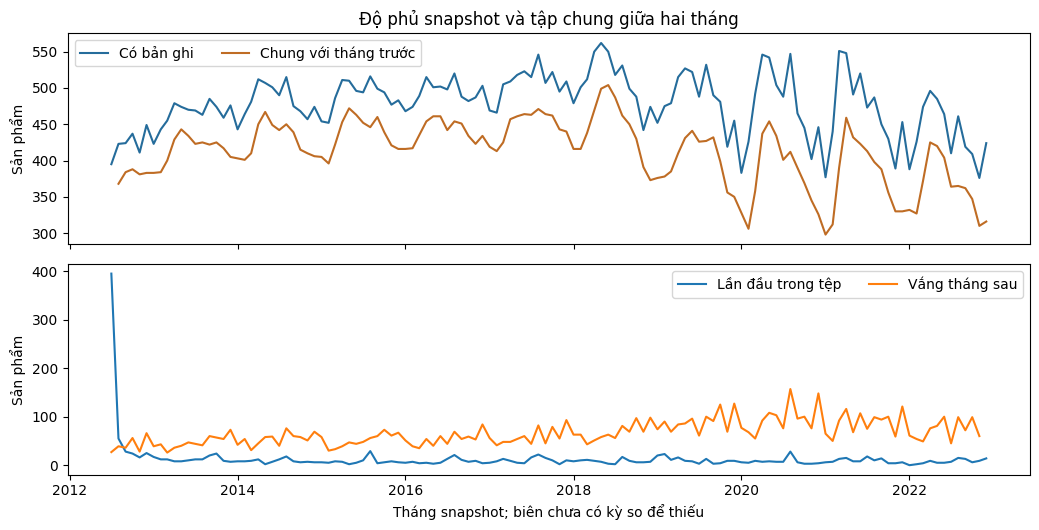

**Kết quả quan sát:** Tập sản phẩm thay đổi theo tháng và có xuất hiện trở lại. **Bằng chứng:** 376–562 sản phẩm/tháng; Jaccard liền kề 56.76–86.86%; 7099 lượt quay lại. **Ý nghĩa:** Độ phủ phải đi cùng mọi so sánh mức tồn. **Giới hạn:** Không biết danh mục bắt buộc báo cáo; xuất hiện/vắng không là vòng đời kinh doanh. **Câu hỏi tiếp:** Các khoảng vắng phát sinh từ cơ chế chọn mẫu hay lịch báo cáo nào?

In [15]:
sets52={p:set(g.product_id) for p,g in s52.groupby('period')}
first52=s52.groupby('product_id').period.min()
coverage_rows52=[]
for j,p in enumerate(months52):
    now=sets52[p];prev=sets52[months52[j-1]] if j else None;nxt=sets52[months52[j+1]] if j+1<len(months52) else None
    first_count=int(first52.eq(p).sum())
    coverage_rows52.append({'period':p,'rows':len(now),'products':len(now),'first_seen':first_count,
        'common_previous':len(now&prev) if prev is not None else np.nan,'only_previous':len(prev-now) if prev is not None else np.nan,
        'only_current':len(now-prev) if prev is not None else np.nan,'one_side':len(now^prev) if prev is not None else np.nan,
        'union_previous':len(now|prev) if prev is not None else np.nan,'jaccard_pct':100*len(now&prev)/len(now|prev) if prev is not None else np.nan,
        'returned_after_gap':len(now-prev)-first_count if prev is not None else np.nan,
        'absent_next':len(now-nxt) if nxt is not None else np.nan})
cov52=pd.DataFrame(coverage_rows52).set_index('period')
year_product52=s52.groupby(['year','product_id']).period.nunique()
year_records52=[]
for y,g in s52.groupby('year'):
    counts=year_product52.loc[y];nmonths=g.period.nunique();complete=set(g.calendar_month)==set(range(1,13))
    year_records52.append({'year':y,'months':nmonths,'products':g.product_id.nunique(),'rows':len(g),'min_months_per_product':counts.min(),
        'mean_months_per_product':counts.mean(),'median_months_per_product':counts.median(),'max_months_per_product':counts.max(),
        'full_12_products':int(counts.eq(12).sum()) if complete else np.nan,'partial_year_products':int(counts.lt(12).sum()) if complete else np.nan,
        'complete_calendar':complete,'scope':'Đủ tháng 1–12' if complete else f'Chỉ {nmonths} tháng; không so như năm đủ'})
year_cov52=pd.DataFrame(year_records52).set_index('year')
full_years52=list(year_cov52.index[year_cov52.complete_calendar])
selected52=sorted(set(cov52.head(2).index)|set(cov52.tail(2).index)|set(cov52.nsmallest(4,'products').index)|set(cov52.nlargest(4,'products').index))
cov_names52={'rows':'Dòng','products':'Sản phẩm','first_seen':'Lần đầu trong tệp','common_previous':'Chung với trước','only_previous':'Chỉ tháng trước','only_current':'Chỉ tháng hiện tại','one_side':'Chỉ một phía','union_previous':'Hợp hai tháng','jaccard_pct':'Jaccard % / hợp','returned_after_gap':'Quay lại sau khoảng vắng','absent_next':'Vắng tháng sau'}
show52('Độ phủ tháng — kỳ biên và cực trị; thiếu ở biên là chưa có kỳ so sánh',cov52.loc[selected52].reset_index().assign(period=lambda d:d.period.astype(str)).rename(columns={'period':'Tháng',**cov_names52}))
show52('Độ phủ năm — tháng quan sát trên từng sản phẩm của đúng năm; 2012 không đủ phạm vi',year_cov52.reset_index().rename(columns={'year':'Năm','months':'Tháng có dữ liệu','products':'Sản phẩm trong năm','rows':'Dòng sản phẩm–tháng',
    'min_months_per_product':'Min tháng/SP','mean_months_per_product':'Mean tháng/SP','median_months_per_product':'Median tháng/SP','max_months_per_product':'Max tháng/SP',
    'full_12_products':'SP đủ 12 tháng (năm đủ)','partial_year_products':'SP một phần năm (năm đủ)','complete_calendar':'Đủ lịch năm','scope':'Phạm vi'}))
fig,axes=plt.subplots(2,1,figsize=(10.5,5.4),sharex=True)
xs=cov52.index.to_timestamp();axes[0].plot(xs,cov52.products,label='Có bản ghi',color='#256c9b');axes[0].plot(xs,cov52.common_previous,label='Chung với tháng trước',color='#bf6c24')
axes[0].set(ylabel='Sản phẩm',title='Độ phủ snapshot và tập chung giữa hai tháng');axes[0].legend(loc='upper left',ncol=2)
axes[1].plot(xs,cov52.first_seen,label='Lần đầu trong tệp');axes[1].plot(xs,cov52.absent_next,label='Vắng tháng sau')
axes[1].set(xlabel='Tháng snapshot; biên chưa có kỳ so để thiếu',ylabel='Sản phẩm');axes[1].legend(ncol=2)
plot_done(fig)
check52('Độ phủ theo tháng/năm bảo toàn dòng và số sản phẩm, không cộng distinct qua năm',cov52.rows.sum()==year_cov52.rows.sum()==len(s52) and sum(map(len,sets52.values()))==len(s52) and set().union(*sets52.values())==set(s52.product_id))
check52('So tập liền kề phân rã đủ hai phía; lần đầu cộng đúng số mã',all(row.common_previous+row.only_previous==cov52.products.iloc[j-1] and row.common_previous+row.only_current==row.products and row.one_side==row.only_previous+row.only_current for j,(_,row) in enumerate(cov52.iterrows()) if j) and cov52.first_seen.sum()==s52.product_id.nunique() and pd.isna(cov52.iloc[-1].absent_next))
check52('2012 có 6 tháng; chỉ 2013–2022 là năm đầy đủ',year_cov52.loc[2012,'months']==6 and not year_cov52.loc[2012,'complete_calendar'] and pd.isna(year_cov52.loc[2012,'full_12_products']) and full_years52==list(range(2013,2023)))
note52('Tập sản phẩm thay đổi theo tháng và có xuất hiện trở lại.',f'{cov52.products.min()}–{cov52.products.max()} sản phẩm/tháng; Jaccard liền kề {cov52.jaccard_pct.min():.2f}–{cov52.jaccard_pct.max():.2f}%; {int(cov52.returned_after_gap.sum())} lượt quay lại.','Độ phủ phải đi cùng mọi so sánh mức tồn.','Không biết danh mục bắt buộc báo cáo; xuất hiện/vắng không là vòng đời kinh doanh.','Các khoảng vắng phát sinh từ cơ chế chọn mẫu hay lịch báo cáo nào?')

### NV05.2.3 – Stock_on_hand tại từng snapshot tháng

Tính tổng, mean, median, min/max, std mẫu và phân vị trên các dòng thật của từng tháng. Ba khoảng dùng P25/P75 toàn kỳ cố định ở NV05.2.1, chỉ chia phân bố mô tả. Bảng thống kê in những tháng biên/cực trị; bảng đầy đủ có 126 dòng trong bộ nhớ. Thay đổi tháng là chênh giá trị snapshot; phần trăm lấy tháng trước làm mẫu số, không là lượng bán/nhập hoặc thay đổi trên cùng tập sản phẩm.

**Stock_on_hand trên sản phẩm quan sát từng tháng — đơn vị lượng nguồn; tỷ trọng % / dòng tháng**

Tháng snapshot,Dòng sản phẩm–tháng,Mean / dòng quan sát,Median / dòng quan sát,Min,Max,Std mẫu,P25,P75,P90,P95,Sản phẩm phân biệt,Tổng tại snapshot,CV = std/mean,% khoảng thấp,% khoảng giữa,% khoảng cao,Chênh tổng với trước,% tổng so trước,Chênh số SP,Chênh median
2012-07,395,"59,9949","25,0000",3,550,"85,8288","9,0000","76,5000","147,0000","248,1000",395,23698,"1,4306","37,2152","56,7089","6,0759",—,—,—,—
2012-08,423,"62,0544","27,0000",3,573,"89,8238","10,0000","76,5000","155,8000","253,9000",423,26249,"1,4475","35,9338","57,9196","6,1466","2.551,0000","10,7646","28,0000","2,0000"
2017-02,466,"203,0665","94,5000",3,1934,"289,3440","23,0000","255,2500","557,0000","789,0000",466,94629,"1,4249","20,1717","50,6438","29,1845","1.855,0000","1,9995","-3,0000","4,5000"
2018-04,550,"198,9927","67,0000",3,2242,"316,4587","15,0000","230,7500","599,3000","888,0000",550,109446,"1,5903","25,2727","47,4545","27,2727","4.018,0000","3,8111","38,0000","0,0000"
2018-05,562,"202,2046","61,5000",3,2254,"321,7580","17,0000","234,0000","605,6000","909,6000",562,113639,"1,5912","23,4875","48,5765","27,9359","4.193,0000","3,8311","12,0000","-5,5000"
2018-06,550,"208,6127","70,5000",3,2261,"327,6947","17,0000","247,5000","614,6000","916,1000",550,114737,"1,5708","22,9091","48,3636","28,7273","1.098,0000","0,9662","-12,0000","9,0000"
2020-01,383,"273,9112","83,0000",3,2487,"416,5194","18,0000","357,0000","780,2000","1.181,6000",383,104908,"1,5206","24,0209","40,4700","35,5091","-6.877,0000","-6,1520","-72,0000","9,0000"
2020-08,547,"229,0183","64,0000",3,2509,"387,2339","12,0000","261,0000","698,6000","1.159,4000",547,125273,"1,6908","29,2505","42,0475","28,7020","6.260,0000","5,2599","59,0000","-6,5000"
2021-01,377,"279,2573","83,0000",3,2541,"436,3702","17,0000","333,0000","780,2000","1.248,0000",377,105280,"1,5626","24,1379","41,6446","34,2175","-12.473,0000","-10,5925","-69,0000","-2,0000"
2021-03,551,"220,1307","58,0000",3,2551,"383,8902","11,0000","246,0000","687,0000","1.097,0000",551,121292,"1,7439","30,4900","41,9238","27,5862","8.159,0000","7,2119","111,0000","-23,0000"


**Các tháng cực trị quan sát — đồng hạng lấy tháng sớm nhất, không suy nguyên nhân**

Tiêu chí,Tháng,SP quan sát,Tổng snapshot,Mean / SP,Median / SP
Tổng thấp nhất,2012-07,395,23698,"59,9949","25,0000"
Tổng cao nhất,2020-08,547,125273,"229,0183","64,0000"
Median thấp nhất,2012-07,395,23698,"59,9949","25,0000"
Median cao nhất,2017-02,466,94629,"203,0665","94,5000"
Ít sản phẩm nhất,2022-11,376,95003,"252,6676","56,0000"
Nhiều sản phẩm nhất,2018-05,562,113639,"202,2046","61,5000"


**Tám thay đổi tổng snapshot lớn nhất theo trị tuyệt đối — kèm thay đổi độ phủ**

Tháng snapshot,Sản phẩm phân biệt,Tổng tại snapshot,delta_total,pct_total,delta_products,Mean / dòng quan sát,Median / dòng quan sát
2021-01,377,105280,"-12.473,0000","-10,5925","-69,0000","279,2573","83,0000"
2020-09,465,112854,"-12.419,0000","-9,9135","-82,0000","242,6968","69,0000"
2019-05,527,117527,"12.042,0000","11,4158","12,0000","223,0114","62,0000"
2022-11,376,95003,"-9.252,0000","-8,8744","-33,0000","252,6676","56,0000"
2022-12,424,104235,"9.232,0000","9,7176","48,0000","245,8373","55,5000"
2018-11,442,109198,"-8.423,0000","-7,1611","-46,0000","247,0543","89,5000"
2021-03,551,121292,"8.159,0000","7,2119","111,0000","220,1307","58,0000"
2021-02,440,113133,"7.853,0000","7,4592","63,0000","257,1205","81,0000"


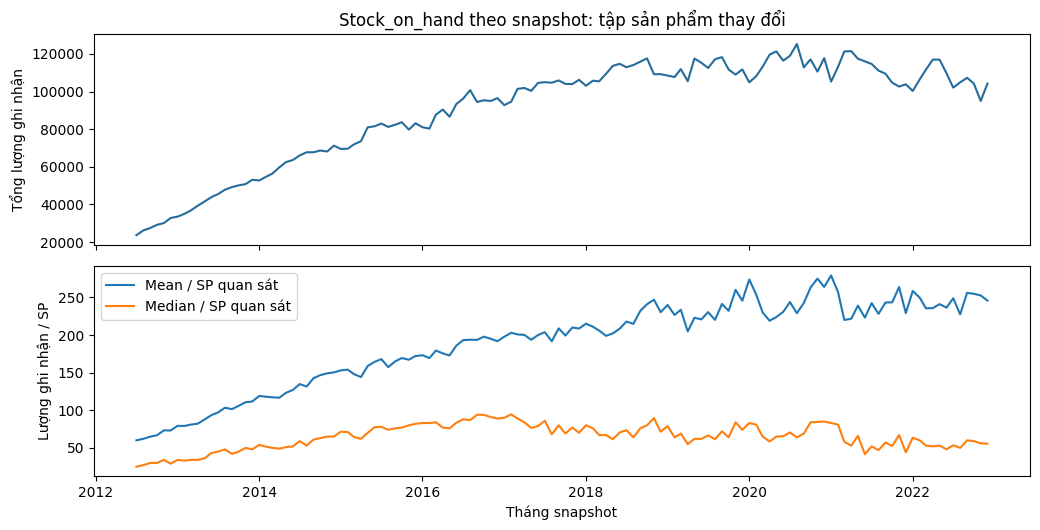

**Kết quả quan sát:** Tổng snapshot và phân bố giữa sản phẩm không chuyển động giống nhau. **Bằng chứng:** Tổng từ 23.698 lên 104.235 giữa hai kỳ biên; tháng đổi mạnh nhất 2021-01: -12.473, số SP đổi -69. **Ý nghĩa:** Cần tách giá trị tổng, mức điển hình và thành phần mẫu. **Giới hạn:** Chênh tổng không xác nhận bán/nhập; bình quân sản phẩm không là bình quân thời gian. **Câu hỏi tiếp:** Thay đổi còn giữ hướng nào trên cùng tập sản phẩm?

In [16]:
monthly52=stats52(s52,'period',snapshot=True)
bands52=pd.crosstab(s52.period,s52.band,dropna=False).reindex(months52)
band_pct52=bands52.div(monthly52.n,axis=0)*100
monthly52['low_pct']=band_pct52.iloc[:,0];monthly52['middle_pct']=band_pct52.iloc[:,1];monthly52['high_pct']=band_pct52.iloc[:,2]
monthly52['delta_total']=monthly52.total.diff();monthly52['pct_total']=monthly52.total.pct_change(fill_method=None)*100
monthly52['delta_products']=monthly52.products.diff();monthly52['delta_median']=monthly52['median'].diff()
extreme_defs52=[('Tổng thấp nhất','total','min'),('Tổng cao nhất','total','max'),('Median thấp nhất','median','min'),('Median cao nhất','median','max'),('Ít sản phẩm nhất','products','min'),('Nhiều sản phẩm nhất','products','max')]
extrema52=pd.DataFrame([{'Tiêu chí':label,'period':monthly52[c].idxmin() if how=='min' else monthly52[c].idxmax()} for label,c,how in extreme_defs52])
extrema52=extrema52.merge(monthly52[['products','total','mean','median']],left_on='period',right_index=True,validate='many_to_one')
selected_stock52=sorted(set(selected52)|set(extrema52.period))
show52('Stock_on_hand trên sản phẩm quan sát từng tháng — đơn vị lượng nguồn; tỷ trọng % / dòng tháng',display52(monthly52.loc[selected_stock52]).rename(columns={'low_pct':'% khoảng thấp','middle_pct':'% khoảng giữa','high_pct':'% khoảng cao','delta_total':'Chênh tổng với trước','pct_total':'% tổng so trước','delta_products':'Chênh số SP','delta_median':'Chênh median'}))
show52('Các tháng cực trị quan sát — đồng hạng lấy tháng sớm nhất, không suy nguyên nhân',extrema52.assign(period=lambda d:d.period.astype(str)).rename(columns={'period':'Tháng','products':'SP quan sát','total':'Tổng snapshot','mean':'Mean / SP','median':'Median / SP'}))
largest_changes52=monthly52.iloc[1:].assign(abs_change=lambda d:d.delta_total.abs()).sort_values(['abs_change','period'],ascending=[False,True]).head(8)
show52('Tám thay đổi tổng snapshot lớn nhất theo trị tuyệt đối — kèm thay đổi độ phủ',display52(largest_changes52[['products','total','delta_total','pct_total','delta_products','mean','median']]))
fig,axes=plt.subplots(2,1,figsize=(10.5,5.4),sharex=True)
axes[0].plot(monthly52.index.to_timestamp(),monthly52.total,color='#256c9b');axes[0].set(ylabel='Tổng lượng ghi nhận',title='Stock_on_hand theo snapshot: tập sản phẩm thay đổi')
axes[1].plot(monthly52.index.to_timestamp(),monthly52['mean'],label='Mean / SP quan sát');axes[1].plot(monthly52.index.to_timestamp(),monthly52['median'],label='Median / SP quan sát')
axes[1].set(xlabel='Tháng snapshot',ylabel='Lượng ghi nhận / SP');axes[1].legend();plot_done(fig)
check52('Tổng, mean và tỷ trọng tháng có đúng mẫu số; không điền tháng thiếu',monthly52.n.sum()==len(s52) and monthly52.n.equals(monthly52.products) and np.allclose(monthly52['mean']*monthly52.n,monthly52.total) and np.allclose(band_pct52.sum(axis=1),100) and bands52.to_numpy().sum()==len(s52))
max_change52=largest_changes52.iloc[0];max_change_period52=largest_changes52.index[0]
note52('Tổng snapshot và phân bố giữa sản phẩm không chuyển động giống nhau.',f'Tổng từ {vn(monthly52.total.iloc[0])} lên {vn(monthly52.total.iloc[-1])} giữa hai kỳ biên; tháng đổi mạnh nhất {max_change_period52}: {vn(max_change52.delta_total)}, số SP đổi {vn(max_change52.delta_products)}.','Cần tách giá trị tổng, mức điển hình và thành phần mẫu.','Chênh tổng không xác nhận bán/nhập; bình quân sản phẩm không là bình quân thời gian.','Thay đổi còn giữ hướng nào trên cùng tập sản phẩm?')

### NV05.2.4 – So sánh năm với mẫu số rõ ràng

“Mean tổng snapshot/tháng” là trung bình các tổng tháng, không cộng thành tồn năm. Median và P25/P75/P90 năm lấy trên bản ghi sản phẩm–tháng của năm; “mean median tháng” là trung bình các median tháng, một chỉ tiêu khác. Std mẫu đo phân tán giữa các dòng. Số năm quan sát đầy đủ kiểm tra từ lịch; YoY chỉ tính khi cả hai năm liền kề đủ 12 tháng, nên 2013/2012 để thiếu.

In [17]:
annual52=stats52(s52,'year')
by_year52=monthly52.assign(year=monthly52.index.year).groupby('year')
annual52['months']=by_year52.size();annual52['mean_products_month']=by_year52.products.mean()
annual52['mean_total_snapshot']=by_year52.total.mean();annual52['mean_monthly_median']=by_year52['median'].mean()
annual52['complete_calendar']=year_cov52.complete_calendar
mask_yoy52=annual52.complete_calendar&annual52.complete_calendar.shift(1,fill_value=False)&annual52.index.to_series().diff().eq(1)
for c in ['mean_total_snapshot','median','mean_products_month']:
    annual52['yoy_'+c]=annual52[c].pct_change(fill_method=None).mul(100).where(mask_yoy52)
show52('Xu hướng năm — bình quân tổng snapshot tháng và phân bố trên dòng; 2012 chỉ có 6 tháng',display52(annual52).rename(columns={
    'months':'Tháng có dữ liệu','mean_products_month':'Mean SP / tháng','mean_total_snapshot':'Mean tổng snapshot / tháng',
    'mean_monthly_median':'Mean median tháng','complete_calendar':'Đủ tháng 1–12','yoy_mean_total_snapshot':'YoY % mean tổng snapshot',
    'yoy_median':'YoY % median dòng','yoy_mean_products_month':'YoY % mean SP/tháng'}))
year_change52=annual52.yoy_mean_total_snapshot.abs().idxmax()
peak_annual52=annual52.loc[full_years52,'mean_total_snapshot'].idxmax()
recent_year_text52='; '.join(f"{y}: mean tổng snapshot {annual52.loc[y,'yoy_mean_total_snapshot']:.2f}%, median dòng {annual52.loc[y,'yoy_median']:.2f}%, mean SP/tháng {annual52.loc[y,'yoy_mean_products_month']:.2f}% so năm trước" for y in full_years52[-2:])
check52('Chỉ dùng bình quân tổng snapshot tháng trong bảng năm, YoY 2013/2012 để thiếu', 'total' not in annual52 and pd.isna(annual52.loc[2013,'yoy_mean_total_snapshot']) and pd.isna(annual52.loc[2012,'yoy_median']) and annual52.loc[2014:,'yoy_mean_total_snapshot'].notna().all() and annual52.loc[2012,'months']==6)
note52('Mức ghi nhận giữa năm được so bằng các chỉ tiêu có cùng định nghĩa.',f'Năm đổi mạnh nhất theo |YoY mean tổng snapshot| là {year_change52}: {annual52.loc[year_change52,"yoy_mean_total_snapshot"]:.2f}%; mean tổng snapshot cao nhất năm {peak_annual52}, {annual52.loc[peak_annual52,"mean_total_snapshot"]:.2f}. {recent_year_text52}.','So tổng với median và độ phủ giúp nhận diện độ nhạy theo mẫu.','Không gán nguyên nhân thị trường hay quản lý kho; 2012 không là năm nền đủ.','Định nghĩa và tập sản phẩm có ổn định khi so xuyên năm không?')

**Xu hướng năm — bình quân tổng snapshot tháng và phân bố trên dòng; 2012 chỉ có 6 tháng**

Năm,Dòng sản phẩm–tháng,Mean / dòng quan sát,Median / dòng quan sát,Min,Max,Std mẫu,P25,P75,P90,P95,Sản phẩm phân biệt,CV = std/mean,Tháng có dữ liệu,Mean SP / tháng,Mean tổng snapshot / tháng,Mean median tháng,Đủ tháng 1–12,YoY % mean tổng snapshot,YoY % median dòng,YoY % mean SP/tháng
2012,2539,"66,8046","29,0000",3,780,"96,6401","11,0000","85,0000","169,0000","261,0000",543,"1,4466",6,"423,1667","28.269,5000","29,1667",False,—,—,—
2013,5570,"94,5966","40,0000",3,1322,"139,2541","14,0000","121,0000","250,0000","365,0000",655,"1,4721",12,"464,1667","43.908,5833","41,0000",True,—,—,—
2014,5787,"131,2300","56,0000",3,1326,"185,1428","18,0000","165,0000","377,0000","515,0000",692,"1,4108",12,"482,2500","63.285,6667","56,1250",True,"44,1305","40,0000","3,8959"
2015,5872,"160,1562","74,0000",3,1591,"222,0491","20,0000","201,0000","459,0000","623,0000",705,"1,3865",12,"489,3333","78.369,7500","73,6250",True,"23,8349","32,1429","1,4688"
2016,5927,"185,2403","85,0000",3,1913,"265,8847","20,0000","225,5000","513,4000","751,0000",726,"1,4354",12,"493,9167","91.493,2500","85,7917",True,"16,7456","14,8649","0,9366"
2017,6084,"201,4328","81,0000",3,2190,"299,9824","18,0000","242,2500","577,0000","842,0000",737,"1,4892",12,"507,0000","102.126,4167","80,2500",True,"11,6218","-4,7059","2,6489"
2018,6106,"217,9782","72,0000",3,2372,"337,2456","19,0000","268,7500","634,5000","957,7500",758,"1,5472",12,"508,8333","110.914,5833","73,0417",True,"8,6052","-11,1111","0,3616"
2019,5835,"230,8137","67,0000",3,2484,"369,3246","15,0000","284,0000","672,2000","1.085,9000",782,"1,6001",12,"486,2500","112.233,1667","67,7500",True,"1,1888","-6,9444","-4,4383"
2020,5686,"243,7897","72,0000",3,2537,"396,0886","13,0000","298,0000","715,0000","1.164,7500",827,"1,6247",12,"473,8333","115.515,6667","72,9167",True,"2,9247","7,4627","-2,5536"
2021,5609,"239,0954","59,0000",3,2603,"411,9304","11,0000","278,0000","738,0000","1.199,6000",827,"1,7229",12,"467,4167","111.757,1667","58,5000",True,"-3,2537","-18,0556","-1,3542"


**Kết quả quan sát:** Mức ghi nhận giữa năm được so bằng các chỉ tiêu có cùng định nghĩa. **Bằng chứng:** Năm đổi mạnh nhất theo |YoY mean tổng snapshot| là 2014: 44.13%; mean tổng snapshot cao nhất năm 2020, 115515.67. 2021: mean tổng snapshot -3.25%, median dòng -18.06%, mean SP/tháng -1.35% so năm trước; 2022: mean tổng snapshot -4.57%, median dòng -10.17%, mean SP/tháng -6.72% so năm trước. **Ý nghĩa:** So tổng với median và độ phủ giúp nhận diện độ nhạy theo mẫu. **Giới hạn:** Không gán nguyên nhân thị trường hay quản lý kho; 2012 không là năm nền đủ. **Câu hỏi tiếp:** Định nghĩa và tập sản phẩm có ổn định khi so xuyên năm không?

### NV05.2.5 – Panel toàn kỳ, panel từng năm và cùng tập hai kỳ

**Panel toàn kỳ:** sản phẩm có mặt ở mọi tháng thực tế trong lịch toàn kỳ; giữ đúng tập đó ở từng tháng. So chỉ số tổng snapshot với kỳ đầu =100 và median theo đơn vị gốc, luôn công bố kích thước mẫu; không mặc định đại diện toàn bộ sản phẩm.

**Panel năm:** chỉ năm đủ tháng 1–12, giữ sản phẩm đủ 12 tháng trong từng năm. Tập này có thể thay đổi giữa các năm, không gọi là panel cố định xuyên năm. So mean tổng snapshot/tháng, mean/median theo dòng giữa hai phạm vi của cùng năm.

**Hai kỳ:** chọn ba chênh lệch tổng tháng liền kề lớn nhất về trị tuyệt đối (đồng hạng chọn tháng sớm). So trên giao hai tập; công bố phần chỉ trước/chỉ sau. Phân rã số học: chênh toàn bộ = chênh trên tập chung + lượng của nhóm chỉ kỳ sau − lượng của nhóm chỉ kỳ trước. Đây là phân rã mẫu quan sát, không phải luồng hàng.

**Toàn bộ quan sát và panel toàn kỳ — so hai biên; panel không mặc định đại diện**

Phạm vi,SP toàn phạm vi,Dòng,Tháng,Tổng kỳ đầu,Tổng kỳ cuối,% chênh tổng hai biên,Median kỳ đầu,Median kỳ cuối,% chênh median hai biên
Toàn bộ quan sát; tập thay đổi,1624,60247,126,23698,104235,"339,8472","25,0000","55,5000","122,0000"
Panel toàn kỳ; tập cố định,22,2772,126,2724,25110,"821,8062","106,5000","1.295,0000","1.115,9624"


**Panel từng năm đủ — không coi các panel năm khác nhau là cùng một tập xuyên năm**

Năm,Phạm vi,SP,Dòng,Tháng,Mean tổng snapshot / tháng,Mean / dòng,Median / dòng,Giới hạn
2013,Toàn bộ trong năm,655,5570,12,"43.908,5833","94,5966","40,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2013,Panel đủ 12 tháng của năm,293,3516,12,"40.005,1667","136,5364","84,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2014,Toàn bộ trong năm,692,5787,12,"63.285,6667","131,2300","56,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2014,Panel đủ 12 tháng của năm,293,3516,12,"55.907,0833","190,8092","120,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2015,Toàn bộ trong năm,705,5872,12,"78.369,7500","160,1562","74,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2015,Panel đủ 12 tháng của năm,287,3444,12,"61.786,5000","215,2840","126,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2016,Toàn bộ trong năm,726,5927,12,"91.493,2500","185,2403","85,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2016,Panel đủ 12 tháng của năm,286,3432,12,"76.571,1667","267,7314","157,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2017,Toàn bộ trong năm,737,6084,12,"102.126,4167","201,4328","81,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"
2017,Panel đủ 12 tháng của năm,297,3564,12,"86.952,7500","292,7702","173,0000","Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên"


**Ba giai đoạn đổi tổng mạnh nhất — cùng tập sản phẩm và phần thành phần mẫu được tách**

Kỳ trước,Kỳ sau,SP chung,Chỉ kỳ trước,Chỉ kỳ sau,Tổng trước / tập chung,Tổng sau / tập chung,Chênh tổng / tập chung,Median trước / tập chung,Median sau / tập chung,Chênh median / tập chung,Phần thành phần mẫu,Chênh tổng / toàn bộ,Đẳng thức phân rã
2020-12,2021-01,298,148,79,101948,102194,246,"141,5000","146,0000","4,5000",-12719,-12473,True
2020-08,2020-09,390,157,75,108066,108541,475,"86,5000","88,0000","1,5000",-12894,-12419,True
2019-04,2019-05,431,84,96,101559,102643,1084,"74,0000","76,0000","2,0000",10958,12042,True


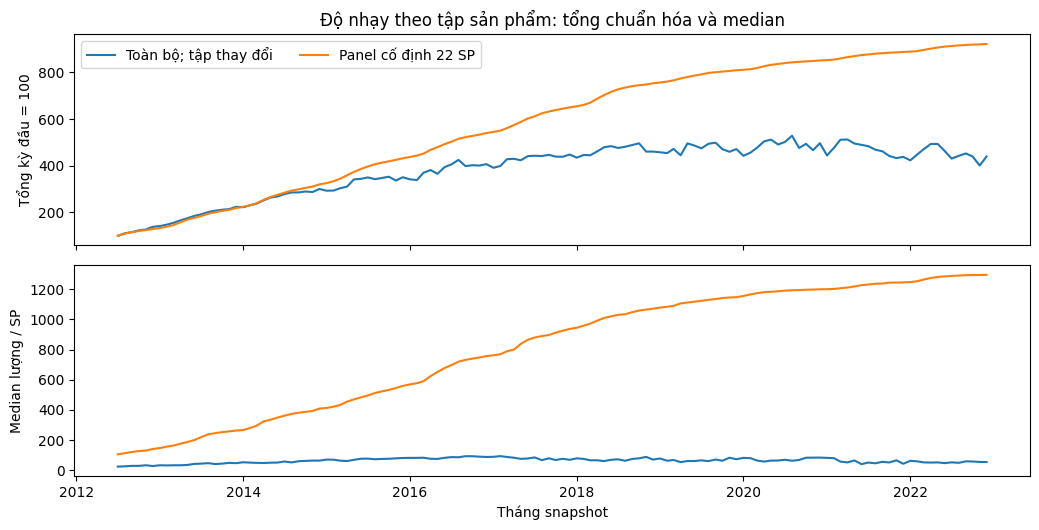

**Kết quả quan sát:** Panel giữ thành phần mẫu cố định, song chỉ là một tập nhỏ. **Bằng chứng:** 22/1624 SP toàn kỳ; chênh tổng hai biên toàn bộ 339.85%, panel 821.81%. 2020-12→2021-01: chênh toàn bộ -12473, tập chung 246, phần thành phần -12719; cả ba phân rã khớp. **Ý nghĩa:** Tách được thay đổi mức ghi nhận trên sản phẩm chung khỏi phần xuất hiện/vắng mẫu. **Giới hạn:** Panel sống suốt kỳ có thiên lệch chọn mẫu; panel năm khác nhau, không chứng minh nguyên nhân biến động. **Câu hỏi tiếp:** Vì sao những sản phẩm này được quan sát đều hơn và khác tập còn lại thế nào?

In [18]:
period_counts52=s52.groupby('product_id').period.nunique()
panel_ids52=set(period_counts52.index[period_counts52.eq(len(months52))])
panel_data52=s52.loc[s52.product_id.isin(panel_ids52)].copy()
panel_month52=stats52(panel_data52,'period',snapshot=True)
scope_comparison52=[]
for label,frame,mt in [('Toàn bộ quan sát; tập thay đổi',s52,monthly52),('Panel toàn kỳ; tập cố định',panel_data52,panel_month52)]:
    scope_comparison52.append({'Phạm vi':label,'SP toàn phạm vi':frame.product_id.nunique(),'Dòng':len(frame),'Tháng':frame.period.nunique(),
        'Tổng kỳ đầu':mt.total.iloc[0],'Tổng kỳ cuối':mt.total.iloc[-1],'% chênh tổng hai biên':100*(mt.total.iloc[-1]/mt.total.iloc[0]-1),
        'Median kỳ đầu':mt['median'].iloc[0],'Median kỳ cuối':mt['median'].iloc[-1],'% chênh median hai biên':100*(mt['median'].iloc[-1]/mt['median'].iloc[0]-1)})
scope_comparison52=pd.DataFrame(scope_comparison52)
show52('Toàn bộ quan sát và panel toàn kỳ — so hai biên; panel không mặc định đại diện',scope_comparison52)
year_panels52={y:set(year_product52.loc[y].index[year_product52.loc[y].eq(12)]) for y in full_years52}
year_panel_rows52=[]
for y,ids in year_panels52.items():
    all_y=s52.loc[s52.year.eq(y)];fixed_y=all_y.loc[all_y.product_id.isin(ids)]
    for label,frame in [('Toàn bộ trong năm',all_y),('Panel đủ 12 tháng của năm',fixed_y)]:
        year_panel_rows52.append({'Năm':y,'Phạm vi':label,'SP':frame.product_id.nunique(),'Dòng':len(frame),'Tháng':frame.period.nunique(),
            'Mean tổng snapshot / tháng':frame.groupby('period').stock.sum().mean(),'Mean / dòng':frame.stock.mean(),'Median / dòng':frame.stock.median(),
            'Giới hạn':'Tập panel chỉ cố định trong đúng năm, có thể khác năm kế bên'})
year_panel_table52=pd.DataFrame(year_panel_rows52)
show52('Panel từng năm đủ — không coi các panel năm khác nhau là cùng một tập xuyên năm',year_panel_table52)
pair_comparison52=[]
for later in largest_changes52.head(3).index:
    earlier=later-1;a=s52.loc[s52.period.eq(earlier)].set_index('product_id').stock;b=s52.loc[s52.period.eq(later)].set_index('product_id').stock
    common=sorted(set(a.index)&set(b.index));only_a=sorted(set(a.index)-set(b.index));only_b=sorted(set(b.index)-set(a.index))
    delta_common=int(b.loc[common].sum()-a.loc[common].sum());composition=int(b.loc[only_b].sum()-a.loc[only_a].sum())
    pair_comparison52.append({'Kỳ trước':str(earlier),'Kỳ sau':str(later),'SP chung':len(common),'Chỉ kỳ trước':len(only_a),'Chỉ kỳ sau':len(only_b),
        'Tổng trước / tập chung':int(a.loc[common].sum()),'Tổng sau / tập chung':int(b.loc[common].sum()),'Chênh tổng / tập chung':delta_common,
        'Median trước / tập chung':a.loc[common].median(),'Median sau / tập chung':b.loc[common].median(),'Chênh median / tập chung':b.loc[common].median()-a.loc[common].median(),
        'Phần thành phần mẫu':composition,'Chênh tổng / toàn bộ':int(b.sum()-a.sum()),'Đẳng thức phân rã':delta_common+composition==int(b.sum()-a.sum())})
pair_table52=pd.DataFrame(pair_comparison52)
show52('Ba giai đoạn đổi tổng mạnh nhất — cùng tập sản phẩm và phần thành phần mẫu được tách',pair_table52)
fig,axes=plt.subplots(2,1,figsize=(10.5,5.4),sharex=True)
for label,mt in [('Toàn bộ; tập thay đổi',monthly52),(f'Panel cố định {len(panel_ids52)} SP',panel_month52)]:
    axes[0].plot(mt.index.to_timestamp(),100*mt.total/mt.total.iloc[0],label=label)
    axes[1].plot(mt.index.to_timestamp(),mt['median'],label=label)
axes[0].set(title='Độ nhạy theo tập sản phẩm: tổng chuẩn hóa và median',ylabel='Tổng kỳ đầu = 100');axes[0].legend(ncol=2)
axes[1].set(xlabel='Tháng snapshot',ylabel='Median lượng / SP');plot_done(fig)
check52('Panel toàn kỳ được xác minh, cùng tập ở mọi tháng và đủ tích SP×tháng',len(panel_ids52)==22 and len(panel_data52)==len(panel_ids52)*len(months52) and all(set(g.product_id)==panel_ids52 for _,g in panel_data52.groupby('period')))
check52('Panel năm đúng 12 tháng, khác khái niệm panel toàn kỳ',all(len(s52.loc[s52.year.eq(y)&s52.product_id.isin(ids)])==12*len(ids) and all(set(g.product_id)==ids for _,g in s52.loc[s52.year.eq(y)&s52.product_id.isin(ids)].groupby('period')) for y,ids in year_panels52.items()) and 2012 not in year_panels52 and len({frozenset(v) for v in year_panels52.values()})>1)
check52('Ba so sánh hai kỳ phân rã đủ toàn bộ và chỉ dùng giao để tính cùng tập',len(pair_table52)==3 and pair_table52['Đẳng thức phân rã'].all())
notable_pair52=pair_table52.iloc[0]
note52('Panel giữ thành phần mẫu cố định, song chỉ là một tập nhỏ.',f'{len(panel_ids52)}/{s52.product_id.nunique()} SP toàn kỳ; chênh tổng hai biên toàn bộ {scope_comparison52.iloc[0]["% chênh tổng hai biên"]:.2f}%, panel {scope_comparison52.iloc[1]["% chênh tổng hai biên"]:.2f}%. {notable_pair52["Kỳ trước"]}→{notable_pair52["Kỳ sau"]}: chênh toàn bộ {notable_pair52["Chênh tổng / toàn bộ"]}, tập chung {notable_pair52["Chênh tổng / tập chung"]}, phần thành phần {notable_pair52["Phần thành phần mẫu"]}; cả ba phân rã khớp.','Tách được thay đổi mức ghi nhận trên sản phẩm chung khỏi phần xuất hiện/vắng mẫu.','Panel sống suốt kỳ có thiên lệch chọn mẫu; panel năm khác nhau, không chứng minh nguyên nhân biến động.','Vì sao những sản phẩm này được quan sát đều hơn và khác tập còn lại thế nào?')

### NV05.2.6 – Phân bố theo từng sản phẩm và xếp hạng có ngưỡng quan sát

Tổng hợp tất cả mã sản phẩm, giữ số tháng và ngày đầu/cuối. Std mẫu chỉ xác định khi có ≥2 dòng; CV = std/mean khi mean dương, không điền std/CV của một tháng bằng 0. Khoảng biến động = max−min; số tháng khoảng thấp/cao dùng ngưỡng phân vị cố định, không là thiếu/dư tồn.

Xếp hạng riêng mean cao, median cao, mean thấp, std cao và CV cao, chỉ trên sản phẩm có ít nhất 24 tháng quan sát. Đây là ngưỡng mô tả hai chu kỳ năm, không đòi các tháng liên tục hoặc đảm bảo cùng giai đoạn. Mỗi bảng lấy 5, đồng hạng lấy product_id dạng chuỗi tăng dần. Không mặc định thứ hạng mean/median giống nhau; std, CV và range đo các khía cạnh phân tán khác nhau. Cảnh báo sản phẩm 1–2 tháng trước khi diễn giải.

In [19]:
product_stats52=stats52(s52,'product_id')
product_stats52=product_stats52.join(s52.groupby('product_id').agg(months=('period','nunique'),first=('snapshot_day','min'),last=('snapshot_day','max')))
product_stats52['range']=product_stats52['max']-product_stats52['min']
product_stats52['low_months']=s52.assign(low=s52.stock.le(q25_52)).groupby('product_id').low.sum()
product_stats52['high_months']=s52.assign(high=s52.stock.gt(q75_52)).groupby('product_id').high.sum()
product_stats52=product_stats52.join(labels52.set_index('product_id'),validate='one_to_one')
product_stats52['internal_gaps']=coverage.internal_unobserved
eligible52=product_stats52.loc[product_stats52.months.ge(threshold52)].copy()
rank_defs52=[('Mean cao','mean',False),('Median cao','median',False),('Mean thấp','mean',True),('Std cao','std',False),('CV cao','cv',False)]
rank_tables52={}
for label,col,ascending in rank_defs52:
    ranked=eligible52.reset_index().sort_values([col,'product_id'],ascending=[ascending,True]).head(5).set_index('product_id')
    rank_tables52[label]=ranked
ranked_display52=pd.concat([frame.assign(criterion=label,rank=np.arange(1,len(frame)+1)) for label,frame in rank_tables52.items()])
show52('Top 5 mỗi tiêu chí — chỉ sản phẩm ≥24 tháng; cao/thấp là mức ghi nhận, không là dư/thiếu tồn',display52(ranked_display52[['criterion','rank','product_name','category','segment','months','first','last','mean','median','min','max','p25','p75','std','cv','range','low_months','high_months']]).rename(columns={
    'criterion':'Tiêu chí','rank':'Hạng','months':'Tháng quan sát','first':'Ngày đầu','last':'Ngày cuối','range':'Max−min','low_months':'Tháng ≤P25 toàn kỳ','high_months':'Tháng >P75 toàn kỳ'}))
thin52=pd.DataFrame([{'Nhóm':'1 tháng','Sản phẩm':int(product_stats52.months.eq(1).sum()),'Giới hạn':'Std/CV thiếu; range=0 theo định nghĩa, không chứng minh ổn định'},
    {'Nhóm':'2 tháng','Sản phẩm':int(product_stats52.months.eq(2).sum()),'Giới hạn':'Hai điểm không đủ đại diện biến động xuyên kỳ'},
    {'Nhóm':f'Dưới {threshold52} tháng','Sản phẩm':int(product_stats52.months.lt(threshold52).sum()),'Giới hạn':'Vẫn giữ trong tổng hợp, không vào các bảng xếp hạng'},
    {'Nhóm':f'Từ {threshold52} tháng','Sản phẩm':len(eligible52),'Giới hạn':'Các lịch quan sát vẫn có thể khác nhau'}])
show52('Cảnh báo độ phủ trước khi đọc thứ hạng — nhóm 1/2 tháng nằm trong nhóm dưới ngưỡng, không cộng các hàng',thin52)
check52('Tổng hợp đủ mọi sản phẩm và kỳ, std/CV một dòng để thiếu',len(product_stats52)==s52.product_id.nunique() and product_stats52.n.sum()==len(s52) and product_stats52.months.to_dict()==period_counts52.to_dict() and product_stats52.loc[product_stats52.months.eq(1),['std','cv']].isna().all().all())
check52('Tất cả top đúng ngưỡng, tiêu chí và thứ tự đã công bố',all(len(t)==5 and t.months.ge(threshold52).all() and list(t.index)==list(eligible52.reset_index().sort_values([col,'product_id'],ascending=[ascending,True]).head(5).product_id) for (label,col,ascending),t in zip(rank_defs52,rank_tables52.values())))
top_mean52=rank_tables52['Mean cao'].iloc[0];top_std52=rank_tables52['Std cao'].iloc[0];top_low52=rank_tables52['Mean thấp'].iloc[0]
note52('Mức điển hình và mức biến động được xếp hạng riêng.',f'{len(eligible52)} SP đạt ≥{threshold52} tháng; mean cao nhất mã {rank_tables52["Mean cao"].index[0]} ({top_mean52["mean"]:.2f}), thấp nhất mã {rank_tables52["Mean thấp"].index[0]} ({top_low52["mean"]:.2f}); std cao nhất mã {rank_tables52["Std cao"].index[0]} ({top_std52["std"]:.2f}).','Phải đọc cả số kỳ, median và độ phân tán khi so sản phẩm.','Không suy bán chậm/bán chạy, dư/thiếu hoặc tiêu thụ từ mức và biến động.','Các sản phẩm có cùng đơn vị và bối cảnh quan sát để so trực tiếp không?')

**Top 5 mỗi tiêu chí — chỉ sản phẩm ≥24 tháng; cao/thấp là mức ghi nhận, không là dư/thiếu tồn**

Mã sản phẩm,Tiêu chí,Hạng,Tên nguồn,Category,Segment,Tháng quan sát,Ngày đầu,Ngày cuối,Mean / dòng quan sát,Median / dòng quan sát,Min,Max,P25,P75,Std mẫu,CV = std/mean,Max−min,Tháng ≤P25 toàn kỳ,Tháng >P75 toàn kỳ
791,Mean cao,1,HanoiStreet RP-79,Outdoor,Activewear,111,2013-09-30 00:00:00,2022-12-31 00:00:00,"1.915,2523","2.242,0000",45,2673,"1.549,0000","2.510,0000","754,9276","0,3942",2628,0,107
792,Mean cao,2,HanoiStreet RP-80,Outdoor,Activewear,111,2013-09-30 00:00:00,2022-12-31 00:00:00,"1.898,5676","2.193,0000",45,2617,"1.603,0000","2.433,5000","714,2748","0,3762",2572,0,108
604,Mean cao,3,SaigonFlex UC-69,Streetwear,Everyday,126,2012-07-31 00:00:00,2022-12-31 00:00:00,"1.658,1905","1.948,0000",380,2370,"1.073,5000","2.248,0000","675,5063","0,4074",1990,0,126
2045,Mean cao,4,UrbanVN UE-05,Streetwear,Performance,125,2012-07-31 00:00:00,2022-11-30 00:00:00,"1.502,9840","1.780,0000",175,2339,"739,0000","2.248,0000","776,3409","0,5165",2164,0,118
487,Mean cao,5,SaigonFlex UM-92,Streetwear,Balanced,72,2016-07-31 00:00:00,2022-09-30 00:00:00,"1.366,8750","1.540,5000",199,2014,"871,7500","1.912,0000","585,1440","0,4281",1815,0,71
791,Median cao,1,HanoiStreet RP-79,Outdoor,Activewear,111,2013-09-30 00:00:00,2022-12-31 00:00:00,"1.915,2523","2.242,0000",45,2673,"1.549,0000","2.510,0000","754,9276","0,3942",2628,0,107
792,Median cao,2,HanoiStreet RP-80,Outdoor,Activewear,111,2013-09-30 00:00:00,2022-12-31 00:00:00,"1.898,5676","2.193,0000",45,2617,"1.603,0000","2.433,5000","714,2748","0,3762",2572,0,108
604,Median cao,3,SaigonFlex UC-69,Streetwear,Everyday,126,2012-07-31 00:00:00,2022-12-31 00:00:00,"1.658,1905","1.948,0000",380,2370,"1.073,5000","2.248,0000","675,5063","0,4074",1990,0,126
2045,Median cao,4,UrbanVN UE-05,Streetwear,Performance,125,2012-07-31 00:00:00,2022-11-30 00:00:00,"1.502,9840","1.780,0000",175,2339,"739,0000","2.248,0000","776,3409","0,5165",2164,0,118
487,Median cao,5,SaigonFlex UM-92,Streetwear,Balanced,72,2016-07-31 00:00:00,2022-09-30 00:00:00,"1.366,8750","1.540,5000",199,2014,"871,7500","1.912,0000","585,1440","0,4281",1815,0,71


**Cảnh báo độ phủ trước khi đọc thứ hạng — nhóm 1/2 tháng nằm trong nhóm dưới ngưỡng, không cộng các hàng**

Nhóm,Sản phẩm,Giới hạn
1 tháng,110,"Std/CV thiếu; range=0 theo định nghĩa, không chứng minh ổn định"
2 tháng,51,Hai điểm không đủ đại diện biến động xuyên kỳ
Dưới 24 tháng,744,"Vẫn giữ trong tổng hợp, không vào các bảng xếp hạng"
Từ 24 tháng,880,Các lịch quan sát vẫn có thể khác nhau


**Kết quả quan sát:** Mức điển hình và mức biến động được xếp hạng riêng. **Bằng chứng:** 880 SP đạt ≥24 tháng; mean cao nhất mã 791 (1915.25), thấp nhất mã 1364 (3.00); std cao nhất mã 2045 (776.34). **Ý nghĩa:** Phải đọc cả số kỳ, median và độ phân tán khi so sản phẩm. **Giới hạn:** Không suy bán chậm/bán chạy, dư/thiếu hoặc tiêu thụ từ mức và biến động. **Câu hỏi tiếp:** Các sản phẩm có cùng đơn vị và bối cảnh quan sát để so trực tiếp không?

### NV05.2.7 – Năm chuỗi sản phẩm được chọn bằng tiêu chí công bố trước

Chọn lần lượt: mã nhỏ nhất dạng chuỗi trong panel toàn kỳ; mean cao nhất; std cao nhất; số tháng vắng trong khoảng đầu–cuối lớn nhất; CV thấp nhất. Bốn tiêu chí sau chỉ xét nhóm ≥24 tháng; nếu trùng mã chọn ứng viên kế tiếp theo cùng tiêu chí. Bảng công bố tên, phạm vi, số tháng và khoảng vắng.

**Chỉ để vẽ**, đưa chuỗi lên trục lịch chung với NaN ở tháng không quan sát để đường bị ngắt; không bổ sung dòng vào bảng phân tích, không nội suy hoặc điền 0. Mỗi điểm là stock_on_hand tại snapshot, chưa giải thích đỉnh/đáy bằng nhập hoặc bán.

**Năm sản phẩm minh họa — chọn khách quan, không mặc định đại diện**

Tiêu chí,Mã,Tên nguồn,category,segment,Tháng quan sát,Ngày đầu,Ngày cuối,Tháng vắng trong khoảng,Mean,Median,Std mẫu,CV
Panel đủ toàn kỳ,1053,MekongFit MA-11,Casual,All-weather,126,2012-07-31 00:00:00,2022-12-31 00:00:00,0,"463,1270","486,5000","292,7620","0,6321"
Mean cao,791,HanoiStreet RP-79,Outdoor,Activewear,111,2013-09-30 00:00:00,2022-12-31 00:00:00,1,"1.915,2523","2.242,0000","754,9276","0,3942"
Std cao,2045,UrbanVN UE-05,Streetwear,Performance,125,2012-07-31 00:00:00,2022-11-30 00:00:00,0,"1.502,9840","1.780,0000","776,3409","0,5165"
Khoảng vắng nhiều,532,SaigonFlex UE-20,Streetwear,Performance,28,2012-07-31 00:00:00,2021-09-30 00:00:00,83,"25,3929","25,0000","0,5669","0,0223"
CV thấp,1315,VietMode RP-07,Outdoor,Activewear,24,2019-12-31 00:00:00,2022-12-31 00:00:00,13,"6,0000","6,0000","0,0000","0,0000"


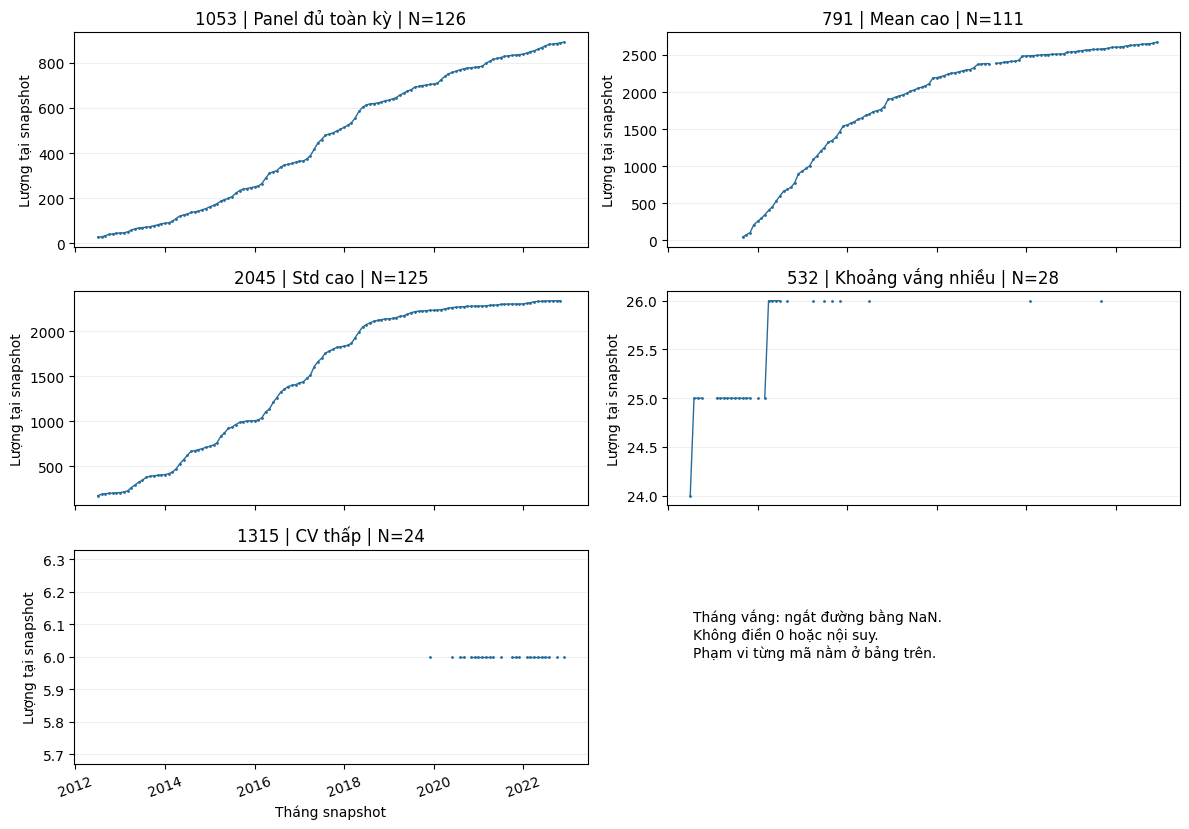

**Kết quả quan sát:** Năm chuỗi minh họa mức ghi nhận và lịch quan sát khác nhau. **Bằng chứng:** Mã được chọn: 1053, 791, 2045, 532, 1315; mọi số điểm và tháng vắng khớp nguồn. **Ý nghĩa:** Khoảng trống trên đồ thị được đọc như thiếu quan sát. **Giới hạn:** Chọn theo tiêu chí cực trị/độ phủ không tạo mẫu đại diện; range nhỏ hoặc CV thấp chưa là hiệu suất tốt. **Câu hỏi tiếp:** Có sự kiện kho hoặc thay đổi phạm vi nào giải thích được các điểm đặc biệt không?

In [20]:
selection_specs52=[('Panel đủ toàn kỳ',sorted(panel_ids52)),('Mean cao',list(eligible52.sort_values(['mean','product_id'],ascending=[False,True]).index)),
    ('Std cao',list(eligible52.sort_values(['std','product_id'],ascending=[False,True]).index)),
    ('Khoảng vắng nhiều',list(eligible52.sort_values(['internal_gaps','product_id'],ascending=[False,True]).index)),
    ('CV thấp',list(eligible52.sort_values(['cv','product_id'],ascending=[True,True]).index))]
selected_products52=[];seen52=set()
for label,candidates in selection_specs52:
    pid=next(pid for pid in candidates if pid not in seen52);seen52.add(pid)
    selected_products52.append({'Tiêu chí':label,'product_id':pid})
selection_table52=pd.DataFrame(selected_products52).merge(product_stats52.reset_index(),on='product_id',how='left',validate='one_to_one')
show52('Năm sản phẩm minh họa — chọn khách quan, không mặc định đại diện',selection_table52[['Tiêu chí','product_id','product_name','category','segment','months','first','last','internal_gaps','mean','median','std','cv']].rename(columns={
    'product_id':'Mã','product_name':'Tên nguồn','months':'Tháng quan sát','first':'Ngày đầu','last':'Ngày cuối','internal_gaps':'Tháng vắng trong khoảng','mean':'Mean','median':'Median','std':'Std mẫu','cv':'CV'}))
fig,axes=plt.subplots(3,2,figsize=(12,8.4),sharex=True);plot_series52={}
for ax,row in zip(axes.flat,selection_table52.to_dict('records')):
    pid=row['product_id'];observed=s52.loc[s52.product_id.eq(pid)].set_index('period').stock.sort_index()
    visual=observed.reindex(months52);plot_series52[pid]=visual
    ax.plot(visual.index.to_timestamp(),visual,marker='.',markersize=2,linewidth=1,color='#256c9b')
    ax.set(title=f"{pid} | {row['Tiêu chí']} | N={int(row['months'])}",ylabel='Lượng tại snapshot')
    ax.grid(axis='y',alpha=.2);ax.tick_params(axis='x',rotation=20)
axes.flat[-1].axis('off');axes.flat[-1].text(.05,.5,chr(10).join(['Tháng vắng: ngắt đường bằng NaN.','Không điền 0 hoặc nội suy.','Phạm vi từng mã nằm ở bảng trên.']),transform=axes.flat[-1].transAxes)
for ax in axes[-1,:]:ax.set_xlabel('Tháng snapshot')
plot_done(fig)
check52('Năm chuỗi khác mã; dữ liệu vẽ giữ đúng tháng vắng và mọi giá trị có thật',len(seen52)==5 and all(series.notna().sum()==period_counts52[pid] and series.dropna().to_dict()==s52.loc[s52.product_id.eq(pid)].set_index('period').stock.to_dict() and int(series.isna().sum())==len(months52)-period_counts52[pid] for pid,series in plot_series52.items()))
note52('Năm chuỗi minh họa mức ghi nhận và lịch quan sát khác nhau.',f'Mã được chọn: {", ".join(selection_table52.product_id)}; mọi số điểm và tháng vắng khớp nguồn.','Khoảng trống trên đồ thị được đọc như thiếu quan sát.','Chọn theo tiêu chí cực trị/độ phủ không tạo mẫu đại diện; range nhỏ hoặc CV thấp chưa là hiệu suất tốt.','Có sự kiện kho hoặc thay đổi phạm vi nào giải thích được các điểm đặc biệt không?')

### NV05.2.8 – Category: quy mô và mức ghi nhận trên sản phẩm quan sát

Category nguồn đã được đối chiếu products theo mã, duy nhất trên từng sản phẩm; JOIN không làm tăng dòng. Tính theo category–tháng: số sản phẩm, tổng snapshot, mean/median/P25/P75. Toàn kỳ: số sản phẩm, dòng, kỳ, độ phủ tháng/sản phẩm, phân bố và độ phân tán. “Mean tổng snapshot/tháng của category” là bình quân trên tháng có dữ liệu của category, không cộng các snapshot thành tồn năm/toàn kỳ.

Hiển thị đồng thời quy mô tuyệt đối và mean/median trên dòng; không coi category có tổng lớn là mức tồn mỗi sản phẩm cao hoặc bán chậm. Boxplot dùng mọi quan sát, trục log khi tất cả dương, giữ cả các điểm ngoài râu; hộp/râu chỉ là phân bố mô tả.

**Category toàn kỳ — tổng chỉ là mean các tổng snapshot tháng; phân bố mức tồn theo dòng**

Category,Dòng sản phẩm–tháng,Mean / dòng quan sát,Median / dòng quan sát,Min,Max,Std mẫu,P25,P75,P90,P95,Sản phẩm phân biệt,CV = std/mean,Tháng có dữ liệu,Min tháng/SP,Median tháng/SP,Mean tháng/SP,Max tháng/SP,Mean tổng snapshot/tháng,Mean SP/tháng,Min tổng snapshot,Max tổng snapshot,Std các tổng snapshot,% dòng ≤P25,% dòng >P75
Casual,3503,"88,6446","39,0000",3,891,"126,9922","12,0000","112,0000","226,8000","328,0000",119,"1,4326",126,1,"17,0000","29,4370",126,"2.464,4603","27,8016",497,4236,"1.192,7268","29,3177","12,1325"
GenZ,4674,"125,1085","33,0000",3,1264,"225,1502","10,0000","147,0000","305,7000","566,1500",113,"1,7996",126,1,"37,0000","41,3628",124,"4.640,9286","37,0952",1314,7224,"1.723,5484","35,1519","16,0248"
Outdoor,21050,"225,6480","84,0000",3,2673,"342,2331","20,0000","286,0000","682,0000","906,0000",502,"1,5167",126,1,"30,0000","41,9323",126,"37.697,5476","167,0635",8197,49929,"10.733,7086","20,8789","29,7625"
Streetwear,31020,"185,6703","59,0000",3,2370,"321,7651","14,0000","206,0000","493,0000","840,0000",890,"1,7330",126,1,"25,0000","34,8539",126,"45.710,2698","246,1905",13690,65295,"13.932,3284","26,5184","24,5648"


**Category–tháng: kỳ biên và tổng thấp/cao nhất trong từng category**

Category,Tháng snapshot,Sản phẩm phân biệt,Tổng tại snapshot,Mean / dòng quan sát,Median / dòng quan sát,P25,P75
Casual,2012-07,16,497,"31,0625","22,0000","20,2500","33,0000"
Casual,2020-08,44,4236,"96,2727","35,5000","8,2500","114,0000"
Casual,2022-12,40,4095,"102,3750","34,0000","8,5000","116,2500"
GenZ,2012-07,15,1314,"87,6000","55,0000","28,0000","94,0000"
GenZ,2021-05,55,7224,"131,3455","33,0000","8,5000","157,0000"
GenZ,2022-12,44,5126,"116,5000","34,5000","9,7500","95,5000"
Outdoor,2012-07,145,8197,"56,5310","25,0000","9,0000","71,0000"
Outdoor,2022-12,144,49929,"346,7292","107,0000","13,0000","530,7500"
Streetwear,2012-07,219,13690,"62,5114","26,0000","9,0000","81,0000"
Streetwear,2020-08,290,65295,"225,1552","66,5000","12,0000","261,2500"


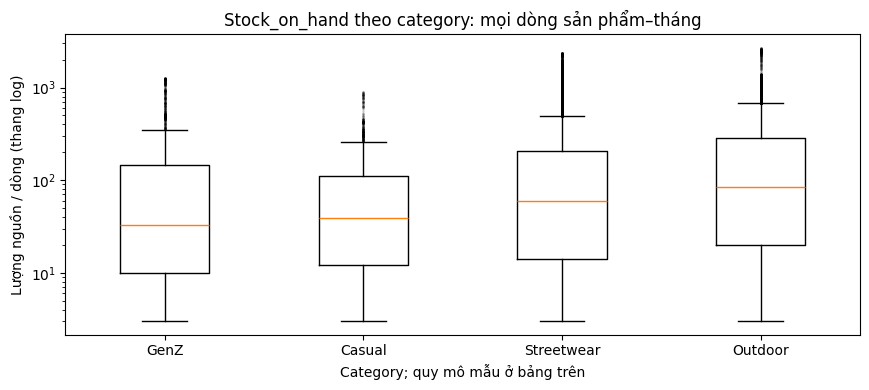

**Kết quả quan sát:** Quy mô category và mức ghi nhận trên dòng cần đọc riêng. **Bằng chứng:** Mean tổng snapshot cao nhất: Streetwear (45710.27); mean/dòng cao nhất: Outdoor; median/dòng cao nhất: Outdoor. **Ý nghĩa:** So cả tổng tháng và chỉ tiêu chuẩn hóa giúp giảm nhầm do số sản phẩm khác nhau. **Giới hạn:** Độ phủ và đơn vị có thể khác; không suy tốc độ bán, dư tồn hoặc chính sách category. **Câu hỏi tiếp:** Quy mô và quy tắc ghi nhận category có nhất quán trong lịch sử không?

In [21]:
category_month52=stats52(s52,['category','period'],snapshot=True)
category_stats52=stats52(s52,'category')
category_stats52['months']=s52.groupby('category').period.nunique()
cat_product_months52=s52.groupby(['category','product_id']).period.nunique()
for metric in ['min','median','mean','max']:
    category_stats52['coverage_'+metric]=getattr(cat_product_months52.groupby(level=0),metric)()
cat_month_group52=category_month52.groupby(level=0)
category_stats52['mean_total_snapshot']=cat_month_group52.total.mean()
category_stats52['mean_products_month']=cat_month_group52.products.mean()
category_stats52['min_total_snapshot']=cat_month_group52.total.min();category_stats52['max_total_snapshot']=cat_month_group52.total.max()
category_stats52['std_total_snapshot']=cat_month_group52.total.std()
category_stats52['low_pct']=s52.assign(flag=s52.stock.le(q25_52)).groupby('category').flag.mean()*100
category_stats52['high_pct']=s52.assign(flag=s52.stock.gt(q75_52)).groupby('category').flag.mean()*100
show52('Category toàn kỳ — tổng chỉ là mean các tổng snapshot tháng; phân bố mức tồn theo dòng',display52(category_stats52).rename(columns={
    'months':'Tháng có dữ liệu','coverage_min':'Min tháng/SP','coverage_median':'Median tháng/SP','coverage_mean':'Mean tháng/SP','coverage_max':'Max tháng/SP',
    'mean_total_snapshot':'Mean tổng snapshot/tháng','mean_products_month':'Mean SP/tháng','min_total_snapshot':'Min tổng snapshot','max_total_snapshot':'Max tổng snapshot','std_total_snapshot':'Std các tổng snapshot','low_pct':'% dòng ≤P25','high_pct':'% dòng >P75'}))
cat_selected52=[]
for cat,g in category_month52.groupby(level=0):
    keep={g.index[0],g.index[-1],g.total.idxmin(),g.total.idxmax()}
    cat_selected52.extend(sorted(keep))
show52('Category–tháng: kỳ biên và tổng thấp/cao nhất trong từng category',display52(category_month52.loc[cat_selected52,['products','total','mean','median','p25','p75']]))
category_order52=list(category_stats52.sort_values('median').index)
fig,ax=plt.subplots(figsize=(8.8,4))
ax.boxplot([s52.loc[s52.category.eq(c),'stock'].to_numpy() for c in category_order52],
    showfliers=True,flierprops={'marker':'.','markersize':1.5,'alpha':.2})
ax.set_xticks(np.arange(1,len(category_order52)+1));ax.set_xticklabels(category_order52)
if s52.stock.gt(0).all():ax.set_yscale('log')
ax.set(title='Stock_on_hand theo category: mọi dòng sản phẩm–tháng',xlabel='Category; quy mô mẫu ở bảng trên',ylabel='Lượng nguồn / dòng (thang log)')
plot_done(fig)
check52('Category không nhân dòng/mã, các tổng snapshot phân rã đúng tháng',category_stats52.n.sum()==len(s52) and category_month52.n.sum()==len(s52) and category_stats52.products.sum()==s52.product_id.nunique() and category_month52.total.groupby(level='period').sum().equals(monthly52.total) and not any(mapping52.values()))
category_top_total52=category_stats52.mean_total_snapshot.idxmax();category_top_mean52=category_stats52['mean'].idxmax();category_top_median52=category_stats52['median'].idxmax()
note52('Quy mô category và mức ghi nhận trên dòng cần đọc riêng.',f'Mean tổng snapshot cao nhất: {category_top_total52} ({category_stats52.loc[category_top_total52,"mean_total_snapshot"]:.2f}); mean/dòng cao nhất: {category_top_mean52}; median/dòng cao nhất: {category_top_median52}.','So cả tổng tháng và chỉ tiêu chuẩn hóa giúp giảm nhầm do số sản phẩm khác nhau.','Độ phủ và đơn vị có thể khác; không suy tốc độ bán, dư tồn hoặc chính sách category.','Quy mô và quy tắc ghi nhận category có nhất quán trong lịch sử không?')

### NV05.2.9 – Segment và ánh xạ category

Kiểm tra mỗi product_id chỉ có một cặp category/segment và khớp products. Segment có thể dùng chung tên ở nhiều category; bảng ánh xạ dùng cặp category–segment. Không cộng distinct product_id qua thời gian hoặc từ các nhóm có thể giao nhau để suy số sản phẩm toàn kỳ; dùng tập hợp khóa gốc.

Theo segment, báo số mã, dòng, kỳ, mean/median/phân vị/std/CV, độ phủ trên sản phẩm và mean/std của tổng snapshot tháng. Các segment không mặc định tương đương về tuổi đời, quy mô hoặc chính sách.

In [22]:
segment_month52=stats52(s52,['segment','period'],snapshot=True)
segment_stats52=stats52(s52,'segment')
segment_stats52['months']=s52.groupby('segment').period.nunique()
seg_product_months52=s52.groupby(['segment','product_id']).period.nunique()
segment_stats52['min_months_per_product']=seg_product_months52.groupby(level=0).min()
segment_stats52['median_months_per_product']=seg_product_months52.groupby(level=0).median()
segment_stats52['mean_total_snapshot']=segment_month52.groupby(level=0).total.mean()
segment_stats52['std_total_snapshot']=segment_month52.groupby(level=0).total.std()
segment_stats52['min_total_snapshot']=segment_month52.groupby(level=0).total.min();segment_stats52['max_total_snapshot']=segment_month52.groupby(level=0).total.max()
mapping_groups52=s52.groupby(['category','segment']).agg(products=('product_id','nunique'),rows=('stock','size'),months=('period','nunique'))
show52('Ánh xạ category–segment — mỗi sản phẩm một cặp trong dữ liệu hiện tại',display52(mapping_groups52).rename(columns={'rows':'Dòng','months':'Tháng'}))
show52('Segment toàn kỳ — phân bố theo dòng và tổng tại từng kỳ, không cộng snapshot qua tháng',display52(segment_stats52).rename(columns={
    'months':'Tháng có dữ liệu','min_months_per_product':'Min tháng/SP','median_months_per_product':'Median tháng/SP','mean_total_snapshot':'Mean tổng snapshot/tháng',
    'std_total_snapshot':'Std các tổng snapshot','min_total_snapshot':'Min tổng snapshot','max_total_snapshot':'Max tổng snapshot'}))
check52('Segment/category ánh xạ nhất quán, phân rã đúng dòng và tổng snapshot',segment_stats52.n.sum()==len(s52) and segment_month52.n.sum()==len(s52) and segment_month52.total.groupby(level='period').sum().equals(monthly52.total) and s52.groupby('product_id')[['segment','category']].nunique().eq(1).all().all() and mapping_groups52.rows.sum()==len(s52))
segment_hi52=segment_stats52['mean'].idxmax();segment_low52=segment_stats52['mean'].idxmin();segment_var52=segment_stats52['std'].idxmax()
note52('Segment có mức ghi nhận và độ phủ sản phẩm khác nhau.',f'Mean cao: {segment_hi52} ({segment_stats52.loc[segment_hi52,"mean"]:.2f}); thấp: {segment_low52} ({segment_stats52.loc[segment_low52,"mean"]:.2f}); std lớn: {segment_var52}; số kỳ segment {segment_stats52.months.min()}–{segment_stats52.months.max()}.','Cần kèm số sản phẩm và tháng trên sản phẩm để so các nhóm.','Tên segment có thể giao category; không coi khác biệt là hiệu quả hoặc chính sách đã xác nhận.','Cùng tên segment ở các category có cùng định nghĩa nghiệp vụ không?')

**Ánh xạ category–segment — mỗi sản phẩm một cặp trong dữ liệu hiện tại**

Category,Segment,Sản phẩm phân biệt,Dòng,Tháng
Casual,Activewear,24,422,89
Casual,All-weather,95,3081,126
GenZ,Trendy,113,4674,126
Outdoor,Activewear,412,17868,126
Outdoor,Premium,90,3182,126
Streetwear,Balanced,203,6622,126
Streetwear,Everyday,324,13598,126
Streetwear,Performance,250,7673,126
Streetwear,Standard,113,3127,126


**Segment toàn kỳ — phân bố theo dòng và tổng tại từng kỳ, không cộng snapshot qua tháng**

Segment,Dòng sản phẩm–tháng,Mean / dòng quan sát,Median / dòng quan sát,Min,Max,Std mẫu,P25,P75,P90,P95,Sản phẩm phân biệt,CV = std/mean,Tháng có dữ liệu,Min tháng/SP,Median tháng/SP,Mean tổng snapshot/tháng,Std các tổng snapshot,Min tổng snapshot,Max tổng snapshot
Activewear,18290,"230,8013","76,0000",3,2673,"356,8397","18,0000","293,0000","701,0000","950,0000",436,"1,5461",126,1,"30,0000","33.502,8175","9.179,0096",7764,43735
All-weather,3081,"98,9546","55,0000",3,891,"132,0753","16,0000","121,0000","240,0000","342,0000",95,"1,3347",126,1,"17,0000","2.419,6746","1.156,9719",497,4134
Balanced,6622,"180,5153","55,0000",3,2014,"326,6183","16,0000","177,7500","449,9000","847,8000",203,"1,8094",126,1,"23,0000","9.487,0794","3.280,7739",2589,15185
Everyday,13598,"204,7194","100,0000",3,2370,"283,5421","26,0000","275,0000","518,0000","748,1500",324,"1,3850",126,1,"33,0000","22.093,4444","5.923,9991",7675,31158
Performance,7673,"217,8865","43,0000",3,2339,"414,8906","10,0000","212,0000","669,0000","1.262,4000",250,"1,9042",126,1,"21,0000","13.268,5952","5.351,3410",2928,20261
Premium,3182,"167,8752","91,0000",3,1178,"213,0978","23,0000","230,0000","402,9000","506,0000",90,"1,2694",126,1,"20,5000","4.239,5159","1.668,2411",433,6640
Standard,3127,"34,6994","15,0000",3,291,"47,4999","8,0000","44,5000","78,0000","127,0000",113,"1,3689",126,1,"23,0000","861,1508","203,1471",433,1269
Trendy,4674,"125,1085","33,0000",3,1264,"225,1502","10,0000","147,0000","305,7000","566,1500",113,"1,7996",126,1,"37,0000","4.640,9286","1.723,5484",1314,7224


**Kết quả quan sát:** Segment có mức ghi nhận và độ phủ sản phẩm khác nhau. **Bằng chứng:** Mean cao: Activewear (230.80); thấp: Standard (34.70); std lớn: Performance; số kỳ segment 126–126. **Ý nghĩa:** Cần kèm số sản phẩm và tháng trên sản phẩm để so các nhóm. **Giới hạn:** Tên segment có thể giao category; không coi khác biệt là hiệu quả hoặc chính sách đã xác nhận. **Câu hỏi tiếp:** Cùng tên segment ở các category có cùng định nghĩa nghiệp vụ không?

### NV05.2.10 – Tính lặp lại theo tháng lịch: chỉ mô tả

Chỉ dùng các năm đủ 2013–2022; mỗi tháng lịch có cùng số năm. So toàn bộ quan sát với panel toàn kỳ. Bảng giữ số dòng, năm, snapshot, sản phẩm bình quân mỗi snapshot, mean/median dòng và mean tổng snapshot. Chỉ số mỗi năm = tổng snapshot tháng / bình quân 12 tổng snapshot của chính năm đó; giúp bỏ khác biệt quy mô năm, chưa loại thành phần sản phẩm thay đổi.

Tần suất cao hơn bình quân năm đếm trên các năm riêng biệt. Bảng tháng đỉnh/đáy theo năm kiểm tra sự lặp lại; đồng hạng lấy tháng sớm nhất và báo số tháng đồng hạng. Dải trên biểu đồ là min–max chỉ số của các năm, không là khoảng tin cậy. Đây không phải kiểm định/mô hình mùa vụ và không gán tác động lễ hoặc chiến dịch.

**Tháng lịch 2013–2022 — phân biệt thống kê dòng, snapshot và chỉ số đã chuẩn hóa trong năm**

Phạm vi,Tháng lịch,Dòng sản phẩm–tháng,Năm,Snapshot,Mean / dòng,Median / dòng,Mean tổng snapshot,Mean SP / snapshot,Mean chỉ số trong năm,Min chỉ số giữa các năm,Max chỉ số giữa các năm,Năm cao hơn bình quân của năm
Toàn bộ; tập thay đổi,1,4336,10,10,"196,4137","70,0000","85.165,0000","433,6000","0,8965","0,7640","0,9666",0
Toàn bộ; tập thay đổi,2,4567,10,10,"191,7138","66,0000","87.555,7000","456,7000","0,9216","0,7984","1,0123",1
Toàn bộ; tập thay đổi,3,4924,10,10,"186,3968","61,0000","91.781,8000","492,4000","0,9660","0,8383","1,0853",2
Toàn bộ; tập thay đổi,4,5181,10,10,"181,0581","57,0000","93.806,2000","518,1000","0,9912","0,8959","1,0968",3
Toàn bộ; tập thay đổi,5,5117,10,10,"187,3842","61,0000","95.884,5000","511,7000","1,0165","0,9454","1,0965",6
Toàn bộ; tập thay đổi,6,5052,10,10,"189,8828","61,0000","95.928,8000","505,2000","1,0228","1,0000","1,0405",10
Toàn bộ; tập thay đổi,7,4843,10,10,"197,5984","66,0000","95.696,9000","484,3000","1,0254","0,9572","1,0590",9
Toàn bộ; tập thay đổi,8,5118,10,10,"190,4707","61,0000","97.482,9000","511,8000","1,0458","0,9834","1,1014",8
Toàn bộ; tập thay đổi,9,4777,10,10,"201,6931","66,0000","96.348,8000","477,7000","1,0373","0,9770","1,1213",8
Toàn bộ; tập thay đổi,10,4693,10,10,"203,9898","68,0000","95.732,4000","469,3000","1,0340","0,9370","1,1424",7


**Kiểm tra lặp lại giữa năm — đỉnh/đáy tổng snapshot của từng phạm vi, không là kiểm định mùa vụ**

Phạm vi,Năm,Tháng tổng cao nhất,Số tháng đồng đỉnh,Tháng tổng thấp nhất,Số tháng đồng đáy
Toàn bộ; tập thay đổi,2013,12,1,1,1
Toàn bộ; tập thay đổi,2014,12,1,1,1
Toàn bộ; tập thay đổi,2015,10,1,1,1
Toàn bộ; tập thay đổi,2016,8,1,2,1
Toàn bộ; tập thay đổi,2017,12,1,1,1
Toàn bộ; tập thay đổi,2018,10,1,1,1
Toàn bộ; tập thay đổi,2019,9,1,4,1
Toàn bộ; tập thay đổi,2020,8,1,1,1
Toàn bộ; tập thay đổi,2021,4,1,11,1
Toàn bộ; tập thay đổi,2022,4,1,11,1


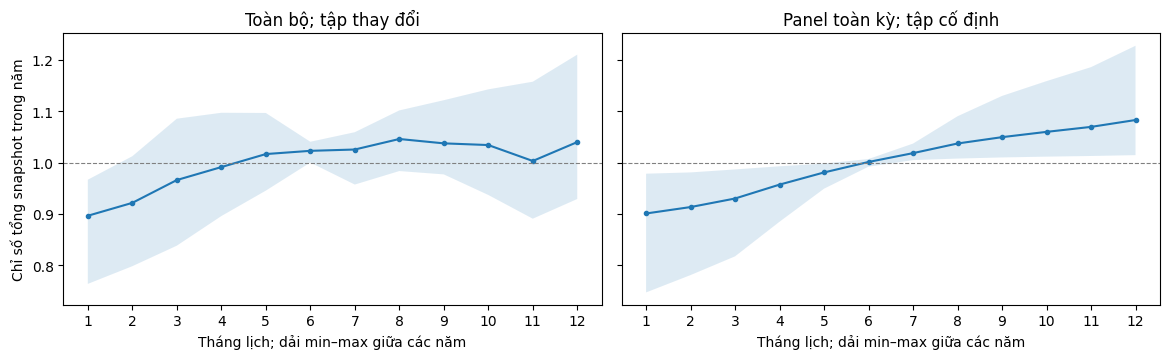

**Kết quả quan sát:** Có thể mô tả tháng lịch và kiểm tra sự lặp lại theo từng năm. **Bằng chứng:** Panel toàn kỳ; tập cố định: chỉ số bình quân cao nhất tháng 12, 10/10 năm trên bình quân năm; Toàn bộ; tập thay đổi: chỉ số bình quân cao nhất tháng 8, 8/10 năm trên bình quân năm. Toàn bộ; tập thay đổi: tháng đỉnh thường gặp nhất 12, 3/10 năm; Panel toàn kỳ; tập cố định: tháng đỉnh thường gặp nhất 12, 10/10 năm **Ý nghĩa:** Đối chiếu panel và các năm riêng giúp tránh kết luận từ trung bình tháng đơn lẻ. **Giới hạn:** Chưa kiểm định mùa vụ; panel có thể tăng dần trong năm nên tháng cuối cao hơn chưa chứng minh chu kỳ; cơ cấu vẫn ảnh hưởng, dải không là khoảng tin cậy. **Câu hỏi tiếp:** Mẫu lặp còn giữ sau kiểm soát xu thế và định nghĩa ghi nhận không?

In [23]:
season_rows52=[];season_year_rows52=[];season_month_tables52={}
for label,frame in [('Toàn bộ; tập thay đổi',s52),('Panel toàn kỳ; tập cố định',panel_data52)]:
    frame=frame.loc[frame.year.isin(full_years52)]
    mt=stats52(frame,'period',snapshot=True);mt['year']=mt.index.year;mt['calendar_month']=mt.index.month
    mt['index_within_year']=mt.total/mt.groupby('year').total.transform('mean')
    season_month_tables52[label]=mt
    for month,part in frame.groupby('calendar_month'):
        snap=mt.loc[mt.calendar_month.eq(month)]
        season_rows52.append({'Phạm vi':label,'Tháng lịch':month,'Dòng sản phẩm–tháng':len(part),'Năm':part.year.nunique(),'Snapshot':len(snap),
            'Mean / dòng':part.stock.mean(),'Median / dòng':part.stock.median(),'Mean tổng snapshot':snap.total.mean(),'Mean SP / snapshot':snap.products.mean(),
            'Mean chỉ số trong năm':snap.index_within_year.mean(),'Min chỉ số giữa các năm':snap.index_within_year.min(),'Max chỉ số giữa các năm':snap.index_within_year.max(),
            'Năm cao hơn bình quân của năm':int(snap.index_within_year.gt(1).sum())})
    for y,g in mt.groupby('year'):
        season_year_rows52.append({'Phạm vi':label,'Năm':y,'Tháng tổng cao nhất':g.total.idxmax().month,'Số tháng đồng đỉnh':int(g.total.eq(g.total.max()).sum()),
            'Tháng tổng thấp nhất':g.total.idxmin().month,'Số tháng đồng đáy':int(g.total.eq(g.total.min()).sum())})
season_summary52=pd.DataFrame(season_rows52);season_year52=pd.DataFrame(season_year_rows52)
show52('Tháng lịch 2013–2022 — phân biệt thống kê dòng, snapshot và chỉ số đã chuẩn hóa trong năm',season_summary52)
show52('Kiểm tra lặp lại giữa năm — đỉnh/đáy tổng snapshot của từng phạm vi, không là kiểm định mùa vụ',season_year52)
fig,axes=plt.subplots(1,2,figsize=(11.8,3.7),sharey=True)
for ax,(label,part) in zip(axes,season_summary52.groupby('Phạm vi',sort=False)):
    ax.plot(part['Tháng lịch'],part['Mean chỉ số trong năm'],marker='o',markersize=3)
    ax.fill_between(part['Tháng lịch'].to_numpy(),part['Min chỉ số giữa các năm'].to_numpy(),part['Max chỉ số giữa các năm'].to_numpy(),alpha=.15)
    ax.axhline(1,color='gray',linestyle='--',linewidth=.8);ax.set(title=label,xlabel='Tháng lịch; dải min–max giữa các năm',xticks=range(1,13))
axes[0].set_ylabel('Chỉ số tổng snapshot trong năm');plot_done(fig)
check52('Mùa vụ mô tả chỉ dùng năm đủ, mỗi tháng có 10 snapshot/năm và panel giữ tập',all(set(mt.year)==set(full_years52) and len(mt)==12*len(full_years52) and mt.groupby('calendar_month').size().eq(len(full_years52)).all() and np.allclose(mt.groupby('year').index_within_year.mean(),1) for mt in season_month_tables52.values()) and season_summary52['Năm'].eq(len(full_years52)).all() and season_summary52['Snapshot'].eq(len(full_years52)).all())
peak_counts52=season_year52.groupby('Phạm vi')['Tháng tổng cao nhất'].value_counts()
season_best52=season_summary52.loc[season_summary52.groupby('Phạm vi')['Mean chỉ số trong năm'].idxmax()]
repeat_text_parts52=[]
for label,part in season_year52.groupby('Phạm vi',sort=False):
    peaks=Counter(part['Tháng tổng cao nhất']);modal=min(peaks,key=lambda m:(-peaks[m],m))
    repeat_text_parts52.append(f'{label}: tháng đỉnh thường gặp nhất {modal}, {peaks[modal]}/{len(part)} năm')
repeat_text52='; '.join(repeat_text_parts52)
note52('Có thể mô tả tháng lịch và kiểm tra sự lặp lại theo từng năm.', '; '.join(f"{r['Phạm vi']}: chỉ số bình quân cao nhất tháng {r['Tháng lịch']}, {r['Năm cao hơn bình quân của năm']}/{r['Năm']} năm trên bình quân năm" for r in season_best52.to_dict('records'))+'. '+repeat_text52, 'Đối chiếu panel và các năm riêng giúp tránh kết luận từ trung bình tháng đơn lẻ.','Chưa kiểm định mùa vụ; panel có thể tăng dần trong năm nên tháng cuối cao hơn chưa chứng minh chu kỳ; cơ cấu vẫn ảnh hưởng, dải không là khoảng tin cậy.','Mẫu lặp còn giữ sau kiểm soát xu thế và định nghĩa ghi nhận không?')

### NV05.2.11 – Bảng gọn các trường số liên quan

Chỉ lấy mean/median theo dòng trong từng tháng, cùng số quan sát hợp lệ; hiển thị hai kỳ biên và ba kỳ thay đổi tổng lớn nhất. Tỷ số được bình quân đơn giản, không là tỷ lệ tổng hợp có trọng số và không cộng thành tỷ lệ năm. Units_sold giữ nghĩa nguồn chưa đồng nhất quantity; stockout_days không xác nhận hết hàng cuối kỳ, days_of_supply chưa xác minh công thức. Không tái đối soát giao dịch hoặc cân bằng tồn kho; reorder_flag hằng không dùng phân nhóm/mục tiêu.

In [24]:
related_fields52=['units_received','units_sold','stockout_days','days_of_supply','fill_rate','sell_through_rate']
related52=pd.DataFrame({'period':s52.period})
for c in related_fields52:related52[c]=[float(v) for v in numeric[c]]
related_month52=related52.groupby('period')[related_fields52].agg(['count','mean','median'])
related_display52=[]
related_periods52=sorted({months52[0],months52[-1]}|set(largest_changes52.head(3).index))
for p in related_periods52:
    for c in related_fields52:
        related_display52.append({'Tháng':str(p),'Trường':c,'Dòng hợp lệ':int(related_month52.loc[p,(c,'count')]),'Mean đơn giản / dòng':related_month52.loc[p,(c,'mean')],
            'Median / dòng':related_month52.loc[p,(c,'median')],'Đơn vị/giới hạn':'Lượng nguồn' if c in ['units_received','units_sold'] else 'Số mang tên ngày, công thức chưa xác minh' if c in ['stockout_days','days_of_supply'] else 'Tỷ số nguồn, mean không là tỷ lệ gộp có trọng số'})
show52('Trường liên quan — chỉ mô tả trên dòng trong tháng được chọn; không cộng tỷ số hoặc suy luân chuyển',pd.DataFrame(related_display52))
check52('Trường liên quan giữ từng giá trị nguồn, số đếm tháng và chỉ tính mean/median tỷ số',all(related52[c].tolist()==[float(v) for v in numeric[c]] for c in related_fields52) and all(related_month52[(c,'count')].to_dict()==monthly52.n.to_dict() for c in related_fields52) and related_month52.columns.get_level_values(1).isin(['count','mean','median']).all() and set(inventory.reorder_flag)=={'0'})
note52('Các trường liên quan vẫn chỉ được dùng ở mức mô tả.',f'{len(related_fields52)} trường, {len(related_periods52)} tháng minh họa; mẫu số khớp từng tháng.','Có ngữ cảnh số học để đặt câu hỏi về nguồn tính.','Không đồng nhất units_sold với quantity, không xác nhận tỷ lệ vận hành hoặc nhu cầu nhập từ cờ hằng.','Từ điển và tử số/mẫu số từng trường đã được chủ dữ liệu xác nhận chưa?')

**Trường liên quan — chỉ mô tả trên dòng trong tháng được chọn; không cộng tỷ số hoặc suy luân chuyển**

Tháng,Trường,Dòng hợp lệ,Mean đơn giản / dòng,Median / dòng,Đơn vị/giới hạn
2012-07,units_received,395,"22,2684","9,0000",Lượng nguồn
2012-07,units_sold,395,"18,8633","8,0000",Lượng nguồn
2012-07,stockout_days,395,"1,0177","1,0000","Số mang tên ngày, công thức chưa xác minh"
2012-07,days_of_supply,395,"93,2532","93,3000","Số mang tên ngày, công thức chưa xác minh"
2012-07,fill_rate,395,"0,9661","0,9667","Tỷ số nguồn, mean không là tỷ lệ gộp có trọng số"
2012-07,sell_through_rate,395,"0,2435","0,2432","Tỷ số nguồn, mean không là tỷ lệ gộp có trọng số"
2019-05,units_received,527,"14,6945","6,0000",Lượng nguồn
2019-05,units_sold,527,"12,6186","5,0000",Lượng nguồn
2019-05,stockout_days,527,"1,1784","1,0000","Số mang tên ngày, công thức chưa xác minh"
2019-05,days_of_supply,527,"1.078,2457","355,9000","Số mang tên ngày, công thức chưa xác minh"


**Kết quả quan sát:** Các trường liên quan vẫn chỉ được dùng ở mức mô tả. **Bằng chứng:** 6 trường, 5 tháng minh họa; mẫu số khớp từng tháng. **Ý nghĩa:** Có ngữ cảnh số học để đặt câu hỏi về nguồn tính. **Giới hạn:** Không đồng nhất units_sold với quantity, không xác nhận tỷ lệ vận hành hoặc nhu cầu nhập từ cờ hằng. **Câu hỏi tiếp:** Từ điển và tử số/mẫu số từng trường đã được chủ dữ liệu xác nhận chưa?

### NV05.2.12 – Những hiện tượng và giới hạn cần làm rõ

Nhóm A chỉ ghi vi phạm kỹ thuật đã xác minh, nếu không có thì báo rõ không phát hiện. Nhóm B là hiện tượng mô tả cần tìm nguyên nhân, C là thiếu thông tin/định nghĩa để diễn giải. Các chênh snapshot, phân vị và cực trị không tự là lỗi, dư tồn, thiếu hàng hoặc hiệu suất vận hành.

In [25]:
issues52=pd.DataFrame([
 {'Mã':'A01','Nhóm':'A','Hiện tượng':'Không phát hiện vi phạm kỹ thuật trong các ràng buộc đang kiểm tra','Bằng chứng':'0 khóa sản phẩm–tháng lặp; 0 nhãn category/segment khác products; JOIN bảo toàn dòng','Phạm vi':'Toàn bộ inventory',
  'Ảnh hưởng':'Có cơ sở tổng hợp đúng đơn vị trong tệp','Giới hạn':'Không chứng minh hợp đồng hệ thống hoặc ngữ nghĩa kho','Mức độ':'Đã kiểm tra cấu trúc; không tạo lỗi giả','Câu hỏi tiếp':'Có hợp đồng schema/khóa nguồn và cấp kho không?'},
 {'Mã':'B01','Nhóm':'B','Hiện tượng':'Tập sản phẩm thay đổi giữa snapshot','Bằng chứng':f'{cov52.products.min()}–{cov52.products.max()} SP/tháng; Jaccard thấp nhất {cov52.jaccard_pct.min():.2f}%','Phạm vi':f'{months52.min()}–{months52.max()}',
  'Ảnh hưởng':'Thay đổi tổng có phần do cơ cấu quan sát','Giới hạn':'Không là xuất hiện/ngừng bán hoặc luồng hàng','Mức độ':'Tập khóa đã kiểm tra, nguyên nhân chưa rõ','Câu hỏi tiếp':'Danh mục sản phẩm bắt buộc báo cáo từng tháng là gì?'},
 {'Mã':'B02','Nhóm':'B','Hiện tượng':'Panel toàn kỳ nhỏ, panel năm thay đổi thành phần','Bằng chứng':f'Panel toàn kỳ {len(panel_ids52)} SP; {len({frozenset(v) for v in year_panels52.values()})} tập panel năm khác nhau','Phạm vi':'Panel toàn kỳ và các năm đủ',
  'Ảnh hưởng':'Xu hướng nhạy với cách giữ tập sản phẩm','Giới hạn':'Panel không mặc định đại diện hoặc cố định xuyên năm','Mức độ':'Đã xác minh phần tử và số kỳ','Câu hỏi tiếp':'Vì sao các sản phẩm quan sát dài khác nhóm còn lại?'},
 {'Mã':'B03','Nhóm':'B','Hiện tượng':'Khoảng vắng và xuất hiện trở lại','Bằng chứng':f'{int(coverage.internal_unobserved.gt(0).sum())} SP có {int(coverage.internal_unobserved.sum())} vị trí tháng vắng trong khoảng; {int(cov52.returned_after_gap.sum())} lượt quay lại','Phạm vi':'Khoảng đầu–cuối từng sản phẩm',
  'Ảnh hưởng':'Chuỗi và so sánh cần giữ thiếu quan sát','Giới hạn':'Vắng không là stock=0 hoặc thiếu báo cáo đã xác nhận','Mức độ':'Lịch quan sát đã tính, lịch bắt buộc chưa có','Câu hỏi tiếp':'Các khoảng vắng được lưu ở nguồn khác hay do chọn mẫu?'},
 {'Mã':'B04','Nhóm':'B','Hiện tượng':'Phân bố lệch và cực trị, mean khác median','Bằng chứng':f'Mean dòng {s52.stock.mean():.4f}; median {s52.stock.median():.4f}; max {s52.stock.max()}; giữ toàn bộ dòng','Phạm vi':'Mọi sản phẩm–tháng',
  'Ảnh hưởng':'Bình quân riêng lẻ chưa mô tả mức điển hình','Giới hạn':'Cực trị không là lỗi hoặc dư tồn','Mức độ':'Đã tính phân bố/giữ nguồn','Câu hỏi tiếp':'Đơn vị lượng và bối cảnh từng cực trị là gì?'},
 {'Mã':'B05','Nhóm':'B','Hiện tượng':'Nhiều sản phẩm chưa đủ lịch cho xếp hạng dài kỳ','Bằng chứng':f'{int(product_stats52.months.le(2).sum())} SP chỉ 1–2 tháng; {int(product_stats52.months.lt(threshold52).sum())} dưới {threshold52} tháng','Phạm vi':'Tất cả mã; top chỉ nhóm đạt ngưỡng',
  'Ảnh hưởng':'Mean/std phụ thuộc khoảng và số kỳ quan sát','Giới hạn':'Ngưỡng 24 tháng là quy ước mô tả, không đảm bảo liên tục','Mức độ':'Số kỳ và ngưỡng đã kiểm tra','Câu hỏi tiếp':'Vòng đời và lịch ghi nhận của các sản phẩm ít kỳ ra sao?'},
 {'Mã':'B06','Nhóm':'B','Hiện tượng':'Quy mô category/segment khác nhau','Bằng chứng':f'Category có {category_stats52.products.min()}–{category_stats52.products.max()} SP; segment có {segment_stats52.products.min()}–{segment_stats52.products.max()} SP','Phạm vi':'Category/segment toàn kỳ và từng tháng',
  'Ảnh hưởng':'Phải đọc cả tổng snapshot và mean/median trên dòng','Giới hạn':'Chưa biết đơn vị vật lý, tuổi đời và chính sách từng nhóm','Mức độ':'Ánh xạ và quy mô đã kiểm tra','Câu hỏi tiếp':'Các nhóm có thể so trực tiếp với nhau theo đơn vị nào?'},
 {'Mã':'B07','Nhóm':'B','Hiện tượng':'Tháng lịch có mức ghi nhận bình quân khác nhau','Bằng chứng':'; '.join(f"{r['Phạm vi']}: tháng {r['Tháng lịch']} có chỉ số bình quân cao nhất" for r in season_best52.to_dict('records')),'Phạm vi':f'Năm đủ {min(full_years52)}–{max(full_years52)}',
  'Ảnh hưởng':'Cần đối chiếu lặp lại từng năm và panel','Giới hạn':'Chưa xác minh mùa vụ; không gán dịp lễ hoặc chiến dịch','Mức độ':'Mô tả theo năm/tháng, chưa kiểm định mô hình','Câu hỏi tiếp':'Khác biệt còn giữ khi kiểm soát xu thế và thành phần không?'},
 {'Mã':'C01','Nhóm':'C','Hiện tượng':'Chưa có ngữ nghĩa đủ để suy luồng hàng hoặc hiệu suất','Bằng chứng':f'reorder_flag một lớp; units_sold chưa đồng nhất quantity (V04); {len(related_fields52)} trường liên quan chỉ mô tả','Phạm vi':'Snapshot, lượng, tỷ số, cờ nguồn',
  'Ảnh hưởng':'Không suy vòng quay, nhập/bán/hoàn, nhu cầu đặt hàng hay stockout vận hành','Giới hạn':'Thiếu lịch, cấp kho, sự kiện, công thức và chính sách','Mức độ':'Đặc điểm dữ liệu rõ, nghiệp vụ chưa xác minh','Câu hỏi tiếp':'Ai xác nhận được đơn vị, công thức và quy tắc ghi nhận trước NV05.3–NV05.4?'}])
show52('Các vấn đề NV05.2 — A: kỹ thuật; B: hiện tượng; C: thiếu định nghĩa',issues52)
check52('Các vấn đề A/B/C có mã, bằng chứng, phạm vi và giới hạn; không báo lỗi kỹ thuật giả',issues52['Mã'].is_unique and issues52.notna().all().all() and set(issues52['Nhóm'])=={'A','B','C'} and not s52.duplicated(['product_id','period']).any() and not any(mapping52.values()))
note52('Các hiện tượng đã được tách khỏi kết luận nhân quả.',f'{len(issues52)} mục; A01 không phát hiện vi phạm, các mục B/C có bằng chứng và giới hạn.','Có danh sách câu hỏi phục vụ các bước sau.','Không có cơ sở kết luận dư/thiếu, bán chậm, nhập thêm hoặc hiệu suất.','Chủ dữ liệu có thể ưu tiên xác minh lịch quan sát, đơn vị và công thức nào trước?')

**Các vấn đề NV05.2 — A: kỹ thuật; B: hiện tượng; C: thiếu định nghĩa**

Mã,Nhóm,Hiện tượng,Bằng chứng,Phạm vi,Ảnh hưởng,Giới hạn,Mức độ,Câu hỏi tiếp
A01,A,Không phát hiện vi phạm kỹ thuật trong các ràng buộc đang kiểm tra,0 khóa sản phẩm–tháng lặp; 0 nhãn category/segment khác products; JOIN bảo toàn dòng,Toàn bộ inventory,Có cơ sở tổng hợp đúng đơn vị trong tệp,Không chứng minh hợp đồng hệ thống hoặc ngữ nghĩa kho,Đã kiểm tra cấu trúc; không tạo lỗi giả,Có hợp đồng schema/khóa nguồn và cấp kho không?
B01,B,Tập sản phẩm thay đổi giữa snapshot,376–562 SP/tháng; Jaccard thấp nhất 56.76%,2012-07–2022-12,Thay đổi tổng có phần do cơ cấu quan sát,Không là xuất hiện/ngừng bán hoặc luồng hàng,"Tập khóa đã kiểm tra, nguyên nhân chưa rõ",Danh mục sản phẩm bắt buộc báo cáo từng tháng là gì?
B02,B,"Panel toàn kỳ nhỏ, panel năm thay đổi thành phần",Panel toàn kỳ 22 SP; 10 tập panel năm khác nhau,Panel toàn kỳ và các năm đủ,Xu hướng nhạy với cách giữ tập sản phẩm,Panel không mặc định đại diện hoặc cố định xuyên năm,Đã xác minh phần tử và số kỳ,Vì sao các sản phẩm quan sát dài khác nhóm còn lại?
B03,B,Khoảng vắng và xuất hiện trở lại,1302 SP có 25456 vị trí tháng vắng trong khoảng; 7099 lượt quay lại,Khoảng đầu–cuối từng sản phẩm,Chuỗi và so sánh cần giữ thiếu quan sát,Vắng không là stock=0 hoặc thiếu báo cáo đã xác nhận,"Lịch quan sát đã tính, lịch bắt buộc chưa có",Các khoảng vắng được lưu ở nguồn khác hay do chọn mẫu?
B04,B,"Phân bố lệch và cực trị, mean khác median",Mean dòng 189.2985; median 62.0000; max 2673; giữ toàn bộ dòng,Mọi sản phẩm–tháng,Bình quân riêng lẻ chưa mô tả mức điển hình,Cực trị không là lỗi hoặc dư tồn,Đã tính phân bố/giữ nguồn,Đơn vị lượng và bối cảnh từng cực trị là gì?
B05,B,Nhiều sản phẩm chưa đủ lịch cho xếp hạng dài kỳ,161 SP chỉ 1–2 tháng; 744 dưới 24 tháng,Tất cả mã; top chỉ nhóm đạt ngưỡng,Mean/std phụ thuộc khoảng và số kỳ quan sát,"Ngưỡng 24 tháng là quy ước mô tả, không đảm bảo liên tục",Số kỳ và ngưỡng đã kiểm tra,Vòng đời và lịch ghi nhận của các sản phẩm ít kỳ ra sao?
B06,B,Quy mô category/segment khác nhau,Category có 113–890 SP; segment có 90–436 SP,Category/segment toàn kỳ và từng tháng,Phải đọc cả tổng snapshot và mean/median trên dòng,"Chưa biết đơn vị vật lý, tuổi đời và chính sách từng nhóm",Ánh xạ và quy mô đã kiểm tra,Các nhóm có thể so trực tiếp với nhau theo đơn vị nào?
B07,B,Tháng lịch có mức ghi nhận bình quân khác nhau,Panel toàn kỳ; tập cố định: tháng 12 có chỉ số bình quân cao nhất; Toàn bộ; tập thay đổi: tháng 8 có chỉ số bình quân cao nhất,Năm đủ 2013–2022,Cần đối chiếu lặp lại từng năm và panel,Chưa xác minh mùa vụ; không gán dịp lễ hoặc chiến dịch,"Mô tả theo năm/tháng, chưa kiểm định mô hình",Khác biệt còn giữ khi kiểm soát xu thế và thành phần không?
C01,C,Chưa có ngữ nghĩa đủ để suy luồng hàng hoặc hiệu suất,reorder_flag một lớp; units_sold chưa đồng nhất quantity (V04); 6 trường liên quan chỉ mô tả,"Snapshot, lượng, tỷ số, cờ nguồn","Không suy vòng quay, nhập/bán/hoàn, nhu cầu đặt hàng hay stockout vận hành","Thiếu lịch, cấp kho, sự kiện, công thức và chính sách","Đặc điểm dữ liệu rõ, nghiệp vụ chưa xác minh","Ai xác nhận được đơn vị, công thức và quy tắc ghi nhận trước NV05.3–NV05.4?"


**Kết quả quan sát:** Các hiện tượng đã được tách khỏi kết luận nhân quả. **Bằng chứng:** 9 mục; A01 không phát hiện vi phạm, các mục B/C có bằng chứng và giới hạn. **Ý nghĩa:** Có danh sách câu hỏi phục vụ các bước sau. **Giới hạn:** Không có cơ sở kết luận dư/thiếu, bán chậm, nhập thêm hoặc hiệu suất. **Câu hỏi tiếp:** Chủ dữ liệu có thể ưu tiên xác minh lịch quan sát, đơn vị và công thức nào trước?

### Ví dụ độc lập trong bộ nhớ – mười tình huống bắt buộc

Mẫu tổng hợp tách khỏi dữ liệu nguồn. Bao gồm số kỳ khác nhau, tháng vắng giữa, chỉ xuất hiện ở biên, thành phần thay đổi, thay đổi trên cùng tập, mean tăng nhưng median không tăng, cực trị, category ít sản phẩm mean cao và năm thiếu tháng. Kỳ vọng cố định được kiểm tra bằng đẳng thức/tập, không tự đánh dấu đạt.

In [26]:
fixture52=pd.DataFrame([['A','2022-01',10,'Lo'],['A','2022-03',30,'Lo'],['B','2022-01',20,'Lo'],['B','2022-02',20,'Lo'],['B','2022-03',20,'Lo'],
    ['C','2022-03',100,'Lo'],['D','2022-01',5,'Lo'],['E','2022-01',1000,'Hi'],['E','2022-03',1000,'Hi']],columns=['product_id','period','stock','category'])
fixture52.period=pd.PeriodIndex(fixture52.period,freq='M')
fixture_grid52=fixture52.pivot(index='period',columns='product_id',values='stock').reindex(pd.period_range('2022-01','2022-03',freq='M'))
fixture_count52=fixture52.groupby('product_id').period.nunique();fixture_month52=stats52(fixture52,'period',snapshot=True)
composition_toy52=pd.DataFrame([['A','2022-01',10],['A','2022-02',10],['B','2022-02',30]],columns=['product_id','period','stock'])
same_toy52=pd.DataFrame([['A','2022-01',10],['B','2022-01',20],['A','2022-02',15],['B','2022-02',25]],columns=['product_id','period','stock'])
mean_toy52=pd.DataFrame([['A','2022-01',10],['B','2022-01',10],['C','2022-01',10],['A','2022-02',10],['B','2022-02',10],['C','2022-02',100]],columns=['product_id','period','stock'])
comp_mt52=stats52(composition_toy52,'period',snapshot=True);same_mt52=stats52(same_toy52,'period',snapshot=True);mean_mt52=stats52(mean_toy52,'period',snapshot=True)
fixture_cat52=stats52(fixture52,'category')
fixture_expectations52={
 'Hai sản phẩm có số tháng khác nhau':fixture_count52['A']==2 and fixture_count52['B']==3,
 'Tháng vắng giữa giữ NaN, không bằng 0':pd.isna(fixture_grid52.loc[pd.Period('2022-02'),'A']) and fixture_grid52.A.notna().sum()==2,
 'Sản phẩm chỉ ở đầu hoặc cuối':fixture_count52['C']==fixture_count52['D']==1 and fixture52.loc[fixture52.product_id.eq('C'),'period'].iloc[0]==pd.Period('2022-03') and fixture52.loc[fixture52.product_id.eq('D'),'period'].iloc[0]==pd.Period('2022-01'),
 'Hai tháng khác số sản phẩm quan sát':fixture_month52.loc[pd.Period('2022-01'),'products']==4 and fixture_month52.loc[pd.Period('2022-02'),'products']==1,
 'Tổng tăng chỉ do thêm sản phẩm quan sát':comp_mt52.total.tolist()==[10,40] and composition_toy52.loc[composition_toy52.product_id.eq('A'),'stock'].tolist()==[10,10],
 'Tổng thay đổi trên cùng tập sản phẩm':same_mt52.total.tolist()==[30,40] and same_toy52.groupby('period').product_id.apply(set).tolist()==[{'A','B'},{'A','B'}],
 'Mean tăng trong khi median không tăng':mean_mt52['mean'].tolist()==[10,40] and mean_mt52['median'].tolist()==[10,10],
 'Cực trị vẫn nguyên trong mẫu và thống kê':fixture52.stock.max()==1000 and fixture_month52['max'].max()==1000 and len(fixture52)==9,
 'Category ít sản phẩm nhưng mean cao':fixture_cat52.loc['Hi','products']==1 and fixture_cat52.loc['Lo','products']==4 and fixture_cat52.loc['Hi','mean']>fixture_cat52.loc['Lo','mean'],
 'Năm thiếu tháng không là năm đầy đủ':fixture52.period.nunique()==3 and set(fixture52.period.dt.month)!=set(range(1,13))}
show52('Mười ví dụ kiểm chứng — dữ liệu tổng hợp trong bộ nhớ, không nối vào inventory',pd.DataFrame([{'Tình huống':label,'Kỳ vọng đạt':bool(ok)} for label,ok in fixture_expectations52.items()]))
for label,ok in fixture_expectations52.items():check52('Ví dụ: '+label,ok,'Kỳ vọng cố định trên mẫu tổng hợp; không là kết quả nghiệp vụ')
note52('Mẫu phân biệt được mức tồn ghi nhận, độ phủ và thành phần.',f'{len(fixture_expectations52)} tình huống đều thực thi với kỳ vọng cụ thể.','Chứng minh tổng có thể tăng chỉ do thêm dòng và mean có thể khác median.','Mẫu không xác minh chính sách hay ngữ nghĩa của nguồn thật.','Các tình huống tương tự được hệ thống nguồn ghi nhận theo quy tắc nào?')

**Mười ví dụ kiểm chứng — dữ liệu tổng hợp trong bộ nhớ, không nối vào inventory**

Tình huống,Kỳ vọng đạt
Hai sản phẩm có số tháng khác nhau,True
"Tháng vắng giữa giữ NaN, không bằng 0",True
Sản phẩm chỉ ở đầu hoặc cuối,True
Hai tháng khác số sản phẩm quan sát,True
Tổng tăng chỉ do thêm sản phẩm quan sát,True
Tổng thay đổi trên cùng tập sản phẩm,True
Mean tăng trong khi median không tăng,True
Cực trị vẫn nguyên trong mẫu và thống kê,True
Category ít sản phẩm nhưng mean cao,True
Năm thiếu tháng không là năm đầy đủ,True


**Kết quả quan sát:** Mẫu phân biệt được mức tồn ghi nhận, độ phủ và thành phần. **Bằng chứng:** 10 tình huống đều thực thi với kỳ vọng cụ thể. **Ý nghĩa:** Chứng minh tổng có thể tăng chỉ do thêm dòng và mean có thể khác median. **Giới hạn:** Mẫu không xác minh chính sách hay ngữ nghĩa của nguồn thật. **Câu hỏi tiếp:** Các tình huống tương tự được hệ thống nguồn ghi nhận theo quy tắc nào?

### Đối chứng độc lập NV05.2 – đọc lại CSV và thống kê thay thế

Đọc inventory bằng csv.DictReader, thu các giá trị nguyên gốc và tập mã/tháng; không tái đọc orders/order_items cho NV05.2. Đối chứng tổng snapshot bằng số nguyên, mean/median/std/phân vị bằng statistics thay cho Pandas groupby/quantile. So từng tháng, năm, sản phẩm, category, segment, nhóm–tháng và panel. Phần trăm, YoY, panel năm, hai kỳ và tháng lịch được kiểm tra lại từ các tập/tổng gốc, không chỉ kiểm tra tổng cộng cuối.

In [27]:
audit_groups52={name:defaultdict(list) for name in ['month','year','product','category','segment','catmonth','segmonth','panelmonth']}
audit_sets52=defaultdict(set);audit_product_months52=defaultdict(set);audit_year_products52=defaultdict(set);audit_year_product_months52=defaultdict(set)
audit_cat_products52=defaultdict(set);audit_seg_products52=defaultdict(set);audit_month_values52=defaultdict(dict);audit_metadata52={}
audit_related52={c:defaultdict(list) for c in related_fields52};audit_source_rows52=[]
for raw in csv_rows('inventory'):
    p=raw['snapshot_date'][:7];y=int(raw['year']);pid=raw['product_id'];cat=raw['category'];seg=raw['segment'];value=int(raw['stock_on_hand'])
    assert str(value)==raw['stock_on_hand'] and pid not in audit_month_values52[p]
    audit_source_rows52.append((pid,p,value));audit_sets52[p].add(pid);audit_product_months52[pid].add(p);audit_year_products52[y].add(pid);audit_year_product_months52[(y,pid)].add(p)
    audit_cat_products52[cat].add(pid);audit_seg_products52[seg].add(pid);audit_month_values52[p][pid]=value
    metadata=(raw['product_name'],cat,seg)
    if pid in audit_metadata52:assert audit_metadata52[pid]==metadata
    audit_metadata52[pid]=metadata
    for name,key in [('month',p),('year',y),('product',pid),('category',cat),('segment',seg),('catmonth',(cat,p)),('segmonth',(seg,p))]:audit_groups52[name][key].append(value)
    for c in related_fields52:audit_related52[c][p].append(Decimal(raw[c]))
audit_month_names52=sorted(audit_sets52)
audit_panel_ids52={pid for pid,ps in audit_product_months52.items() if ps==set(audit_month_names52)}
for pid,p,value in audit_source_rows52:
    if pid in audit_panel_ids52:audit_groups52['panelmonth'][p].append(value)
audit_stats52={}
for name,groups in audit_groups52.items():
    audit_stats52[name]={}
    for key,values in groups.items():
        q=statistics.quantiles(values,n=100,method='inclusive') if len(values)>1 else [values[0]]*99
        mean=statistics.mean(values);std=statistics.stdev(values) if len(values)>1 else float('nan')
        audit_stats52[name][key]={'n':len(values),'total':sum(values),'mean':mean,'median':statistics.median(values),'min':min(values),'max':max(values),'std':std,'cv':std/mean if mean>0 else float('nan'),
            **{f'p{p}':q[p-1] for p in [25,75,90,95]}}
def equal_num52(a,b):
    return bool(pd.isna(a) and pd.isna(b)) or (not pd.isna(a) and not pd.isna(b) and math.isclose(float(a),float(b),rel_tol=1e-10,abs_tol=1e-8))
def audit_frame52(frame,name,convert=lambda x:x):
    if len(frame)!=len(audit_stats52[name]):return False
    return all(all(equal_num52(row[c],expected[c]) for c in ['n','mean','median','min','max','std','cv','p25','p75','p90','p95']+(['total'] if 'total' in frame else [])) for key,row in frame.iterrows() for expected in [audit_stats52[name][convert(key)]])
audit_results52={
 'Từng tháng: tổng và mọi thống kê':audit_frame52(monthly52,'month',str),
 'Từng năm: mọi thống kê trên dòng':audit_frame52(annual52,'year'),
 'Từng sản phẩm: mọi thống kê':audit_frame52(product_stats52,'product'),
 'Từng category: mọi thống kê':audit_frame52(category_stats52,'category'),
 'Từng segment: mọi thống kê':audit_frame52(segment_stats52,'segment'),
 'Từng category–tháng: tổng và mọi thống kê':audit_frame52(category_month52,'catmonth',lambda key:(key[0],str(key[1]))),
 'Từng segment–tháng: tổng và mọi thống kê':audit_frame52(segment_month52,'segmonth',lambda key:(key[0],str(key[1]))),
 'Từng tháng panel: tổng và mọi thống kê':audit_frame52(panel_month52,'panelmonth',str)}
show52('Đối chứng độc lập từng nhóm — statistics/số nguyên từ CSV so với Pandas',pd.DataFrame([{'Đối chứng':label,'Nhóm đã so':len(frame),'Khớp':bool(ok)} for (label,ok),frame in zip(audit_results52.items(),[monthly52,annual52,product_stats52,category_stats52,segment_stats52,category_month52,segment_month52,panel_month52])]))
for label,ok in audit_results52.items():check52('CSV độc lập: '+label,ok,'So mọi nhóm và mọi thống kê; rtol=1e-10, atol=1e-8 cho số thực, giữ NaN của std/CV một quan sát')
note52('Các tổng và thống kê quan trọng có đối chứng từ CSV độc lập.',f'{len(audit_source_rows52)} dòng; {len(audit_product_months52)} sản phẩm; {len(audit_month_names52)} tháng; {sum(len(v) for v in audit_stats52.values())} nhóm thống kê được so.','Có thể truy số học về nguồn thay vì chỉ đối chiếu kết quả trình bày.','Kiểm tra đúng tính toán không xác nhận ngữ nghĩa kho hoặc nhân quả.','Nguồn sự kiện và từ điển nào cần nối ở bước được giao tiếp theo?')

**Đối chứng độc lập từng nhóm — statistics/số nguyên từ CSV so với Pandas**

Đối chứng,Nhóm đã so,Khớp
Từng tháng: tổng và mọi thống kê,126,True
Từng năm: mọi thống kê trên dòng,11,True
Từng sản phẩm: mọi thống kê,1624,True
Từng category: mọi thống kê,4,True
Từng segment: mọi thống kê,8,True
Từng category–tháng: tổng và mọi thống kê,504,True
Từng segment–tháng: tổng và mọi thống kê,1008,True
Từng tháng panel: tổng và mọi thống kê,126,True


**Kết quả quan sát:** Các tổng và thống kê quan trọng có đối chứng từ CSV độc lập. **Bằng chứng:** 60247 dòng; 1624 sản phẩm; 126 tháng; 3411 nhóm thống kê được so. **Ý nghĩa:** Có thể truy số học về nguồn thay vì chỉ đối chiếu kết quả trình bày. **Giới hạn:** Kiểm tra đúng tính toán không xác nhận ngữ nghĩa kho hoặc nhân quả. **Câu hỏi tiếp:** Nguồn sự kiện và từ điển nào cần nối ở bước được giao tiếp theo?

### Kiểm chứng NV05.2 – thực thi, phân loại và bảo toàn NV05.1

Các kiểm tra ở mỗi nhóm đã thực sự chạy; dưới đây bổ sung kiểm tra tập khóa, mẫu số, năm thiếu phạm vi, panel, phân rã hai kỳ, thứ hạng, các khoảng mức tồn, chỉ số tháng lịch và trường liên quan. So SHA-256 dạng JSON chuẩn hóa của 27 ô đầu, **gồm cả output**, với mốc trước khi bổ sung. SHA-256 mọi tệp khác phải không đổi. NV05.1 báo riêng, không cộng chung vào số đạt NV05.2.

Không đánh dấu các khẳng định vận hành là đạt nếu chưa có định nghĩa hoặc sự kiện. Các mục đó thuộc phạm vi không áp dụng của NV05.2, ghi rõ giới hạn; số không thể chạy được báo riêng. Nhật ký Run All hai kernel mới chỉ ghi sau khi thực thi, cùng đối chiếu kết quả NV05.1 mới với output cũ (bỏ mã HTML Styler ngẫu nhiên).

In [28]:
check52('CSV độc lập bảo toàn từng dòng sản phẩm–tháng và mọi cực trị',audit_source_rows52==list(zip(s52.product_id,s52.period.astype(str),s52.stock)) and len(audit_source_rows52)==len(s52) and max(v for _,_,v in audit_source_rows52)==s52.stock.max() and inventory.equals(inventory_original) and s52[source52_before.columns].equals(source52_before))
check52('Từng tập sản phẩm tháng và từng số kỳ/sản phẩm khớp CSV',all(sets52[p]==audit_sets52[str(p)] for p in months52) and period_counts52.to_dict()=={pid:len(ps) for pid,ps in audit_product_months52.items()} and set(period_counts52.index)==set(audit_product_months52))
coverage_audit52=True
for j,p in enumerate(audit_month_names52):
    row=cov52.loc[pd.Period(p)];now=audit_sets52[p];prior=audit_sets52[audit_month_names52[j-1]] if j else None
    expected_first=sum(min(ps)==p for ps in audit_product_months52.values())
    coverage_audit52 &= row['rows']==row['products']==len(now) and row.first_seen==expected_first
    if prior is not None:
        coverage_audit52 &= row.common_previous==len(now&prior) and row.only_previous==len(prior-now) and row.only_current==len(now-prior) and row.returned_after_gap==len(now-prior)-expected_first and equal_num52(row.jaccard_pct,100*len(now&prior)/len(now|prior))
    else:coverage_audit52 &= pd.isna(row.common_previous) and pd.isna(row.jaccard_pct)
    coverage_audit52 &= row.absent_next==len(now-audit_sets52[audit_month_names52[j+1]]) if j+1<len(audit_month_names52) else pd.isna(row.absent_next)
check52('Từng chỉ tiêu độ phủ liền kề/lần đầu/quay lại/vắng sau khớp tập CSV độc lập',coverage_audit52)
check52('Từng mean tổng snapshot năm dùng đúng số tháng; không cộng distinct qua năm',all(row.products==len(audit_year_products52[y]) and row.months==len([p for p in audit_month_names52 if int(p[:4])==y]) and equal_num52(row.mean_total_snapshot,statistics.mean(audit_stats52['month'][p]['total'] for p in audit_month_names52 if int(p[:4])==y)) and equal_num52(row.mean_products_month,statistics.mean(len(audit_sets52[p]) for p in audit_month_names52 if int(p[:4])==y)) and equal_num52(row.mean_monthly_median,statistics.mean(audit_stats52['month'][p]['median'] for p in audit_month_names52 if int(p[:4])==y)) for y,row in annual52.iterrows()) and set().union(*audit_year_products52.values())==set(period_counts52.index))
check52('YoY chỉ tính giữa hai năm đầy đủ cùng chỉ tiêu, đúng đối chứng chia trực tiếp',all(equal_num52(row['yoy_'+c],100*(annual52.loc[y,c]/annual52.loc[y-1,c]-1)) if bool(mask_yoy52.loc[y]) else pd.isna(row['yoy_'+c]) for y,row in annual52.iterrows() for c in ['mean_total_snapshot','median','mean_products_month']))
check52('Từng phân bố tháng quan sát theo năm khớp CSV; 2012 không có nhãn đủ12',all(year_product52.loc[(y,pid)]==len(ps) for (y,pid),ps in audit_year_product_months52.items()) and all(year_cov52.loc[y,'full_12_products']==sum(yy==y and len(ps)==12 for (yy,pid),ps in audit_year_product_months52.items()) for y in full_years52) and pd.isna(year_cov52.loc[2012,'full_12_products']))
check52('Panel toàn kỳ và từng panel năm khớp tập mã độc lập, không tái chọn theo tháng',panel_ids52==audit_panel_ids52 and all(ids=={pid for (yy,pid),ps in audit_year_product_months52.items() if yy==y and len(ps)==12} for y,ids in year_panels52.items()))
year_panel_audit52=True
for row in year_panel_table52.to_dict('records'):
    y=row['Năm'];ids=audit_year_products52[y] if row['Phạm vi']=='Toàn bộ trong năm' else year_panels52[y]
    vals=[v for pid,p,v in audit_source_rows52 if int(p[:4])==y and pid in ids]
    totals=[sum(v for pid,v in audit_month_values52[p].items() if pid in ids) for p in audit_month_names52 if int(p[:4])==y]
    year_panel_audit52 &= row['SP']==len(ids) and row['Dòng']==len(vals) and equal_num52(row['Mean tổng snapshot / tháng'],statistics.mean(totals)) and equal_num52(row['Mean / dòng'],statistics.mean(vals)) and equal_num52(row['Median / dòng'],statistics.median(vals))
check52('Mọi thống kê so panel năm/toàn bộ năm khớp trực tiếp CSV',year_panel_audit52)
pair_audit52=True
for row in pair_table52.to_dict('records'):
    a=audit_month_values52[row['Kỳ trước']];b=audit_month_values52[row['Kỳ sau']];common=set(a)&set(b);oa=set(a)-set(b);ob=set(b)-set(a)
    pair_audit52 &= row['SP chung']==len(common) and row['Chỉ kỳ trước']==len(oa) and row['Chỉ kỳ sau']==len(ob) and row['Chênh tổng / tập chung']==sum(b[k]-a[k] for k in common) and equal_num52(row['Chênh median / tập chung'],statistics.median([b[k] for k in common])-statistics.median([a[k] for k in common])) and row['Phần thành phần mẫu']==sum(b[k] for k in ob)-sum(a[k] for k in oa)
check52('Từng số lượng/tổng/median của ba so sánh hai kỳ khớp tập và số nguyên độc lập',pair_audit52)
audit_gap52={pid:(int(max(ps)[:4])-int(min(ps)[:4]))*12+int(max(ps)[5:])-int(min(ps)[5:])+1-len(ps) for pid,ps in audit_product_months52.items()}
check52('Mọi khoảng vắng sản phẩm và chuỗi vẽ đúng CSV, không điền0 hoặc nội suy',product_stats52.internal_gaps.to_dict()==audit_gap52 and all(series.dropna().to_dict()=={pd.Period(p):audit_month_values52[p][pid] for p in audit_product_months52[pid]} for pid,series in plot_series52.items()))
check52('Từng sản phẩm giữ ngày đầu/cuối, range, số tháng thấp/cao đúng CSV',all(row['first']==pd.to_datetime(min(audit_product_months52[pid]))+pd.offsets.MonthEnd(0) and row['last']==pd.to_datetime(max(audit_product_months52[pid]))+pd.offsets.MonthEnd(0) and row['range']==max(vals)-min(vals) and row.low_months==sum(v<=q25_52 for v in vals) and row.high_months==sum(v>q75_52 for v in vals) for pid,row in product_stats52.iterrows() for vals in [audit_groups52['product'][pid]]))
check52('Tỷ trọng ba khoảng từng tháng đúng mẫu số và ngưỡng nguồn độc lập',equal_num52(q25_52,statistics.quantiles([v for _,_,v in audit_source_rows52],n=100,method='inclusive')[24]) and equal_num52(q75_52,statistics.quantiles([v for _,_,v in audit_source_rows52],n=100,method='inclusive')[74]) and all(equal_num52(row.low_pct,100*sum(v<=q25_52 for v in vals)/len(vals)) and equal_num52(row.high_pct,100*sum(v>q75_52 for v in vals)/len(vals)) and equal_num52(row.middle_pct,100*sum(q25_52<v<=q75_52 for v in vals)/len(vals)) for p,row in monthly52.iterrows() for vals in [audit_groups52['month'][str(p)]]))
audit_eligible52={pid for pid,ps in audit_product_months52.items() if len(ps)>=threshold52}
check52('Các top mean/median/thấp/std/CV đúng thứ tự từ statistics độc lập',set(eligible52.index)==audit_eligible52 and all(list(rank_tables52[label].index)==sorted(audit_eligible52,key=lambda pid:(audit_stats52['product'][pid][col] if ascending else -audit_stats52['product'][pid][col],pid))[:5] for label,col,ascending in rank_defs52))
check52('Mẫu số category/segment và nhãn sản phẩm đúng CSV/prod; không cộng distinct nhóm giao',all(row.products==len(audit_cat_products52[cat]) for cat,row in category_stats52.iterrows()) and all(row.products==len(audit_seg_products52[seg]) for seg,row in segment_stats52.iterrows()) and all(audit_metadata52[pid]==(row.product_name,row.category,row.segment) for pid,row in product_stats52.iterrows()) and set().union(*audit_cat_products52.values())==set().union(*audit_seg_products52.values())==set(period_counts52.index))
check52('Mean và std tổng snapshot category/segment đúng tính thay thế',all(equal_num52(row.mean_total_snapshot,statistics.mean(totals)) and equal_num52(row.std_total_snapshot,statistics.stdev(totals)) for frame,group_name in [(category_stats52,'catmonth'),(segment_stats52,'segmonth')] for key,row in frame.iterrows() for totals in [[sum(vals) for (group,p),vals in audit_groups52[group_name].items() if group==key]]))
season_audit52=True
for row in season_summary52.to_dict('records'):
    month=row['Tháng lịch'];name='month' if row['Phạm vi']=='Toàn bộ; tập thay đổi' else 'panelmonth'
    ps=[p for p in audit_month_names52 if int(p[:4]) in full_years52 and int(p[5:])==month];values=[v for p in ps for v in audit_groups52[name][p]]
    totals=[sum(audit_groups52[name][p]) for p in ps]
    indices=[sum(audit_groups52[name][p])/statistics.mean(sum(audit_groups52[name][q]) for q in audit_month_names52 if q[:4]==p[:4]) for p in ps]
    season_audit52 &= row['Dòng sản phẩm–tháng']==len(values) and row['Năm']==len({p[:4] for p in ps}) and equal_num52(row['Mean / dòng'],statistics.mean(values)) and equal_num52(row['Median / dòng'],statistics.median(values)) and equal_num52(row['Mean tổng snapshot'],statistics.mean(totals)) and equal_num52(row['Mean chỉ số trong năm'],statistics.mean(indices)) and row['Năm cao hơn bình quân của năm']==sum(v>1 for v in indices)
check52('Mọi dòng mô tả tháng lịch và chỉ số năm khớp CSV, không cộng tỷ số',season_audit52)
check52('Bảng đỉnh/đáy từng năm khớp trực tiếp tổng nguồn, có kiểm tra đồng hạng',all(row['Tháng tổng cao nhất']==min(int(p[5:]) for p,v in pairs if v==max(x[1] for x in pairs)) and row['Tháng tổng thấp nhất']==min(int(p[5:]) for p,v in pairs if v==min(x[1] for x in pairs)) and row['Số tháng đồng đỉnh']==sum(v==max(x[1] for x in pairs) for p,v in pairs) and row['Số tháng đồng đáy']==sum(v==min(x[1] for x in pairs) for p,v in pairs) for row in season_year52.to_dict('records') for name in ['month' if row['Phạm vi']=='Toàn bộ; tập thay đổi' else 'panelmonth'] for pairs in [[(p,sum(audit_groups52[name][p])) for p in audit_month_names52 if int(p[:4])==row['Năm']]]))
check52('Mọi trường liên quan từng tháng: count/mean/median đúng Decimal nguồn, chưa thay units_sold',all(related_month52.loc[pd.Period(p),(c,'count')]==len(vals) and equal_num52(related_month52.loc[pd.Period(p),(c,'mean')],statistics.mean(vals)) and equal_num52(related_month52.loc[pd.Period(p),(c,'median')],statistics.median(vals)) for c,groups in audit_related52.items() for p,vals in groups.items()) and inventory.units_sold.equals(inventory_original.units_sold))
original_cells52=load_notebook_for_audit(TARGET)['cells'][:27]
cells_sha52=hashlib.sha256(json.dumps(original_cells52,ensure_ascii=False,sort_keys=True,separators=(',',':')).encode('utf-8')).hexdigest()
check52('Giữ nguyên 27 ô NV05.1 gồm nguồn, output, metadata và số thực thi',cells_sha52=='36f5a1f7caefbd7d45ff5656c7c81f3152669ca86cfb0db54e705eb431e8466b','SHA-256 JSON chuẩn hóa so mốc trước khi bổ sung; ngoài notebook còn so bằng bản Git HEAD')
check52('NV05.1 chạy lại vẫn báo riêng 51 đạt, 0 không đạt, 4 không áp dụng',verification_counts=={'passed':51,'failed':0,'not_applicable':4,'unable_to_run':0})
check52('Raw, NV01–NV04, V01–V09, reports và docs untracked giữ nguyên SHA-256',protected_before==protected_snapshot() and source_hashes=={name:sha(path) for name,path in paths.items()} and report_hashes=={name:sha(path) for name,path in report_paths.items()})
for label,detail in [
 ('Xác nhận mùa vụ bằng mô hình hoặc nguyên nhân lễ/chiến dịch','Chỉ mô tả từng năm/tháng và panel, chưa có kiểm định/mô hình hoặc bằng chứng sự kiện.'),
 ('Đánh giá dư/thiếu, bán chậm, vòng quay, stockout vận hành và hiệu suất','Chưa đủ đơn vị, sự kiện, phạm vi kho và định nghĩa; các kết luận này ngoài NV05.2.'),
 ('Suy luồng nhập/bán/hoàn hoặc nhu cầu đặt hàng từ snapshot/tỷ số/cờ','Không xác nhận luân chuyển; units_sold chưa đồng nhất quantity, cờ reorder hằng; chưa áp dụng chính sách nhập.')]:
    checks52.append({'Kiểm chứng':label,'Trạng thái':'Không áp dụng','Bằng chứng/giới hạn':detail})
validation52=pd.DataFrame(checks52)
counts52={'passed':int(validation52['Trạng thái'].eq('Đạt').sum()),'failed':int(validation52['Trạng thái'].eq('Không đạt').sum()),'not_applicable':int(validation52['Trạng thái'].eq('Không áp dụng').sum()),'unable_to_run':0}
show52('Kiểm chứng riêng NV05.2 — chỉ những phép thực thi mới ghi đạt',validation52)
show52('Kết quả NV05.1 và NV05.2 tách riêng, không cộng mục không áp dụng vào đạt',pd.DataFrame([
    {'Phần':'NV05.1','Đạt':verification_counts['passed'],'Không đạt':verification_counts['failed'],'Không áp dụng':verification_counts['not_applicable'],'Không thể chạy':verification_counts['unable_to_run']},
    {'Phần':'NV05.2','Đạt':counts52['passed'],'Không đạt':counts52['failed'],'Không áp dụng':counts52['not_applicable'],'Không thể chạy':counts52['unable_to_run']}]))
note(f"NV05.2: **{counts52['passed']} đạt, {counts52['failed']} không đạt, {counts52['not_applicable']} không áp dụng, {counts52['unable_to_run']} không thể chạy**. "
    f"Bổ sung {table_count-table_start52} bảng, {figure_count-figure_start52} biểu đồ; toàn notebook {table_count} bảng, {figure_count} biểu đồ. "
    "Các số này là số lần hiển thị bảng/hình, không tính đoạn Markdown hoặc số trục trong một hình. Nhật ký hai kernel mới nằm trong metadata sau khi chạy thật.")
assert counts52['failed']==0

**Kiểm chứng riêng NV05.2 — chỉ những phép thực thi mới ghi đạt**

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
"Bảng làm việc bảo toàn 60.247 dòng, 1.624 mã, 126 tháng và khóa duy nhất",Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
JOIN products nhiều–một không nhân dòng hoặc đổi nhãn,Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
"Độ phủ theo tháng/năm bảo toàn dòng và số sản phẩm, không cộng distinct qua năm",Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
So tập liền kề phân rã đủ hai phía; lần đầu cộng đúng số mã,Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
2012 có 6 tháng; chỉ 2013–2022 là năm đầy đủ,Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
"Tổng, mean và tỷ trọng tháng có đúng mẫu số; không điền tháng thiếu",Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
"Chỉ dùng bình quân tổng snapshot tháng trong bảng năm, YoY 2013/2012 để thiếu",Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
"Panel toàn kỳ được xác minh, cùng tập ở mọi tháng và đủ tích SP×tháng",Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
"Panel năm đúng 12 tháng, khác khái niệm panel toàn kỳ",Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy
Ba so sánh hai kỳ phân rã đủ toàn bộ và chỉ dùng giao để tính cùng tập,Đạt,Tính trực tiếp từ dữ liệu/đối chứng đã chạy


**Kết quả NV05.1 và NV05.2 tách riêng, không cộng mục không áp dụng vào đạt**

Phần,Đạt,Không đạt,Không áp dụng,Không thể chạy
NV05.1,51,0,4,0
NV05.2,57,0,3,0


NV05.2: **57 đạt, 0 không đạt, 3 không áp dụng, 0 không thể chạy**. Bổ sung 25 bảng, 6 biểu đồ; toàn notebook 46 bảng, 9 biểu đồ. Các số này là số lần hiển thị bảng/hình, không tính đoạn Markdown hoặc số trục trong một hình. Nhật ký hai kernel mới nằm trong metadata sau khi chạy thật.

### Kết luận NV05.2 – xu hướng ghi nhận, độ nhạy mẫu và giới hạn

Bốn đoạn tổng hợp dưới đây bám các bảng độ phủ, snapshot, panel, sản phẩm, nhóm và tháng lịch. Không coi thay đổi mẫu là luồng hàng hoặc hiệu suất, và không mở rộng sang NV05.3–NV05.5.

In [29]:
season_text52='; '.join(f"{r['Phạm vi']}: tháng {r['Tháng lịch']} có chỉ số trung bình cao nhất, {r['Năm cao hơn bình quân của năm']}/{r['Năm']} năm cao hơn mean năm" for r in season_best52.to_dict('records'))
note(f"""
Độ phủ snapshot thay đổi từ {cov52.products.min()} đến {cov52.products.max()} sản phẩm mỗi tháng trên {len(months52)} tháng; toàn kỳ có {s52.product_id.nunique()} mã, không phải panel đầy đủ. Có {int(coverage.internal_unobserved.gt(0).sum())} sản phẩm với {int(coverage.internal_unobserved.sum())} vị trí tháng vắng trong khoảng đầu–cuối và các lượt xuất hiện trở lại. Tổng stock_on_hand ghi nhận tại hai kỳ biên {months52.min()} và {months52.max()} là {vn(monthly52.total.iloc[0])} và {vn(monthly52.total.iloc[-1])}; mean lần lượt {vn(monthly52['mean'].iloc[0],2)} và {vn(monthly52['mean'].iloc[-1],2)}, median {vn(monthly52['median'].iloc[0],2)} và {vn(monthly52['median'].iloc[-1],2)}. Bình quân tổng snapshot/tháng ở năm đủ đầu tiên {full_years52[0]} là {vn(annual52.loc[full_years52[0],'mean_total_snapshot'],2)}, đạt cao nhất {vn(annual52.loc[peak_annual52,'mean_total_snapshot'],2)} năm {peak_annual52}, và ở năm cuối {full_years52[-1]} là {vn(annual52.loc[full_years52[-1],'mean_total_snapshot'],2)}. Đây là thay đổi mức ghi nhận trên tập quan sát, chưa là tổng tồn doanh nghiệp hay bình quân liên tục trong tháng; năm 2012 chỉ có 6 tháng và không dùng làm nền YoY đầy đủ.

Phân bố stock_on_hand trên dòng có mean {vn(s52.stock.mean(),4)} so median {vn(s52.stock.median(),4)}, max {vn(s52.stock.max())}; toàn bộ cực trị được giữ. Trên nhóm ≥{threshold52} tháng, sản phẩm mean cao nhất là {rank_tables52['Mean cao'].index[0]} – {top_mean52.product_name}, thấp nhất theo mean là {rank_tables52['Mean thấp'].index[0]} – {top_low52.product_name}; std cao nhất là {rank_tables52['Std cao'].index[0]} – {top_std52.product_name}. Số kỳ và lịch quan sát vẫn khác nhau. Category có mean tổng snapshot/tháng cao nhất là {category_top_total52}, mean/dòng cao nhất {category_top_mean52}; segment mean cao/thấp nhất là {segment_hi52}/{segment_low52}, std cao nhất {segment_var52}. Các khác biệt mô tả quy mô và phân bố, chưa chứng minh dư/thiếu, bán chậm/bán chạy hoặc hiệu suất.

Panel toàn kỳ được xác minh gồm {len(panel_ids52)} sản phẩm đủ mọi tháng, chỉ chiếm một phần nhỏ số sản phẩm. Chênh tổng hai kỳ biên của toàn bộ quan sát là {vn(scope_comparison52.iloc[0]['% chênh tổng hai biên'],2)}%, của panel là {vn(scope_comparison52.iloc[1]['% chênh tổng hai biên'],2)}%; khác biệt cho thấy kết luận nhạy với việc giữ tập sản phẩm. Ba so sánh hai kỳ đổi mạnh đã tách chênh trên tập chung và phần thành phần mẫu bằng đẳng thức số học. Panel năm chỉ cố định trong từng năm, không phải cùng một tập xuyên năm; panel toàn kỳ cũng có thiên lệch chọn các sản phẩm quan sát dài.

Trong các năm đủ {min(full_years52)}–{max(full_years52)}, {season_text52}. {repeat_text52}. Bảng đỉnh/đáy từng năm và dải min–max cho phép kiểm tra lặp lại mô tả, chưa xác nhận mùa vụ thống kê hoặc nguyên nhân lễ/chiến dịch; xu thế tăng trong năm cũng có thể tạo tháng cuối cao hơn mà không chứng minh chu kỳ. Snapshot và các trường liên quan chưa có đầy đủ định nghĩa về đơn vị, kho, công thức, trạng thái giao dịch và luồng sự kiện; units_sold vẫn chưa đồng nhất quantity, reorder_flag vẫn một lớp. Vì vậy NV05.2 chưa cho phép tính/đánh giá vòng quay, thiếu/dư tồn thực tế, nhu cầu đặt hàng hoặc hiệu quả bổ sung hàng; bước tiếp theo cần xác minh những đầu vào này trong phạm vi nhiệm vụ được giao.
""")


Độ phủ snapshot thay đổi từ 376 đến 562 sản phẩm mỗi tháng trên 126 tháng; toàn kỳ có 1624 mã, không phải panel đầy đủ. Có 1302 sản phẩm với 25456 vị trí tháng vắng trong khoảng đầu–cuối và các lượt xuất hiện trở lại. Tổng stock_on_hand ghi nhận tại hai kỳ biên 2012-07 và 2022-12 là 23.698 và 104.235; mean lần lượt 59,99 và 245,84, median 25,00 và 55,50. Bình quân tổng snapshot/tháng ở năm đủ đầu tiên 2013 là 43.908,58, đạt cao nhất 115.515,67 năm 2020, và ở năm cuối 2022 là 106.649,67. Đây là thay đổi mức ghi nhận trên tập quan sát, chưa là tổng tồn doanh nghiệp hay bình quân liên tục trong tháng; năm 2012 chỉ có 6 tháng và không dùng làm nền YoY đầy đủ.

Phân bố stock_on_hand trên dòng có mean 189,2985 so median 62,0000, max 2.673; toàn bộ cực trị được giữ. Trên nhóm ≥24 tháng, sản phẩm mean cao nhất là 791 – HanoiStreet RP-79, thấp nhất theo mean là 1364 – VietMode RP-56; std cao nhất là 2045 – UrbanVN UE-05. Số kỳ và lịch quan sát vẫn khác nhau. Category có mean tổng snapshot/tháng cao nhất là Streetwear, mean/dòng cao nhất Outdoor; segment mean cao/thấp nhất là Activewear/Standard, std cao nhất Performance. Các khác biệt mô tả quy mô và phân bố, chưa chứng minh dư/thiếu, bán chậm/bán chạy hoặc hiệu suất.

Panel toàn kỳ được xác minh gồm 22 sản phẩm đủ mọi tháng, chỉ chiếm một phần nhỏ số sản phẩm. Chênh tổng hai kỳ biên của toàn bộ quan sát là 339,85%, của panel là 821,81%; khác biệt cho thấy kết luận nhạy với việc giữ tập sản phẩm. Ba so sánh hai kỳ đổi mạnh đã tách chênh trên tập chung và phần thành phần mẫu bằng đẳng thức số học. Panel năm chỉ cố định trong từng năm, không phải cùng một tập xuyên năm; panel toàn kỳ cũng có thiên lệch chọn các sản phẩm quan sát dài.

Trong các năm đủ 2013–2022, Panel toàn kỳ; tập cố định: tháng 12 có chỉ số trung bình cao nhất, 10/10 năm cao hơn mean năm; Toàn bộ; tập thay đổi: tháng 8 có chỉ số trung bình cao nhất, 8/10 năm cao hơn mean năm. Toàn bộ; tập thay đổi: tháng đỉnh thường gặp nhất 12, 3/10 năm; Panel toàn kỳ; tập cố định: tháng đỉnh thường gặp nhất 12, 10/10 năm. Bảng đỉnh/đáy từng năm và dải min–max cho phép kiểm tra lặp lại mô tả, chưa xác nhận mùa vụ thống kê hoặc nguyên nhân lễ/chiến dịch; xu thế tăng trong năm cũng có thể tạo tháng cuối cao hơn mà không chứng minh chu kỳ. Snapshot và các trường liên quan chưa có đầy đủ định nghĩa về đơn vị, kho, công thức, trạng thái giao dịch và luồng sự kiện; units_sold vẫn chưa đồng nhất quantity, reorder_flag vẫn một lớp. Vì vậy NV05.2 chưa cho phép tính/đánh giá vòng quay, thiếu/dư tồn thực tế, nhu cầu đặt hàng hoặc hiệu quả bổ sung hàng; bước tiếp theo cần xác minh những đầu vào này trong phạm vi nhiệm vụ được giao.


### Kết thúc NV05.2 và cách đọc nhật ký chạy

Chạy toàn notebook bằng Restart Kernel → Run All từ gốc repo hoặc thư mục notebook. Metadata `nv052_run_all` và `nv052_execution_validation` ghi hai lượt trên kernel mới, thời lượng, số ô thực thi, kết quả NV05.1/NV05.2, so output và hash bảo toàn. Hai lượt chạy toàn bộ nguồn; 27 ô đầu lưu đúng nguyên bản trước NV05.2, các ô mới giữ output lượt cuối. Các metadata NV05.1 cũ chỉ mô tả lịch sử chạy NV05.1.

Chỉ bổ sung NV05.2. Không thực hiện NV05.3–NV05.5; không tạo tệp báo cáo/processed, mô hình hoặc nhãn mới; không sửa raw, NV01–NV04, V01–V09 hoặc docs untracked; không stage/commit/push.

## NV05.3 – Phân tích mức tồn, lượng bán ghi nhận và các chỉ báo vận hành
### NV05.3.1 – Mục tiêu, ý nghĩa trường và phạm vi

**Mục tiêu:** mô tả lượng nhận/bán, liên hệ mức tồn–lượng bán, các chỉ báo nguồn và độ nhạy theo độ phủ sản phẩm. Chỉ bổ sung NV05.3 sau 60 ô có sẵn; câu giới hạn ở những phần trước thuộc bối cảnh lịch sử. Không triển khai NV05.4–NV05.5 hoặc đối soát sâu orders/returns.

**Phương pháp:** tái sử dụng inventory, numeric, work, coverage, s52, period_counts52 và panel NV05.2; bản sao chỉ chứa các dòng nguồn có thật. Một dòng là sản phẩm–tháng quan sát. Không điền tháng vắng bằng 0, không xóa cực trị. Mean/median trên dòng trừ khi ghi rõ theo sản phẩm; tổng năm chỉ cộng những dòng hiện diện, chưa mặc định bao phủ doanh nghiệp.

Stock_on_hand là mức tồn ghi tại snapshot, chưa chứng minh là kiểm kê thực tế hoặc tồn bình quân tháng. Units_received chưa rõ loại nhập, điều chỉnh và hoàn nhập kho. Units_sold ghi trong inventory chưa xác nhận đồng nhất order_items.quantity. Stockout_days chưa rõ quy tắc, kho và cách đếm ngày. Days_of_supply, fill_rate, sell_through_rate chưa có công thức nghiệp vụ xác nhận; các cờ là nhãn nguồn.

**Không tự tính vòng quay tồn kho:** snapshot không phải tồn bình quân kỳ; units_sold chưa phải giá vốn, đơn vị và mốc ghi nhận chưa rõ. Tỷ số lượng bán/snapshot không tự trở thành vòng quay kế toán. Tương quan trên dòng lặp sản phẩm không chứng minh nhân quả.

Mỗi mục gồm mục tiêu/phương pháp → code → bảng/hình → nhận xét (kết quả, bằng chứng, ý nghĩa, giới hạn, câu hỏi) → kiểm chứng tập trung ở cuối.

In [30]:
table_start53,figure_start53=table_count,figure_count
checks53=[]
def check53(label,condition,detail='Đối chứng đã thực thi trong bộ nhớ'):
    checks53.append({'Kiểm chứng':label,'Trạng thái':'Đạt' if bool(condition) else 'Không đạt','Bằng chứng/giới hạn':detail})
def show53(title,frame):show52(title,frame)
def note53(observation,evidence,meaning,limit,question):note52(observation,evidence,meaning,limit,question)
fields53=['stock_on_hand','units_received','units_sold','stockout_days','days_of_supply','fill_rate','sell_through_rate','stockout_flag','overstock_flag','reorder_flag']
d53=s52[['product_id','product_name','category','segment','snapshot_day','period','_source_row','year']].copy(deep=True)
for c in fields53:d53[c]=np.array([float(v) for v in numeric[c]])
d53_before=d53.copy(deep=True);N53=len(d53);months_per53=period_counts52.copy()
stock_low53,stock_high53=q25_52,q75_52
sold_low53,sold_high53=d53.units_sold.quantile([.25,.75])
received_high53=d53.units_received.quantile(.75)
def band53(series,lo,hi):
    return pd.cut(series,[-np.inf,lo,hi,np.inf],labels=['Thấp ≤ P25','Giữa (P25; P75]','Cao > P75'])
d53['Nhóm mức tồn']=band53(d53.stock_on_hand,stock_low53,stock_high53)
d53['Nhóm lượng nhận']=band53(d53.units_received,*d53.units_received.quantile([.25,.75]))
d53['Nhóm lượng bán']=band53(d53.units_sold,sold_low53,sold_high53)
d53['Ngày stockout dương']=d53.stockout_days.gt(0)
d53['RecordedQuantityDifference']=d53.units_received-d53.units_sold
def describe53(frame,cols):
    rows=[]
    for c in cols:
        s=frame[c];q=s.quantile([.25,.75,.9,.95,.99])
        rows.append({'Trường':c,'Số quan sát':int(s.count()),'Thiếu':int(s.isna().sum()),'Min':s.min(),'Max':s.max(),'Mean / dòng':s.mean(),'Median / dòng':s.median(),'Std mẫu':s.std(),
            **{f'P{int(v*100)}':q.loc[v] for v in q.index},'Âm':int(s.lt(0).sum()),'Bằng 0':int(s.eq(0).sum()),'Dương':int(s.gt(0).sum())})
    return pd.DataFrame(rows)
def distribution53(series,bins):
    counts=pd.cut(series,bins,include_lowest=True).value_counts(sort=False,dropna=False)
    return pd.DataFrame({'Khoảng giá trị (đóng phải)':counts.index.astype(str),'Dòng':counts.to_numpy(),'% / toàn bộ dòng':100*counts.to_numpy()/len(series)})
def corr53(frame,a,b):
    pair=frame[[a,b]].replace([np.inf,-np.inf],np.nan).dropna()
    valid=len(pair)>=2 and pair[a].nunique()>1 and pair[b].nunique()>1
    return {'Biến A':a,'Biến B':b,'Cặp hợp lệ':len(pair),'Pearson':pair[a].corr(pair[b]) if valid else np.nan,
        'Spearman':pair[a].rank(method='average').corr(pair[b].rank(method='average')) if valid else np.nan,
        'Ghi chú':'Mô tả cùng dòng' if valid else 'Không tính: thiếu cặp hoặc biến hằng'}
def group53(frame,keys,cols):
    rows=[]
    for key,g in frame.groupby(keys,observed=True,dropna=False,sort=True):
        key=key if isinstance(key,tuple) else (key,)
        row={k:str(v) for k,v in zip([keys] if isinstance(keys,str) else keys,key)}
        row.update({'Dòng':len(g),'Sản phẩm':g.product_id.nunique()})
        for c in cols:row.update({c+' mean / dòng':g[c].mean(),c+' median / dòng':g[c].median()})
        rows.append(row)
    return pd.DataFrame(rows)
def examples53(frame,col,ascending=False,n=5):
    return frame.sort_values([col,'product_id','snapshot_day'],ascending=[ascending,True,True]).head(n)[['product_id','product_name','snapshot_day','category','segment',*fields53]].reset_index(drop=True)
meaning53={
'stock_on_hand':('Số lượng','Mức tồn tại snapshot','Hữu hạn, phân bố, khóa duy nhất','Thời điểm kiểm kê, đơn vị, tồn khả dụng/vật lý hay bình quân','Phân bố, nhóm, tương quan cùng dòng'),
'units_received':('Số lượng','Lượng nhận trên dòng inventory','Cú pháp số, miền và không thiếu','Loại nhập, hoàn nhập, điều chỉnh, mốc kỳ','Tổng ghi nhận, phân bố, so cùng dòng'),
'units_sold':('Số lượng','Lượng bán ghi trong inventory','V04 có khác biệt với quantity','Trạng thái, đơn vị, đồng nhất quantity chưa xác nhận','Tổng ghi nhận, phân bố, tương quan'),
'stockout_days':('Số ngày','Ngày thiếu hàng theo trường nguồn','Miền số; kiểm tra lịch ở mục5','Tiêu chí thiếu, ngày lịch/hoạt động, phạm vi kho','Tần suất, ngày–sản phẩm, so nhóm'),
'days_of_supply':('Liên tục','Chỉ báo ngày cung ứng nguồn','Phân bố và cực trị tính lại mục8','Công thức, giả định nhu cầu, cửa sổ tính','Phân vị, log, tương quan, giả thuyết công thức'),
'fill_rate':('Tỷ lệ nguồn','Chưa xác nhận SLA','Miền số và thống kê mục7','Tử/mẫu số và cách tổng hợp','Mean/median dòng; không cộng tỷ lệ'),
'sell_through_rate':('Tỷ lệ nguồn','Tỷ lệ ghi nhận','Miền số và thống kê mục9','Tử/mẫu số, phạm vi kỳ','Phân bố, nhóm, giả thuyết toàn mẫu'),
'stockout_flag':('Cờ nguồn','Nhãn stockout ghi nhận','Miền và quan hệ thực nghiệm mục6','Quy tắc kích hoạt và phạm vi','Tần suất, bảng chéo; chưa phán lỗi'),
'overstock_flag':('Cờ nguồn','Nhãn overstock ghi nhận','Miền và nhóm mục10','Ngưỡng, mục tiêu, định nghĩa dư tồn','Tần suất và so nhóm mô tả'),
'reorder_flag':('Cờ nguồn','Nhãn reorder ghi nhận','Kiểm tra toàn bộ miền/hằng mục10','Chính sách và cơ chế tạo nhãn','Phân bố; không tương quan/mô hình nếu hằng')}
semantics53=pd.DataFrame([{'Trường':c,'Cấp quan sát':'Sản phẩm–tháng có bản ghi','Kiểu giá trị':v[0],'Diễn giải sơ bộ':v[1],'Điều đã kiểm chứng':v[2],'Điều chưa xác minh':v[3],'Phép phân tích được phép':v[4]} for c,v in meaning53.items()])
show53('Ý nghĩa và giới hạn 10 trường chỉ báo',semantics53)
note53('Bảng làm việc chỉ chứa dòng nguồn.',f'{vn(N53)} dòng, {d53.product_id.nunique()} mã, {d53.period.nunique()} tháng.','Có thể mô tả cùng dòng.','Kiểu số không xác nhận nghĩa nghiệp vụ.','Cần từ điển và đặc tả nguồn nào?')

**Ý nghĩa và giới hạn 10 trường chỉ báo**

Trường,Cấp quan sát,Kiểu giá trị,Diễn giải sơ bộ,Điều đã kiểm chứng,Điều chưa xác minh,Phép phân tích được phép
stock_on_hand,Sản phẩm–tháng có bản ghi,Số lượng,Mức tồn tại snapshot,"Hữu hạn, phân bố, khóa duy nhất","Thời điểm kiểm kê, đơn vị, tồn khả dụng/vật lý hay bình quân","Phân bố, nhóm, tương quan cùng dòng"
units_received,Sản phẩm–tháng có bản ghi,Số lượng,Lượng nhận trên dòng inventory,"Cú pháp số, miền và không thiếu","Loại nhập, hoàn nhập, điều chỉnh, mốc kỳ","Tổng ghi nhận, phân bố, so cùng dòng"
units_sold,Sản phẩm–tháng có bản ghi,Số lượng,Lượng bán ghi trong inventory,V04 có khác biệt với quantity,"Trạng thái, đơn vị, đồng nhất quantity chưa xác nhận","Tổng ghi nhận, phân bố, tương quan"
stockout_days,Sản phẩm–tháng có bản ghi,Số ngày,Ngày thiếu hàng theo trường nguồn,Miền số; kiểm tra lịch ở mục5,"Tiêu chí thiếu, ngày lịch/hoạt động, phạm vi kho","Tần suất, ngày–sản phẩm, so nhóm"
days_of_supply,Sản phẩm–tháng có bản ghi,Liên tục,Chỉ báo ngày cung ứng nguồn,Phân bố và cực trị tính lại mục8,"Công thức, giả định nhu cầu, cửa sổ tính","Phân vị, log, tương quan, giả thuyết công thức"
fill_rate,Sản phẩm–tháng có bản ghi,Tỷ lệ nguồn,Chưa xác nhận SLA,Miền số và thống kê mục7,Tử/mẫu số và cách tổng hợp,Mean/median dòng; không cộng tỷ lệ
sell_through_rate,Sản phẩm–tháng có bản ghi,Tỷ lệ nguồn,Tỷ lệ ghi nhận,Miền số và thống kê mục9,"Tử/mẫu số, phạm vi kỳ","Phân bố, nhóm, giả thuyết toàn mẫu"
stockout_flag,Sản phẩm–tháng có bản ghi,Cờ nguồn,Nhãn stockout ghi nhận,Miền và quan hệ thực nghiệm mục6,Quy tắc kích hoạt và phạm vi,"Tần suất, bảng chéo; chưa phán lỗi"
overstock_flag,Sản phẩm–tháng có bản ghi,Cờ nguồn,Nhãn overstock ghi nhận,Miền và nhóm mục10,"Ngưỡng, mục tiêu, định nghĩa dư tồn",Tần suất và so nhóm mô tả
reorder_flag,Sản phẩm–tháng có bản ghi,Cờ nguồn,Nhãn reorder ghi nhận,Kiểm tra toàn bộ miền/hằng mục10,Chính sách và cơ chế tạo nhãn,Phân bố; không tương quan/mô hình nếu hằng


**Kết quả quan sát:** Bảng làm việc chỉ chứa dòng nguồn. **Bằng chứng:** 60.247 dòng, 1624 mã, 126 tháng. **Ý nghĩa:** Có thể mô tả cùng dòng. **Giới hạn:** Kiểu số không xác nhận nghĩa nghiệp vụ. **Câu hỏi tiếp:** Cần từ điển và đặc tả nguồn nào?

### NV05.3.2 – Lượng nhận và lượng bán ghi nhận

**Mục tiêu:** phân biệt quy mô tổng với mức điển hình. **Phương pháp:** số quan sát, min/max, mean/median, std mẫu, P25/P75/P90/P95/P99 nội suy tuyến tính, dấu và khoảng minh họa đến 1, 5, 10, 25, 50, 100, 250, 500, gồm cả âm/0/đuôi. Bảng năm có số dòng, mã, tháng, tổng ghi nhận và mean/median mỗi dòng. Năm đầu chỉ có một phần lịch. Không coi received > sold là tích lũy hàng hoặc áp phương trình tồn đầu + nhập − bán. Cực trị chỉ in 5 dòng mỗi trường.

**Thống kê lượng nhận/bán trên dòng sản phẩm–tháng**

Trường,Số quan sát,Thiếu,Min,Max,Mean / dòng,Median / dòng,Std mẫu,P25,P75,P90,P95,P99,Âm,Bằng 0,Dương
units_received,60247,0,"1,0000","817,0000","18,0468","6,0000","34,0802","2,0000","19,0000","47,0000","75,0000","163,0000",0,0,60247
units_sold,60247,0,"1,0000","670,0000","15,4178","6,0000","28,4044","2,0000","16,0000","39,0000","63,0000","135,0000",0,0,60247


**Khoảng số lượng — % / toàn bộ dòng, giữ khoảng rỗng**

Khoảng giá trị (đóng phải),Dòng,% / toàn bộ dòng,Trường
"(-inf, -0.5]",0,"0,0000",units_received
"(-0.5, 0.0]",0,"0,0000",units_received
"(0.0, 1.0]",11419,"18,9536",units_received
"(1.0, 5.0]",16724,"27,7591",units_received
"(5.0, 10.0]",9187,"15,2489",units_received
"(10.0, 25.0]",11384,"18,8955",units_received
"(25.0, 50.0]",6103,"10,1300",units_received
"(50.0, 100.0]",3667,"6,0866",units_received
"(100.0, 250.0]",1572,"2,6093",units_received
"(250.0, 500.0]",182,"0,3021",units_received


**Năm — tổng các giá trị trong những dòng inventory hiện diện**

Năm,Dòng,Sản phẩm,Tháng dữ liệu,Tổng received ghi nhận,Tổng sold ghi nhận,Received mean/dòng,Received median/dòng,Sold mean/dòng,Sold median/dòng
2012,2539,543,6,"56.967,0000","48.424,0000","22,4368","9,0000","19,0721","8,0000"
2013,5570,655,12,"134.205,0000","114.179,0000","24,0943","10,0000","20,4989","9,0000"
2014,5787,692,12,"138.286,0000","117.427,0000","23,8960","9,0000","20,2915","8,0000"
2015,5872,705,12,"141.169,0000","120.105,0000","24,0410","8,0000","20,4538","8,0000"
2016,5927,726,12,"138.689,0000","117.966,0000","23,3995","8,0000","19,9032","8,0000"
2017,6084,737,12,"127.908,0000","108.870,0000","21,0237","7,0000","17,8945","7,0000"
2018,6106,758,12,"114.201,0000","97.521,0000","18,7031","7,0000","15,9713","6,0000"
2019,5835,782,12,"67.780,0000","58.485,0000","11,6161","4,0000","10,0231","4,0000"
2020,5686,827,12,"55.728,0000","48.431,0000","9,8009","4,0000","8,5176","4,0000"
2021,5609,827,12,"55.413,0000","48.107,0000","9,8793","4,0000","8,5768","4,0000"


**Năm dòng cao nhất theo units_received**

product_id,product_name,snapshot_day,category,segment,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,sell_through_rate,stockout_flag,overstock_flag,reorder_flag
786,HanoiStreet RP-74,2012-12-31 00:00:00,Outdoor,Activewear,"775,0000","817,0000","670,0000","1,0000","34,7000","0,9667","0,4637","1,0000","0,0000","0,0000"
785,HanoiStreet RP-73,2012-12-31 00:00:00,Outdoor,Activewear,"780,0000","815,0000","670,0000","1,0000","34,9000","0,9667","0,4621","1,0000","0,0000","0,0000"
792,HanoiStreet RP-80,2013-12-31 00:00:00,Outdoor,Activewear,"250,0000","779,0000","659,0000","24,0000","11,4000","0,2000","0,7250","1,0000","0,0000","0,0000"
791,HanoiStreet RP-79,2013-12-31 00:00:00,Outdoor,Activewear,"210,0000","765,0000","659,0000","25,0000","9,6000","0,1667","0,7583","1,0000","0,0000","0,0000"
792,HanoiStreet RP-80,2014-12-31 00:00:00,Outdoor,Activewear,"982,0000","741,0000","580,0000","0,0000","50,8000","1,0000","0,3713","0,0000","0,0000","0,0000"


**Năm dòng cao nhất theo units_sold**

product_id,product_name,snapshot_day,category,segment,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,sell_through_rate,stockout_flag,overstock_flag,reorder_flag
785,HanoiStreet RP-73,2012-12-31 00:00:00,Outdoor,Activewear,"780,0000","815,0000","670,0000","1,0000","34,9000","0,9667","0,4621","1,0000","0,0000","0,0000"
786,HanoiStreet RP-74,2012-12-31 00:00:00,Outdoor,Activewear,"775,0000","817,0000","670,0000","1,0000","34,7000","0,9667","0,4637","1,0000","0,0000","0,0000"
791,HanoiStreet RP-79,2013-12-31 00:00:00,Outdoor,Activewear,"210,0000","765,0000","659,0000","25,0000","9,6000","0,1667","0,7583","1,0000","0,0000","0,0000"
792,HanoiStreet RP-80,2013-12-31 00:00:00,Outdoor,Activewear,"250,0000","779,0000","659,0000","24,0000","11,4000","0,2000","0,7250","1,0000","0,0000","0,0000"
791,HanoiStreet RP-79,2014-12-31 00:00:00,Outdoor,Activewear,"900,0000","700,0000","580,0000","0,0000","46,6000","1,0000","0,3919","0,0000","0,0000","0,0000"


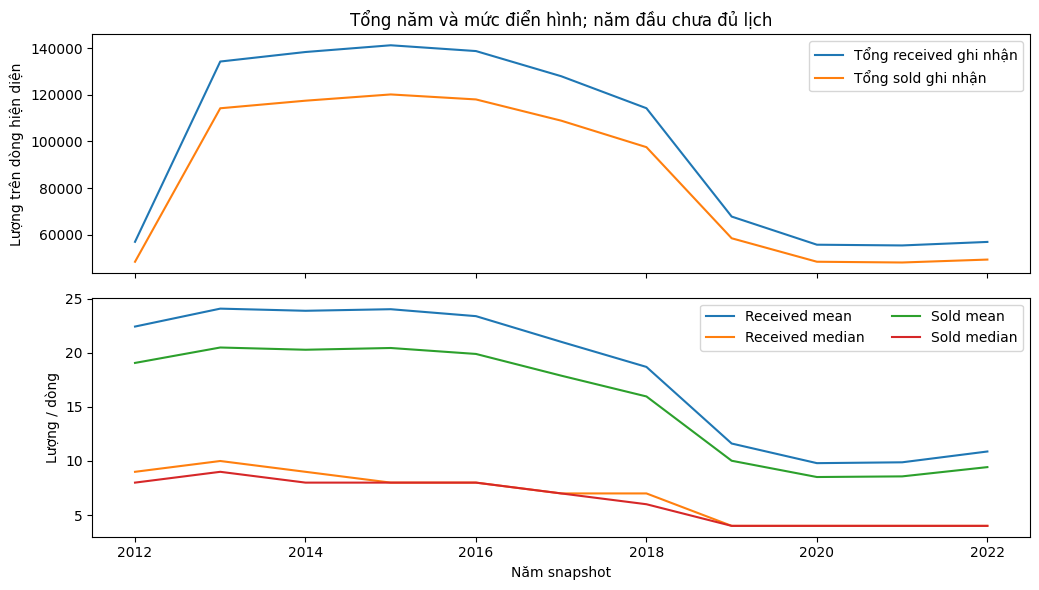

**Kết quả quan sát:** Hai phân bố lệch phải; tổng và mức điển hình khác nhau. **Bằng chứng:** Received mean/median 18,05/6,00, max 817; sold 15,42/6,00, max 670. Tổng ghi nhận 1.087.266/928.874; năm đầu 6 tháng. **Ý nghĩa:** Dòng lớn ảnh hưởng mạnh lên tổng; số dòng và cơ cấu năm khác nhau. **Giới hạn:** Tổng chỉ trên dòng hiện diện; chênh nhận–bán chưa là tích lũy tồn. **Câu hỏi tiếp:** Loại nhập/bán, điều chỉnh và kỳ ghi nhận có cùng phạm vi không?

In [31]:
quantity_stats53=describe53(d53,['units_received','units_sold'])
show53('Thống kê lượng nhận/bán trên dòng sản phẩm–tháng',quantity_stats53)
quantity_bins53=[-np.inf,-.5,0,1,5,10,25,50,100,250,500,np.inf]
quantity_dist53={c:distribution53(d53[c],quantity_bins53) for c in ['units_received','units_sold']}
show53('Khoảng số lượng — % / toàn bộ dòng, giữ khoảng rỗng',pd.concat([t.assign(Trường=c) for c,t in quantity_dist53.items()],ignore_index=True))
annual53=d53.groupby('year').agg(rows=('product_id','size'),products=('product_id','nunique'),months=('period','nunique'),
    received_total=('units_received','sum'),sold_total=('units_sold','sum'),received_mean=('units_received','mean'),received_median=('units_received','median'),sold_mean=('units_sold','mean'),sold_median=('units_sold','median'))
show53('Năm — tổng các giá trị trong những dòng inventory hiện diện',annual53.reset_index().rename(columns={'year':'Năm','rows':'Dòng','products':'Sản phẩm','months':'Tháng dữ liệu','received_total':'Tổng received ghi nhận','sold_total':'Tổng sold ghi nhận','received_mean':'Received mean/dòng','received_median':'Received median/dòng','sold_mean':'Sold mean/dòng','sold_median':'Sold median/dòng'}))
for c in ['units_received','units_sold']:show53('Năm dòng cao nhất theo '+c,examples53(d53,c))
fig,axes=plt.subplots(2,1,figsize=(10.5,6),sharex=True)
for c,label in [('received_total','Tổng received ghi nhận'),('sold_total','Tổng sold ghi nhận')]:axes[0].plot(annual53.index,annual53[c],label=label)
axes[0].set(ylabel='Lượng trên dòng hiện diện',title='Tổng năm và mức điển hình; năm đầu chưa đủ lịch');axes[0].legend()
for c,label in [('received_mean','Received mean'),('received_median','Received median'),('sold_mean','Sold mean'),('sold_median','Sold median')]:axes[1].plot(annual53.index,annual53[c],label=label)
axes[1].set(xlabel='Năm snapshot',ylabel='Lượng / dòng');axes[1].legend(ncol=2);plot_done(fig)
note53('Hai phân bố lệch phải; tổng và mức điển hình khác nhau.',
    f"Received mean/median {vn(d53.units_received.mean(),2)}/{vn(d53.units_received.median(),2)}, max {vn(d53.units_received.max())}; sold {vn(d53.units_sold.mean(),2)}/{vn(d53.units_sold.median(),2)}, max {vn(d53.units_sold.max())}. Tổng ghi nhận {vn(d53.units_received.sum())}/{vn(d53.units_sold.sum())}; năm đầu {int(annual53.months.iloc[0])} tháng.",
    'Dòng lớn ảnh hưởng mạnh lên tổng; số dòng và cơ cấu năm khác nhau.',
    'Tổng chỉ trên dòng hiện diện; chênh nhận–bán chưa là tích lũy tồn.',
    'Loại nhập/bán, điều chỉnh và kỳ ghi nhận có cùng phạm vi không?')

### NV05.3.3 – Mức tồn và lượng bán cùng dòng

**Mục tiêu:** xem mức tồn cao có đồng thời ghi lượng bán cao không. **Phương pháp:** Pearson trên cặp hữu hạn; Spearman bằng Pearson của hạng trung bình, xử lý đồng hạng. Không coi các dòng lặp mã là độc lập để suy nhân quả. Hexbin toàn bộ cặp dùng trục log10 ở hai biến dương, màu log mật độ đếm; không lấy mẫu hay bỏ đuôi.

Dùng P25/P75 stock_on_hand toàn mẫu ở NV05.2. Kiểm tra theo category, năm, nhóm số tháng quan sát và từng sản phẩm ≥24 tháng, có phân bố hệ số trong từng mã. Các hệ số gộp và trong nhóm có thành phần/quy mô khác nhau. Không suy tồn gây bán, tồn thấp là thiếu hàng, hoặc units_sold là bán đã đối soát orders.

**Phân bố hai biến trên cùng dòng**

Trường,Số quan sát,Thiếu,Min,Max,Mean / dòng,Median / dòng,Std mẫu,P25,P75,P90,P95,P99,Âm,Bằng 0,Dương
stock_on_hand,60247,0,"3,0000","2.673,0000","189,2985","62,0000","316,9761","15,0000","210,0000","532,0000","820,7000","1.525,0800",0,0,60247
units_sold,60247,0,"1,0000","670,0000","15,4178","6,0000","28,4044","2,0000","16,0000","39,0000","63,0000","135,0000",0,0,60247


**Tương quan mức tồn–lượng bán, không phải nhân quả**

Biến A,Biến B,Cặp hợp lệ,Pearson,Spearman,Ghi chú
stock_on_hand,units_sold,60247,"0,4065","0,5892",Mô tả cùng dòng


**Ngưỡng tồn thấp ≤15; giữa (15;210]; cao >210**

Nhóm mức tồn,Dòng,Sản phẩm,stock_on_hand mean / dòng,stock_on_hand median / dòng,units_sold mean / dòng,units_sold median / dòng
Thấp ≤ P25,15291,1105,"7,4410","7,0000","2,9980","2,0000"
Giữa (P25; P75],29897,836,"78,3982","63,0000","11,9553","7,0000"
Cao > P75,15059,241,"594,1306","444,0000","34,9029","19,0000"


**Tương quan theo category, năm và độ phủ**

Phạm vi,Nhóm,Sản phẩm,Biến A,Biến B,Cặp hợp lệ,Pearson,Spearman,Ghi chú
category,Casual,119,stock_on_hand,units_sold,3503,"0,4814","0,5916",Mô tả cùng dòng
category,GenZ,113,stock_on_hand,units_sold,4674,"0,4394","0,5635",Mô tả cùng dòng
category,Outdoor,502,stock_on_hand,units_sold,21050,"0,3526","0,5901",Mô tả cùng dòng
category,Streetwear,890,stock_on_hand,units_sold,31020,"0,4379","0,5877",Mô tả cùng dòng
year,2012,543,stock_on_hand,units_sold,2539,"0,7420","0,8145",Mô tả cùng dòng
year,2013,655,stock_on_hand,units_sold,5570,"0,6912","0,7813",Mô tả cùng dòng
year,2014,692,stock_on_hand,units_sold,5787,"0,5194","0,7090",Mô tả cùng dòng
year,2015,705,stock_on_hand,units_sold,5872,"0,6298","0,6485",Mô tả cùng dòng
year,2016,726,stock_on_hand,units_sold,5927,"0,6084","0,6492",Mô tả cùng dòng
year,2017,737,stock_on_hand,units_sold,6084,"0,5831","0,6299",Mô tả cùng dòng


**Phân bố hệ số trong từng mã ≥24 tháng, NaN nếu biến hằng**

Thống kê,Tháng quan sát,Cặp hợp lệ,Pearson,Spearman
count,"880,0000","880,0000","849,0000","849,0000"
mean,"59,5659","59,5659","-0,2990","-0,3848"
std,"29,7123","29,7123","0,2901","0,3213"
min,"24,0000","24,0000","-0,9745","-0,9199"
25%,"35,0000","35,0000","-0,5096","-0,6354"
50%,"50,0000","50,0000","-0,3356","-0,4326"
75%,"79,0000","79,0000","-0,1145","-0,1857"
max,"126,0000","126,0000","0,7306","0,8170"


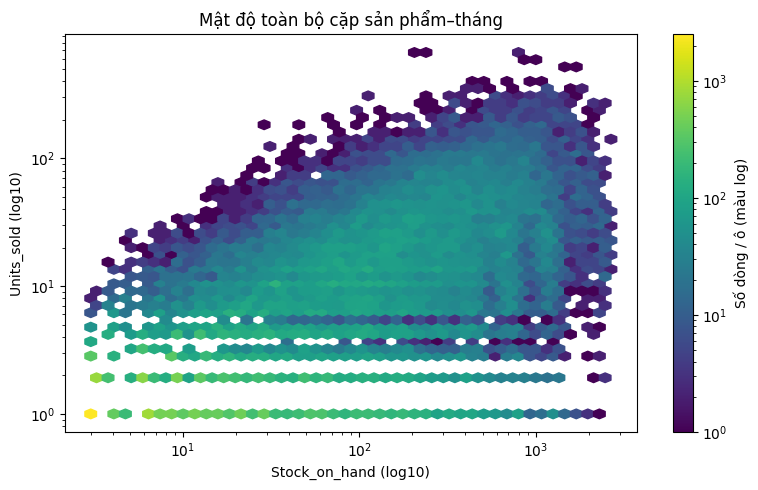

**Kết quả quan sát:** Tồn và lượng bán có liên hệ dương toàn mẫu; hệ số khác theo nhóm. **Bằng chứng:** Pearson 0,4065, Spearman 0,5892, 60.247 cặp; Pearson category 0,3526–0,4814; median trong mã ≥24 tháng -0,3356. **Ý nghĩa:** Quy mô sản phẩm và cơ cấu mẫu có thể ảnh hưởng quan hệ gộp. **Giới hạn:** Không kết luận nhân quả, tồn thấp là thiếu hàng, hoặc lượng bán đã khớp orders. **Câu hỏi tiếp:** Liên hệ còn giữ thế nào khi xác minh đơn vị, lịch và cùng phạm vi sản phẩm?

In [32]:
stock_sold_stats53=describe53(d53,['stock_on_hand','units_sold'])
stock_sold_corr53=corr53(d53,'stock_on_hand','units_sold')
show53('Phân bố hai biến trên cùng dòng',stock_sold_stats53)
show53('Tương quan mức tồn–lượng bán, không phải nhân quả',pd.DataFrame([stock_sold_corr53]))
stock_bands53=group53(d53,'Nhóm mức tồn',['stock_on_hand','units_sold'])
show53(f'Ngưỡng tồn thấp ≤{stock_low53:g}; giữa ({stock_low53:g};{stock_high53:g}]; cao >{stock_high53:g}',stock_bands53)
corr_groups53=[]
for key in ['category','year']:
    for v,g in d53.groupby(key):
        corr_groups53.append({'Phạm vi':key,'Nhóm':str(v),'Sản phẩm':g.product_id.nunique(),**corr53(g,'stock_on_hand','units_sold')})
d53['Độ phủ sản phẩm']=pd.cut(d53.product_id.map(months_per53),[0,23,59,np.inf],labels=['1–23 tháng','24–59 tháng','≥60 tháng'])
for v,g in d53.groupby('Độ phủ sản phẩm',observed=True):corr_groups53.append({'Phạm vi':'Tháng/SP','Nhóm':str(v),'Sản phẩm':g.product_id.nunique(),**corr53(g,'stock_on_hand','units_sold')})
correlation_groups53=pd.DataFrame(corr_groups53)
show53('Tương quan theo category, năm và độ phủ',correlation_groups53)
product_corr53=pd.DataFrame([{'product_id':pid,'Tháng quan sát':g.period.nunique(),**corr53(g,'stock_on_hand','units_sold')} for pid,g in d53.groupby('product_id') if months_per53.loc[pid]>=24])
show53('Phân bố hệ số trong từng mã ≥24 tháng, NaN nếu biến hằng',product_corr53[['Tháng quan sát','Cặp hợp lệ','Pearson','Spearman']].describe().reset_index().rename(columns={'index':'Thống kê'}))
fig,ax=plt.subplots(figsize=(8,5))
hb=ax.hexbin(d53.stock_on_hand,d53.units_sold,gridsize=45,xscale='log',yscale='log',bins='log',mincnt=1,cmap='viridis')
ax.set(xlabel='Stock_on_hand (log10)',ylabel='Units_sold (log10)',title='Mật độ toàn bộ cặp sản phẩm–tháng')
fig.colorbar(hb,ax=ax,label='Số dòng / ô (màu log)');plot_done(fig)
cat_corr53=correlation_groups53.loc[correlation_groups53['Phạm vi'].eq('category')]
note53('Tồn và lượng bán có liên hệ dương toàn mẫu; hệ số khác theo nhóm.',
    f"Pearson {vn(stock_sold_corr53['Pearson'],4)}, Spearman {vn(stock_sold_corr53['Spearman'],4)}, {vn(stock_sold_corr53['Cặp hợp lệ'])} cặp; Pearson category {vn(cat_corr53.Pearson.min(),4)}–{vn(cat_corr53.Pearson.max(),4)}; median trong mã ≥24 tháng {vn(product_corr53.Pearson.median(),4)}.",
    'Quy mô sản phẩm và cơ cấu mẫu có thể ảnh hưởng quan hệ gộp.',
    'Không kết luận nhân quả, tồn thấp là thiếu hàng, hoặc lượng bán đã khớp orders.',
    'Liên hệ còn giữ thế nào khi xác minh đơn vị, lịch và cùng phạm vi sản phẩm?')

### NV05.3.4 – Ba trường số lượng và chênh lệch số học

**Phương pháp:** tương quan từng cặp và giao khoảng phân vị lượng nhận × lượng bán, mô tả tồn trong mỗi tổ hợp. RecordedQuantityDifference = units_received − units_sold chỉ là **chênh lệch số học của hai trường số lượng ghi nhận trong cùng bản ghi**. Không gọi là biến động tồn thực tế, hàng tăng ròng, hàng dư, nhập thiếu hoặc cân đối kho đã xác minh; không khôi phục tồn đầu/cuối. “Nhận cao, bán thấp” dùng received >P75 và sold ≤P25, chỉ minh họa.

In [33]:
triple_corr53=pd.DataFrame([corr53(d53,a,b) for a,b in [('units_received','units_sold'),('units_received','stock_on_hand'),('units_sold','stock_on_hand')]])
show53('Tương quan ba trường ghi nhận',triple_corr53)
quantity_cross53=group53(d53,['Nhóm lượng nhận','Nhóm lượng bán'],['stock_on_hand','units_received','units_sold'])
show53('Khoảng lượng nhận × bán; không là cân đối kho',quantity_cross53)
diff_groups53=pd.Series(np.select([d53.RecordedQuantityDifference.lt(0),d53.RecordedQuantityDifference.eq(0)],['Received < sold','Received = sold'],default='Received > sold'),index=d53.index)
difference_summary53=group53(d53.assign(**{'Quan hệ số học':diff_groups53}),'Quan hệ số học',['RecordedQuantityDifference','stock_on_hand'])
show53('Chênh lệch số học cùng dòng',difference_summary53)
received_high_sold_low53=d53.units_received.gt(received_high53)&d53.units_sold.le(sold_low53)
show53('Tối đa 5 dòng nhận cao/bán thấp',examples53(d53.loc[received_high_sold_low53],'units_received'))
show53('Tối đa 5 dòng sold > received',examples53(d53.loc[d53.units_sold.gt(d53.units_received)],'units_sold'))
note53('Nhận và bán gần đồng biến tuyến tính.',
    f"Pearson {vn(triple_corr53.Pearson.iloc[0],6)}; received > / = / < sold: {vn(d53.RecordedQuantityDifference.gt(0).sum())}/{vn(d53.RecordedQuantityDifference.eq(0).sum())}/{vn(d53.RecordedQuantityDifference.lt(0).sum())}; nhận >{received_high53:g}, bán ≤{sold_low53:g}: {vn(received_high_sold_low53.sum())} dòng.",
    'Gợi ý cần hỏi cơ chế sinh hai trường.',
    'Tương quan không xác nhận luồng vật lý; tồn đầu, hoàn, chuyển kho và điều chỉnh chưa rõ.',
    'Hai trường có được tạo từ cùng nguồn hoặc công thức không?')

**Tương quan ba trường ghi nhận**

Biến A,Biến B,Cặp hợp lệ,Pearson,Spearman,Ghi chú
units_received,units_sold,60247,"0,9985","0,9994",Mô tả cùng dòng
units_received,stock_on_hand,60247,"0,4064","0,5891",Mô tả cùng dòng
units_sold,stock_on_hand,60247,"0,4065","0,5892",Mô tả cùng dòng


**Khoảng lượng nhận × bán; không là cân đối kho**

Nhóm lượng nhận,Nhóm lượng bán,Dòng,Sản phẩm,stock_on_hand mean / dòng,stock_on_hand median / dòng,units_received mean / dòng,units_received median / dòng,units_sold mean / dòng,units_sold median / dòng
Thấp ≤ P25,Thấp ≤ P25,18074,1552,"72,6514","14,0000","1,3682","1,0000","1,3682","1,0000"
Giữa (P25; P75],Giữa (P25; P75],27201,1352,"147,3303","55,0000","8,1391","7,0000","7,2328","6,0000"
Giữa (P25; P75],Cao > P75,334,245,"251,6587","137,0000","18,7695","19,0000","17,1198","17,0000"
Cao > P75,Giữa (P25; P75],190,148,"268,5474","130,0000","20,0000","20,0000","16,0000","16,0000"
Cao > P75,Cao > P75,14448,639,"411,7492","254,0000","57,5219","40,0000","48,3560","34,0000"


**Chênh lệch số học cùng dòng**

Quan hệ số học,Dòng,Sản phẩm,RecordedQuantityDifference mean / dòng,RecordedQuantityDifference median / dòng,stock_on_hand mean / dòng,stock_on_hand median / dòng
Received = sold,28987,1594,"0,0000","0,0000","84,4876","19,0000"
Received > sold,31260,1151,"5,0669","2,0000","286,4882","138,0000"


**Tối đa 5 dòng nhận cao/bán thấp**

product_id,product_name,snapshot_day,category,segment,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,sell_through_rate,stockout_flag,overstock_flag,reorder_flag


**Tối đa 5 dòng sold > received**

product_id,product_name,snapshot_day,category,segment,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,sell_through_rate,stockout_flag,overstock_flag,reorder_flag


**Kết quả quan sát:** Nhận và bán gần đồng biến tuyến tính. **Bằng chứng:** Pearson 0,998490; received > / = / < sold: 31.260/28.987/0; nhận >19, bán ≤2: 0 dòng. **Ý nghĩa:** Gợi ý cần hỏi cơ chế sinh hai trường. **Giới hạn:** Tương quan không xác nhận luồng vật lý; tồn đầu, hoàn, chuyển kho và điều chỉnh chưa rõ. **Câu hỏi tiếp:** Hai trường có được tạo từ cùng nguồn hoặc công thức không?

### NV05.3.5 – Số ngày stockout ghi nhận

**Mục tiêu:** khảo sát tần suất, lặp lại theo mã và những dòng có ngày cao. **Phương pháp:** phân bố đầy đủ từng giá trị ngày, thống kê/phân vị; số tháng dương của mỗi mã gồm cả 0 tháng; bảng năm/category có số dòng, dòng dương, tỷ trọng đúng mẫu số nhóm, mean/median, mã phân biệt.

Tổng stockout_days chỉ là **tổng ngày–sản phẩm ghi nhận**, không là ngày lịch doanh nghiệp hết hàng. Kiểm tra vượt ngày lịch tháng, âm/không nguyên. Ngày cao dùng ≥P99 toàn mẫu, giữ đồng hạng, không là ngưỡng chính sách. Không suy ngày chính xác xảy ra sự kiện.

**Thống kê stockout_days**

Trường,Số quan sát,Thiếu,Min,Max,Mean / dòng,Median / dòng,Std mẫu,P25,P75,P90,P95,P99,Âm,Bằng 0,Dương
stockout_days,60247,0,"0,0000","28,0000","1,1606","1,0000","1,6245","0,0000","2,0000","2,0000","2,0000","7,0000",0,19676,40571


**Toàn bộ miền và tần suất ngày**

stockout_days,Dòng,% / dòng inventory
"0,0000",19676,"32,6589"
"1,0000",19654,"32,6224"
"2,0000",19658,"32,6290"
"3,0000",237,"0,3934"
"4,0000",174,"0,2888"
"5,0000",124,"0,2058"
"6,0000",100,"0,1660"
"7,0000",85,"0,1411"
"8,0000",56,"0,0930"
"9,0000",61,"0,1012"


**Phân bố số tháng ngày dương trên mỗi mã, gồm cả 0**

Tháng có ngày dương,Sản phẩm,% / sản phẩm
0,37,"2,2783"
1,121,"7,4507"
2,53,"3,2635"
3,47,"2,8941"
4,46,"2,8325"
5,30,"1,8473"
6,38,"2,3399"
7,29,"1,7857"
8,31,"1,9089"
9,40,"2,4631"


... (4 outputs left out)

**Đặc điểm ngày cao ≥P99=7**

Nhóm ngày cao,Dòng,Sản phẩm,stockout_days mean / dòng,stockout_days median / dòng,stock_on_hand mean / dòng,stock_on_hand median / dòng,units_received mean / dòng,units_received median / dòng,units_sold mean / dòng,units_sold median / dòng,fill_rate mean / dòng,fill_rate median / dòng,days_of_supply mean / dòng,days_of_supply median / dòng,sell_through_rate mean / dòng,sell_through_rate median / dòng
<P99,59623,1624,"1,0331","1,0000","190,9509","63,0000","17,6161","6,0000","15,0572","6,0000","0,9656","0,9667","922,0359","246,7000","0,1473","0,1084"
≥P99,624,283,"13,3462","12,0000","31,4038","19,0000","59,2003","36,0000","49,8686","30,0000","0,5551","0,6000","18,4946","18,4000","0,6277","0,6203"


**Năm dòng stockout_days cao nhất**

product_id,product_name,snapshot_day,category,segment,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,sell_through_rate,stockout_flag,overstock_flag,reorder_flag
2193,VietMotion MA-07,2021-08-31 00:00:00,Casual,All-weather,"16,0000","59,0000","46,0000","28,0000","10,4000","0,0667","0,7419","1,0000","0,0000","0,0000"
660,SaigonFlex UC-25,2015-08-31 00:00:00,Streetwear,Everyday,"15,0000","78,0000","66,0000","28,0000","6,8000","0,0667","0,8148","1,0000","0,0000","0,0000"
763,HanoiStreet RP-51,2013-11-30 00:00:00,Outdoor,Activewear,"43,0000","214,0000","180,0000","28,0000","7,2000","0,0667","0,8072","1,0000","0,0000","0,0000"
764,HanoiStreet RP-52,2013-11-30 00:00:00,Outdoor,Activewear,"31,0000","202,0000","180,0000","28,0000","5,2000","0,0667","0,8531","1,0000","0,0000","0,0000"
907,HanoiStreet UE-16,2014-04-30 00:00:00,Streetwear,Performance,"16,0000","81,0000","68,0000","28,0000","7,1000","0,0667","0,8095","1,0000","0,0000","0,0000"


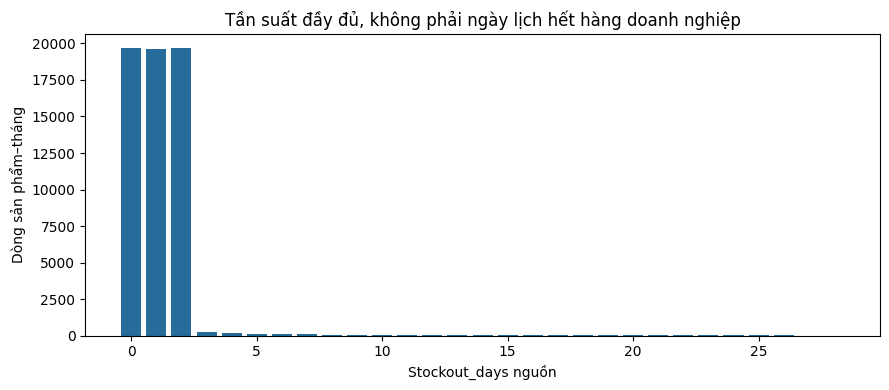

**Kết quả quan sát:** Ngày dương xuất hiện nhiều và có đuôi ngày cao. **Bằng chứng:** 0 ngày 19.676 (32,66%); >0 40.571 (67,34%); 1587 mã từng có ngày dương; tổng 69.925 ngày–sản phẩm; 3 mức phổ biến [0.0, 2.0, 1.0]; vượt lịch 0. **Ý nghĩa:** Chọn mã lặp tín hiệu cần kèm số tháng quan sát. **Giới hạn:** Nếu không vượt lịch, chỉ không phát hiện vi phạm ranh giới lịch; chưa xác nhận tiêu chí stockout. Mã quan sát dài có nhiều cơ hội đóng góp tổng. **Câu hỏi tiếp:** Ngày thiếu được tính theo kho và lịch hoạt động nào?

In [34]:
stockout_stats53=describe53(d53,['stockout_days'])
stockout_dist53=d53.stockout_days.value_counts().sort_index().rename_axis('stockout_days').reset_index(name='Dòng')
stockout_dist53['% / dòng inventory']=100*stockout_dist53['Dòng']/N53
show53('Thống kê stockout_days',stockout_stats53)
show53('Toàn bộ miền và tần suất ngày',stockout_dist53)
stockout_product53=d53.groupby('product_id').agg(months=('period','nunique'),positive_months=('Ngày stockout dương','sum'),total_product_days=('stockout_days','sum'),mean_days=('stockout_days','mean'),max_days=('stockout_days','max'))
stockout_product53['positive_pct']=100*stockout_product53.positive_months/stockout_product53.months
positive_month_dist53=stockout_product53.positive_months.value_counts().sort_index().rename_axis('Tháng có ngày dương').reset_index(name='Sản phẩm')
positive_month_dist53['% / sản phẩm']=100*positive_month_dist53['Sản phẩm']/len(stockout_product53)
show53('Phân bố số tháng ngày dương trên mỗi mã, gồm cả 0',positive_month_dist53)
show53('Mười mã tổng ngày–sản phẩm cao nhất; có độ phủ và tỷ trọng tháng dương',stockout_product53.sort_values(['total_product_days','product_id'],ascending=[False,True]).head(10).reset_index().merge(labels52,on='product_id',validate='one_to_one').rename(columns={'months':'Tháng quan sát','positive_months':'Tháng ngày dương','total_product_days':'Tổng ngày–sản phẩm ghi nhận','positive_pct':'% tháng dương / tháng quan sát','mean_days':'Mean ngày / dòng','max_days':'Max ngày'}))
stockout_groups53=[]
for key in ['year','category']:
    for value,g in d53.groupby(key):
        stockout_groups53.append({'Cấp nhóm':key,'Nhóm':str(value),'Dòng':len(g),'Dòng ngày dương':int(g['Ngày stockout dương'].sum()),'% dương / dòng nhóm':100*g['Ngày stockout dương'].mean(),'Mean ngày / dòng':g.stockout_days.mean(),'Median ngày / dòng':g.stockout_days.median(),'Sản phẩm':g.product_id.nunique()})
show53('Stockout_days theo năm/category; mẫu số đúng nhóm',pd.DataFrame(stockout_groups53))
calendar_violation53=d53.stockout_days.gt(d53.snapshot_day.dt.days_in_month)
high_days_threshold53=d53.stockout_days.quantile(.99)
high_days53=d53.stockout_days.ge(high_days_threshold53)
show53(f'Đặc điểm ngày cao ≥P99={high_days_threshold53:g}',group53(d53.assign(**{'Nhóm ngày cao':np.where(high_days53,'≥P99','<P99')}),'Nhóm ngày cao',['stockout_days','stock_on_hand','units_received','units_sold','fill_rate','days_of_supply','sell_through_rate']))
show53('Năm dòng stockout_days cao nhất',examples53(d53,'stockout_days'))
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(stockout_dist53.stockout_days,stockout_dist53['Dòng'],color='#256c9b')
ax.set(xlabel='Stockout_days nguồn',ylabel='Dòng sản phẩm–tháng',title='Tần suất đầy đủ, không phải ngày lịch hết hàng doanh nghiệp');plot_done(fig)
note53('Ngày dương xuất hiện nhiều và có đuôi ngày cao.',
    f"0 ngày {vn(d53.stockout_days.eq(0).sum())} ({vn(100*d53.stockout_days.eq(0).mean(),2)}%); >0 {vn(d53['Ngày stockout dương'].sum())} ({vn(100*d53['Ngày stockout dương'].mean(),2)}%); {int(stockout_product53.positive_months.gt(0).sum())} mã từng có ngày dương; tổng {vn(d53.stockout_days.sum())} ngày–sản phẩm; 3 mức phổ biến {stockout_dist53.nlargest(3,'Dòng').stockout_days.tolist()}; vượt lịch {int(calendar_violation53.sum())}.",
    'Chọn mã lặp tín hiệu cần kèm số tháng quan sát.',
    'Nếu không vượt lịch, chỉ không phát hiện vi phạm ranh giới lịch; chưa xác nhận tiêu chí stockout. Mã quan sát dài có nhiều cơ hội đóng góp tổng.',
    'Ngày thiếu được tính theo kho và lịch hoạt động nào?')

### NV05.3.6 – Cờ stockout và số ngày

**Phương pháp:** miền cờ thực tế; bảng chéo cờ × (stockout_days >0), tỷ trọng theo hàng, số mã từng tổ hợp và phạm vi của cờ1/ngày0, cờ0/ngày dương. Không mặc định hai trường phải trùng hoặc kết luận một trường sai. Tương đương toàn mẫu nếu có chỉ là quy luật thực nghiệm, chưa là định nghĩa được xác nhận.

In [35]:
def flag_distribution53(frame,col):
    counts=frame[col].value_counts(dropna=False).sort_index()
    return pd.DataFrame({'Trường':col,'Giá trị nguồn':counts.index,'Dòng':counts.values,'% / dòng':100*counts.values/len(frame)})
show53('Miền stockout_flag thực tế',flag_distribution53(d53,'stockout_flag'))
stockout_cross53=pd.crosstab(d53.stockout_flag,d53['Ngày stockout dương'],dropna=False).reindex(columns=[False,True],fill_value=0)
show53('Cờ stockout × ngày dương — số dòng',stockout_cross53.rename(columns={False:'Ngày =0',True:'Ngày >0'}).reset_index())
show53('Cờ stockout × ngày dương — % theo hàng',stockout_cross53.div(stockout_cross53.sum(axis=1),axis=0).mul(100).rename(columns={False:'% ngày =0',True:'% ngày >0'}).reset_index())
show53('Mã phân biệt từng tổ hợp; không cộng distinct giữa nhóm',group53(d53,['stockout_flag','Ngày stockout dương'],['stockout_days','stock_on_hand','units_sold']))
flag1_day0_53=d53.stockout_flag.eq(1)&d53.stockout_days.eq(0)
flag0_daypos53=d53.stockout_flag.eq(0)&d53.stockout_days.gt(0)
mismatch_scope53=pd.DataFrame([{'Tổ hợp':label,'Dòng':int(mask.sum()),'Sản phẩm':d53.loc[mask,'product_id'].nunique(),'Ngày đầu':str(d53.loc[mask,'snapshot_day'].min()),'Ngày cuối':str(d53.loc[mask,'snapshot_day'].max())} for label,mask in [('Cờ1, ngày0',flag1_day0_53),('Cờ0, ngày dương',flag0_daypos53)]])
show53('Phạm vi hai dạng không đồng nhất; NaT là không có dòng',mismatch_scope53)
note53('Quan hệ cờ–ngày được đếm trực tiếp.',
    f"Cờ1/ngày0={int(flag1_day0_53.sum())}; cờ0/ngày dương={int(flag0_daypos53.sum())}; bảng chéo cộng {vn(stockout_cross53.to_numpy().sum())} dòng.",
    'Giúp hỏi cơ chế tạo nhãn và mức độc lập của thông tin.',
    'Ngay cả khi không có khác biệt, vẫn chỉ là quy luật thực nghiệm, chưa xác minh trạng thái thiếu thực tế.',
    'Cờ có sinh trực tiếp từ ngày hay từ tín hiệu khác cùng nguồn?')

**Miền stockout_flag thực tế**

Trường,Giá trị nguồn,Dòng,% / dòng
stockout_flag,"0,0000",19676,"32,6589"
stockout_flag,"1,0000",40571,"67,3411"


**Cờ stockout × ngày dương — số dòng**

stockout_flag,Ngày =0,Ngày >0
"0,0000",19676,0
"1,0000",0,40571


**Cờ stockout × ngày dương — % theo hàng**

stockout_flag,% ngày =0,% ngày >0
"0,0000","100,0000","0,0000"
"1,0000","0,0000","100,0000"


**Mã phân biệt từng tổ hợp; không cộng distinct giữa nhóm**

stockout_flag,Ngày stockout dương,Dòng,Sản phẩm,stockout_days mean / dòng,stockout_days median / dòng,stock_on_hand mean / dòng,stock_on_hand median / dòng,units_sold mean / dòng,units_sold median / dòng
0.0,False,19676,1484,"0,0000","0,0000","196,6679","67,0000","15,2769","5,0000"
1.0,True,40571,1587,"1,7235","2,0000","185,7244","60,0000","15,4861","6,0000"


**Phạm vi hai dạng không đồng nhất; NaT là không có dòng**

Tổ hợp,Dòng,Sản phẩm,Ngày đầu,Ngày cuối
"Cờ1, ngày0",0,0,NaT,NaT
"Cờ0, ngày dương",0,0,NaT,NaT


**Kết quả quan sát:** Quan hệ cờ–ngày được đếm trực tiếp. **Bằng chứng:** Cờ1/ngày0=0; cờ0/ngày dương=0; bảng chéo cộng 60.247 dòng. **Ý nghĩa:** Giúp hỏi cơ chế tạo nhãn và mức độc lập của thông tin. **Giới hạn:** Ngay cả khi không có khác biệt, vẫn chỉ là quy luật thực nghiệm, chưa xác minh trạng thái thiếu thực tế. **Câu hỏi tiếp:** Cờ có sinh trực tiếp từ ngày hay từ tín hiệu khác cùng nguồn?

### NV05.3.7 – Fill_rate trên dòng

**Mục tiêu:** phân bố tỷ lệ nguồn và quan hệ với ngày/cờ. **Phương pháp:** thống kê đầy đủ; số bằng1/dưới1; các khoảng ≤0; (0;0,80]; (0,80;0,90]; (0,90;0,95]; (0,95;1]; >1 chỉ để minh họa. So năm/category/ngày dương/cờ bằng mean không trọng số và median trên dòng, không cộng tỷ lệ hoặc cân theo đơn chưa biết mẫu số.

Thử **giả thuyết công thức** 1−stockout_days/30 và 1−stockout_days/số ngày lịch tháng trên toàn bộ dòng; dung sai 0,00005 theo bốn chữ số thập phân tỷ lệ nguồn. Khớp số học chưa xác nhận công thức nghiệp vụ, SLA hoặc đơn hàng đúng hạn.

**Thống kê fill_rate nguồn**

Trường,Số quan sát,Thiếu,Min,Max,Mean / dòng,Median / dòng,Std mẫu,P25,P75,P90,P95,P99,Âm,Bằng 0,Dương
fill_rate,60247,0,"0,0667","1,0000","0,9613","0,9667","0,0542","0,9333","1,0000","1,0000","1,0000","1,0000",0,0,60247


**Khoảng fill; bằng1=19676, dưới1=40571**

Khoảng giá trị (đóng phải),Dòng,% / toàn bộ dòng
"(-inf, 0.0]",0,"0,0000"
"(0.0, 0.8]",724,"1,2017"
"(0.8, 0.9]",535,"0,8880"
"(0.9, 0.95]",19658,"32,6290"
"(0.95, 1.0]",39330,"65,2813"
"(1.0, inf]",0,"0,0000"


**Fill_rate mean/median theo năm/category/ngày/cờ, trên dòng**

year,Dòng,Sản phẩm,fill_rate mean / dòng,fill_rate median / dòng,Cấp nhóm,category,Ngày stockout dương,stockout_flag
2012,2539,543,"0,9538","0,9667",year,—,—,—
2013,5570,655,"0,9579","0,9667",year,—,—,—
2014,5787,692,"0,9599","0,9667",year,—,—,—
2015,5872,705,"0,9599","0,9667",year,—,—,—
2016,5927,726,"0,9604","0,9667",year,—,—,—
2017,6084,737,"0,9604","0,9667",year,—,—,—
2018,6106,758,"0,9627","0,9667",year,—,—,—
2019,5835,782,"0,9643","0,9667",year,—,—,—
2020,5686,827,"0,9656","0,9667",year,—,—,—
2021,5609,827,"0,9619","0,9667",year,—,—,—


**Liên hệ mô tả fill_rate**

Biến A,Biến B,Cặp hợp lệ,Pearson,Spearman,Ghi chú
fill_rate,stockout_days,60247,"-1,0000","-1,0000",Mô tả cùng dòng
fill_rate,stockout_flag,60247,"-0,4975","-0,8583",Mô tả cùng dòng
fill_rate,units_sold,60247,"-0,1199","-0,0389",Mô tả cùng dòng


**Giả thuyết công thức fill_rate — sai số toàn bộ dòng**

Giả thuyết công thức,Dòng hợp lệ,Dòng ngoài miền tính,MAE,Max sai số tuyệt đối,Dung sai,Dòng trong dung sai,% / dòng hợp lệ,Kết luận
fill_rate ≈ 1 − stockout_days/30,60247,0,"0,0000","0,0000","0,0001",60247,"100,0000",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ
fill_rate ≈ 1 − stockout_days/ngày lịch tháng,60247,0,"0,0009","0,0643","0,0001",33420,"55,4716",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ


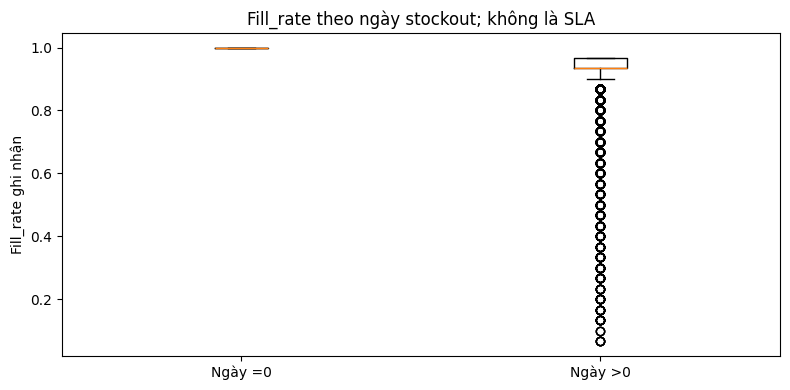

**Kết quả quan sát:** Fill_rate gần1 và liên hệ rất mạnh với số ngày. **Bằng chứng:** Mean/median 0,9613/0,9667, min/max 0,0667/1,0000; bằng1 19.676; Pearson ngày–fill -1,000000; ứng viên30 ngày khớp 100,00%. **Ý nghĩa:** Nếu dẫn xuất cùng nguồn, hai chỉ báo không phải bằng chứng độc lập. **Giới hạn:** Chưa xác minh công thức nghiệp vụ hoặc SLA; không cộng tỷ lệ. **Câu hỏi tiếp:** Cần tử/mẫu số, làm tròn, lịch và trạng thái nguồn nào?

In [36]:
fill_stats53=describe53(d53,['fill_rate'])
fill_bins53=[-np.inf,0,.8,.9,.95,1,np.inf]
fill_dist53=distribution53(d53.fill_rate,fill_bins53)
show53('Thống kê fill_rate nguồn',fill_stats53)
show53(f'Khoảng fill; bằng1={int(d53.fill_rate.eq(1).sum())}, dưới1={int(d53.fill_rate.lt(1).sum())}',fill_dist53)
fill_group53=pd.concat([group53(d53,k,['fill_rate']).assign(**{'Cấp nhóm':k}) for k in ['year','category','Ngày stockout dương','stockout_flag']],ignore_index=True).fillna('—')
show53('Fill_rate mean/median theo năm/category/ngày/cờ, trên dòng',fill_group53)
fill_corr53=pd.DataFrame([corr53(d53,'fill_rate',b) for b in ['stockout_days','stockout_flag','units_sold']])
show53('Liên hệ mô tả fill_rate',fill_corr53)
formula_rows53=[]
def hypothesis53(label,observed,predicted,tolerance):
    mask=np.isfinite(observed)&np.isfinite(predicted)
    errors=(observed[mask]-predicted[mask]).abs()
    row={'Giả thuyết công thức':label,'Dòng hợp lệ':int(mask.sum()),'Dòng ngoài miền tính':int((~mask).sum()),'MAE':errors.mean(),'Max sai số tuyệt đối':errors.max(),'Dung sai':tolerance,'Dòng trong dung sai':int(errors.le(tolerance+1e-12).sum()),'% / dòng hợp lệ':100*errors.le(tolerance+1e-12).mean(),'Kết luận':'Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ'}
    formula_rows53.append(row);return row
fill_formula53=[hypothesis53('fill_rate ≈ 1 − stockout_days/30',d53.fill_rate,1-d53.stockout_days/30,.00005),
 hypothesis53('fill_rate ≈ 1 − stockout_days/ngày lịch tháng',d53.fill_rate,1-d53.stockout_days/d53.snapshot_day.dt.days_in_month,.00005)]
show53('Giả thuyết công thức fill_rate — sai số toàn bộ dòng',pd.DataFrame(fill_formula53))
fig,ax=plt.subplots(figsize=(8,4))
ax.boxplot([g.fill_rate.to_numpy() for _,g in d53.groupby('Ngày stockout dương')],tick_labels=['Ngày =0','Ngày >0'],showfliers=True)
ax.set(ylabel='Fill_rate ghi nhận',title='Fill_rate theo ngày stockout; không là SLA');plot_done(fig)
note53('Fill_rate gần1 và liên hệ rất mạnh với số ngày.',
 f"Mean/median {vn(d53.fill_rate.mean(),4)}/{vn(d53.fill_rate.median(),4)}, min/max {vn(d53.fill_rate.min(),4)}/{vn(d53.fill_rate.max(),4)}; bằng1 {vn(d53.fill_rate.eq(1).sum())}; Pearson ngày–fill {vn(fill_corr53.Pearson.iloc[0],6)}; ứng viên30 ngày khớp {vn(fill_formula53[0]['% / dòng hợp lệ'],2)}%.",
 'Nếu dẫn xuất cùng nguồn, hai chỉ báo không phải bằng chứng độc lập.',
 'Chưa xác minh công thức nghiệp vụ hoặc SLA; không cộng tỷ lệ.',
 'Cần tử/mẫu số, làm tròn, lịch và trạng thái nguồn nào?')

### NV05.3.8 – Days_of_supply và cực trị

**Phương pháp:** thống kê/phân vị đến P99, khoảng minh họa ≤0, 30, 90, 180, 365, 730, 3.650, 10.000 và đuôi. Cực trị khảo sát là >P99 toàn mẫu, ghi số dòng/mã/tháng, tỷ trọng và phạm vi ngày; không xóa/winsorize. Histogram toàn miền dương với khoảng và trục log10, giữ giá trị nguồn.

Kiểm tra tương quan với tồn, sold, sell-through; thử **giả thuyết công thức** 30×stock/sold và ngày lịch×stock/sold, dung sai 0,05 ngày theo một chữ số thập phân nguồn, trên toàn bộ dòng. Khớp toán học chỉ gợi ý tạo trường; ngày lớn chưa chứng minh dư tồn, vì nhu cầu và chính sách chưa xác minh.

**Days_of_supply: mean/median và đuôi toàn mẫu**

Trường,Số quan sát,Thiếu,Min,Max,Mean / dòng,Median / dòng,Std mẫu,P25,P75,P90,P95,P99,Âm,Bằng 0,Dương
days_of_supply,60247,0,"5,2000","68.100,0000","912,6776","240,0000","2.587,6241","96,0000","683,1000","1.926,1200","3.660,0000","12.030,0000",0,0,60247


**Khoảng ngày minh họa**

Khoảng giá trị (đóng phải),Dòng,% / toàn bộ dòng
"(-inf, 0.0]",0,"0,0000"
"(0.0, 30.0]",2188,"3,6317"
"(30.0, 90.0]",12117,"20,1122"
"(90.0, 180.0]",11304,"18,7628"
"(180.0, 365.0]",11387,"18,9005"
"(365.0, 730.0]",9037,"14,9999"
"(730.0, 3650.0]",11192,"18,5769"
"(3650.0, 10000.0]",2240,"3,7180"
"(10000.0, inf]",782,"1,2980"


**Cực trị >P99=12030, vẫn giữ mọi dòng**

Dòng,% / toàn bộ dòng,Sản phẩm,Tháng phân biệt,Ngày đầu,Ngày cuối,Max nguồn
594,"0,9859",108,99,2014-05-31,2022-12-31,"68.100,0000"


... (2 outputs left out)

**Liên hệ mô tả days_of_supply**

Biến A,Biến B,Cặp hợp lệ,Pearson,Spearman,Ghi chú
days_of_supply,stock_on_hand,60247,"0,3701","0,6379",Mô tả cùng dòng
days_of_supply,units_sold,60247,"-0,1142","-0,1961",Mô tả cùng dòng
days_of_supply,sell_through_rate,60247,"-0,3150","-1,0000",Mô tả cùng dòng


**Giả thuyết công thức DOS — sai số toàn mẫu**

Giả thuyết công thức,Dòng hợp lệ,Dòng ngoài miền tính,MAE,Max sai số tuyệt đối,Dung sai,Dòng trong dung sai,% / dòng hợp lệ,Kết luận
days_of_supply ≈ 30 × stock_on_hand/units_sold,60247,0,"0,0093","0,0500","0,0500",60247,"100,0000",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ
days_of_supply ≈ ngày lịch × stock_on_hand/units_sold,60247,0,"22,4810","3.488,0000","0,0500",20248,"33,6083",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ


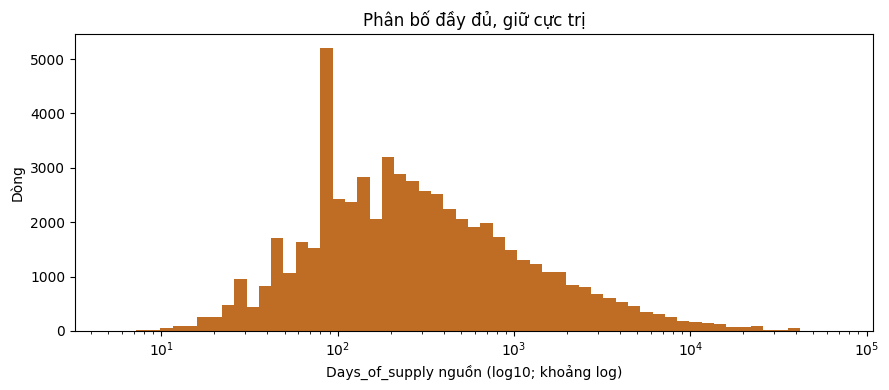

**Kết quả quan sát:** Đuôi phải dài nên cần cả median và phân vị. **Bằng chứng:** Mean 912,68, median 240,00, max 68.100,0; >P99 594 dòng/108 mã (0,99%); ứng viên30 ngày khớp 100,00%. **Ý nghĩa:** Đọc cực trị cùng mức tồn và lượng bán; mẫu số nhỏ có thể tạo tỷ số lớn. **Giới hạn:** Không xóa đuôi, chưa gọi ngày lớn là dư tồn hoặc xác nhận nhu cầu. **Câu hỏi tiếp:** Trường dùng bán kỳ nào, nhu cầu dự báo hay cửa sổ nào?

In [37]:
dos_stats53=describe53(d53,['days_of_supply'])
dos_dist53=distribution53(d53.days_of_supply,[-np.inf,0,30,90,180,365,730,3650,10000,np.inf])
dos_p99_53=d53.days_of_supply.quantile(.99)
dos_extreme_mask53=d53.days_of_supply.gt(dos_p99_53);dos_extreme53=d53.loc[dos_extreme_mask53]
show53('Days_of_supply: mean/median và đuôi toàn mẫu',dos_stats53)
show53('Khoảng ngày minh họa',dos_dist53)
show53(f'Cực trị >P99={dos_p99_53:g}, vẫn giữ mọi dòng',pd.DataFrame([{'Dòng':len(dos_extreme53),'% / toàn bộ dòng':100*len(dos_extreme53)/N53,'Sản phẩm':dos_extreme53.product_id.nunique(),'Tháng phân biệt':dos_extreme53.period.nunique(),'Ngày đầu':str(dos_extreme53.snapshot_day.min().date()),'Ngày cuối':str(dos_extreme53.snapshot_day.max().date()),'Max nguồn':d53.days_of_supply.max()}]))
show53('Mười dòng DOS cao nhất',examples53(d53,'days_of_supply',n=10))
dos_corr53=pd.DataFrame([corr53(d53,'days_of_supply',b) for b in ['stock_on_hand','units_sold','sell_through_rate']])
show53('Liên hệ mô tả days_of_supply',dos_corr53)
dos_formula53=[hypothesis53('days_of_supply ≈ 30 × stock_on_hand/units_sold',d53.days_of_supply,30*d53.stock_on_hand/d53.units_sold.replace(0,np.nan),.05),
 hypothesis53('days_of_supply ≈ ngày lịch × stock_on_hand/units_sold',d53.days_of_supply,d53.snapshot_day.dt.days_in_month*d53.stock_on_hand/d53.units_sold.replace(0,np.nan),.05)]
show53('Giả thuyết công thức DOS — sai số toàn mẫu',pd.DataFrame(dos_formula53))
fig,ax=plt.subplots(figsize=(9,4));assert d53.days_of_supply.gt(0).all()
ax.hist(d53.days_of_supply,bins=np.geomspace(d53.days_of_supply.min(),d53.days_of_supply.max(),60),color='#bf6c24')
ax.set_xscale('log');ax.set(xlabel='Days_of_supply nguồn (log10; khoảng log)',ylabel='Dòng',title='Phân bố đầy đủ, giữ cực trị');plot_done(fig)
note53('Đuôi phải dài nên cần cả median và phân vị.',
 f"Mean {vn(d53.days_of_supply.mean(),2)}, median {vn(d53.days_of_supply.median(),2)}, max {vn(d53.days_of_supply.max(),1)}; >P99 {vn(len(dos_extreme53))} dòng/{dos_extreme53.product_id.nunique()} mã ({vn(100*len(dos_extreme53)/N53,2)}%); ứng viên30 ngày khớp {vn(dos_formula53[0]['% / dòng hợp lệ'],2)}%.",
 'Đọc cực trị cùng mức tồn và lượng bán; mẫu số nhỏ có thể tạo tỷ số lớn.',
 'Không xóa đuôi, chưa gọi ngày lớn là dư tồn hoặc xác nhận nhu cầu.',
 'Trường dùng bán kỳ nào, nhu cầu dự báo hay cửa sổ nào?')

### NV05.3.9 – Sell_through_rate theo nhóm và thời gian

**Phương pháp:** thống kê đầy đủ, khoảng minh họa ≤0; 0,05; 0,10; 0,25; 0,50; 0,75; 1 và đuôi; mean/median category/segment/tháng. Xếp hạng 5 cao/5 thấp theo mean trong mã ≥24 tháng. Biểu đồ thời gian ghi rõ cơ cấu thay đổi; segment cao không tự là hiệu quả nhất.

Kiểm tra bốn liên hệ và **giả thuyết công thức** sold/received, sold/(stock+sold), sold/(stock+received), toàn bộ dòng, dung sai 0,00005. Không tự coi một tỷ số ứng viên là định nghĩa đã xác minh.

**Thống kê sell_through_rate**

Trường,Số quan sát,Thiếu,Min,Max,Mean / dòng,Median / dòng,Std mẫu,P25,P75,P90,P95,P99,Âm,Bằng 0,Dương
sell_through_rate,60247,0,"0,0004","0,8531","0,1523","0,1111","0,1393","0,0421","0,2381","0,3500","0,4348","0,6000",0,0,60247


**Khoảng sell-through minh họa**

Khoảng giá trị (đóng phải),Dòng,% / toàn bộ dòng
"(-inf, 0.0]",0,"0,0000"
"(0.0, 0.05]",17330,"28,7649"
"(0.05, 0.1]",11327,"18,8009"
"(0.1, 0.25]",21154,"35,1121"
"(0.25, 0.5]",8955,"14,8638"
"(0.5, 0.75]",1442,"2,3935"
"(0.75, 1.0]",39,"0,0647"
"(1.0, inf]",0,"0,0000"


**Sell-through theo category**

category,Dòng,Sản phẩm,sell_through_rate mean / dòng,sell_through_rate median / dòng
Casual,3503,119,"0,1684","0,1333"
GenZ,4674,113,"0,1680","0,1250"
Outdoor,21050,502,"0,1351","0,0909"
Streetwear,31020,890,"0,1598","0,1205"


... (6 outputs left out)

**Liên hệ mô tả sell-through**

Biến A,Biến B,Cặp hợp lệ,Pearson,Spearman,Ghi chú
sell_through_rate,units_sold,60247,"0,1446","0,1961",Mô tả cùng dòng
sell_through_rate,units_received,60247,"0,1429","0,1957",Mô tả cùng dòng
sell_through_rate,stock_on_hand,60247,"-0,3698","-0,6379",Mô tả cùng dòng
sell_through_rate,days_of_supply,60247,"-0,3150","-1,0000",Mô tả cùng dòng


**Giả thuyết công thức sell-through — toàn mẫu**

Giả thuyết công thức,Dòng hợp lệ,Dòng ngoài miền tính,MAE,Max sai số tuyệt đối,Dung sai,Dòng trong dung sai,% / dòng hợp lệ,Kết luận
sell_through_rate ≈ units_sold/units_received,60247,0,"0,7713","0,9996","0,0001",0,"0,0000",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ
sell_through_rate ≈ units_sold/(stock_on_hand+units_sold),60247,0,"0,0000","0,0001","0,0001",60247,"100,0000",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ
sell_through_rate ≈ units_sold/(stock_on_hand+units_received),60247,0,"0,0042","0,1286","0,0001",30716,"50,9835",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ


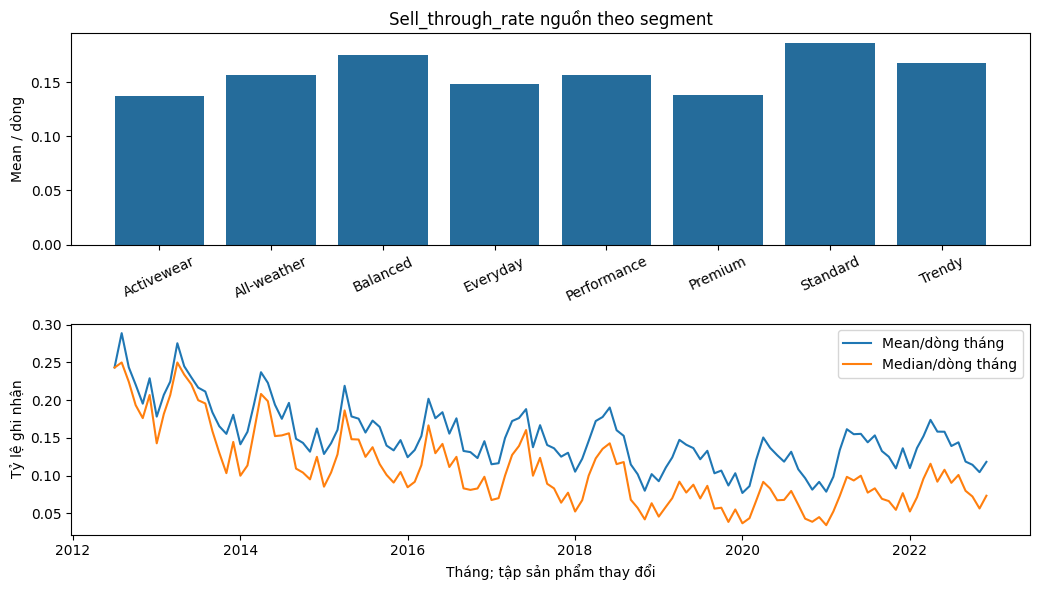

**Kết quả quan sát:** Sell-through khác nhau theo mẫu nhóm và kỳ. **Bằng chứng:** Mean/median 0,1523/0,1111, min/max 0,0004/0,8531; mean tháng 0,0771–0,2888; ứng viên sold/(stock+sold) khớp 100,00%. **Ý nghĩa:** Khác biệt giúp chọn câu hỏi về cơ cấu và cơ chế tạo trường. **Giới hạn:** Chưa là công thức chính thức, vòng quay hoặc hiệu quả segment. **Câu hỏi tiếp:** Cần mẫu số gốc và mục tiêu kinh doanh nào?

In [38]:
str_stats53=describe53(d53,['sell_through_rate'])
str_dist53=distribution53(d53.sell_through_rate,[-np.inf,0,.05,.1,.25,.5,.75,1,np.inf])
show53('Thống kê sell_through_rate',str_stats53);show53('Khoảng sell-through minh họa',str_dist53)
str_category53=group53(d53,'category',['sell_through_rate']);str_segment53=group53(d53,'segment',['sell_through_rate'])
show53('Sell-through theo category',str_category53);show53('Sell-through theo segment, chưa là hiệu quả',str_segment53)
str_product53=d53.groupby('product_id').agg(months=('period','nunique'),mean=('sell_through_rate','mean'),median=('sell_through_rate','median'),min=('sell_through_rate','min'),max=('sell_through_rate','max'))
str_eligible53=str_product53.loc[str_product53.months.ge(24)]
str_rank53=pd.concat([str_eligible53.sort_values(['mean','product_id'],ascending=[order,True]).head(5).assign(**{'Nhóm xếp hạng':'Mean thấp' if order else 'Mean cao'}) for order in [False,True]])
show53('Mã ≥24 tháng có mean cao/thấp',str_rank53.reset_index().merge(labels52,on='product_id',validate='many_to_one'))
str_month53=d53.groupby('period').agg(rows=('product_id','size'),products=('product_id','nunique'),mean=('sell_through_rate','mean'),median=('sell_through_rate','median'))
selected_str_months53=sorted(set(str_month53.head(2).index)|set(str_month53.tail(2).index)|{str_month53['mean'].idxmin(),str_month53['mean'].idxmax()})
show53('Sell-through tháng biên/cực trị; đủ từng tháng giữ trong bộ nhớ',str_month53.loc[selected_str_months53].reset_index().assign(period=lambda t:t.period.astype(str)).rename(columns={'period':'Tháng','rows':'Dòng','products':'Mã','mean':'Mean/dòng','median':'Median/dòng'}))
str_corr53=pd.DataFrame([corr53(d53,'sell_through_rate',b) for b in ['units_sold','units_received','stock_on_hand','days_of_supply']])
show53('Liên hệ mô tả sell-through',str_corr53)
str_formula53=[hypothesis53('sell_through_rate ≈ units_sold/units_received',d53.sell_through_rate,d53.units_sold/d53.units_received.replace(0,np.nan),.00005),
 hypothesis53('sell_through_rate ≈ units_sold/(stock_on_hand+units_sold)',d53.sell_through_rate,d53.units_sold/(d53.stock_on_hand+d53.units_sold).replace(0,np.nan),.00005),
 hypothesis53('sell_through_rate ≈ units_sold/(stock_on_hand+units_received)',d53.sell_through_rate,d53.units_sold/(d53.stock_on_hand+d53.units_received).replace(0,np.nan),.00005)]
show53('Giả thuyết công thức sell-through — toàn mẫu',pd.DataFrame(str_formula53))
fig,axes=plt.subplots(2,1,figsize=(10.5,6))
axes[0].bar(str_segment53.segment,str_segment53['sell_through_rate mean / dòng'],color='#256c9b')
axes[0].set(ylabel='Mean / dòng',title='Sell_through_rate nguồn theo segment');axes[0].tick_params(axis='x',labelrotation=25)
axes[1].plot(str_month53.index.to_timestamp(),str_month53['mean'],label='Mean/dòng tháng');axes[1].plot(str_month53.index.to_timestamp(),str_month53['median'],label='Median/dòng tháng')
axes[1].set(xlabel='Tháng; tập sản phẩm thay đổi',ylabel='Tỷ lệ ghi nhận');axes[1].legend();plot_done(fig)
note53('Sell-through khác nhau theo mẫu nhóm và kỳ.',
 f"Mean/median {vn(d53.sell_through_rate.mean(),4)}/{vn(d53.sell_through_rate.median(),4)}, min/max {vn(d53.sell_through_rate.min(),4)}/{vn(d53.sell_through_rate.max(),4)}; mean tháng {vn(str_month53['mean'].min(),4)}–{vn(str_month53['mean'].max(),4)}; ứng viên sold/(stock+sold) khớp {vn(str_formula53[1]['% / dòng hợp lệ'],2)}%.",
 'Khác biệt giúp chọn câu hỏi về cơ cấu và cơ chế tạo trường.',
 'Chưa là công thức chính thức, vòng quay hoặc hiệu quả segment.',
 'Cần mẫu số gốc và mục tiêu kinh doanh nào?')

### NV05.3.10 – Overstock_flag và reorder_flag

**Phương pháp:** miền/tần suất/tỷ trọng của cả hai cờ; overstock theo năm/category/segment với mẫu số nhóm, so stock, DOS, sold và sell-through; giao khoảng DOS có số dòng/mã. Nhãn1 chỉ là **bản ghi được gắn cờ overstock trong dữ liệu**, chưa là dư tồn thực tế.

Kiểm tra lại reorder trên toàn bộ dữ liệu. Nếu hằng, không cố chia lớp, không tương quan/ROC/AUC/mô hình, không tạo nhãn mới; cờ không phân biệt trạng thái quan sát không đồng nghĩa doanh nghiệp không cần bổ sung.

In [39]:
flags_dist53=pd.concat([flag_distribution53(d53,c) for c in ['overstock_flag','reorder_flag']],ignore_index=True)
show53('Miền overstock/reorder thực tế',flags_dist53)
overstock_group_rows53=[]
for key in ['year','category','segment']:
    for (value,flag),g in d53.groupby([key,'overstock_flag']):
        den=int(d53[key].eq(value).sum())
        overstock_group_rows53.append({'Cấp nhóm':key,'Nhóm':str(value),'overstock_flag':flag,'Dòng':len(g),'Sản phẩm':g.product_id.nunique(),'Mẫu số dòng nhóm':den,'% / dòng nhóm':100*len(g)/den})
overstock_groups53=pd.DataFrame(overstock_group_rows53)
show53('Overstock theo năm/category/segment, mẫu số đúng nhóm',overstock_groups53)
overstock_profile53=group53(d53,'overstock_flag',['stock_on_hand','days_of_supply','units_sold','sell_through_rate'])
show53('Đặc điểm từng nhãn overstock',overstock_profile53)
d53['Khoảng DOS']=pd.cut(d53.days_of_supply,[-np.inf,90,365,730,3650,np.inf])
overstock_dos53=group53(d53,['overstock_flag','Khoảng DOS'],['stock_on_hand','units_sold','sell_through_rate'])
show53('Overstock × khoảng DOS minh họa',overstock_dos53)
reorder_constant53=d53.reorder_flag.nunique(dropna=False)==1
reorder_values53=d53.reorder_flag.value_counts(dropna=False).to_dict()
note53('Overstock phân biệt các tập dòng; reorder được kiểm tra toàn miền.',
 f"Overstock1 {vn(d53.overstock_flag.eq(1).sum())}/{vn(N53)} dòng ({vn(100*d53.overstock_flag.eq(1).mean(),2)}%); reorder {reorder_values53}, hằng={reorder_constant53}.",
 'Mô tả được đặc điểm nhãn overstock; reorder hằng chỉ dùng mô tả chất lượng nguồn, không phân biệt trạng thái.',
 'Chưa xác nhận dư tồn thật hoặc nhu cầu bổ sung; không dùng cờ hằng cho tương quan/mô hình.',
 'Cần quy tắc tạo cờ, ngưỡng và hiệu lực thời gian nào?')

**Miền overstock/reorder thực tế**

Trường,Giá trị nguồn,Dòng,% / dòng
overstock_flag,"0,0000",14305,"23,7439"
overstock_flag,"1,0000",45942,"76,2561"
reorder_flag,"0,0000",60247,"100,0000"


**Overstock theo năm/category/segment, mẫu số đúng nhóm**

Cấp nhóm,Nhóm,overstock_flag,Dòng,Sản phẩm,Mẫu số dòng nhóm,% / dòng nhóm
year,2012,"0,0000",1094,448,2539,"43,0878"
year,2012,"1,0000",1445,392,2539,"56,9122"
year,2013,"0,0000",1889,494,5570,"33,9138"
year,2013,"1,0000",3681,517,5570,"66,0862"
year,2014,"0,0000",1503,390,5787,"25,9720"
year,2014,"1,0000",4284,577,5787,"74,0280"
year,2015,"0,0000",1297,332,5872,"22,0879"
year,2015,"1,0000",4575,611,5872,"77,9121"
year,2016,"0,0000",1313,313,5927,"22,1529"
year,2016,"1,0000",4614,639,5927,"77,8471"


**Đặc điểm từng nhãn overstock**

overstock_flag,Dòng,Sản phẩm,stock_on_hand mean / dòng,stock_on_hand median / dòng,days_of_supply mean / dòng,days_of_supply median / dòng,units_sold mean / dòng,units_sold median / dòng,sell_through_rate mean / dòng,sell_through_rate median / dòng
0.0,14305,1525,"31,0142","9,0000","61,6980","61,7000","17,2442","5,0000","0,3560","0,3273"
1.0,45942,1272,"238,5836","104,0000","1.177,6478","375,0000","14,8491","6,0000","0,0889","0,0741"


**Overstock × khoảng DOS minh họa**

overstock_flag,Khoảng DOS,Dòng,Sản phẩm,stock_on_hand mean / dòng,stock_on_hand median / dòng,units_sold mean / dòng,units_sold median / dòng,sell_through_rate mean / dòng,sell_through_rate median / dòng
0.0,"(-inf, 90.0]",14305,1525,"31,0142","9,0000","17,2442","5,0000","0,3560","0,3273"
1.0,"(90.0, 365.0]",22691,1271,"127,2374","49,0000","20,2696","8,0000","0,1456","0,1417"
1.0,"(365.0, 730.0]",9037,849,"234,0775","113,0000","13,7473","7,0000","0,0565","0,0556"
1.0,"(730.0, 3650.0]",11192,671,"373,3766","199,0000","8,0746","4,0000","0,0227","0,0220"
1.0,"(3650.0, inf]",3022,321,"588,9057","418,0000","2,5324","1,0000","0,0047","0,0048"


**Kết quả quan sát:** Overstock phân biệt các tập dòng; reorder được kiểm tra toàn miền. **Bằng chứng:** Overstock1 45.942/60.247 dòng (76,26%); reorder {0.0: 60247}, hằng=True. **Ý nghĩa:** Mô tả được đặc điểm nhãn overstock; reorder hằng chỉ dùng mô tả chất lượng nguồn, không phân biệt trạng thái. **Giới hạn:** Chưa xác nhận dư tồn thật hoặc nhu cầu bổ sung; không dùng cờ hằng cho tương quan/mô hình. **Câu hỏi tiếp:** Cần quy tắc tạo cờ, ngưỡng và hiệu lực thời gian nào?

### NV05.3.11 – Bốn tổ hợp tín hiệu đáng nghiên cứu

**Phương pháp:** (1) ngày dương và fill ≤0,90; (2) stock >P75 và sold ≤P25; (3) stock ≤P25 và sold >P75; (4) overstock1 và DOS >P99. Ngưỡng phân vị toàn mẫu và ngưỡng minh họa 0,90 không là chính sách; giữ đúng dấu và đồng hạng, không kết luận thiếu/dư thực tế.

Mỗi tổ hợp có dòng, tỷ trọng toàn mẫu, mã phân biệt, tháng và đặc điểm trung vị. Nhóm có thể giao nhau: không cộng distinct thành tổng; đối chứng bằng hợp/giao tập. Không tạo điểm rủi ro, cảnh báo hoặc quy tắc đặt hàng.

In [40]:
signal_masks53={
'Ngày dương và fill ≤0,90':d53['Ngày stockout dương']&d53.fill_rate.le(.9),
'Tồn >P75 và sold ≤P25':d53.stock_on_hand.gt(stock_high53)&d53.units_sold.le(sold_low53),
'Tồn ≤P25 và sold >P75':d53.stock_on_hand.le(stock_low53)&d53.units_sold.gt(sold_high53),
'Overstock1 và DOS >P99':d53.overstock_flag.eq(1)&d53.days_of_supply.gt(dos_p99_53)}
signal_rows53=[];signal_sets53={}
for label,mask in signal_masks53.items():
    g=d53.loc[mask];signal_sets53[label]=set(g.product_id)
    signal_rows53.append({'Tổ hợp mô tả':label,'Dòng':len(g),'% / toàn bộ dòng':100*len(g)/N53,'Sản phẩm phân biệt':g.product_id.nunique(),'Tháng có tín hiệu':g.period.nunique(),
     **{c+' median':g[c].median() for c in ['stock_on_hand','units_sold','stockout_days','fill_rate','days_of_supply','sell_through_rate']}})
signal_table53=pd.DataFrame(signal_rows53)
show53(f'Bốn tổ hợp; tồn P25/P75={stock_low53:g}/{stock_high53:g}; sold={sold_low53:g}/{sold_high53:g}; DOS P99={dos_p99_53:g}',signal_table53)
signal_overlap53=pd.DataFrame([{'Tổ hợp A':a,'Tổ hợp B':b,'Dòng chung':int((signal_masks53[a]&signal_masks53[b]).sum()),'Sản phẩm chung':len(signal_sets53[a]&signal_sets53[b])} for i,a in enumerate(signal_masks53) for b in list(signal_masks53)[i+1:]])
show53('Giao các tổ hợp; không cộng mã qua nhóm',signal_overlap53)
union_mask53=np.logical_or.reduce(list(signal_masks53.values()));union_ids53=set().union(*signal_sets53.values())
show53('Mười mã nhiều tháng có ngày dương; kèm độ phủ',stockout_product53.sort_values(['positive_months','positive_pct','product_id'],ascending=[False,False,True]).head(10).reset_index().merge(labels52,on='product_id',validate='one_to_one'))
note53('Bốn tổ hợp mô tả có quy mô mẫu rõ ràng.',
 '; '.join(f"{r['Tổ hợp mô tả']}: {vn(r['Dòng'])} dòng/{r['Sản phẩm phân biệt']} mã" for r in signal_rows53)+f"; hợp {vn(union_mask53.sum())} dòng/{len(union_ids53)} mã.",
 'Ưu tiên hỏi công thức, nguồn và bối cảnh các tín hiệu cùng xuất hiện.',
 'Chỉ báo có thể dẫn xuất nhau; tổ hợp trái vẻ bề ngoài chưa là lỗi hoặc hàng thiếu/dư.',
 'Tổ hợp nào còn đáng chú ý sau xác minh công thức và phạm vi kho?')

**Bốn tổ hợp; tồn P25/P75=15/210; sold=2/16; DOS P99=12030**

Tổ hợp mô tả,Dòng,% / toàn bộ dòng,Sản phẩm phân biệt,Tháng có tín hiệu,stock_on_hand median,units_sold median,stockout_days median,fill_rate median,days_of_supply median,sell_through_rate median
"Ngày dương và fill ≤0,90",1259,"2,0897",474,121,"14,0000","19,0000","6,0000","0,8000","21,0000","0,5882"
Tồn >P75 và sold ≤P25,1583,"2,6275",202,109,"396,0000","1,0000","1,0000","0,9667","9.360,0000","0,0032"
Tồn ≤P25 và sold >P75,164,"0,2722",118,78,"11,0000","20,0000","13,0000","0,5667","15,8000","0,6552"
Overstock1 và DOS >P99,594,"0,9859",108,99,"766,0000","1,0000","1,0000","0,9667","18.150,0000","0,0017"


**Giao các tổ hợp; không cộng mã qua nhóm**

Tổ hợp A,Tổ hợp B,Dòng chung,Sản phẩm chung
"Ngày dương và fill ≤0,90",Tồn >P75 và sold ≤P25,0,76
"Ngày dương và fill ≤0,90",Tồn ≤P25 và sold >P75,164,118
"Ngày dương và fill ≤0,90",Overstock1 và DOS >P99,0,40
Tồn >P75 và sold ≤P25,Tồn ≤P25 và sold >P75,0,14
Tồn >P75 và sold ≤P25,Overstock1 và DOS >P99,569,104
Tồn ≤P25 và sold >P75,Overstock1 và DOS >P99,0,9


**Mười mã nhiều tháng có ngày dương; kèm độ phủ**

product_id,months,positive_months,total_product_days,mean_days,max_days,positive_pct,product_name,category,segment
609,122,94,"136,0000","1,1148","2,0000","77,0492",SaigonFlex UC-74,Streetwear,Everyday
1182,126,93,"140,0000","1,1111","2,0000","73,8095",MekongFit UE-18,Streetwear,Performance
2054,126,91,"143,0000","1,1349","2,0000","72,2222",UrbanVN UE-14,Streetwear,Performance
2277,121,90,"140,0000","1,1570","5,0000","74,3802",VietMotion RS-10,Outdoor,Premium
2055,126,90,"137,0000","1,0873","2,0000","71,4286",UrbanVN UE-15,Streetwear,Performance
2379,126,90,"134,0000","1,0635","2,0000","71,4286",VietMotion UC-27,Streetwear,Everyday
604,126,90,"132,0000","1,0476","2,0000","71,4286",SaigonFlex UC-69,Streetwear,Everyday
1391,121,89,"142,0000","1,1736","9,0000","73,5537",VietMode RP-83,Outdoor,Activewear
1518,123,89,"164,0000","1,3333","24,0000","72,3577",VietMode RP-10,Outdoor,Activewear
2275,125,89,"143,0000","1,1440","7,0000","71,2000",VietMotion RS-08,Outdoor,Premium


**Kết quả quan sát:** Bốn tổ hợp mô tả có quy mô mẫu rõ ràng. **Bằng chứng:** Ngày dương và fill ≤0,90: 1.259 dòng/474 mã; Tồn >P75 và sold ≤P25: 1.583 dòng/202 mã; Tồn ≤P25 và sold >P75: 164 dòng/118 mã; Overstock1 và DOS >P99: 594 dòng/108 mã; hợp 2.867 dòng/604 mã. **Ý nghĩa:** Ưu tiên hỏi công thức, nguồn và bối cảnh các tín hiệu cùng xuất hiện. **Giới hạn:** Chỉ báo có thể dẫn xuất nhau; tổ hợp trái vẻ bề ngoài chưa là lỗi hoặc hàng thiếu/dư. **Câu hỏi tiếp:** Tổ hợp nào còn đáng chú ý sau xác minh công thức và phạm vi kho?

### NV05.3.12 – Độ nhạy theo độ phủ

**Phương pháp:** so toàn bộ, mã ≥24 tháng và panel đủ mọi tháng kế thừa NV05.2. Mỗi tập có dòng/mã/tháng, min/median/max tháng trên mỗi mã; mean/median của stockout_days, fill_rate, sell-through, DOS; kèm tỷ trọng dòng ngày dương và tỷ trọng mã từng có ngày dương. So thêm hai tập toàn bộ/≥24 theo năm.

Tách **mean trên dòng** và **mean của các mean sản phẩm**: mỗi mean sản phẩm lấy từ tháng quan sát của chính mã đó. Bảng theo mã là góc nhìn độ nhạy có mục tiêu rõ, không cân lại nguồn hoặc ước lượng toàn doanh nghiệp. Mean tỷ trọng ngày dương mỗi mã khác tỷ trọng mã từng có ngày dương.

Thống kê toàn dòng có **trọng số ngầm theo số lần sản phẩm xuất hiện**. Nhóm ≥24/panel là nhóm chọn lọc, không mặc định đại diện hoặc có độ phủ tương đương. Tháng vắng không được gán 0.

In [41]:
scope_ids53={'Toàn bộ':set(months_per53.index),'Sản phẩm ≥24 tháng':set(months_per53.index[months_per53.ge(24)]),'Panel đủ mọi tháng':set(panel_ids52)}
scope_masks53={label:d53.product_id.isin(ids) for label,ids in scope_ids53.items()}
sensitivity_rows53=[];product_sensitivity_rows53=[];scope_year_rows53=[]
sensitivity_fields53=['stockout_days','fill_rate','sell_through_rate','days_of_supply']
for label,mask in scope_masks53.items():
    g=d53.loc[mask];counts=g.groupby('product_id').period.nunique()
    row={'Phạm vi':label,'Dòng':len(g),'Sản phẩm':g.product_id.nunique(),'Tháng phân biệt':g.period.nunique(),'Min tháng/SP':counts.min(),'Median tháng/SP':counts.median(),'Max tháng/SP':counts.max(),'% ngày dương / dòng':100*g['Ngày stockout dương'].mean(),'% SP từng có ngày dương':100*g.groupby('product_id')['Ngày stockout dương'].any().mean()}
    for c in sensitivity_fields53:row.update({c+' mean / dòng':g[c].mean(),c+' median / dòng':g[c].median()})
    sensitivity_rows53.append(row)
    pm=g.groupby('product_id')[[*sensitivity_fields53,'Ngày stockout dương']].mean()
    product_sensitivity_rows53.append({'Phạm vi':label,'Sản phẩm (mẫu số)':len(pm),**{c+' mean của mean SP':pm[c].mean() for c in sensitivity_fields53},'% dương mean theo SP':100*pm['Ngày stockout dương'].mean()})
    if label!='Panel đủ mọi tháng':
        for y,h in g.groupby('year'):
            scope_year_rows53.append({'Phạm vi':label,'Năm':y,'Dòng':len(h),'Sản phẩm':h.product_id.nunique(),'Tháng':h.period.nunique(),'% ngày dương / dòng':100*h['Ngày stockout dương'].mean(),**{c+' mean / dòng':h[c].mean() for c in sensitivity_fields53},**{c+' median / dòng':h[c].median() for c in sensitivity_fields53}})
sensitivity53=pd.DataFrame(sensitivity_rows53);product_sensitivity53=pd.DataFrame(product_sensitivity_rows53);scope_year53=pd.DataFrame(scope_year_rows53)
show53('Độ nhạy theo tập — thống kê trên dòng thực có',sensitivity53)
show53('Góc nhìn mã — mean của mean sản phẩm, không nhầm mean dòng',product_sensitivity53)
show53('Theo năm trên hai tập; chưa coi độ phủ tương đương',scope_year53)
show53('Phân bố số tháng quan sát mỗi mã',months_per53.describe(percentiles=[.25,.5,.75,.9,.95,.99]).rename_axis('Thống kê').reset_index(name='Tháng/SP'))
note53('Các thống kê thay đổi theo việc giữ mã quan sát dài.',
 '; '.join(f"{r['Phạm vi']}: {vn(r['Dòng'])} dòng/{r['Sản phẩm']} mã; ngày dương {vn(r['% ngày dương / dòng'],2)}%; DOS median {vn(r['days_of_supply median / dòng'],2)}" for r in sensitivity_rows53),
 'Báo độ phủ cùng mọi nhận xét chỉ báo; mã quan sát dài đóng góp nhiều dòng.',
 'Panel nhỏ không đại diện; mean dòng và mean mã có mẫu số khác nhau, không lấp tháng vắng.',
 'Nhận xét nào ổn định trên phạm vi sản phẩm/kho đã xác nhận?')

**Độ nhạy theo tập — thống kê trên dòng thực có**

Phạm vi,Dòng,Sản phẩm,Tháng phân biệt,Min tháng/SP,Median tháng/SP,Max tháng/SP,% ngày dương / dòng,% SP từng có ngày dương,stockout_days mean / dòng,stockout_days median / dòng,fill_rate mean / dòng,fill_rate median / dòng,sell_through_rate mean / dòng,sell_through_rate median / dòng,days_of_supply mean / dòng,days_of_supply median / dòng
Toàn bộ,60247,1624,126,1,"27,0000",126,"67,3411","97,7217","1,1606","1,0000","0,9613","0,9667","0,1523","0,1111","912,6776","240,0000"
Sản phẩm ≥24 tháng,52418,880,126,24,"50,0000",126,"67,1697","100,0000","1,1431","1,0000","0,9619","0,9667","0,1379","0,0952","1.019,7315","285,0000"
Panel đủ mọi tháng,2772,22,126,126,"126,0000",126,"66,1977","100,0000","1,0022","1,0000","0,9666","0,9667","0,0826","0,0561","1.134,3320","505,0500"


**Góc nhìn mã — mean của mean sản phẩm, không nhầm mean dòng**

Phạm vi,Sản phẩm (mẫu số),stockout_days mean của mean SP,fill_rate mean của mean SP,sell_through_rate mean của mean SP,days_of_supply mean của mean SP,% dương mean theo SP
Toàn bộ,1624,"1,1993","0,9600","0,2009","529,9177","68,0428"
Sản phẩm ≥24 tháng,880,"1,1559","0,9615","0,1589","844,3691","67,2515"
Panel đủ mọi tháng,22,"1,0022","0,9666","0,0826","1.134,3320","66,1977"


**Theo năm trên hai tập; chưa coi độ phủ tương đương**

Phạm vi,Năm,Dòng,Sản phẩm,Tháng,% ngày dương / dòng,stockout_days mean / dòng,fill_rate mean / dòng,sell_through_rate mean / dòng,days_of_supply mean / dòng,stockout_days median / dòng,fill_rate median / dòng,sell_through_rate median / dòng,days_of_supply median / dòng
Toàn bộ,2012,2539,543,6,"68,1764","1,3860","0,9538","0,2368","161,1093","1,0000","0,9667","0,2387","95,7000"
Toàn bộ,2013,5570,655,12,"67,8456","1,2625","0,9579","0,2065","232,4444","1,0000","0,9667","0,1853","131,9000"
Toàn bộ,2014,5787,692,12,"67,6171","1,2027","0,9599","0,1768","458,8858","1,0000","0,9667","0,1429","180,0000"
Toàn bộ,2015,5872,705,12,"67,5068","1,2025","0,9599","0,1608","699,4970","1,0000","0,9667","0,1220","216,0000"
Toàn bộ,2016,5927,726,12,"67,8927","1,1874","0,9604","0,1538","721,2867","1,0000","0,9667","0,1090","245,2000"
Toàn bộ,2017,6084,737,12,"67,7844","1,1870","0,9604","0,1470","831,4532","1,0000","0,9667","0,0987","273,9000"
Toàn bộ,2018,6106,758,12,"66,4592","1,1194","0,9627","0,1377","899,5981","1,0000","0,9667","0,0882","310,0000"
Toàn bộ,2019,5835,782,12,"66,9237","1,0725","0,9643","0,1185","1.257,4331","1,0000","0,9667","0,0667","420,0000"
Toàn bộ,2020,5686,827,12,"66,7429","1,0329","0,9656","0,1132","1.409,5281","1,0000","0,9667","0,0619","454,3500"
Toàn bộ,2021,5609,827,12,"67,5343","1,1416","0,9619","0,1343","1.385,3894","1,0000","0,9667","0,0741","375,0000"


**Phân bố số tháng quan sát mỗi mã**

Thống kê,Tháng/SP
count,"1.624,0000"
mean,"37,0979"
std,"33,1846"
min,"1,0000"
25%,"12,0000"
50%,"27,0000"
75%,"53,0000"
90%,"89,0000"
95%,"110,0000"
99%,"126,0000"


**Kết quả quan sát:** Các thống kê thay đổi theo việc giữ mã quan sát dài. **Bằng chứng:** Toàn bộ: 60.247 dòng/1624 mã; ngày dương 67,34%; DOS median 240,00; Sản phẩm ≥24 tháng: 52.418 dòng/880 mã; ngày dương 67,17%; DOS median 285,00; Panel đủ mọi tháng: 2.772 dòng/22 mã; ngày dương 66,20%; DOS median 505,05 **Ý nghĩa:** Báo độ phủ cùng mọi nhận xét chỉ báo; mã quan sát dài đóng góp nhiều dòng. **Giới hạn:** Panel nhỏ không đại diện; mean dòng và mean mã có mẫu số khác nhau, không lấp tháng vắng. **Câu hỏi tiếp:** Nhận xét nào ổn định trên phạm vi sản phẩm/kho đã xác nhận?

### NV05.3.13 – Vấn đề cần xác minh

**Phương pháp:** tách A (vi phạm kỹ thuật đã xác minh), B (hiện tượng nghiệp vụ cần xác minh), C (giới hạn dữ liệu/thiếu định nghĩa). Mỗi mục có bằng chứng số, cấp quan sát/mẫu số, nguồn, ảnh hưởng, mức bằng chứng, giới hạn, thông tin cần bổ sung và bước tiếp. A00 ghi số vi phạm trong đúng các ràng buộc đã kiểm tra, không tạo lỗi nghiệp vụ giả.

Chuyển tiếp chỉ là danh sách đầu vào cần xác minh; không triển khai NV05.4.

In [42]:
technical_counts53={
'Khóa sản phẩm–ngày lặp':int(d53.duplicated(['product_id','snapshot_day']).sum()),
'Chỉ báo không hữu hạn':int((~np.isfinite(d53[fields53].to_numpy())).sum()),
'Ngày stockout âm':int(d53.stockout_days.lt(0).sum()),'Ngày stockout vượt lịch':int(calendar_violation53.sum()),
'Ngày stockout không nguyên':int(d53.stockout_days.mod(1).ne(0).sum()),
'Tỷ lệ ngoài [0;1]':int((d53[['fill_rate','sell_through_rate']].lt(0)|d53[['fill_rate','sell_through_rate']].gt(1)).sum().sum()),
'Cờ ngoài 0/1':int((~d53[['stockout_flag','overstock_flag','reorder_flag']].isin([0,1])).sum().sum())}
technical_violations53=sum(technical_counts53.values())
show53('Ràng buộc kỹ thuật khảo sát, chưa xác nhận nghiệp vụ',pd.DataFrame([{'Ràng buộc':k,'Vi phạm':v} for k,v in technical_counts53.items()]))
specs53=[
('A00','A','Ràng buộc kỹ thuật khảo sát',f'{technical_violations53} vi phạm/{N53} dòng; khóa, hữu hạn, lịch, miền tỷ lệ/cờ','Chưa phát hiện nếu tổng bằng0','Chỉ các ràng buộc đã kiểm tra','Schema và quy tắc chuẩn','Bổ sung ràng buộc khi có đặc tả'),
('C01','C','Công thức days_of_supply',f"Mean/median/max={d53.days_of_supply.mean():.4f}/{d53.days_of_supply.median():g}/{d53.days_of_supply.max():g}; ứng viên30 khớp {dos_formula53[0]['Dòng trong dung sai']}/{N53}",'Đuôi lớn có thể do tỷ số','Chưa xác nhận nhu cầu hoặc dư tồn','Công thức, cửa sổ, đơn vị','Xin đặc tả và đối chứng'),
('C02','C','Công thức fill_rate',f"Ứng viên 1−ngày/30 khớp {fill_formula53[0]['Dòng trong dung sai']}/{N53}",'Có thể phụ thuộc ngày nguồn','Chưa là SLA hoặc đúng hạn','Tử/mẫu số, lịch và làm tròn','Xác minh tạo trường, độc lập tín hiệu'),
('C03','C','Công thức sell_through_rate',f"Ứng viên sold/(stock+sold) khớp {str_formula53[1]['Dòng trong dung sai']}/{N53}",'Không tự xác nhận mẫu số','Chưa là vòng quay/hiệu quả','Công thức và phạm vi kỳ','Xin từ điển và tái lập theo đặc tả'),
('B04','B','Định nghĩa stockout/overstock',f"Cờ1/ngày0={int(flag1_day0_53.sum())}; cờ0/ngày+={int(flag0_daypos53.sum())}; overstock1={int(d53.overstock_flag.eq(1).sum())}",'Nhãn chưa là trạng thái xác nhận','Quan hệ thực nghiệm, chưa phán trường sai','Quy tắc, ngưỡng, phạm vi kho','Xác minh nhãn và sự kiện gốc'),
('C05','C','Reorder không phân biệt lớp' if reorder_constant53 else 'Miền reorder',str(reorder_values53),'Hằng không phân biệt trạng thái','Không suy không cần bổ sung','Chính sách, cơ chế và lịch tạo nhãn','Xác minh pipeline; không tạo nhãn'),
('B06','B','Units_sold chưa đồng nhất quantity',f"V04 lưu: {v04_metrics['equal_pairs']}/{v04_metrics['both_pairs']} cặp giao bằng; hash khớp; inventory sold={d53.units_sold.sum():g}",'Chưa được thay sold bằng quantity','Dẫn V04 cũ; không đối soát sâu mới','Đơn vị, trạng thái hủy/hoàn, kỳ','Đưa câu hỏi ngữ nghĩa sang NV05.4'),
('C07','C','Độ phủ khác nhau',f"{int(months_per53.min())}–{int(months_per53.max())} tháng/mã; ≥24: {len(scope_ids53['Sản phẩm ≥24 tháng'])}; đủ kỳ: {len(panel_ids52)}; vắng giữa kỳ: {int(coverage.internal_unobserved.sum())}",'Dòng có trọng số ngầm theo số lần xuất hiện','Panel chọn lọc; tháng vắng không là0','Cơ chế trích xuất, danh mục báo cáo','Xác minh phạm vi và độ phủ'),
('C08','C','Thời điểm kiểm kê snapshot',f"{N53} dòng/{d53.period.nunique()} tháng; stock min/median/max={d53.stock_on_hand.min():g}/{d53.stock_on_hand.median():g}/{d53.stock_on_hand.max():g}",'Không suy tồn bình quân/cân đối','Ngày nhãn chưa chứng minh kiểm kê','Mốc kiểm kê, cấp kho và điều chỉnh','Xin lịch snapshot và sổ biến động'),
('B09','B','Tổ hợp có vẻ trái ngược',f'4 tổ hợp; hợp {int(union_mask53.sum())} dòng/{len(union_ids53)} mã','Chọn câu hỏi, tránh cộng trùng mã','Chưa đủ cơ sở gọi lỗi/thiếu/dư','Chứng từ, công thức và bối cảnh','Xem xét mẫu cùng chủ dữ liệu')]
issues53=pd.DataFrame([{'Mã vấn đề':c,'Phân loại':kind,'Hiện tượng':phen,'Bằng chứng định lượng':evidence,'Cấp quan sát và mẫu số':f'Sản phẩm–tháng / {N53} dòng; V04 dùng cặp giao nêu riêng' if c!='C07' else f'Sản phẩm / {len(months_per53)} mã; {N53} dòng','Nguồn dữ liệu':'inventory.csv; báo cáo V04 đã lưu, hash khớp' if c=='B06' else 'inventory.csv và bảng NV05.1–NV05.3','Ảnh hưởng tới phân tích':impact,'Mức độ bằng chứng':'Kỹ thuật đã đối chứng' if kind=='A' else 'Số học quan sát; nghiệp vụ chưa xác nhận' if kind=='B' else 'Giới hạn dữ liệu/định nghĩa','Giới hạn kết luận':limit,'Thông tin cần bổ sung':extra,'Bước nghiên cứu tiếp theo':step} for c,kind,phen,evidence,impact,limit,extra,step in specs53])
show53('Vấn đề A/B/C; bằng chứng không thay định nghĩa',issues53)
note53('Giới hạn tài liệu được tách khỏi lỗi kỹ thuật.',
 f"{len(issues53)} mục; {technical_violations53} vi phạm trong ràng buộc khảo sát; {len(formula_rows53)} giả thuyết công thức đã thử toàn mẫu.",
 'Có danh mục tài liệu và sự kiện cần xin trước đánh giá vận hành.',
 'Không phát hiện vi phạm khảo sát không chứng minh toàn dữ liệu đúng nghiệp vụ.',
 'Ưu tiên công thức, đơn vị/kỳ, phạm vi kho và ngữ nghĩa quantity cho NV05.4 ra sao?')

**Ràng buộc kỹ thuật khảo sát, chưa xác nhận nghiệp vụ**

Ràng buộc,Vi phạm
Khóa sản phẩm–ngày lặp,0
Chỉ báo không hữu hạn,0
Ngày stockout âm,0
Ngày stockout vượt lịch,0
Ngày stockout không nguyên,0
Tỷ lệ ngoài [0;1],0
Cờ ngoài 0/1,0


**Vấn đề A/B/C; bằng chứng không thay định nghĩa**

Mã vấn đề,Phân loại,Hiện tượng,Bằng chứng định lượng,Cấp quan sát và mẫu số,Nguồn dữ liệu,Ảnh hưởng tới phân tích,Mức độ bằng chứng,Giới hạn kết luận,Thông tin cần bổ sung,Bước nghiên cứu tiếp theo
A00,A,Ràng buộc kỹ thuật khảo sát,"0 vi phạm/60247 dòng; khóa, hữu hạn, lịch, miền tỷ lệ/cờ",Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,Chưa phát hiện nếu tổng bằng0,Kỹ thuật đã đối chứng,Chỉ các ràng buộc đã kiểm tra,Schema và quy tắc chuẩn,Bổ sung ràng buộc khi có đặc tả
C01,C,Công thức days_of_supply,Mean/median/max=912.6776/240/68100; ứng viên30 khớp 60247/60247,Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,Đuôi lớn có thể do tỷ số,Giới hạn dữ liệu/định nghĩa,Chưa xác nhận nhu cầu hoặc dư tồn,"Công thức, cửa sổ, đơn vị",Xin đặc tả và đối chứng
C02,C,Công thức fill_rate,Ứng viên 1−ngày/30 khớp 60247/60247,Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,Có thể phụ thuộc ngày nguồn,Giới hạn dữ liệu/định nghĩa,Chưa là SLA hoặc đúng hạn,"Tử/mẫu số, lịch và làm tròn","Xác minh tạo trường, độc lập tín hiệu"
C03,C,Công thức sell_through_rate,Ứng viên sold/(stock+sold) khớp 60247/60247,Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,Không tự xác nhận mẫu số,Giới hạn dữ liệu/định nghĩa,Chưa là vòng quay/hiệu quả,Công thức và phạm vi kỳ,Xin từ điển và tái lập theo đặc tả
B04,B,Định nghĩa stockout/overstock,Cờ1/ngày0=0; cờ0/ngày+=0; overstock1=45942,Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,Nhãn chưa là trạng thái xác nhận,Số học quan sát; nghiệp vụ chưa xác nhận,"Quan hệ thực nghiệm, chưa phán trường sai","Quy tắc, ngưỡng, phạm vi kho",Xác minh nhãn và sự kiện gốc
C05,C,Reorder không phân biệt lớp,{0.0: 60247},Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,Hằng không phân biệt trạng thái,Giới hạn dữ liệu/định nghĩa,Không suy không cần bổ sung,"Chính sách, cơ chế và lịch tạo nhãn",Xác minh pipeline; không tạo nhãn
B06,B,Units_sold chưa đồng nhất quantity,V04 lưu: 1716/56615 cặp giao bằng; hash khớp; inventory sold=928874,Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,"inventory.csv; báo cáo V04 đã lưu, hash khớp",Chưa được thay sold bằng quantity,Số học quan sát; nghiệp vụ chưa xác nhận,Dẫn V04 cũ; không đối soát sâu mới,"Đơn vị, trạng thái hủy/hoàn, kỳ",Đưa câu hỏi ngữ nghĩa sang NV05.4
C07,C,Độ phủ khác nhau,1–126 tháng/mã; ≥24: 880; đủ kỳ: 22; vắng giữa kỳ: 25456,Sản phẩm / 1624 mã; 60247 dòng,inventory.csv và bảng NV05.1–NV05.3,Dòng có trọng số ngầm theo số lần xuất hiện,Giới hạn dữ liệu/định nghĩa,Panel chọn lọc; tháng vắng không là0,"Cơ chế trích xuất, danh mục báo cáo",Xác minh phạm vi và độ phủ
C08,C,Thời điểm kiểm kê snapshot,60247 dòng/126 tháng; stock min/median/max=3/62/2673,Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,Không suy tồn bình quân/cân đối,Giới hạn dữ liệu/định nghĩa,Ngày nhãn chưa chứng minh kiểm kê,"Mốc kiểm kê, cấp kho và điều chỉnh",Xin lịch snapshot và sổ biến động
B09,B,Tổ hợp có vẻ trái ngược,4 tổ hợp; hợp 2867 dòng/604 mã,Sản phẩm–tháng / 60247 dòng; V04 dùng cặp giao nêu riêng,inventory.csv và bảng NV05.1–NV05.3,"Chọn câu hỏi, tránh cộng trùng mã",Số học quan sát; nghiệp vụ chưa xác nhận,Chưa đủ cơ sở gọi lỗi/thiếu/dư,"Chứng từ, công thức và bối cảnh",Xem xét mẫu cùng chủ dữ liệu


**Kết quả quan sát:** Giới hạn tài liệu được tách khỏi lỗi kỹ thuật. **Bằng chứng:** 10 mục; 0 vi phạm trong ràng buộc khảo sát; 7 giả thuyết công thức đã thử toàn mẫu. **Ý nghĩa:** Có danh mục tài liệu và sự kiện cần xin trước đánh giá vận hành. **Giới hạn:** Không phát hiện vi phạm khảo sát không chứng minh toàn dữ liệu đúng nghiệp vụ. **Câu hỏi tiếp:** Ưu tiên công thức, đơn vị/kỳ, phạm vi kho và ngữ nghĩa quantity cho NV05.4 ra sao?

### Kiểm chứng NV05.3 – nguồn, phương pháp và bảo toàn

**Phương pháp:** đọc CSV độc lập bằng csv.DictReader/Decimal cho tổng, dấu, phân vị, tần suất, nhóm và điều kiện. Dùng statistics để đối chứng Pearson; Spearman đối chứng bằng hạng tự tính từ sắp xếp/đồng hạng. Đối chứng giả thuyết công thức toàn nguồn. Ví dụ độc lập trong bộ nhớ có kỳ vọng cố định, không trộn vào nguồn.

Báo riêng Đạt/Không đạt/Không áp dụng/Không thể chạy. Không gọi xác nhận nghiệp vụ thiếu tài liệu là đạt. Bảo toàn 60 ô và mọi tệp ngoài notebook bằng SHA-256. Nhật ký hai kernel mới trong metadata chỉ được ghi sau chạy thật.

In [43]:
fixture53=pd.DataFrame([
 {'pid':'A','month':'2020-01','stock':10,'received':8,'sold':2,'days':0,'flag':0,'fill':1.,'dos':150.,'reorder':0},
 {'pid':'B','month':'2020-01','stock':10,'received':2,'sold':8,'days':3,'flag':1,'fill':.9,'dos':37.5,'reorder':0},
 {'pid':'B','month':'2020-02','stock':2000,'received':1,'sold':1,'days':0,'flag':0,'fill':1.,'dos':60000.,'reorder':0},
 {'pid':'B','month':'2020-03','stock':20,'received':5,'sold':3,'days':1,'flag':1,'fill':.9667,'dos':200.,'reorder':0}])
fixture_tests53={
'Cùng tồn nhưng bán khác':fixture53.iloc[0].stock==fixture53.iloc[1].stock and fixture53.iloc[0].sold!=fixture53.iloc[1].sold,
'Nhận lớn/nhỏ hơn bán, chênh đúng':(fixture53.received-fixture53.sold).tolist()==[6,-6,0,2],
'Ngày0/dương, hai cờ và bảng chéo':pd.crosstab(fixture53.flag,fixture53.days.gt(0)).to_numpy().tolist()==[[2,0],[0,2]],
'Fill bằng1 và DOS cực trị giữ nguyên':fixture53['fill'].eq(1).sum()==2 and fixture53.dos.max()==60000,
'Cờ một giá trị không có hai lớp':fixture53.reorder.nunique()==1,
'Mã ít/nhiều tháng':fixture53.groupby('pid').month.nunique().to_dict()=={'A':1,'B':3},
'Mean dòng khác mean của mean mã':fixture53.sold.mean()==3.5 and fixture53.groupby('pid').sold.mean().mean()==3.,
'Spearman đúng đồng hạng':np.isclose(corr53(fixture53,'stock','sold')['Spearman'],-0.6324555320336759)}
for label,ok in fixture_tests53.items():check53('Ví dụ độc lập: '+label,ok,'Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ')
audit_rows53=list(csv_rows('inventory'))
audit_numbers53={c:[Decimal(r[c]) for r in audit_rows53] for c in fields53}
audit_pid_months53=defaultdict(set);audit_by_pid53=defaultdict(list);audit_groups53={k:defaultdict(list) for k in ['year','category','segment']}
for r in audit_rows53:
    audit_pid_months53[r['product_id']].add(r['snapshot_date'][:7]);audit_by_pid53[r['product_id']].append(r)
    for k in audit_groups53:audit_groups53[k][r[k]].append(r)
check53('01. Inventory vẫn 60.247 dòng, khớp CSV độc lập',N53==len(inventory)==len(audit_rows53)==60247)
check53('02. Khóa product_id + snapshot_date duy nhất',len({(r['product_id'],r['snapshot_date']) for r in audit_rows53})==N53 and not d53.duplicated(['product_id','snapshot_day']).any())
check53('03. Vẫn 1.624 mã, không thêm ví dụ giả',d53.product_id.nunique()==len(audit_pid_months53)==1624 and not set(fixture53.pid)&set(d53.product_id))
check53('04. Phân tích không đổi/mất dòng hoặc giá trị nguồn',d53[d53_before.columns].equals(d53_before) and inventory.equals(inventory_original) and d53._source_row.is_unique)
for c in ['units_received','units_sold']:
    check53('05/06. Tổng '+c+' khớp Decimal CSV và năm',Decimal(str(d53[c].sum()))==sum(audit_numbers53[c]) and annual53['received_total' if c=='units_received' else 'sold_total'].sum()==d53[c].sum())
complete_dists53=[*quantity_dist53.values(),dos_dist53,fill_dist53,str_dist53]
check53('07. Các khoảng đầy đủ bảo toàn dòng và tỷ trọng',all(t['Dòng'].sum()==N53 and np.isclose(t['% / toàn bộ dòng'].sum(),100) for t in complete_dists53) and stock_bands53['Dòng'].sum()==quantity_cross53['Dòng'].sum()==N53)
check53('08. Âm/0/dương hai lượng khớp nguồn độc lập',all([r['Âm'],r['Bằng 0'],r['Dương']]==[sum(v<0 for v in audit_numbers53[r['Trường']]),sum(v==0 for v in audit_numbers53[r['Trường']]),sum(v>0 for v in audit_numbers53[r['Trường']])] for r in quantity_stats53.to_dict('records')))
audit_product_means53={pid:{c:statistics.mean(float(r[c]) for r in rows) for c in sensitivity_fields53} for pid,rows in audit_by_pid53.items()}
audit_scope_rows53={label:[r for r in audit_rows53 if r['product_id'] in ids] for label,ids in scope_ids53.items()}
check53('09. Mean dòng và mean của mean sản phẩm đối chứng riêng',all(np.isclose(row[c+' mean / dòng'],statistics.mean(float(r[c]) for r in audit_scope_rows53[row['Phạm vi']])) for row in sensitivity_rows53 for c in sensitivity_fields53) and all(np.isclose(row[c+' mean của mean SP'],statistics.mean(audit_product_means53[pid][c] for pid in scope_ids53[row['Phạm vi']])) for row in product_sensitivity_rows53 for c in sensitivity_fields53))
def audit_ranks53(values):
    ordered=sorted(range(len(values)),key=values.__getitem__);ranks=[0.]*len(values);i=0
    while i<len(ordered):
        j=i+1
        while j<len(ordered) and values[ordered[j]]==values[ordered[i]]:j+=1
        for k in ordered[i:j]:ranks[k]=(i+1+j)/2
        i=j
    return ranks
all_corr53=pd.concat([pd.DataFrame([stock_sold_corr53]),triple_corr53,fill_corr53,dos_corr53,str_corr53],ignore_index=True)
corr_ok53=True
for row in all_corr53.to_dict('records'):
    a=[float(v) for v in audit_numbers53[row['Biến A']]];b=[float(v) for v in audit_numbers53[row['Biến B']]]
    corr_ok53 &= row['Cặp hợp lệ']==len(a)==len(b) and np.isclose(row['Pearson'],statistics.correlation(a,b)) and np.isclose(row['Spearman'],statistics.correlation(audit_ranks53(a),audit_ranks53(b)))
check53('10. Pearson/Spearman đúng cặp, khớp statistics và hạng độc lập',corr_ok53)
check53('11. Tỷ trọng stockout category dùng đúng mẫu số',all(row['Dòng']==len(audit_groups53['category'][row['Nhóm']]) and np.isclose(row['% dương / dòng nhóm'],100*sum(Decimal(r['stockout_days'])>0 for r in audit_groups53['category'][row['Nhóm']])/row['Dòng']) for row in stockout_groups53 if row['Cấp nhóm']=='category'))
check53('12. Chênh received−sold cùng dòng, không khôi phục tồn',np.array_equal(d53.RecordedQuantityDifference,[int(r['units_received'])-int(r['units_sold']) for r in audit_rows53]) and difference_summary53['Dòng'].sum()==N53,'Chỉ chênh lệch số học; không có tồn đầu/cuối suy từ chênh lệch')
check53('13. Phân bố ngày và tháng dương bảo toàn',stockout_dist53['Dòng'].sum()==N53 and stockout_product53.months.sum()==N53 and positive_month_dist53['Sản phẩm'].sum()==len(audit_pid_months53) and dict(zip(stockout_dist53.stockout_days,stockout_dist53['Dòng']))==dict(Counter(float(r['stockout_days']) for r in audit_rows53)))
calendar_expected53=[Decimal(r['stockout_days'])>calendar.monthrange(int(r['year']),int(r['month']))[1] for r in audit_rows53]
check53('14. Ngày stockout không vượt lịch, đối chứng calendar độc lập',calendar_violation53.tolist()==calendar_expected53 and not any(calendar_expected53),'Chỉ không phát hiện vi phạm ranh giới lịch trên dòng quan sát')
audit_cross53=Counter((int(r['stockout_flag']),Decimal(r['stockout_days'])>0) for r in audit_rows53)
check53('15. Bảng chéo cộng đúng, từng ô và tỷ trọng hàng đúng',stockout_cross53.to_numpy().sum()==N53 and all(stockout_cross53.loc[flag,pos]==count for (flag,pos),count in audit_cross53.items()) and np.allclose(stockout_cross53.div(stockout_cross53.sum(axis=1),axis=0).sum(axis=1),1))
check53('16. Hai dạng cờ–ngày không đồng nhất khớp CSV',flag1_day0_53.sum()==sum(int(r['stockout_flag'])==1 and Decimal(r['stockout_days'])==0 for r in audit_rows53) and flag0_daypos53.sum()==sum(int(r['stockout_flag'])==0 and Decimal(r['stockout_days'])>0 for r in audit_rows53),'Chỉ quy luật thực nghiệm, chưa xác nhận định nghĩa')
check53('17. Fill mean/median và số bằng1 đúng nguồn, không cộng tỷ lệ',np.isclose(d53.fill_rate.mean(),float(statistics.mean(audit_numbers53['fill_rate']))) and np.isclose(d53.fill_rate.median(),float(statistics.median(audit_numbers53['fill_rate']))) and d53.fill_rate.eq(1).sum()==sum(v==1 for v in audit_numbers53['fill_rate']))
check53('18. Sell-through giữ giá trị nguồn, công thức chỉ là giả thuyết',np.array_equal(d53.sell_through_rate,[float(v) for v in audit_numbers53['sell_through_rate']]) and all(r['Dòng hợp lệ']+r['Dòng ngoài miền tính']==N53 and 'chưa xác minh' in r['Kết luận'] for r in formula_rows53))
check53('19. DOS giữ đúng từng giá trị và cực đại nguồn',np.array_equal(d53.days_of_supply,[float(v) for v in audit_numbers53['days_of_supply']]) and Decimal(str(d53.days_of_supply.max()))==max(audit_numbers53['days_of_supply']))
all_stats53=pd.concat([quantity_stats53,stock_sold_stats53,stockout_stats53,fill_stats53,dos_stats53,str_stats53],ignore_index=True)
stats_ok53=True
for row in all_stats53.to_dict('records'):
    vals=audit_numbers53[row['Trường']];qs=statistics.quantiles(vals,n=100,method='inclusive')
    stats_ok53 &= row['Số quan sát']==len(vals) and row['Min']==float(min(vals)) and row['Max']==float(max(vals)) and all(np.isclose(row[f'P{p}'],float(qs[p-1])) for p in [25,75,90,95,99]) and np.isclose(row['Mean / dòng'],float(statistics.mean(vals))) and np.isclose(row['Median / dòng'],float(statistics.median(vals))) and np.isclose(row['Std mẫu'],float(statistics.stdev(vals)))
check53('20. Mọi phân vị/min/max/mean/median/std khớp Decimal/statistics',stats_ok53)
for c in ['overstock_flag','reorder_flag']:
    t=flag_distribution53(d53,c)
    check53('21/22. Miền '+c+' khớp Counter nguồn',dict(zip(t['Giá trị nguồn'],t['Dòng']))==dict(Counter(float(r[c]) for r in audit_rows53)) and t['Dòng'].sum()==N53)
check53('23. Reorder xác định hằng đúng, không đưa vào tương quan',reorder_constant53==(len(Counter(r['reorder_flag'] for r in audit_rows53))==1) and 'reorder_flag' not in set(all_corr53['Biến A'])|set(all_corr53['Biến B']))
audit_signal_masks53=[
 [Decimal(r['stockout_days'])>0 and Decimal(r['fill_rate'])<=Decimal('.9') for r in audit_rows53],
 [Decimal(r['stock_on_hand'])>Decimal(str(stock_high53)) and Decimal(r['units_sold'])<=Decimal(str(sold_low53)) for r in audit_rows53],
 [Decimal(r['stock_on_hand'])<=Decimal(str(stock_low53)) and Decimal(r['units_sold'])>Decimal(str(sold_high53)) for r in audit_rows53],
 [int(r['overstock_flag'])==1 and Decimal(r['days_of_supply'])>Decimal(str(dos_p99_53)) for r in audit_rows53]]
check53('24. Bốn tổ hợp đúng điều kiện từng dòng và số mã',all(mask.tolist()==expected and row['Dòng']==sum(expected) and row['Sản phẩm phân biệt']==len({r['product_id'] for r,ok in zip(audit_rows53,expected) if ok}) for mask,expected,row in zip(signal_masks53.values(),audit_signal_masks53,signal_rows53)))
check53('25. Hợp/giao distinct đúng tập mã, không cộng trùng',union_ids53==set(d53.loc[union_mask53,'product_id']) and all(row['Sản phẩm chung']==len(signal_sets53[row['Tổ hợp A']]&signal_sets53[row['Tổ hợp B']]) and row['Dòng chung']==int((signal_masks53[row['Tổ hợp A']]&signal_masks53[row['Tổ hợp B']]).sum()) for row in signal_overlap53.to_dict('records')))
audit_scope_ids53={'Toàn bộ':set(audit_pid_months53),'Sản phẩm ≥24 tháng':{pid for pid,ps in audit_pid_months53.items() if len(ps)>=24},'Panel đủ mọi tháng':{pid for pid,ps in audit_pid_months53.items() if ps==set(str(p) for p in months52)}}
check53('26. Tập mã/độ phủ nhạy đúng CSV và panel NV05.2',scope_ids53==audit_scope_ids53 and all(row['Dòng']==sum(len(audit_pid_months53[pid]) for pid in scope_ids53[row['Phạm vi']]) and row['Sản phẩm']==len(scope_ids53[row['Phạm vi']]) for row in sensitivity_rows53))
check53('27. Không điền0 tháng vắng hoặc mở rộng panel',months_per53.to_dict()=={pid:len(ps) for pid,ps in audit_pid_months53.items()} and len(d53)==len(d53_before) and d53._source_row.tolist()==d53_before._source_row.tolist())
check53('28. Bảng vấn đề đủ A/B/C, có bằng chứng và giới hạn',issues53['Mã vấn đề'].is_unique and issues53.notna().all().all() and set(issues53['Phân loại'])=={'A','B','C'} and all('chưa xác minh' in r['Kết luận'] for r in formula_rows53),'Chỉ kiểm tra cấu trúc/bảo lưu diễn giải; không xác nhận thực tế vận hành')
check53('29. Bằng chứng nhận xét truy về biến/bảng tính',stock_sold_corr53['Cặp hợp lệ']==N53 and signal_table53['Dòng'].sum()==sum(mask.sum() for mask in signal_masks53.values()) and len(specs53)==len(issues53),'Nhận xét nội suy trực tiếp từ kết quả, không hardcode số')
baseline53=load_notebook_for_audit(TARGET)['metadata']['nv053_baseline']
cells_sha53=hashlib.sha256(json.dumps(load_notebook_for_audit(TARGET)['cells'][:60],ensure_ascii=False,sort_keys=True,separators=(',',':')).encode('utf-8')).hexdigest()
check53('30. Toàn bộ 60 ô cũ gồm code/output/metadata giữ nguyên SHA-256',cells_sha53==baseline53['original_60_cells_sha256'])
check53('Mọi tệp ngoài notebook giữ nguyên SHA-256 đầu nhiệm vụ',protected_snapshot()==protected_before and protected_before==protected_snapshot())
check53('NV05.1/NV05.2 chạy lại có đúng 108 đạt, trạng thái cũ',verification_counts=={'passed':51,'failed':0,'not_applicable':4,'unable_to_run':0} and counts52=={'passed':57,'failed':0,'not_applicable':3,'unable_to_run':0})
check53('Mỗi mã có đúng tháng dương và tổng ngày–sản phẩm',all(row.positive_months==sum(Decimal(r['stockout_days'])>0 for r in audit_by_pid53[pid]) and row.total_product_days==sum(Decimal(r['stockout_days']) for r in audit_by_pid53[pid]) for pid,row in stockout_product53.iterrows()))
check53('Overstock theo nhóm đúng số dòng/mẫu số và %',all(row['Mẫu số dòng nhóm']==len(audit_groups53[row['Cấp nhóm']][row['Nhóm']]) and row['Dòng']==sum(float(r['overstock_flag'])==row['overstock_flag'] for r in audit_groups53[row['Cấp nhóm']][row['Nhóm']]) and np.isclose(row['% / dòng nhóm'],100*row['Dòng']/row['Mẫu số dòng nhóm']) for row in overstock_group_rows53))
formula_expected53=[
 lambda r:Decimal(1)-Decimal(r['stockout_days'])/30,
 lambda r:Decimal(1)-Decimal(r['stockout_days'])/calendar.monthrange(int(r['year']),int(r['month']))[1],
 lambda r:30*Decimal(r['stock_on_hand'])/Decimal(r['units_sold']),
 lambda r:calendar.monthrange(int(r['year']),int(r['month']))[1]*Decimal(r['stock_on_hand'])/Decimal(r['units_sold']),
 lambda r:Decimal(r['units_sold'])/Decimal(r['units_received']),
 lambda r:Decimal(r['units_sold'])/(Decimal(r['stock_on_hand'])+Decimal(r['units_sold'])),
 lambda r:Decimal(r['units_sold'])/(Decimal(r['stock_on_hand'])+Decimal(r['units_received']))]
formula_ok53=True
for field,result,fun in zip(['fill_rate','fill_rate','days_of_supply','days_of_supply','sell_through_rate','sell_through_rate','sell_through_rate'],formula_rows53,formula_expected53):
    errors=[abs(Decimal(r[field])-fun(r)) for r in audit_rows53]
    formula_ok53 &= sum(e<=Decimal(str(result['Dung sai']))+Decimal('1e-12') for e in errors)==result['Dòng trong dung sai'] and np.isclose(result['MAE'],float(statistics.mean(errors)),atol=1e-12) and np.isclose(result['Max sai số tuyệt đối'],float(max(errors)),atol=1e-12)
check53('Mọi giả thuyết công thức khớp sai số Decimal trên toàn nguồn',formula_ok53)
for label,detail in [
 ('Xác nhận công thức và quy tắc nghiệp vụ của tỷ lệ/cờ','Thiếu đặc tả chủ dữ liệu; khớp công thức chỉ là giả thuyết.'),
 ('Vòng quay kế toán, thiếu/dư thật và SLA toàn doanh nghiệp','Thiếu tồn bình quân, giá vốn, đơn vị/kho, sự kiện và mẫu số dịch vụ.'),
 ('Đối soát sâu orders/returns, tối ưu bổ sung, dự báo và nhãn reorder','Ngoài NV05.3; không chạy mô hình, đối soát sâu hoặc đề xuất lượng đặt.')]:
    checks53.append({'Kiểm chứng':label,'Trạng thái':'Không áp dụng','Bằng chứng/giới hạn':detail})
validation53=pd.DataFrame(checks53)
counts53={'passed':int(validation53['Trạng thái'].eq('Đạt').sum()),'failed':int(validation53['Trạng thái'].eq('Không đạt').sum()),'not_applicable':int(validation53['Trạng thái'].eq('Không áp dụng').sum()),'unable_to_run':0}
show53('Kiểm chứng NV05.3 — chỉ phép đã chạy mới ghi đạt',validation53)
show53('Kết quả riêng NV05.1–NV05.3',pd.DataFrame([{'Phần':name,'Đạt':c['passed'],'Không đạt':c['failed'],'Không áp dụng':c['not_applicable'],'Không thể chạy':c['unable_to_run']} for name,c in [('NV05.1',verification_counts),('NV05.2',counts52),('NV05.3',counts53)]]))
note(f"NV05.3: **{counts53['passed']} đạt, {counts53['failed']} không đạt, {counts53['not_applicable']} không áp dụng, {counts53['unable_to_run']} không thể chạy**. Thêm {table_count-table_start53} bảng/{figure_count-figure_start53} hình; toàn notebook {table_count} bảng/{figure_count} hình. Mỗi show là một bảng, mỗi hình nhiều trục là một biểu đồ.")
assert counts53['failed']==0,validation53.loc[validation53['Trạng thái'].eq('Không đạt'),'Kiểm chứng'].tolist()

**Kiểm chứng NV05.3 — chỉ phép đã chạy mới ghi đạt**

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
Ví dụ độc lập: Cùng tồn nhưng bán khác,Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
"Ví dụ độc lập: Nhận lớn/nhỏ hơn bán, chênh đúng",Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
"Ví dụ độc lập: Ngày0/dương, hai cờ và bảng chéo",Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
Ví dụ độc lập: Fill bằng1 và DOS cực trị giữ nguyên,Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
Ví dụ độc lập: Cờ một giá trị không có hai lớp,Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
Ví dụ độc lập: Mã ít/nhiều tháng,Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
Ví dụ độc lập: Mean dòng khác mean của mean mã,Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
Ví dụ độc lập: Spearman đúng đồng hạng,Đạt,Kỳ vọng cố định; 4 dòng giả chỉ trong bộ nhớ
"01. Inventory vẫn 60.247 dòng, khớp CSV độc lập",Đạt,Đối chứng đã thực thi trong bộ nhớ
02. Khóa product_id + snapshot_date duy nhất,Đạt,Đối chứng đã thực thi trong bộ nhớ


**Kết quả riêng NV05.1–NV05.3**

Phần,Đạt,Không đạt,Không áp dụng,Không thể chạy
NV05.1,51,0,4,0
NV05.2,57,0,3,0
NV05.3,43,0,3,0


NV05.3: **43 đạt, 0 không đạt, 3 không áp dụng, 0 không thể chạy**. Thêm 62 bảng/6 hình; toàn notebook 108 bảng/15 hình. Mỗi show là một bảng, mỗi hình nhiều trục là một biểu đồ.

### Kết luận NV05.3 – mô tả ghi nhận và giới hạn

Bốn đoạn sau dùng trực tiếp các bảng đã chạy. Danh sách chuyển sang NV05.4 chỉ là câu hỏi và đầu vào cần xác minh, chưa thực hiện nhiệm vụ đó.

In [44]:
note(f"""
Trên {vn(N53)} dòng sản phẩm–tháng/{d53.product_id.nunique()} mã, stock_on_hand và units_sold có Pearson {vn(stock_sold_corr53['Pearson'],4)}, Spearman {vn(stock_sold_corr53['Spearman'],4)}; Pearson category từ {vn(cat_corr53.Pearson.min(),4)} đến {vn(cat_corr53.Pearson.max(),4)}, median Pearson trong từng mã ≥24 tháng {vn(product_corr53.Pearson.median(),4)}. Bảng mức tồn cho thấy lượng bán ghi nhận khác nhau theo khoảng, nhưng tương quan gộp còn chịu cơ cấu mẫu và quy mô sản phẩm, không chứng minh tồn gây bán hoặc tồn thấp là thiếu hàng. Received/sold mean {vn(d53.units_received.mean(),2)}/{vn(d53.units_sold.mean(),2)}, median {vn(d53.units_received.median(),2)}/{vn(d53.units_sold.median(),2)}, max {vn(d53.units_received.max())}/{vn(d53.units_sold.max())}; Pearson hai lượng {vn(triple_corr53.Pearson.iloc[0],6)}. Tổng ghi nhận {vn(d53.units_received.sum())}/{vn(d53.units_sold.sum())} chỉ trên những dòng hiện diện; chênh nhận–bán không là biến động tồn và units_sold chưa đồng nhất quantity.

Stockout_days >0 có {vn(d53['Ngày stockout dương'].sum())} dòng ({vn(100*d53['Ngày stockout dương'].mean(),2)}%), {int(stockout_product53.positive_months.gt(0).sum())} mã; tổng {vn(d53.stockout_days.sum())} là ngày–sản phẩm, không là ngày lịch doanh nghiệp thiếu hàng. Cờ1/ngày0={int(flag1_day0_53.sum())}, cờ0/ngày dương={int(flag0_daypos53.sum())}; quan hệ trùng hoàn toàn nếu có vẫn chỉ là quy luật thực nghiệm. Không phát hiện vượt lịch ở {int(calendar_violation53.sum())} dòng, chưa xác nhận ngày sự kiện hoặc tiêu chí thiếu hàng. Fill_rate mean/median {vn(d53.fill_rate.mean(),4)}/{vn(d53.fill_rate.median(),4)}, {vn(d53.fill_rate.eq(1).sum())} dòng bằng1; ứng viên 1−ngày/30 khớp {vn(fill_formula53[0]['% / dòng hợp lệ'],2)}% trong dung sai. Chưa coi fill là SLA hay bằng chứng độc lập với số ngày khi chưa xác minh tạo trường.

Days_of_supply mean {vn(d53.days_of_supply.mean(),2)}, median {vn(d53.days_of_supply.median(),2)}, P99 {vn(dos_p99_53,2)}, max {vn(d53.days_of_supply.max(),1)}; {vn(len(dos_extreme53))} dòng >P99/{dos_extreme53.product_id.nunique()} mã còn nguyên. Sell_through_rate mean/median {vn(d53.sell_through_rate.mean(),4)}/{vn(d53.sell_through_rate.median(),4)}, min/max {vn(d53.sell_through_rate.min(),4)}/{vn(d53.sell_through_rate.max(),4)}; khác biệt category/segment/thời gian chỉ mô tả mẫu, chưa xếp hiệu quả hoặc xác nhận vòng quay. Các ứng viên công thức có sai số kiểm tra toàn nguồn, chưa thay đặc tả nghiệp vụ. Overstock1 có {vn(d53.overstock_flag.eq(1).sum())} dòng, phân biệt được các tập với đặc điểm tồn, DOS, sold và sell-through khác nhau như bảng; chưa là dư tồn thực tế. Reorder có miền {reorder_values53}, hằng={reorder_constant53}; chỉ dùng mô tả/kiểm tra nguồn, không phân biệt lớp hoặc dùng cho tương quan/mô hình phân loại, không suy không cần bổ sung.

Bốn tổ hợp nên hỏi tiếp là ngày dương/fill thấp, tồn cao/sold thấp, tồn thấp/sold cao và overstock1/DOS cực trị; hợp {vn(union_mask53.sum())} dòng/{len(union_ids53)} mã, không cộng distinct giữa nhóm giao nhau. So độ phủ gồm {len(scope_ids53['Toàn bộ'])} mã toàn bộ, {len(scope_ids53['Sản phẩm ≥24 tháng'])} mã ≥24 tháng và {len(panel_ids52)} mã đủ kỳ; bảng cho thấy thay đổi theo tập và cách lấy mean dòng/mean mã. Thống kê dòng có trọng số ngầm theo số lần xuất hiện; tháng vắng không bằng0, panel chọn lọc chưa đại diện. Thiếu công thức, đơn vị/phạm vi kho, thời điểm kiểm kê, tồn bình quân/giá vốn, sự kiện nhập–xuất–điều chỉnh và mẫu số dịch vụ nên chưa kết luận thiếu/dư thật, vòng quay, SLA hoặc lượng bổ sung tối ưu. Mười vấn đề A/B/C chuyển cho NV05.4 các câu hỏi về đặc tả chỉ báo/cờ, snapshot, độ phủ và ngữ nghĩa inventory–giao dịch; NV05.3 chỉ lập bằng chứng, không đối soát sâu hoặc đề xuất đặt hàng.
""")
findings53={
'rows':N53,'products':d53.product_id.nunique(),'received_total':d53.units_received.sum(),'sold_total':d53.units_sold.sum(),
'received_mean':d53.units_received.mean(),'sold_mean':d53.units_sold.mean(),'received_median':d53.units_received.median(),'sold_median':d53.units_sold.median(),
'stock_sold':stock_sold_corr53,'received_sold':triple_corr53.iloc[0].to_dict(),'stockout_positive':int(d53['Ngày stockout dương'].sum()),
'stockout_zero':int(d53.stockout_days.eq(0).sum()),'stockout_product_days':d53.stockout_days.sum(),'stockout_products':int(stockout_product53.positive_months.gt(0).sum()),
'stockout_flag1_day0':int(flag1_day0_53.sum()),'stockout_flag0_positive':int(flag0_daypos53.sum()),'calendar_violations':int(calendar_violation53.sum()),
'fill_mean':d53.fill_rate.mean(),'fill_median':d53.fill_rate.median(),'fill_one':int(d53.fill_rate.eq(1).sum()),'dos_mean':d53.days_of_supply.mean(),'dos_median':d53.days_of_supply.median(),'dos_max':d53.days_of_supply.max(),
'dos_p99':dos_p99_53,'dos_extreme_rows':len(dos_extreme53),'dos_extreme_products':dos_extreme53.product_id.nunique(),'str_mean':d53.sell_through_rate.mean(),'str_median':d53.sell_through_rate.median(),
'overstock_one':int(d53.overstock_flag.eq(1).sum()),'reorder_constant':bool(reorder_constant53),'signals':signal_rows53,'sensitivity':sensitivity_rows53,'product_sensitivity':product_sensitivity_rows53,
'formula_hypotheses':formula_rows53,'technical_violations':technical_violations53,'issues':len(issues53)}


Trên 60.247 dòng sản phẩm–tháng/1624 mã, stock_on_hand và units_sold có Pearson 0,4065, Spearman 0,5892; Pearson category từ 0,3526 đến 0,4814, median Pearson trong từng mã ≥24 tháng -0,3356. Bảng mức tồn cho thấy lượng bán ghi nhận khác nhau theo khoảng, nhưng tương quan gộp còn chịu cơ cấu mẫu và quy mô sản phẩm, không chứng minh tồn gây bán hoặc tồn thấp là thiếu hàng. Received/sold mean 18,05/15,42, median 6,00/6,00, max 817/670; Pearson hai lượng 0,998490. Tổng ghi nhận 1.087.266/928.874 chỉ trên những dòng hiện diện; chênh nhận–bán không là biến động tồn và units_sold chưa đồng nhất quantity.

Stockout_days >0 có 40.571 dòng (67,34%), 1587 mã; tổng 69.925 là ngày–sản phẩm, không là ngày lịch doanh nghiệp thiếu hàng. Cờ1/ngày0=0, cờ0/ngày dương=0; quan hệ trùng hoàn toàn nếu có vẫn chỉ là quy luật thực nghiệm. Không phát hiện vượt lịch ở 0 dòng, chưa xác nhận ngày sự kiện hoặc tiêu chí thiếu hàng. Fill_rate mean/median 0,9613/0,9667, 19.676 dòng bằng1; ứng viên 1−ngày/30 khớp 100,00% trong dung sai. Chưa coi fill là SLA hay bằng chứng độc lập với số ngày khi chưa xác minh tạo trường.

Days_of_supply mean 912,68, median 240,00, P99 12.030,00, max 68.100,0; 594 dòng >P99/108 mã còn nguyên. Sell_through_rate mean/median 0,1523/0,1111, min/max 0,0004/0,8531; khác biệt category/segment/thời gian chỉ mô tả mẫu, chưa xếp hiệu quả hoặc xác nhận vòng quay. Các ứng viên công thức có sai số kiểm tra toàn nguồn, chưa thay đặc tả nghiệp vụ. Overstock1 có 45.942 dòng, phân biệt được các tập với đặc điểm tồn, DOS, sold và sell-through khác nhau như bảng; chưa là dư tồn thực tế. Reorder có miền {0.0: 60247}, hằng=True; chỉ dùng mô tả/kiểm tra nguồn, không phân biệt lớp hoặc dùng cho tương quan/mô hình phân loại, không suy không cần bổ sung.

Bốn tổ hợp nên hỏi tiếp là ngày dương/fill thấp, tồn cao/sold thấp, tồn thấp/sold cao và overstock1/DOS cực trị; hợp 2.867 dòng/604 mã, không cộng distinct giữa nhóm giao nhau. So độ phủ gồm 1624 mã toàn bộ, 880 mã ≥24 tháng và 22 mã đủ kỳ; bảng cho thấy thay đổi theo tập và cách lấy mean dòng/mean mã. Thống kê dòng có trọng số ngầm theo số lần xuất hiện; tháng vắng không bằng0, panel chọn lọc chưa đại diện. Thiếu công thức, đơn vị/phạm vi kho, thời điểm kiểm kê, tồn bình quân/giá vốn, sự kiện nhập–xuất–điều chỉnh và mẫu số dịch vụ nên chưa kết luận thiếu/dư thật, vòng quay, SLA hoặc lượng bổ sung tối ưu. Mười vấn đề A/B/C chuyển cho NV05.4 các câu hỏi về đặc tả chỉ báo/cờ, snapshot, độ phủ và ngữ nghĩa inventory–giao dịch; NV05.3 chỉ lập bằng chứng, không đối soát sâu hoặc đề xuất đặt hàng.


### Kết thúc NV05.3 và nhật ký thực thi

Chạy Restart Kernel → Run All từ gốc repo hoặc thư mục notebook. Metadata nv053_run_all lưu hai lượt kernel mới, thư mục, thời lượng, số ô Python, kiểm chứng từng phần và so output giữa hai lượt. Chỉ output mới ở NV05.3 được lưu; 60 ô cũ giữ nguyên code/output/metadata/execution_count. Nhật ký NV05.1/NV05.2 cũ là lịch sử của các phần đó.

Metadata nv053_baseline và nv053_execution_validation chứa hash 60 ô, hash tệp trước nhiệm vụ và kết quả bảo toàn. Mọi tệp ngoài notebook gồm raw, NV01–NV04, V01–V09, reports và docs/gd1/profile_14_tables_20261029.md phải giữ nguyên. Không tạo tệp phụ, stage/commit/push. Chỉ bổ sung NV05.3.

## NV05.4 – Đối chiếu tồn kho với bán hàng, hoàn trả và tín hiệu bổ sung hàng
### NV05.4.1 – Phạm vi và đơn vị đối chiếu

**Mục tiêu:** đối chiếu các đại lượng ghi nhận, xác định khác biệt số học và giới hạn trước khi đánh giá bổ sung hàng. **Đơn vị phân tích:** sản phẩm–tháng; ngày đặt hàng, ngày trả và nhãn ngày snapshot là ba trục thời gian khác nhau. **Phương pháp:** giữ nguyên 91 ô cũ, chỉ nối NV05.4; tái dùng dữ liệu/bảng NV05.1–NV05.3, bổ sung order_status và returns từ CSV.

**Sản phẩm–tháng trong inventory không đồng nghĩa với toàn bộ sản phẩm–tháng phát sinh đơn đặt hàng.** Cặp vắng inventory không được gán units_sold=0. Không có bản ghi returns chưa chứng minh không có hàng khách trả được nhập kho. Order_status là trạng thái ghi nhận hiện tại trong tệp, không phải lịch sử trạng thái tại lúc mua/xuất kho.

Không coi dữ liệu không khớp là lỗi trước khi xác minh cùng đại lượng, cùng phạm vi thời gian và quy tắc nghiệp vụ. Các kết quả dưới đây chỉ là đối chiếu số học, không sửa số lượng, điền kỳ vắng hoặc loại cực trị. Không triển khai NV05.5, mô hình hay số lượng đặt hàng.

In [45]:
table_start54,figure_start54=table_count,figure_count
checks54=[]
def check54(label,condition,detail='Đối chứng đã thực thi từ dữ liệu/bộ ví dụ độc lập'):
    checks54.append({'Kiểm chứng':label,'Trạng thái':'Đạt' if bool(condition) else 'Không đạt','Bằng chứng/giới hạn':detail})
def show54(title,frame):show52(title,frame)
def note54(observation,evidence,meaning,limit,question):note52(observation,evidence,meaning,limit,question)
units54=pd.DataFrame([
 {'Nguồn':'inventory','Đơn vị gốc':'Một sản phẩm–tháng có thật','Trục ngày':'snapshot_date; kiểm tra cuối tháng','Đại lượng':'Stock tại snapshot; received/sold cùng dòng','Quy tắc JOIN':'Khóa product_id + tháng phải duy nhất; không cộng snapshot theo năm','Giới hạn':'Chưa xác nhận kiểm kê thực tế hoặc phạm vi nhận/bán'},
 {'Nguồn':'order_items + orders','Đơn vị gốc':'Dòng hàng; một đơn/sản phẩm có thể nhiều dòng','Trục ngày':'order_date từ orders','Đại lượng':'SUM(quantity) theo mã + tháng đặt, có nhãn phạm vi trạng thái','Quy tắc JOIN':'Items → orders nhiều–một; tổng hợp rồi JOIN inventory một–một','Giới hạn':'Trạng thái trong tệp không phải lịch sử; quantity chưa là xuất kho'},
 {'Nguồn':'returns','Đơn vị gốc':'Dòng trả; một đơn có thể nhiều dòng','Trục ngày':'return_date; có thể khác tháng đặt','Đại lượng':'SUM(return_quantity), SUM(refund_amount), số dòng/đơn mỗi mã–tháng trả','Quy tắc JOIN':'Tổng hợp riêng trước JOIN inventory; không JOIN trực tiếp với nhiều dòng items','Giới hạn':'Bản ghi trả chưa xác minh hàng đã thực nhập kho'},
 {'Nguồn':'products','Đơn vị gốc':'Mã sản phẩm duy nhất','Trục ngày':'Không có lịch sử hiệu lực nhãn','Đại lượng':'category/segment dùng mô tả nhóm','Quy tắc JOIN':'Tham chiếu nhiều–một theo mã','Giới hạn':'Không tự suy nhãn lịch sử theo thời gian'}])
show54('Đơn vị phân tích, trục thời gian và nguyên tắc JOIN',units54)
note54('Ba nguồn sự kiện không đồng nghĩa cùng luồng vật lý.','Bảng phân biệt 4 nguồn/vai trò, đối chiếu cuối cùng ở cấp sản phẩm–tháng.','Tránh JOIN nhiều–nhiều và xác minh vòng tròn.','Chưa xác nhận cùng đơn vị/thời điểm nghiệp vụ.','Cần định nghĩa bán, nhận, trả và snapshot nào?')

**Đơn vị phân tích, trục thời gian và nguyên tắc JOIN**

Nguồn,Đơn vị gốc,Trục ngày,Đại lượng,Quy tắc JOIN,Giới hạn
inventory,Một sản phẩm–tháng có thật,snapshot_date; kiểm tra cuối tháng,Stock tại snapshot; received/sold cùng dòng,Khóa product_id + tháng phải duy nhất; không cộng snapshot theo năm,Chưa xác nhận kiểm kê thực tế hoặc phạm vi nhận/bán
order_items + orders,Dòng hàng; một đơn/sản phẩm có thể nhiều dòng,order_date từ orders,"SUM(quantity) theo mã + tháng đặt, có nhãn phạm vi trạng thái",Items → orders nhiều–một; tổng hợp rồi JOIN inventory một–một,Trạng thái trong tệp không phải lịch sử; quantity chưa là xuất kho
returns,Dòng trả; một đơn có thể nhiều dòng,return_date; có thể khác tháng đặt,"SUM(return_quantity), SUM(refund_amount), số dòng/đơn mỗi mã–tháng trả",Tổng hợp riêng trước JOIN inventory; không JOIN trực tiếp với nhiều dòng items,Bản ghi trả chưa xác minh hàng đã thực nhập kho
products,Mã sản phẩm duy nhất,Không có lịch sử hiệu lực nhãn,category/segment dùng mô tả nhóm,Tham chiếu nhiều–một theo mã,Không tự suy nhãn lịch sử theo thời gian


**Kết quả quan sát:** Ba nguồn sự kiện không đồng nghĩa cùng luồng vật lý. **Bằng chứng:** Bảng phân biệt 4 nguồn/vai trò, đối chiếu cuối cùng ở cấp sản phẩm–tháng. **Ý nghĩa:** Tránh JOIN nhiều–nhiều và xác minh vòng tròn. **Giới hạn:** Chưa xác nhận cùng đơn vị/thời điểm nghiệp vụ. **Câu hỏi tiếp:** Cần định nghĩa bán, nhận, trả và snapshot nào?

### NV05.4.2 – Xây dựng các bảng trong bộ nhớ

**Mục tiêu:** chuẩn bị nguồn đối chiếu có bảo toàn tổng. **Đơn vị:** dòng items/returns gốc và các bảng sản phẩm–tháng sau tổng hợp. **Phương pháp:** khóa orders duy nhất, JOIN items→orders nhiều–một có số dòng gốc; không lọc trạng thái ngầm định, không khử các dòng order–product lặp. Giữ quantity nguyên chính xác. Refund_amount được đổi sang đơn vị nhỏ nhất ×100 khi nguồn có tối đa hai số thập phân; tổng hợp nguyên rồi hiển thị Decimal trong đơn vị tiền nguồn, không mặc định tiền tệ.

Inventory tái dùng d53; orders đọc thêm status, returns đọc nguồn mới, products dùng nhãn đã có. Mỗi bản ghi trả chỉ ghép orders nhiều–một để kiểm tra trục ngày; không ghép trực tiếp items với returns.

In [46]:
names54=['inventory','orders','order_items','returns','products']
paths54={name:ROOT/f'data/raw/{name}.csv' for name in names54}
source_hashes54={name:sha(path) for name,path in paths54.items()}
def read54(name,cols):
    return pd.read_csv(paths54[name],encoding='utf-8-sig',dtype='string',keep_default_na=False,skip_blank_lines=False,on_bad_lines='error',usecols=cols)
def integer54(series,label):
    values=series.map(Decimal)
    assert all(v.is_finite() and v==v.to_integral_value() for v in values),label
    return values.map(int).astype('int64')
def date54(series,label):
    parsed=pd.to_datetime(series,format='%Y-%m-%d',errors='raise')
    assert parsed.notna().all() and series.str.fullmatch(r'\d{4}-\d{2}-\d{2}').all(),label
    return parsed
inv54=d53[['product_id','product_name','category','segment','snapshot_day','period',*fields53]].copy(deep=True)
inv54['month']=inv54.period.astype(str)
for c in ['stock_on_hand','units_received','units_sold','stockout_days','stockout_flag','overstock_flag','reorder_flag']:
    assert inv54[c].mod(1).eq(0).all();inv54[c]=inv54[c].astype('int64')
ord54=read54('orders',['order_id','order_date','order_status'])
ord54['order_day']=date54(ord54.order_date,'order_date')
ord54['month']=ord54.order_day.dt.strftime('%Y-%m')
assert ord54.order_id.is_unique and ord54.order_id.str.len().gt(0).all() and ord54.order_status.str.len().gt(0).all()
items54=items.copy(deep=True);items54['quantity']=integer54(items54.quantity,'quantity');items54['_item_row']=np.arange(len(items54))
joined54=items54.merge(ord54[['order_id','order_date','order_day','order_status','month']],on='order_id',how='left',validate='many_to_one',indicator=True)
assert len(joined54)==len(items54) and joined54._merge.eq('both').all() and joined54._item_row.is_unique
joined54=joined54.drop(columns='_merge')
keys54=['product_id','month']
assert not inv54.duplicated(keys54).any() and products.product_id.is_unique
tx54=joined54.groupby(keys54,sort=True).agg(quantity=('quantity','sum'),item_rows=('quantity','size'),orders=('order_id','nunique')).reset_index()
statuses54=sorted(ord54.order_status.unique())
status_tx54={status:joined54.loc[joined54.order_status.eq(status)].groupby(keys54,sort=True).agg(quantity=('quantity','sum'),item_rows=('quantity','size'),orders=('order_id','nunique')).reset_index() for status in statuses54}
ret_raw54=read54('returns',['return_id','order_id','product_id','return_date','return_quantity','refund_amount'])
ret54=ret_raw54.copy(deep=True);ret54['return_day']=date54(ret54.return_date,'return_date')
ret54['month']=ret54.return_day.dt.strftime('%Y-%m');ret54['return_quantity']=integer54(ret54.return_quantity,'return_quantity')
ret54['refund_cents']=integer54(ret54.refund_amount.map(lambda x:str(Decimal(x)*100)),'refund_amount ×100')
assert ret54.return_id.is_unique and ret54.product_id.isin(products.product_id).all()
returns_pm54=ret54.groupby(keys54,sort=True).agg(return_quantity=('return_quantity','sum'),return_rows=('return_id','size'),return_orders=('order_id','nunique'),refund_cents=('refund_cents','sum')).reset_index()
returns_pm54['refund_amount']=returns_pm54.refund_cents.map(lambda x:Decimal(int(x))/100)
return_dates54=ret54.merge(ord54[['order_id','order_day']],on='order_id',how='left',validate='many_to_one',indicator=True)
assert len(return_dates54)==len(ret54) and return_dates54._merge.eq('both').all()
return_dates54['month_lag']=(return_dates54.return_day.dt.year-return_dates54.order_day.dt.year)*12+return_dates54.return_day.dt.month-return_dates54.order_day.dt.month
source_summary54=pd.DataFrame([
 {'Bảng trong bộ nhớ':'Inventory sản phẩm–tháng','Dòng':len(inv54),'Sản phẩm':inv54.product_id.nunique(),'Tháng':inv54.month.nunique(),'Tổng lượng ghi nhận':int(inv54.units_sold.sum()),'Diễn giải':'units_sold, chưa thay bằng quantity'},
 {'Bảng trong bộ nhớ':'Orders','Dòng':len(ord54),'Sản phẩm':pd.NA,'Tháng':ord54.month.nunique(),'Tổng lượng ghi nhận':pd.NA,'Diễn giải':f'{len(statuses54)} trạng thái ghi nhận'},
 {'Bảng trong bộ nhớ':'Items JOIN orders','Dòng':len(joined54),'Sản phẩm':joined54.product_id.nunique(),'Tháng':joined54.month.nunique(),'Tổng lượng ghi nhận':int(joined54.quantity.sum()),'Diễn giải':'Không lọc trạng thái, không khử dòng lặp'},
 {'Bảng trong bộ nhớ':'Quantity sản phẩm–tháng đặt','Dòng':len(tx54),'Sản phẩm':tx54.product_id.nunique(),'Tháng':tx54.month.nunique(),'Tổng lượng ghi nhận':int(tx54.quantity.sum()),'Diễn giải':'Tổng quantity trên tất cả trạng thái'},
 {'Bảng trong bộ nhớ':'Returns dòng nguồn','Dòng':len(ret54),'Sản phẩm':ret54.product_id.nunique(),'Tháng':ret54.month.nunique(),'Tổng lượng ghi nhận':int(ret54.return_quantity.sum()),'Diễn giải':f"Tổng refund_amount={Decimal(int(ret54.refund_cents.sum()))/100} đơn vị tiền nguồn"},
 {'Bảng trong bộ nhớ':'Returns sản phẩm–tháng trả','Dòng':len(returns_pm54),'Sản phẩm':returns_pm54.product_id.nunique(),'Tháng':returns_pm54.month.nunique(),'Tổng lượng ghi nhận':int(returns_pm54.return_quantity.sum()),'Diễn giải':'Số đơn phân biệt trong từng cặp, không cộng để suy đơn toàn kỳ'}])
show54('Nguồn và tổng hợp trong bộ nhớ — không xuất tệp phụ',source_summary54)
note54('Các JOIN bắt buộc không nhân dòng.',f'{vn(len(items54))} items → {vn(len(joined54))} dòng; {vn(len(ret54))} returns → {vn(len(return_dates54))} dòng kiểm tra ngày; quantity tổng {vn(tx54.quantity.sum())}.','Có các bảng một dòng mỗi mã–tháng cho đối chiếu.','Tổng số ghi nhận chưa xác nhận luồng xuất/nhập kho.','Phạm vi trạng thái và mốc kỳ nào khớp định nghĩa nguồn kho?')

**Nguồn và tổng hợp trong bộ nhớ — không xuất tệp phụ**

Bảng trong bộ nhớ,Dòng,Sản phẩm,Tháng,Tổng lượng ghi nhận,Diễn giải
Inventory sản phẩm–tháng,60247,1624,126,928874,"units_sold, chưa thay bằng quantity"
Orders,646945,—,126,—,6 trạng thái ghi nhận
Items JOIN orders,714669,1598,126,3213143,"Không lọc trạng thái, không khử dòng lặp"
Quantity sản phẩm–tháng đặt,57309,1598,126,3213143,Tổng quantity trên tất cả trạng thái
Returns dòng nguồn,39939,1286,126,109586,Tổng refund_amount=510598506.55 đơn vị tiền nguồn
Returns sản phẩm–tháng trả,19683,1286,126,109586,"Số đơn phân biệt trong từng cặp, không cộng để suy đơn toàn kỳ"


**Kết quả quan sát:** Các JOIN bắt buộc không nhân dòng. **Bằng chứng:** 714.669 items → 714.669 dòng; 39.939 returns → 39.939 dòng kiểm tra ngày; quantity tổng 3.213.143. **Ý nghĩa:** Có các bảng một dòng mỗi mã–tháng cho đối chiếu. **Giới hạn:** Tổng số ghi nhận chưa xác nhận luồng xuất/nhập kho. **Câu hỏi tiếp:** Phạm vi trạng thái và mốc kỳ nào khớp định nghĩa nguồn kho?

### NV05.4.3 – Độ bao phủ inventory–order_items

**Mục tiêu:** xác định mẫu số trước so lượng. **Đơn vị:** cặp sản phẩm–tháng và mã phân biệt trong từng tập. **Phương pháp:** outer JOIN một–một giữ NA cho nguồn vắng, có trạng thái giao/chỉ inventory/chỉ items. Kiểm chứng bằng tập hợp khóa, trình bày tỷ trọng trên hợp, inventory và quantity riêng; số mã có thể giao giữa các tập, không cộng distinct. Phân bố cặp theo năm/category được gộp một bảng; nhãn category tra products nhiều–một.

Cách tổng quantity khớp định nghĩa V04: mọi trạng thái, tháng order_date, không khử dòng items lặp. Mốc V04 chỉ là đối chứng từ báo cáo đã lưu có hash nguồn khớp.

In [47]:
ledger54=inv54[keys54+['units_sold']].merge(tx54,on=keys54,how='outer',validate='one_to_one',indicator=True)
ledger54['coverage']=ledger54.pop('_merge').map({'left_only':'Chỉ inventory','right_only':'Chỉ quantity','both':'Giao hai nguồn'}).astype(str)
for c in ['units_sold','quantity','item_rows','orders']:ledger54[c]=ledger54[c].astype('Int64')
keyset54=lambda frame:set(frame[keys54].itertuples(index=False,name=None))
inv_keys54,tx_keys54=keyset54(inv54),keyset54(tx54)
coverage_sets54={'Giao hai nguồn':inv_keys54&tx_keys54,'Chỉ inventory':inv_keys54-tx_keys54,'Chỉ quantity':tx_keys54-inv_keys54}
coverage54=pd.DataFrame([{'Phạm vi':label,'Cặp':len(pairs),'Sản phẩm':len({pid for pid,month in pairs}),'% / hợp':pct(len(pairs),len(inv_keys54|tx_keys54)),'% / inventory':pct(len(pairs),len(inv_keys54)) if label!='Chỉ quantity' else np.nan,'% / quantity':pct(len(pairs),len(tx_keys54)) if label!='Chỉ inventory' else np.nan} for label,pairs in coverage_sets54.items()])
show54('Độ bao phủ sản phẩm–tháng — mẫu số ghi riêng, không gán0 cho phần vắng',coverage54)
coverage_labeled54=ledger54.merge(products[['product_id','category']],on='product_id',how='left',validate='many_to_one')
assert len(coverage_labeled54)==len(ledger54) and coverage_labeled54.category.notna().all()
coverage_labeled54['year']=coverage_labeled54.month.str[:4]
coverage_group_rows54=[]
for key in ['year','category']:
    for (value,scope),g in coverage_labeled54.groupby([key,'coverage']):
        den=int(coverage_labeled54[key].eq(value).sum())
        coverage_group_rows54.append({'Cấp nhóm':key,'Nhóm':str(value),'Phạm vi':scope,'Cặp':len(g),'Sản phẩm':g.product_id.nunique(),'Mẫu số hợp trong nhóm':den,'% / hợp nhóm':100*len(g)/den})
show54('Độ phủ theo năm/category — phần giao và hai phần riêng',pd.DataFrame(coverage_group_rows54))
v04_current54=json.loads(report_paths['v04'].read_bytes())
v04_source_match54=all(source_hashes54[name]==info['sha256'] for name,info in v04_current54['sources'].items())
v04_scope_match54=v04_source_match54 and len(inv_keys54&tx_keys54)==v04_current54['metrics']['both_pairs'] and len(tx54)==v04_current54['metrics']['transaction_pairs']
note54('Hai nguồn chỉ giao trên một phần cặp quan sát.',
 f"Inventory {vn(len(inv_keys54))}, quantity {vn(len(tx_keys54))}, giao {vn(len(inv_keys54&tx_keys54))}, chỉ inventory {vn(len(inv_keys54-tx_keys54))}, chỉ quantity {vn(len(tx_keys54-inv_keys54))}; cùng định nghĩa/hash và độ phủ V04={v04_scope_match54}.",
 'Tỷ lệ khớp số lượng phải dùng phần giao; phần riêng mô tả độ phủ.',
 'Vắng cặp inventory không nghĩa bán bằng0; mã phân biệt giữa các phạm vi có thể trùng.',
 'Cơ chế trích xuất nào tạo phần chỉ một nguồn và các tháng vắng?')

**Độ bao phủ sản phẩm–tháng — mẫu số ghi riêng, không gán0 cho phần vắng**

Phạm vi,Cặp,Sản phẩm,% / hợp,% / inventory,% / quantity
Giao hai nguồn,56615,1588,"92,9013","93,9715","98,7890"
Chỉ inventory,3632,1221,"5,9599","6,0285",—
Chỉ quantity,694,519,"1,1388",—,"1,2110"


**Độ phủ theo năm/category — phần giao và hai phần riêng**

Cấp nhóm,Nhóm,Phạm vi,Cặp,Sản phẩm,Mẫu số hợp trong nhóm,% / hợp nhóm
year,2012,Chỉ inventory,103,91,2559,"4,0250"
year,2012,Chỉ quantity,20,20,2559,"0,7816"
year,2012,Giao hai nguồn,2436,522,2559,"95,1934"
year,2013,Chỉ inventory,253,198,5611,"4,5090"
year,2013,Chỉ quantity,41,40,5611,"0,7307"
year,2013,Giao hai nguồn,5317,636,5611,"94,7603"
year,2014,Chỉ inventory,272,198,5837,"4,6599"
year,2014,Chỉ quantity,50,45,5837,"0,8566"
year,2014,Giao hai nguồn,5515,666,5837,"94,4835"
year,2015,Chỉ inventory,259,199,5916,"4,3780"


**Kết quả quan sát:** Hai nguồn chỉ giao trên một phần cặp quan sát. **Bằng chứng:** Inventory 60.247, quantity 57.309, giao 56.615, chỉ inventory 3.632, chỉ quantity 694; cùng định nghĩa/hash và độ phủ V04=True. **Ý nghĩa:** Tỷ lệ khớp số lượng phải dùng phần giao; phần riêng mô tả độ phủ. **Giới hạn:** Vắng cặp inventory không nghĩa bán bằng0; mã phân biệt giữa các phạm vi có thể trùng. **Câu hỏi tiếp:** Cơ chế trích xuất nào tạo phần chỉ một nguồn và các tháng vắng?

### NV05.4.4 – Units_sold so với quantity

**Mục tiêu:** lượng hóa khác biệt giữa hai trường, không coi là lỗi dự báo hoặc lỗi kho. **Đơn vị:** cặp thuộc giao hai nguồn, mọi trạng thái. **Phương pháp:** Difference=units_sold−quantity; AbsoluteDifference=|Difference|; RelativeDifference=Difference/quantity chỉ khi quantity>0. Dùng số nguyên trước phân loại bằng/dương/âm, không làm tròn. Báo mean/median mỗi lượng, tổng, dấu, Pearson/Spearman, MAE số học, median và phân vị lệch tuyệt đối.

Phân tích thêm năm/category/khoảng quantity (≤5, 10, 25, 50, 100, 500 và đuôi), có số cặp/mã. Các ví dụ gồm bằng nhau, chênh dương/âm lớn, tỷ số chênh lớn, nhiều dòng items, và tính lại mã786 tháng12/2012 từ CSV. Hai biểu đồ dùng toàn bộ cặp: mật độ log10 hai lượng dương và histogram toàn miền chênh, thang symlog ở trục chênh để thấy cả hai dấu và đuôi.

**Độ lệch số học trên phần giao, không phải lỗi dự báo**

Chỉ tiêu,Giá trị
Cặp,"56.615,0000"
Sản phẩm,"1.588,0000"
Bằng nhau,"1.716,0000"
% khớp / cặp,"3,0310"
Inventory lớn hơn,"771,0000"
Inventory nhỏ hơn,"54.128,0000"
Tổng units_sold,"924.484,0000"
Tổng quantity,"3.209.780,0000"
Chênh tổng,"-2.285.296,0000"
Units_sold mean,"16,3293"


**Phân bố chênh và tỷ số hai lượng — không xác nhận công thức**

Thống kê,Difference,AbsoluteDifference,RelativeDifference (quantity>0),Units_sold/quantity (quantity>0)
count,"56.615,0000","56.615,0000","56.615,0000","56.615,0000"
mean,"-40,3656","40,4052","-0,6558","0,3442"
std,"71,8444","71,8221","0,2704","0,2704"
min,"-1.832,0000","0,0000","-0,9524","0,0476"
25%,"-43,0000","6,0000","-0,7692","0,2308"
50%,"-16,0000","16,0000","-0,7143","0,2857"
75%,"-6,0000","43,0000","-0,6452","0,3548"
90%,"-2,0000","103,0000","-0,5000","0,5000"
95%,"-1,0000","163,0000","-0,2500","0,7500"
99%,"1,0000","340,8600","0,5000","1,5000"


**Sai lệch theo năm/category/khoảng quantity; mẫu số là cặp giao trong nhóm**

Cấp nhóm,Nhóm,Cặp,Sản phẩm,% khớp / cặp,Chênh tổng,MAE số học,Median |chênh|,Pearson,Spearman
year,2012,2436,522,"2,5041",-117901,"48,4339","20,0000","0,9922","0,9611"
year,2013,5317,636,"2,4074",-278461,"52,4008","23,0000","0,9904","0,9680"
year,2014,5515,666,"2,3935",-292927,"53,1447","22,0000","0,9915","0,9640"
year,2015,5613,685,"2,5120",-295543,"52,6900","21,0000","0,9906","0,9619"
year,2016,5634,712,"2,8931",-292054,"51,8768","21,0000","0,9880","0,9624"
year,2017,5756,711,"2,4670",-266820,"46,3968","18,5000","0,9890","0,9551"
year,2018,5740,734,"2,7352",-240279,"41,8956","17,0000","0,9898","0,9569"
year,2019,5389,757,"3,8783",-144209,"26,8078","11,0000","0,9861","0,9222"
year,2020,5209,788,"4,1659",-118575,"22,8076","10,0000","0,9808","0,9128"
year,2021,5158,783,"3,8193",-116674,"22,6731","10,5000","0,9815","0,9096"


... (2 outputs left out)

**Tính lại mã786 tháng12/2012 — lượng nguồn và số dòng/đơn**

product_id,month,units_sold,quantity,difference,item_rows,orders
786,2012-12,670,2502,-1832,547,547


**Mã786 tháng12/2012 — đóng góp từng trạng thái, vẫn giữ dòng items lặp**

order_status,item_rows,orders,quantity
cancelled,51,51,242
created,1,1,7
delivered,446,446,2032
paid,11,11,43
returned,21,21,94
shipped,17,17,84


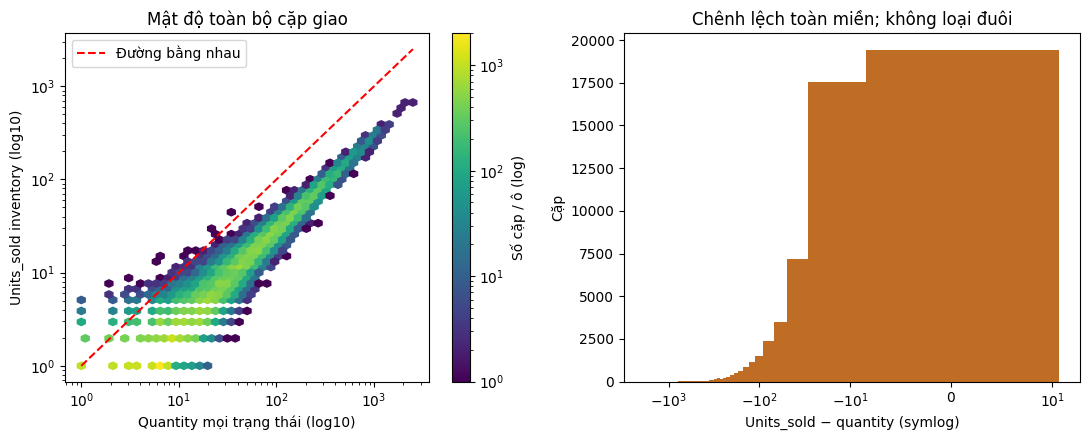

**Kết quả quan sát:** Tương quan cao nhưng hai lượng hiếm khi bằng nhau. **Bằng chứng:** 56.615 cặp; 1.716 bằng (3,0310%); lớn/nhỏ hơn 771/54.128; Pearson/Spearman 0,989704/0,949243; MAE số học 40,4052, median |chênh| 16,00; mã786 670/2.502. **Ý nghĩa:** Tương quan đo đồng biến theo quy mô, không đo đồng nhất; tỷ lệ bằng dùng đúng phần giao đã xác định. **Giới hạn:** Chưa chứng minh cùng đại lượng, trạng thái và kỳ; không sửa inventory để khớp orders và chưa xác nhận công thức chuyển đổi. **Câu hỏi tiếp:** Quy tắc xuất/ghi bán, hủy/hoàn, đơn vị và mốc kỳ khác nhau thế nào?

In [48]:
def pair54(transactions,base=None):
    if base is None:base=inv54
    frame=base[keys54+['units_sold','category','segment']].merge(transactions,on=keys54,how='inner',validate='one_to_one')
    frame['difference']=frame.units_sold-frame.quantity
    frame['absolute_difference']=frame.difference.abs()
    frame['relative_difference']=frame.difference/frame.quantity.where(frame.quantity.gt(0))
    frame['year']=frame.month.str[:4]
    return frame
def summarize54(frame):
    n=len(frame);diff=frame.difference;absolute=frame.absolute_difference
    correlations=corr53(frame,'units_sold','quantity')
    return {'Cặp':n,'Sản phẩm':frame.product_id.nunique(),'Bằng nhau':int(diff.eq(0).sum()),'% khớp / cặp':pct(int(diff.eq(0).sum()),n),'Inventory lớn hơn':int(diff.gt(0).sum()),'Inventory nhỏ hơn':int(diff.lt(0).sum()),
      'Tổng units_sold':int(frame.units_sold.sum()),'Tổng quantity':int(frame.quantity.sum()),'Chênh tổng':int(diff.sum()),
      'Units_sold mean':frame.units_sold.mean(),'Units_sold median':frame.units_sold.median(),'Quantity mean':frame.quantity.mean(),'Quantity median':frame.quantity.median(),
      'Mean chênh':diff.mean(),'Median chênh':diff.median(),'MAE số học':absolute.mean(),'Median |chênh|':absolute.median(),
      'P90 |chênh|':absolute.quantile(.9),'P95 |chênh|':absolute.quantile(.95),'P99 |chênh|':absolute.quantile(.99),'Min chênh':diff.min(),'Max chênh':diff.max(),
      'Mẫu số tương đối hợp lệ':int(frame.relative_difference.notna().sum()),'Median chênh tương đối':frame.relative_difference.median(),
      'Pearson':correlations['Pearson'],'Spearman':correlations['Spearman']}
compact_cols54=['Cặp','Sản phẩm','% khớp / cặp','Chênh tổng','MAE số học','Median |chênh|','Pearson','Spearman']
def compact54(frame):return {k:v for k,v in summarize54(frame).items() if k in compact_cols54}
common54=pair54(tx54);main_summary54=summarize54(common54)
show54('Độ lệch số học trên phần giao, không phải lỗi dự báo',pd.DataFrame([{'Chỉ tiêu':k,'Giá trị':v} for k,v in main_summary54.items()]))
ratio_source54=common54.units_sold/common54.quantity.where(common54.quantity.gt(0))
show54('Phân bố chênh và tỷ số hai lượng — không xác nhận công thức',pd.DataFrame({'Difference':common54.difference,'AbsoluteDifference':common54.absolute_difference,'RelativeDifference (quantity>0)':common54.relative_difference,'Units_sold/quantity (quantity>0)':ratio_source54}).describe(percentiles=[.25,.5,.75,.9,.95,.99]).reset_index().rename(columns={'index':'Thống kê'}))
common54['Khoảng quantity']=pd.cut(common54.quantity,[-np.inf,0,5,10,25,50,100,500,np.inf])
comparison_groups54=[]
for key in ['year','category','Khoảng quantity']:
    for value,g in common54.groupby(key,observed=True):
        comparison_groups54.append({'Cấp nhóm':key,'Nhóm':str(value),**compact54(g)})
show54('Sai lệch theo năm/category/khoảng quantity; mẫu số là cặp giao trong nhóm',pd.DataFrame(comparison_groups54))
example_specs54=[('Bằng nhau',common54.loc[common54.difference.eq(0)].sort_values(keys54).head(2)),
 ('Chênh dương lớn',common54.loc[common54.difference.gt(0)].nlargest(2,'difference')),
 ('Chênh âm lớn',common54.nsmallest(2,'difference')),
 ('|Tỷ số chênh| lớn',common54.assign(abs_relative=common54.relative_difference.abs()).nlargest(2,'abs_relative')),
 ('Nhiều dòng đơn',common54.nlargest(2,'item_rows'))]
comparison_examples54=pd.concat([f.assign(**{'Tiêu chí chọn':label}) for label,f in example_specs54],ignore_index=True)
show54('Ví dụ truy nguyên trên cặp, không xuất toàn bộ chi tiết',comparison_examples54[['Tiêu chí chọn',*keys54,'units_sold','quantity','difference','absolute_difference','relative_difference','item_rows','orders']])
witness54=common54.loc[common54.product_id.eq('786')&common54.month.eq('2012-12')].copy()
witness_items54=joined54.loc[joined54.product_id.eq('786')&joined54.month.eq('2012-12')]
show54('Tính lại mã786 tháng12/2012 — lượng nguồn và số dòng/đơn',witness54[keys54+['units_sold','quantity','difference','item_rows','orders']])
show54('Mã786 tháng12/2012 — đóng góp từng trạng thái, vẫn giữ dòng items lặp',witness_items54.groupby('order_status').agg(item_rows=('quantity','size'),orders=('order_id','nunique'),quantity=('quantity','sum')).reset_index())
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
assert common54[['quantity','units_sold']].gt(0).all().all()
h=axes[0].hexbin(common54.quantity,common54.units_sold,gridsize=42,xscale='log',yscale='log',bins='log',mincnt=1,cmap='viridis')
lo=min(common54.quantity.min(),common54.units_sold.min());hi=max(common54.quantity.max(),common54.units_sold.max())
axes[0].plot([lo,hi],[lo,hi],'r--',label='Đường bằng nhau')
axes[0].set(xlabel='Quantity mọi trạng thái (log10)',ylabel='Units_sold inventory (log10)',title='Mật độ toàn bộ cặp giao');axes[0].legend()
fig.colorbar(h,ax=axes[0],label='Số cặp / ô (log)')
axes[1].hist(common54.difference,bins=90,color='#bf6c24');axes[1].set_xscale('symlog',linthresh=10)
axes[1].set(xlabel='Units_sold − quantity (symlog)',ylabel='Cặp',title='Chênh lệch toàn miền; không loại đuôi');plot_done(fig)
note54('Tương quan cao nhưng hai lượng hiếm khi bằng nhau.',
 f"{vn(main_summary54['Cặp'])} cặp; {vn(main_summary54['Bằng nhau'])} bằng ({vn(main_summary54['% khớp / cặp'],4)}%); lớn/nhỏ hơn {vn(main_summary54['Inventory lớn hơn'])}/{vn(main_summary54['Inventory nhỏ hơn'])}; Pearson/Spearman {vn(main_summary54['Pearson'],6)}/{vn(main_summary54['Spearman'],6)}; MAE số học {vn(main_summary54['MAE số học'],4)}, median |chênh| {vn(main_summary54['Median |chênh|'],2)}; mã786 {vn(witness54.units_sold.iloc[0])}/{vn(witness54.quantity.iloc[0])}.",
 'Tương quan đo đồng biến theo quy mô, không đo đồng nhất; tỷ lệ bằng dùng đúng phần giao đã xác định.',
 'Chưa chứng minh cùng đại lượng, trạng thái và kỳ; không sửa inventory để khớp orders và chưa xác nhận công thức chuyển đổi.',
 'Quy tắc xuất/ghi bán, hủy/hoàn, đơn vị và mốc kỳ khác nhau thế nào?')

### NV05.4.5 – Ảnh hưởng của order_status

**Mục tiêu:** xem bộ lọc thay số lượng hay mẫu quan sát đến đâu. **Đơn vị:** cặp mã–tháng đặt có quantity trong phạm vi chọn. **Phương pháp:** bảng thứ nhất báo tổng quantity toàn nguồn, số cặp giao riêng và thống kê từng trạng thái, gồm delivered; mẫu các hàng có thể khác và được ghi rõ.

Bảng thứ hai dùng **cùng một tập cặp cho tất cả phương án**: giao inventory với các tập quantity của mọi trạng thái. Chỉ giữ cặp có bản ghi ở từng phạm vi, không gán0 cho trạng thái vắng. So mọi trạng thái, delivered-only và từng trạng thái trên đúng tập cố định; đây là mẫu chọn lọc, không đại diện toàn nguồn. Biểu đồ chỉ dùng tập cố định này.

Không chọn tương quan cao nhất làm định nghĩa units_sold. Delivered chưa là toàn bộ bán thực, cancelled chưa xác nhận không tác động kho, returned chưa là nhập kho, shipped chưa xác nhận xuất kho thành công; không có lịch sử trạng thái.

**Các phạm vi trạng thái — tổng nguồn và giao riêng, chưa so trên cùng mẫu**

Phạm vi quantity,Mẫu so sánh,Cặp quantity toàn nguồn,Tổng quantity toàn nguồn,Cặp,Sản phẩm,% khớp / cặp,Chênh tổng,MAE số học,Median |chênh|,Pearson,Spearman
Mọi trạng thái,Giao riêng mỗi phạm vi; tập có thể khác,57309,3213143,56615,1588,"3,0310",-2285296,"40,4052","16,0000","0,9897","0,9492"
Chỉ cancelled,Giao riêng mỗi phạm vi; tập có thể khác,25617,296113,25551,1350,"3,9607",465760,"19,4043","10,0000","0,8495","0,6239"
Chỉ created,Giao riêng mỗi phạm vi; tập có thể khác,6424,36137,6415,941,"2,1512",282123,"44,4245","25,0000","0,3785","0,2292"
Chỉ delivered,Giao riêng mỗi phạm vi; tập có thể khác,54535,2565930,53965,1563,"3,5616",-1642965,"30,5629","12,0000","0,9855","0,9286"
Chỉ paid,Giao riêng mỗi phạm vi; tập có thể khác,10439,67325,10419,1062,"2,2363",397881,"38,7013","22,0000","0,5304","0,3044"
Chỉ returned,Giao riêng mỗi phạm vi; tập có thể khác,19730,179401,19694,1284,"3,2599",498247,"26,0836","14,0000","0,7650","0,5268"
Chỉ shipped,Giao riêng mỗi phạm vi; tập có thể khác,10528,68237,10511,1075,"2,4736",393430,"37,9576","21,0000","0,5529","0,3144"


**So các phương án trên cùng tập cặp cố định — không gán0 trạng thái vắng**

Phạm vi quantity,Mẫu so sánh,Cặp,Sản phẩm,% khớp / cặp,Chênh tổng,MAE số học,Median |chênh|,Pearson,Spearman
Mọi trạng thái,Cùng giao của inventory và mọi phạm vi trạng thái,1438,252,"0,0000",-407607,"283,4541","230,0000","0,9884","0,9836"
Chỉ cancelled,Cùng giao của inventory và mọi phạm vi trạng thái,1438,252,"0,1391",113568,"78,9819","63,0000","0,8842","0,8371"
Chỉ created,Cùng giao của inventory và mọi phạm vi trạng thái,1438,252,"0,0000",155122,"107,8734","87,0000","0,4014","0,2736"
Chỉ delivered,Cùng giao của inventory và mọi phạm vi trạng thái,1438,252,"0,0000",-283903,"197,4291","160,5000","0,9850","0,9798"
Chỉ paid,Cùng giao của inventory và mọi phạm vi trạng thái,1438,252,"0,0000",151011,"105,0146","84,0000","0,5827","0,4378"
Chỉ returned,Cùng giao của inventory và mọi phạm vi trạng thái,1438,252,"0,0000",133200,"92,6412","74,0000","0,8082","0,7225"
Chỉ shipped,Cùng giao của inventory và mọi phạm vi trạng thái,1438,252,"0,0000",150655,"104,7670","84,5000","0,6215","0,4772"


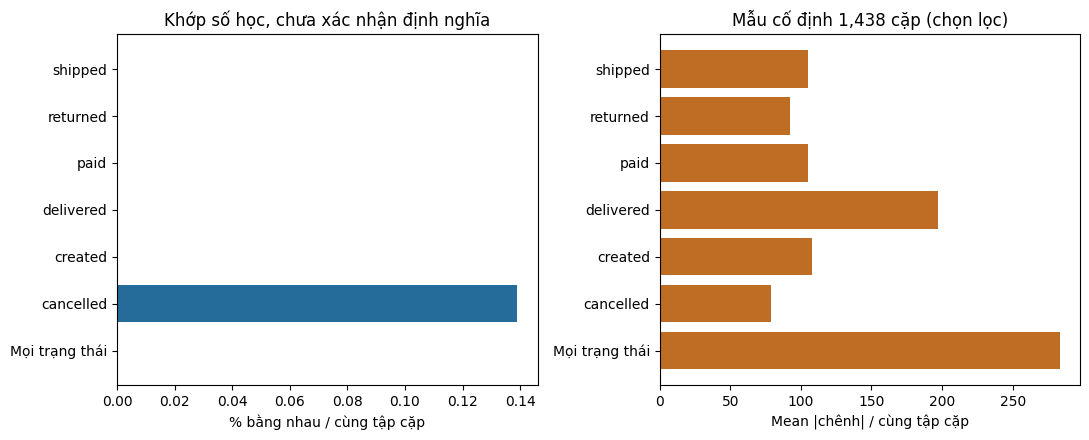

**Kết quả quan sát:** Bộ lọc thay cả tổng quantity và số cặp có mặt. **Bằng chứng:** Delivered-only giao riêng 53.965, khớp 3,5616%; cùng tập cố định 1.438 cặp: mọi trạng thái khớp 0,0000%, delivered 0,0000%. **Ý nghĩa:** Tập cố định tách ảnh hưởng bộ lọc khỏi thay đổi mẫu; mẫu giao riêng phản ánh độ phủ thực mỗi phạm vi. **Giới hạn:** Mẫu có đủ mọi trạng thái là nhóm chọn lọc; không dùng phương án đẹp nhất để xác nhận nghĩa bán. **Câu hỏi tiếp:** Trạng thái được chụp lúc nào và quy tắc kho ghi nhận tại trạng thái nào?

In [49]:
scope_tx54={'Mọi trạng thái':tx54,**{f'Chỉ {status}':frame for status,frame in status_tx54.items()}}
status_native_rows54=[];status_pairs54={}
for label,frame in scope_tx54.items():
    paired=pair54(frame);status_pairs54[label]=paired
    status_native_rows54.append({'Phạm vi quantity':label,'Mẫu so sánh':'Giao riêng mỗi phạm vi; tập có thể khác','Cặp quantity toàn nguồn':len(frame),'Tổng quantity toàn nguồn':int(frame.quantity.sum()),**compact54(paired)})
status_native54=pd.DataFrame(status_native_rows54)
show54('Các phạm vi trạng thái — tổng nguồn và giao riêng, chưa so trên cùng mẫu',status_native54)
fixed_keys54=set.intersection(inv_keys54,*[keyset54(frame) for frame in scope_tx54.values()])
fixed_status_rows54=[];fixed_status_frames54={}
for label,paired in status_pairs54.items():
    mask=pd.Series([key in fixed_keys54 for key in paired[keys54].itertuples(index=False,name=None)],index=paired.index)
    g=paired.loc[mask];fixed_status_frames54[label]=g
    fixed_status_rows54.append({'Phạm vi quantity':label,'Mẫu so sánh':'Cùng giao của inventory và mọi phạm vi trạng thái',**compact54(g)})
fixed_status54=pd.DataFrame(fixed_status_rows54)
show54('So các phương án trên cùng tập cặp cố định — không gán0 trạng thái vắng',fixed_status54)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
labels=[r['Phạm vi quantity'].replace('Chỉ ','') for r in fixed_status_rows54]
axes[0].barh(labels,[r['% khớp / cặp'] for r in fixed_status_rows54],color='#256c9b')
axes[0].set(xlabel='% bằng nhau / cùng tập cặp',title='Khớp số học, chưa xác nhận định nghĩa')
axes[1].barh(labels,[r['MAE số học'] for r in fixed_status_rows54],color='#bf6c24')
axes[1].set(xlabel='Mean |chênh| / cùng tập cặp',title=f'Mẫu cố định {len(fixed_keys54):,} cặp (chọn lọc)');plot_done(fig)
delivered_row54=next(r for r in status_native_rows54 if r['Phạm vi quantity']=='Chỉ delivered')
fixed_all54=next(r for r in fixed_status_rows54 if r['Phạm vi quantity']=='Mọi trạng thái')
fixed_delivered54=next(r for r in fixed_status_rows54 if r['Phạm vi quantity']=='Chỉ delivered')
note54('Bộ lọc thay cả tổng quantity và số cặp có mặt.',
 f"Delivered-only giao riêng {vn(delivered_row54['Cặp'])}, khớp {vn(delivered_row54['% khớp / cặp'],4)}%; cùng tập cố định {vn(len(fixed_keys54))} cặp: mọi trạng thái khớp {vn(fixed_all54['% khớp / cặp'],4)}%, delivered {vn(fixed_delivered54['% khớp / cặp'],4)}%.",
 'Tập cố định tách ảnh hưởng bộ lọc khỏi thay đổi mẫu; mẫu giao riêng phản ánh độ phủ thực mỗi phạm vi.',
 'Mẫu có đủ mọi trạng thái là nhóm chọn lọc; không dùng phương án đẹp nhất để xác nhận nghĩa bán.',
 'Trạng thái được chụp lúc nào và quy tắc kho ghi nhận tại trạng thái nào?')

### NV05.4.6 – Quan hệ toán học ứng viên và tránh xác minh vòng tròn

**Mục tiêu:** phân biệt đồng biến, gần công thức và định nghĩa nghiệp vụ. **Đơn vị:** dòng inventory; với hai nguồn bán là cặp giao ở mục4–5. **Phương pháp:** phân bố received−sold, dấu và mô tả năm/category. Tỷ số received/sold khảo sát trước; thử minh họa received=sold và floor(1,1×sold), floor(1,2×sold), floor(1,3×sold), vì tỷ số quan sát tập trung quanh 1–1,3. Hệ số chỉ là lưới khảo sát, không là biên nhập hay chính sách; tính bằng số nguyên, dung sai0, kiểm tra toàn bộ dòng. Không tối ưu hệ số hoặc dựng mô hình.

Chỉ dẫn lại ba ứng viên DOS/fill/sell-through của NV05.3 sau kiểm tra hash nguồn và kết quả đã chạy; không lặp phân tích dài. DOS có stock trong ứng viên nên không xác nhận stock độc lập; sell-through có sold nên không chứng minh bán thực; stockout_flag trùng ngày dương không là chứng thực độc lập của ngày. Tương quan gần1 không xác nhận công thức, và các cách chọn order_status chưa chứng minh một công thức liên hệ chính thức giữa units_sold và quantity.

In [50]:
recorded_diff54=inv54.units_received-inv54.units_sold
diff_distribution54=recorded_diff54.value_counts().sort_index().rename_axis('Received − sold').reset_index(name='Dòng')
diff_distribution54['% / inventory']=100*diff_distribution54['Dòng']/len(inv54)
show54('Phân bố đầy đủ chênh hai lượng inventory, chỉ là số học',diff_distribution54)
diff_group54=[]
for key,series in [('Năm',inv54.month.str[:4]),('Category',inv54.category)]:
    for value,index in series.groupby(series).groups.items():
        vals=recorded_diff54.loc[index]
        diff_group54.append({'Cấp nhóm':key,'Nhóm':str(value),'Dòng':len(vals),'Sản phẩm':inv54.loc[index,'product_id'].nunique(),'Âm':int(vals.lt(0).sum()),'Bằng0':int(vals.eq(0).sum()),'Dương':int(vals.gt(0).sum()),'Mean chênh':vals.mean(),'Median chênh':vals.median(),'P95 chênh':vals.quantile(.95),'Max chênh':vals.max()})
show54('Chênh received−sold theo năm/category',pd.DataFrame(diff_group54))
received_ratio54=inv54.units_received/inv54.units_sold.where(inv54.units_sold.gt(0))
show54('Tỷ số số học received/sold, không phải chỉ tiêu nhập kho',received_ratio54.describe(percentiles=[.25,.5,.75,.9,.99]).rename_axis('Thống kê').reset_index(name='Giá trị'))
received_hypotheses54=[]
for numerator in [10,11,12,13]:
    predicted=(numerator*inv54.units_sold)//10
    error=inv54.units_received-predicted
    received_hypotheses54.append({'Giả thuyết số học':f"received = floor({numerator}/10 × sold)",'Dòng':len(error),'Dung sai':0,'Khớp chính xác':int(error.eq(0).sum()),'% / inventory':100*error.eq(0).mean(),'MAE số học':error.abs().mean(),'Max |chênh|':error.abs().max(),'Giới hạn':'Lưới minh họa, chưa xác minh công thức nghiệp vụ'})
show54('Giả thuyết received–sold trên toàn bộ dòng, không suy từ tương quan',pd.DataFrame(received_hypotheses54))
reused_hypotheses54=[formula_rows53[i].copy() for i in [0,2,5]]
reuse_source_match54=source_hashes54['inventory']==source_hashes['inventory']==sha(paths54['inventory'])
show54('Ba giả thuyết NV05.3 dẫn lại sau kiểm tra hash và kiểm chứng đã chạy',pd.DataFrame(reused_hypotheses54))
note54('Received không nhỏ hơn sold trên dữ liệu, nhưng hệ số tương quan chưa thành công thức.',
 f"Âm/0/dương {vn(recorded_diff54.lt(0).sum())}/{vn(recorded_diff54.eq(0).sum())}/{vn(recorded_diff54.gt(0).sum())}; Pearson NV05.3 {vn(triple_corr53.Pearson.iloc[0],6)}; nguồn tái dùng khớp hash={reuse_source_match54}; max tỷ số received/sold {vn(received_ratio54.max(),6)}.",
 'Các quan hệ gần xác định gợi ý kiểm tra pipeline và phụ thuộc thông tin.',
 'Chưa xác minh công thức giữa hai nguồn bán hoặc received/sold; không dùng chỉ báo dẫn xuất để xác minh chính trường tạo nó.',
 'Có đặc tả sinh dữ liệu và các trường nguồn độc lập để đối chiếu không?')

**Phân bố đầy đủ chênh hai lượng inventory, chỉ là số học**

Received − sold,Dòng,% / inventory
0,28987,"48,1136"
1,10209,"16,9452"
2,5471,"9,0810"
3,3434,"5,6999"
4,2281,"3,7861"
5,1702,"2,8250"
6,1299,"2,1561"
7,1017,"1,6881"
8,820,"1,3611"
9,714,"1,1851"


**Chênh received−sold theo năm/category**

Cấp nhóm,Nhóm,Dòng,Sản phẩm,Âm,Bằng0,Dương,Mean chênh,Median chênh,P95 chênh,Max chênh
Năm,2012,2539,543,0,1014,1525,"3,3647","1,0000","13,0000",147
Năm,2013,5570,655,0,2098,3472,"3,5953","1,0000","15,0000",120
Năm,2014,5787,692,0,2294,3493,"3,6045","1,0000","16,0000",161
Năm,2015,5872,705,0,2445,3427,"3,5872","1,0000","16,0000",132
Năm,2016,5927,726,0,2479,3448,"3,4964","1,0000","16,0000",96
Năm,2017,6084,737,0,2714,3370,"3,1292","1,0000","14,0000",100
Năm,2018,6106,758,0,2836,3270,"2,7317","1,0000","13,0000",84
Năm,2019,5835,782,0,3309,2526,"1,5930","0,0000","7,0000",68
Năm,2020,5686,827,0,3453,2233,"1,2833","0,0000","6,0000",57
Năm,2021,5609,827,0,3358,2251,"1,3025","0,0000","6,0000",58


**Tỷ số số học received/sold, không phải chỉ tiêu nhập kho**

Thống kê,Giá trị
count,"60.247,0000"
mean,"1,0911"
std,"0,0969"
min,"1,0000"
25%,"1,0000"
50%,"1,0833"
75%,"1,1750"
90%,"1,2353"
99%,"1,2857"
max,"1,2975"


**Giả thuyết received–sold trên toàn bộ dòng, không suy từ tương quan**

Giả thuyết số học,Dòng,Dung sai,Khớp chính xác,% / inventory,MAE số học,Max |chênh|,Giới hạn
received = floor(10/10 × sold),60247,0,28987,"48,1136","2,6290",161,"Lưới minh họa, chưa xác minh công thức nghiệp vụ"
received = floor(11/10 × sold),60247,0,32541,"54,0126","1,4496",103,"Lưới minh họa, chưa xác minh công thức nghiệp vụ"
received = floor(12/10 × sold),60247,0,37912,"62,9276","0,7554",45,"Lưới minh họa, chưa xác minh công thức nghiệp vụ"
received = floor(13/10 × sold),60247,0,30521,"50,6598","1,5310",91,"Lưới minh họa, chưa xác minh công thức nghiệp vụ"


**Ba giả thuyết NV05.3 dẫn lại sau kiểm tra hash và kiểm chứng đã chạy**

Giả thuyết công thức,Dòng hợp lệ,Dòng ngoài miền tính,MAE,Max sai số tuyệt đối,Dung sai,Dòng trong dung sai,% / dòng hợp lệ,Kết luận
fill_rate ≈ 1 − stockout_days/30,60247,0,"0,0000","0,0000","0,0001",60247,"100,0000",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ
days_of_supply ≈ 30 × stock_on_hand/units_sold,60247,0,"0,0093","0,0500","0,0500",60247,"100,0000",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ
sell_through_rate ≈ units_sold/(stock_on_hand+units_sold),60247,0,"0,0000","0,0001","0,0001",60247,"100,0000",Chỉ kiểm tra số học; chưa xác minh định nghĩa nghiệp vụ


**Kết quả quan sát:** Received không nhỏ hơn sold trên dữ liệu, nhưng hệ số tương quan chưa thành công thức. **Bằng chứng:** Âm/0/dương 0/28.987/31.260; Pearson NV05.3 0,998490; nguồn tái dùng khớp hash=True; max tỷ số received/sold 1,297521. **Ý nghĩa:** Các quan hệ gần xác định gợi ý kiểm tra pipeline và phụ thuộc thông tin. **Giới hạn:** Chưa xác minh công thức giữa hai nguồn bán hoặc received/sold; không dùng chỉ báo dẫn xuất để xác minh chính trường tạo nó. **Câu hỏi tiếp:** Có đặc tả sinh dữ liệu và các trường nguồn độc lập để đối chiếu không?

### NV05.4.7 – Return_quantity và inventory

**Mục tiêu:** kiểm tra lượng trả ghi nhận so với lượng nhận, không đồng nhất chúng. **Đơn vị:** sản phẩm–tháng return_date; đối chiếu với cùng nhãn tháng snapshot. **Phương pháp:** returns đã tổng hợp riêng gồm số dòng/đơn, return_quantity, refund_amount; left JOIN một–một để giữ cặp returns vắng inventory. Không gán0 vào phía vắng. Báo độ phủ, tổng lượng trả/refund từng phần, phân bố lượng trả và so received trên phần giao.

RecordedReturnToReceivedRatio=return_quantity/units_received chỉ khi mẫu số dương; đây là **tỷ số số học hai trường ghi nhận**, không phải tỷ lệ hàng trả nhập kho. Phân biệt khách đặt → bản ghi hoàn trả → hàng thực nhập lại kho; dữ liệu chưa chứng minh sự kiện thứ ba. Không cộng return_quantity vào received hoặc suy tồn phải tăng; return_date chưa là ngày nhập kho. Kiểm tra chênh tháng trả–đặt bằng JOIN returns→orders nhiều–một.

**Độ phủ returns–inventory — tổng quantity/refund từng phần, không gán0**

Phạm vi,Cặp,% / cặp returns,Sản phẩm,Dòng returns,Return_quantity,Refund_amount ghi nhận
Returns có inventory cùng tháng,19245,"97,7747",1219,39487,108426,504621302.21
Returns không có inventory cùng tháng,438,"2,2253",367,452,1160,5977204.34


**Phân bố trên cặp giao — tỷ số không phải tỷ lệ nhập lại kho**

Thống kê,return_quantity,units_received,ReturnMinusReceived,RecordedReturnToReceivedRatio
count,"19.245,0000","19.245,0000","19.245,0000","19.245,0000"
mean,"5,6340","40,5545","-34,9206","0,3700"
std,"5,8610","51,3532","47,8358","0,6819"
min,"1,0000","1,0000","-772,0000","0,0041"
25%,"2,0000","10,0000","-46,0000","0,0822"
50%,"4,0000","24,0000","-20,0000","0,1644"
75%,"7,0000","52,0000","-6,0000","0,3438"
90%,"12,0000","95,0000","-1,0000","0,8333"
95%,"17,0000","133,0000","1,0000","1,4000"
99%,"29,0000","249,0000","4,0000","4,0000"


**Quan hệ số học lượng trả–nhận trên cặp giao**

Cặp giao,Sản phẩm,Return < received,Return = received,Return > received,Mẫu số ratio dương,Pearson,Spearman
19245,1219,17450,560,1235,19245,"0,6367","0,4586"


**Khác tháng trả–đặt — ngày trả chưa phải ngày nhập lại kho**

Tháng trả − tháng đặt,Dòng returns,% / dòng returns
0,14152,"35,4340"
1,25782,"64,5534"
2,5,"0,0125"


**Minh họa tối đa 3 returns khác tháng đặt**

return_id,order_id,product_id,order_day,return_day,month_lag,return_quantity
RET-000028,412,676,2012-07-08 00:00:00,2012-08-04 00:00:00,1,2
RET-000037,574,1001,2012-07-09 00:00:00,2012-08-04 00:00:00,1,5
RET-000048,703,786,2012-07-09 00:00:00,2012-08-05 00:00:00,1,6


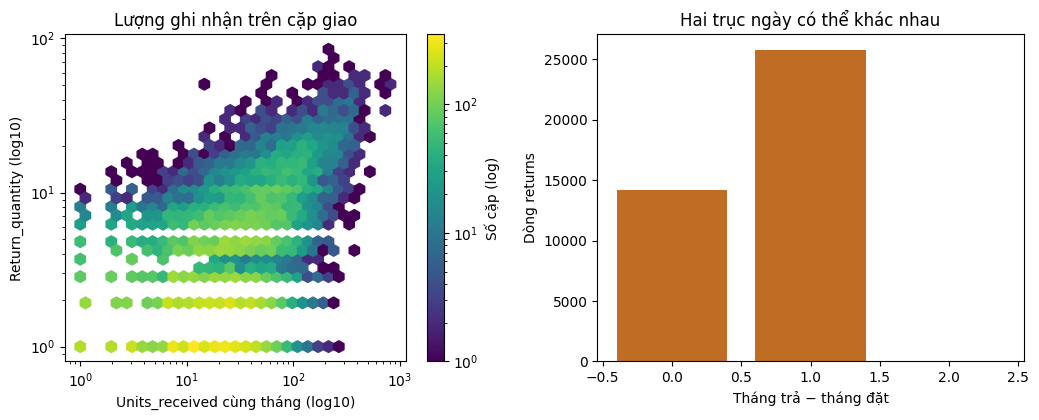

**Kết quả quan sát:** Returns chỉ giao một phần với inventory cùng tháng và khác trục ngày đặt. **Bằng chứng:** 19.683 cặp returns; giao 19.245, không có inventory 438; tổng trả 109.586; khác tháng đặt 25.787/39.939 dòng; ratio median 0,1644. **Ý nghĩa:** Có thể mô tả độ phủ và tỷ số hai lượng ghi nhận trên cùng nhãn tháng. **Giới hạn:** Lượng trả, bản ghi hoàn và nhập lại kho là các sự kiện khác; tỷ số >1 nếu có chưa là vi phạm nghiệp vụ. **Câu hỏi tiếp:** Cần ngày nhận hàng trả, kiểm định hàng, nhập lại/loại bỏ và liên kết chứng từ kho nào?

In [51]:
returns_join54=returns_pm54.merge(inv54,on=keys54,how='left',validate='one_to_one',indicator=True)
returns_join54['coverage']=returns_join54.pop('_merge').map({'left_only':'Returns không có inventory cùng tháng','both':'Returns có inventory cùng tháng','right_only':'Không dùng'}).astype(str)
return_coverage_rows54=[]
for label,g in returns_join54.groupby('coverage'):
    return_coverage_rows54.append({'Phạm vi':label,'Cặp':len(g),'% / cặp returns':100*len(g)/len(returns_pm54),'Sản phẩm':g.product_id.nunique(),'Dòng returns':int(g.return_rows.sum()),'Return_quantity':int(g.return_quantity.sum()),'Refund_amount ghi nhận':Decimal(int(g.refund_cents.sum()))/100})
return_coverage54=pd.DataFrame(return_coverage_rows54)
show54('Độ phủ returns–inventory — tổng quantity/refund từng phần, không gán0',return_coverage54)
ret_common54=returns_join54.loc[returns_join54.coverage.eq('Returns có inventory cùng tháng')].copy()
ret_common54['units_received']=ret_common54.units_received.astype('int64')
ret_common54['RecordedReturnToReceivedRatio']=ret_common54.return_quantity/ret_common54.units_received.where(ret_common54.units_received.gt(0))
ret_common54['ReturnMinusReceived']=ret_common54.return_quantity-ret_common54.units_received
return_stats54=ret_common54[['return_quantity','units_received','ReturnMinusReceived','RecordedReturnToReceivedRatio']].describe(percentiles=[.25,.5,.75,.9,.95,.99])
show54('Phân bố trên cặp giao — tỷ số không phải tỷ lệ nhập lại kho',return_stats54.reset_index().rename(columns={'index':'Thống kê'}))
return_corr54=corr53(ret_common54,'return_quantity','units_received')
show54('Quan hệ số học lượng trả–nhận trên cặp giao',pd.DataFrame([{'Cặp giao':len(ret_common54),'Sản phẩm':ret_common54.product_id.nunique(),'Return < received':int(ret_common54.ReturnMinusReceived.lt(0).sum()),'Return = received':int(ret_common54.ReturnMinusReceived.eq(0).sum()),'Return > received':int(ret_common54.ReturnMinusReceived.gt(0).sum()),'Mẫu số ratio dương':int(ret_common54.RecordedReturnToReceivedRatio.notna().sum()),'Pearson':return_corr54['Pearson'],'Spearman':return_corr54['Spearman']}]))
return_lag_dist54=return_dates54.month_lag.value_counts().sort_index().rename_axis('Tháng trả − tháng đặt').reset_index(name='Dòng returns')
return_lag_dist54['% / dòng returns']=100*return_lag_dist54['Dòng returns']/len(ret54)
show54('Khác tháng trả–đặt — ngày trả chưa phải ngày nhập lại kho',return_lag_dist54)
show54('Minh họa tối đa 3 returns khác tháng đặt',return_dates54.loc[return_dates54.month_lag.ne(0),['return_id','order_id','product_id','order_day','return_day','month_lag','return_quantity']].head(3))
fig,axes=plt.subplots(1,2,figsize=(10.5,4.3))
h=axes[0].hexbin(ret_common54.units_received,ret_common54.return_quantity,gridsize=30,xscale='log',yscale='log',bins='log',mincnt=1,cmap='viridis')
axes[0].set(xlabel='Units_received cùng tháng (log10)',ylabel='Return_quantity (log10)',title='Lượng ghi nhận trên cặp giao');fig.colorbar(h,ax=axes[0],label='Số cặp (log)')
axes[1].bar(return_lag_dist54['Tháng trả − tháng đặt'],return_lag_dist54['Dòng returns'],color='#bf6c24')
axes[1].set(xlabel='Tháng trả − tháng đặt',ylabel='Dòng returns',title='Hai trục ngày có thể khác nhau');plot_done(fig)
note54('Returns chỉ giao một phần với inventory cùng tháng và khác trục ngày đặt.',
 f"{vn(len(returns_pm54))} cặp returns; giao {vn(len(ret_common54))}, không có inventory {vn(len(returns_join54)-len(ret_common54))}; tổng trả {vn(ret54.return_quantity.sum())}; khác tháng đặt {vn(return_dates54.month_lag.ne(0).sum())}/{vn(len(ret54))} dòng; ratio median {vn(ret_common54.RecordedReturnToReceivedRatio.median(),4)}.",
 'Có thể mô tả độ phủ và tỷ số hai lượng ghi nhận trên cùng nhãn tháng.',
 'Lượng trả, bản ghi hoàn và nhập lại kho là các sự kiện khác; tỷ số >1 nếu có chưa là vi phạm nghiệp vụ.',
 'Cần ngày nhận hàng trả, kiểm định hàng, nhập lại/loại bỏ và liên kết chứng từ kho nào?')

### NV05.4.8 – Biến động snapshot giữa hai tháng liên tiếp

**Mục tiêu:** kiểm tra một giả thuyết cân đối số học. **Đơn vị:** cùng mã, hai tháng lịch cách đúng1. **Phương pháp:** sắp mã/tháng; tính khoảng cách bằng số thứ tự tháng, chỉ giữ khoảng cách1. Hai dòng liền nhau qua tháng vắng bị loại khỏi phép chênh, không điền snapshot.

ObservedStockChange=stock_t−stock_(t−1); RecordedInOutDifference=received_t−sold_t; Residual=ObservedStockChange−RecordedInOutDifference. Để so có ý nghĩa cần giả định snapshot là tồn cuối tháng, received/sold là luồng của đúng tháng kết thúc tại snapshot; **các giả định này chưa được xác nhận**. Không có chứng từ điều chỉnh, hư hỏng, chuyển kho hay hàng trả thực nhập để hoàn chỉnh cân đối.

Không gọi residual khác0 là lỗi kho. Không tự thêm return_quantity để làm residual nhỏ hơn. Báo số cặp/mã, khớp, dấu, mean/median, mean/median tuyệt đối, min/max và phân vị; phân nhóm năm/category, không suy nguyên nhân.

**Điều kiện tính chênh — không bắc cầu tháng vắng**

Điều kiện,Dòng
Chưa có snapshot trước trong tệp,1624
Có snapshot trước nhưng vắng tháng ở giữa,7099
"Đủ hai tháng liên tiếp, được tính residual",51524


**Giả thuyết snapshot — residual số học, chưa là lỗi kho**

Chỉ tiêu,Giá trị
Cặp,"51.524,0000"
Sản phẩm,"1.432,0000"
Khớp chính xác,"51.524,0000"
% khớp / cặp,"100,0000"
Âm,"0,0000"
Dương,"0,0000"
Mean residual,"0,0000"
Median residual,"0,0000"
Mean |residual|,"0,0000"
Median |residual|,"0,0000"


**Residual theo năm/category trên cặp đúng liền tháng**

Cấp nhóm,Nhóm,Cặp,Sản phẩm,Khớp chính xác,% khớp / cặp,Âm,Dương,Mean residual,Median residual,Mean |residual|,Median |residual|,Min residual,Max residual,P90 |residual|,P95 |residual|,P99 |residual|
Năm,2012,1904,454,1904,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2013,4990,562,4990,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2014,5142,590,5142,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2015,5245,609,5245,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2016,5282,617,5282,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2017,5382,634,5382,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2018,5335,634,5335,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2019,4811,618,4811,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2020,4560,605,4560,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"
Năm,2021,4529,634,4529,"100,0000",0,0,"0,0000","0,0000","0,0000","0,0000",0,0,"0,0000","0,0000","0,0000"


**Sáu cặp residual tuyệt đối lớn nhất, giữ nguyên trong phân bố**

product_id,previous_month,month,previous_stock,stock_on_hand,units_received,units_sold,ObservedStockChange,RecordedInOutDifference,Residual
1,2022-10,2022-11,3,3,1,1,0,0,0
1,2022-11,2022-12,3,3,1,1,0,0,0
10,2013-01,2013-02,3,4,7,6,1,1,0
10,2013-02,2013-03,4,4,5,5,0,0,0
10,2013-03,2013-04,4,4,3,3,0,0,0
10,2013-04,2013-05,4,4,2,2,0,0,0


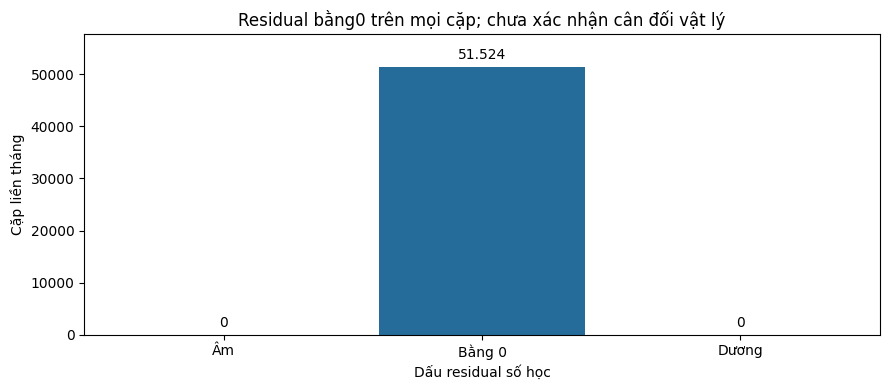

**Kết quả quan sát:** Giả thuyết cân đối khớp số học trên toàn bộ cặp liền tháng. **Bằng chứng:** 51.524 cặp/1432 mã; khớp 51.524 (100,0000%); mean/median residual 0,0000/0,00; median |residual| 0,00; bỏ khỏi phép chênh 7.099 khoảng qua tháng vắng. **Ý nghĩa:** Khi mọi residual bằng0, dữ liệu biểu hiện quy luật cân đối số học; cần sổ biến động và lịch nguồn để xác minh nghĩa nghiệp vụ. **Giới hạn:** Khớp số học chưa xác nhận thời điểm snapshot/kỳ luồng hoặc chứng từ điều chỉnh đầy đủ. Residual khác0 nếu có cũng chưa là lỗi; không thêm returns để ép khớp. **Câu hỏi tiếp:** Có tồn đầu/cuối kỳ và đầy đủ nhập, xuất, chuyển, hư hỏng, hoàn nhập theo cùng kho/kỳ không?

In [52]:
def adjacent54(frame):
    ordered=frame.sort_values(keys54).copy()
    ordered['_month_number']=pd.PeriodIndex(ordered.month,freq='M').asi8
    grouped=ordered.groupby('product_id',sort=False)
    ordered['previous_month']=grouped.month.shift()
    ordered['previous_stock']=grouped.stock_on_hand.shift()
    ordered['month_gap']=ordered._month_number-grouped._month_number.shift()
    eligible=ordered.loc[ordered.month_gap.eq(1)].copy()
    eligible['previous_stock']=eligible.previous_stock.astype('int64')
    eligible['ObservedStockChange']=eligible.stock_on_hand-eligible.previous_stock
    eligible['RecordedInOutDifference']=eligible.units_received-eligible.units_sold
    eligible['Residual']=eligible.ObservedStockChange-eligible.RecordedInOutDifference
    eligible['AbsoluteResidual']=eligible.Residual.abs()
    return ordered,eligible
ordered_snap54,snap54=adjacent54(inv54)
def residual_summary54(frame):
    s=frame.Residual;a=frame.AbsoluteResidual
    return {'Cặp':len(frame),'Sản phẩm':frame.product_id.nunique(),'Khớp chính xác':int(s.eq(0).sum()),'% khớp / cặp':pct(int(s.eq(0).sum()),len(frame)),
      'Âm':int(s.lt(0).sum()),'Dương':int(s.gt(0).sum()),'Mean residual':s.mean(),'Median residual':s.median(),'Mean |residual|':a.mean(),'Median |residual|':a.median(),
      'Min residual':s.min(),'Max residual':s.max(),'P90 |residual|':a.quantile(.9),'P95 |residual|':a.quantile(.95),'P99 |residual|':a.quantile(.99)}
residual_summary_all54=residual_summary54(snap54)
eligibility54=pd.DataFrame([
 {'Điều kiện':'Chưa có snapshot trước trong tệp','Dòng':int(ordered_snap54.previous_month.isna().sum())},
 {'Điều kiện':'Có snapshot trước nhưng vắng tháng ở giữa','Dòng':int(ordered_snap54.month_gap.gt(1).sum())},
 {'Điều kiện':'Đủ hai tháng liên tiếp, được tính residual','Dòng':len(snap54)}])
show54('Điều kiện tính chênh — không bắc cầu tháng vắng',eligibility54)
show54('Giả thuyết snapshot — residual số học, chưa là lỗi kho',pd.DataFrame([{'Chỉ tiêu':k,'Giá trị':v} for k,v in residual_summary_all54.items()]))
residual_groups54=[]
for key,series in [('Năm',snap54.month.str[:4]),('Category',snap54.category)]:
    for value,index in series.groupby(series).groups.items():
        residual_groups54.append({'Cấp nhóm':key,'Nhóm':str(value),**residual_summary54(snap54.loc[index])})
show54('Residual theo năm/category trên cặp đúng liền tháng',pd.DataFrame(residual_groups54))
show54('Sáu cặp residual tuyệt đối lớn nhất, giữ nguyên trong phân bố',snap54.nlargest(6,'AbsoluteResidual')[['product_id','previous_month','month','previous_stock','stock_on_hand','units_received','units_sold','ObservedStockChange','RecordedInOutDifference','Residual']])
fig,ax=plt.subplots(figsize=(9,4))
if snap54.Residual.eq(0).all():
    values=[int(snap54.Residual.lt(0).sum()),int(snap54.Residual.eq(0).sum()),int(snap54.Residual.gt(0).sum())]
    bars=ax.bar(['Âm','Bằng 0','Dương'],values,color=['#bf6c24','#256c9b','#bf6c24'])
    ax.bar_label(bars,labels=[vn(value) for value in values],padding=3)
    ax.set(xlabel='Dấu residual số học',ylabel='Cặp liền tháng',title='Residual bằng0 trên mọi cặp; chưa xác nhận cân đối vật lý')
    ax.margins(y=.12)
else:
    ax.hist(snap54.Residual,bins=100,color='#256c9b');ax.set_xscale('symlog',linthresh=10)
    ax.set(xlabel='Residual số học (symlog; giữ dấu)',ylabel='Cặp liền tháng',title='Chênh snapshot so received−sold; chưa xác nhận cân đối kho')
plot_done(fig)
note54('Giả thuyết cân đối khớp số học trên toàn bộ cặp liền tháng.' if snap54.Residual.eq(0).all() else 'Giả thuyết cân đối chưa khớp trên mọi cặp liền tháng.',
 f"{vn(len(snap54))} cặp/{snap54.product_id.nunique()} mã; khớp {vn(residual_summary_all54['Khớp chính xác'])} ({vn(residual_summary_all54['% khớp / cặp'],4)}%); mean/median residual {vn(residual_summary_all54['Mean residual'],4)}/{vn(residual_summary_all54['Median residual'],2)}; median |residual| {vn(residual_summary_all54['Median |residual|'],2)}; bỏ khỏi phép chênh {vn(ordered_snap54.month_gap.gt(1).sum())} khoảng qua tháng vắng.",
 'Khi mọi residual bằng0, dữ liệu biểu hiện quy luật cân đối số học; cần sổ biến động và lịch nguồn để xác minh nghĩa nghiệp vụ.',
 'Khớp số học chưa xác nhận thời điểm snapshot/kỳ luồng hoặc chứng từ điều chỉnh đầy đủ. Residual khác0 nếu có cũng chưa là lỗi; không thêm returns để ép khớp.',
 'Có tồn đầu/cuối kỳ và đầy đủ nhập, xuất, chuyển, hư hỏng, hoàn nhập theo cùng kho/kỳ không?')

### NV05.4.9 – Độ nhạy theo panel sản phẩm

**Mục tiêu:** kiểm tra khác biệt theo độ phủ. **Đơn vị:** cặp giao hai nguồn bán và cặp snapshot đúng liền tháng. **Phương pháp:** tái dùng ba tập mã NV05.3: toàn bộ, ≥24 tháng inventory, đủ mọi tháng inventory. Mỗi hàng báo số cặp/mã, tỷ lệ khớp đúng mẫu số riêng, chênh trung vị, mean/median chênh tuyệt đối.

Đây là thống kê theo cặp quan sát, mã có nhiều kỳ đóng góp nhiều cặp. Panel đủ kỳ không bảo đảm mọi cặp có quantity; không coi 22 mã đại diện doanh nghiệp. Cặp không giao hoặc snapshot vắng không được điền0.

In [53]:
panel_rows54=[]
for label,ids in scope_ids53.items():
    a=common54.loc[common54.product_id.isin(ids)];b=snap54.loc[snap54.product_id.isin(ids)]
    sa=summarize54(a);sb=residual_summary54(b)
    panel_rows54.append({'Phép đối chiếu':'Units_sold − quantity','Tập mã':label,'Sản phẩm trong tập':len(ids),'Cặp':len(a),'Sản phẩm có cặp':a.product_id.nunique(),'% khớp / cặp':sa['% khớp / cặp'],'Median chênh có dấu':sa['Median chênh'],'Mean |chênh|':sa['MAE số học'],'Median |chênh|':sa['Median |chênh|'],'Pearson':sa['Pearson']})
    panel_rows54.append({'Phép đối chiếu':'Residual snapshot','Tập mã':label,'Sản phẩm trong tập':len(ids),'Cặp':len(b),'Sản phẩm có cặp':b.product_id.nunique(),'% khớp / cặp':sb['% khớp / cặp'],'Median chênh có dấu':sb['Median residual'],'Mean |chênh|':sb['Mean |residual|'],'Median |chênh|':sb['Median |residual|'],'Pearson':np.nan})
panel54=pd.DataFrame(panel_rows54)
show54('Độ nhạy theo tập mã — không nhầm toàn bộ cặp với panel đại diện',panel54)
note54('Phạm vi cặp và mức chênh khác nhau theo độ phủ.',
 '; '.join(f"{r['Phép đối chiếu']}, {r['Tập mã']}: {vn(r['Cặp'])} cặp/{r['Sản phẩm có cặp']} mã, khớp {vn(r['% khớp / cặp'],3)}%" for r in panel_rows54),
 'Độ phủ phải đi cùng kết luận đối chiếu, không chỉ một hệ số gộp.',
 'Các tập chọn lọc và mẫu cặp khác nhau; thiếu kỳ không là giá trị0.',
 'Khác biệt còn giữ khi phạm vi báo cáo sản phẩm/kho được xác nhận không?')

**Độ nhạy theo tập mã — không nhầm toàn bộ cặp với panel đại diện**

Phép đối chiếu,Tập mã,Sản phẩm trong tập,Cặp,Sản phẩm có cặp,% khớp / cặp,Median chênh có dấu,Mean |chênh|,Median |chênh|,Pearson
Units_sold − quantity,Toàn bộ,1624,56615,1588,"3,0310","-16,0000","40,4052","16,0000","0,9897"
Residual snapshot,Toàn bộ,1624,51524,1432,"100,0000","0,0000","0,0000","0,0000",—
Units_sold − quantity,Sản phẩm ≥24 tháng,880,49814,880,"2,5294","-18,0000","43,9251","18,0000","0,9897"
Residual snapshot,Sản phẩm ≥24 tháng,880,46723,880,"100,0000","0,0000","0,0000","0,0000",—
Units_sold − quantity,Panel đủ mọi tháng,22,2767,22,"0,2530","-71,0000","105,5580","71,0000","0,9861"
Residual snapshot,Panel đủ mọi tháng,22,2750,22,"100,0000","0,0000","0,0000","0,0000",—


**Kết quả quan sát:** Phạm vi cặp và mức chênh khác nhau theo độ phủ. **Bằng chứng:** Units_sold − quantity, Toàn bộ: 56.615 cặp/1588 mã, khớp 3,031%; Residual snapshot, Toàn bộ: 51.524 cặp/1432 mã, khớp 100,000%; Units_sold − quantity, Sản phẩm ≥24 tháng: 49.814 cặp/880 mã, khớp 2,529%; Residual snapshot, Sản phẩm ≥24 tháng: 46.723 cặp/880 mã, khớp 100,000%; Units_sold − quantity, Panel đủ mọi tháng: 2.767 cặp/22 mã, khớp 0,253%; Residual snapshot, Panel đủ mọi tháng: 2.750 cặp/22 mã, khớp 100,000% **Ý nghĩa:** Độ phủ phải đi cùng kết luận đối chiếu, không chỉ một hệ số gộp. **Giới hạn:** Các tập chọn lọc và mẫu cặp khác nhau; thiếu kỳ không là giá trị0. **Câu hỏi tiếp:** Khác biệt còn giữ khi phạm vi báo cáo sản phẩm/kho được xác nhận không?

### NV05.4.10 – Tín hiệu bổ sung hàng và đầu vào còn thiếu

**Mục tiêu:** đánh giá dữ liệu hỗ trợ đến đâu cho việc xem xét bổ sung hàng. **Đơn vị:** dòng inventory có thật, số mã và phạm vi tháng từng tổ hợp. **Phương pháp:** kiểm tra lại cờ nguồn; bảng chéo đầy đủ stockout×overstock; năm tổ hợp yêu cầu có số dòng/mã, thời gian, % trên toàn bộ inventory và đặc điểm trung vị.

Tồn cao, sell-through cao dùng >P75 toàn mẫu; tổ hợp nhận/bán cao dùng >P95 cả hai lượng và DOS ≤P25. Ngưỡng chỉ mô tả, không là chính sách. Hai tổ hợp stockout_flag1/overstock1 và ngày dương/overstock1 có thể trùng vì cờ tương đương ngày trong nguồn, không xem là hai chứng cứ độc lập.

Cờ cùng1 chưa là mâu thuẫn: có thể khác cửa sổ hoặc tiêu chí chưa biết. Reorder hằng không phân biệt trạng thái, không chia lớp/mô hình/độ chính xác dự báo và không tạo nhãn mới. Chỉ lập điều kiện còn thiếu; không tính lượng nhập, reorder point, safety stock hoặc EOQ.

In [54]:
reorder_counter54=Counter(inventory.reorder_flag)
show54('Reorder kiểm tra lại từ chuỗi nguồn — một miền, không tạo lớp',pd.DataFrame([{'Giá trị nguồn':k,'Dòng':v,'% / inventory':100*v/len(inventory)} for k,v in sorted(reorder_counter54.items())]))
flag_cross54=inv54.groupby(['stockout_flag','overstock_flag'],sort=True).agg(rows=('product_id','size'),products=('product_id','nunique')).reset_index()
flag_cross54['% / inventory']=100*flag_cross54.rows/len(inv54)
show54('Đầy đủ tổ hợp cờ — số mã không cộng qua các nhóm',flag_cross54.rename(columns={'rows':'Dòng','products':'Sản phẩm'}))
signal_thresholds54={'stock_p75':float(inv54.stock_on_hand.quantile(.75)),'str_p75':float(inv54.sell_through_rate.quantile(.75)),'received_p95':float(inv54.units_received.quantile(.95)),'sold_p95':float(inv54.units_sold.quantile(.95)),'dos_p25':float(inv54.days_of_supply.quantile(.25))}
signal_masks54={
'Stockout1 và overstock1':inv54.stockout_flag.eq(1)&inv54.overstock_flag.eq(1),
'Ngày stockout dương và overstock1':inv54.stockout_days.gt(0)&inv54.overstock_flag.eq(1),
'Ngày dương và tồn >P75':inv54.stockout_days.gt(0)&inv54.stock_on_hand.gt(signal_thresholds54['stock_p75']),
'Overstock1 và sell-through >P75':inv54.overstock_flag.eq(1)&inv54.sell_through_rate.gt(signal_thresholds54['str_p75']),
'Nhận/bán >P95 và DOS ≤P25':inv54.units_received.gt(signal_thresholds54['received_p95'])&inv54.units_sold.gt(signal_thresholds54['sold_p95'])&inv54.days_of_supply.le(signal_thresholds54['dos_p25'])}
signal_rows54=[];signal_sets54={}
for label,mask in signal_masks54.items():
    g=inv54.loc[mask];signal_sets54[label]=set(g.product_id)
    signal_rows54.append({'Tổ hợp':label,'Dòng':len(g),'Sản phẩm':g.product_id.nunique(),'Tháng đầu':g.month.min() if len(g) else 'Không có','Tháng cuối':g.month.max() if len(g) else 'Không có','% / inventory':100*len(g)/len(inv54),
      **{c+' median':g[c].median() for c in ['stock_on_hand','units_received','units_sold','days_of_supply','fill_rate','sell_through_rate']},
      'Giới hạn':'Tín hiệu nguồn; chưa xác nhận nhu cầu hoặc mâu thuẫn nghiệp vụ'})
show54('Năm tổ hợp mô tả — không cộng distinct hoặc coi tín hiệu là quy tắc đặt hàng',pd.DataFrame(signal_rows54))
show54('Ngưỡng phân vị toàn mẫu chỉ dùng mô tả',pd.DataFrame([{'Ngưỡng':k,'Giá trị':v} for k,v in signal_thresholds54.items()]))
missing_inputs54=pd.DataFrame([
 {'Đầu vào cần xác minh':label,'Hiện trạng trong phạm vi 5 nguồn':state,'Vì sao cần':'Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định','Thông tin cần bổ sung':extra}
 for label,state,extra in [
 ('Nhu cầu dự kiến','Quantity đặt và sold ghi nhận chưa là nhu cầu đã xác minh','Nhu cầu theo SKU/kho, hủy/hoàn, mất bán và mùa vụ'),
 ('Chính sách tồn an toàn','Không có đặc tả mục tiêu trong 5 nguồn','Chính sách đã phê duyệt và cách tính theo biến động/lead time'),
 ('Lead time cung ứng','Units_received không có mốc đặt/nhận và nhà cung ứng','Lịch đặt, xác nhận, nhận thực tế và biến động lead time'),
 ('Tồn khả dụng','Stock snapshot chưa rõ khả dụng/vật lý, kho và giữ chỗ','Tồn theo kho, hàng giữ chỗ, hỏng, đang kiểm định'),
 ('Đơn hàng đang chờ','Order_status hiện tại không cung cấp sổ nhu cầu chờ theo thời điểm','Backlog và đơn mua/điều chuyển đang về theo SKU/kho'),
 ('Mức phục vụ mục tiêu','Fill_rate nguồn gần dẫn xuất ngày/30, chưa là SLA','Định nghĩa dịch vụ, tử/mẫu số và mục tiêu được xác nhận'),
 ('Quy tắc reorder','Reorder_flag không phân biệt lớp trong nguồn hiện tại','Quy tắc, ngưỡng, chu kỳ xét và lịch sử kích hoạt'),
 ('Xử lý hàng trả và điều chỉnh','Return_date chưa là nhập lại kho; thiếu luồng điều chỉnh','Nhận trả, kiểm định, nhập lại/loại bỏ, chuyển kho và chứng từ liên kết')]])
show54('Điều kiện còn thiếu để đánh giá bổ sung hàng — không có số lượng đề xuất',missing_inputs54)
note54('Có các nhãn cùng xuất hiện, nhưng chưa có cơ sở quyết định nhập hàng.',
 f"Stockout1/overstock1={vn(signal_rows54[0]['Dòng'])} dòng/{signal_rows54[0]['Sản phẩm']} mã; ngày dương/overstock1={vn(signal_rows54[1]['Dòng'])}; reorder={dict(reorder_counter54)}; {len(missing_inputs54)} nhóm đầu vào cần bổ sung.",
 'Tổ hợp giúp ưu tiên xác minh nguồn và tiêu chí theo thời gian.',
 'Hai cờ cùng1 chưa là mâu thuẫn, chỉ báo dẫn xuất không độc lập; reorder hằng không có khả năng phân biệt.',
 'Có thể cung cấp quy tắc, dữ liệu tồn khả dụng, nhu cầu, lead time và xử lý hàng trả không?')

**Reorder kiểm tra lại từ chuỗi nguồn — một miền, không tạo lớp**

Giá trị nguồn,Dòng,% / inventory
0,60247,"100,0000"


**Đầy đủ tổ hợp cờ — số mã không cộng qua các nhóm**

stockout_flag,overstock_flag,Dòng,Sản phẩm,% / inventory
0,0,4229,1213,"7,0194"
0,1,15447,1200,"25,6395"
1,0,10076,1450,"16,7245"
1,1,30495,1259,"50,6166"


**Năm tổ hợp mô tả — không cộng distinct hoặc coi tín hiệu là quy tắc đặt hàng**

Tổ hợp,Dòng,Sản phẩm,Tháng đầu,Tháng cuối,% / inventory,stock_on_hand median,units_received median,units_sold median,days_of_supply median,fill_rate median,sell_through_rate median,Giới hạn
Stockout1 và overstock1,30495,1259,2012-07,2022-12,"50,6166","103,0000","7,0000","6,0000","375,0000","0,9333","0,0741",Tín hiệu nguồn; chưa xác nhận nhu cầu hoặc mâu thuẫn nghiệp vụ
Ngày stockout dương và overstock1,30495,1259,2012-07,2022-12,"50,6166","103,0000","7,0000","6,0000","375,0000","0,9333","0,0741",Tín hiệu nguồn; chưa xác nhận nhu cầu hoặc mâu thuẫn nghiệp vụ
Ngày dương và tồn >P75,9962,240,2012-07,2022-12,"16,5353","441,0000","22,0000","19,0000","791,2000","0,9333","0,0365",Tín hiệu nguồn; chưa xác nhận nhu cầu hoặc mâu thuẫn nghiệp vụ
Overstock1 và sell-through >P75,685,490,2012-07,2022-12,"1,1370","53,0000","20,0000","17,0000","93,8000","0,9667","0,2424",Tín hiệu nguồn; chưa xác nhận nhu cầu hoặc mâu thuẫn nghiệp vụ
Nhận/bán >P95 và DOS ≤P25,978,203,2012-07,2022-12,"1,6233","201,0000","118,5000","100,0000","58,2500","0,9667","0,3400",Tín hiệu nguồn; chưa xác nhận nhu cầu hoặc mâu thuẫn nghiệp vụ


**Ngưỡng phân vị toàn mẫu chỉ dùng mô tả**

Ngưỡng,Giá trị
stock_p75,"210,0000"
str_p75,"0,2381"
received_p95,"75,0000"
sold_p95,"63,0000"
dos_p25,"96,0000"


**Điều kiện còn thiếu để đánh giá bổ sung hàng — không có số lượng đề xuất**

Đầu vào cần xác minh,Hiện trạng trong phạm vi 5 nguồn,Vì sao cần,Thông tin cần bổ sung
Nhu cầu dự kiến,Quantity đặt và sold ghi nhận chưa là nhu cầu đã xác minh,Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,"Nhu cầu theo SKU/kho, hủy/hoàn, mất bán và mùa vụ"
Chính sách tồn an toàn,Không có đặc tả mục tiêu trong 5 nguồn,Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,Chính sách đã phê duyệt và cách tính theo biến động/lead time
Lead time cung ứng,Units_received không có mốc đặt/nhận và nhà cung ứng,Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,"Lịch đặt, xác nhận, nhận thực tế và biến động lead time"
Tồn khả dụng,"Stock snapshot chưa rõ khả dụng/vật lý, kho và giữ chỗ",Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,"Tồn theo kho, hàng giữ chỗ, hỏng, đang kiểm định"
Đơn hàng đang chờ,Order_status hiện tại không cung cấp sổ nhu cầu chờ theo thời điểm,Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,Backlog và đơn mua/điều chuyển đang về theo SKU/kho
Mức phục vụ mục tiêu,"Fill_rate nguồn gần dẫn xuất ngày/30, chưa là SLA",Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,"Định nghĩa dịch vụ, tử/mẫu số và mục tiêu được xác nhận"
Quy tắc reorder,Reorder_flag không phân biệt lớp trong nguồn hiện tại,Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,"Quy tắc, ngưỡng, chu kỳ xét và lịch sử kích hoạt"
Xử lý hàng trả và điều chỉnh,Return_date chưa là nhập lại kho; thiếu luồng điều chỉnh,Để xác định cùng đơn vị/phạm vi/kỳ và ràng buộc quyết định,"Nhận trả, kiểm định, nhập lại/loại bỏ, chuyển kho và chứng từ liên kết"


**Kết quả quan sát:** Có các nhãn cùng xuất hiện, nhưng chưa có cơ sở quyết định nhập hàng. **Bằng chứng:** Stockout1/overstock1=30.495 dòng/1259 mã; ngày dương/overstock1=30.495; reorder={'0': 60247}; 8 nhóm đầu vào cần bổ sung. **Ý nghĩa:** Tổ hợp giúp ưu tiên xác minh nguồn và tiêu chí theo thời gian. **Giới hạn:** Hai cờ cùng1 chưa là mâu thuẫn, chỉ báo dẫn xuất không độc lập; reorder hằng không có khả năng phân biệt. **Câu hỏi tiếp:** Có thể cung cấp quy tắc, dữ liệu tồn khả dụng, nhu cầu, lead time và xử lý hàng trả không?

### NV05.4.11 – Danh mục vấn đề nghiệp vụ và giới hạn

**Mục tiêu:** phân biệt điều đã kiểm chứng số học với điều cần xác minh nghiệp vụ. **Đơn vị:** nêu riêng dòng, cặp giao, cặp liền tháng và mã. **Phương pháp:** A là vi phạm kỹ thuật đã xác minh (A00 báo không phát hiện nếu phù hợp); B là hiện tượng nghiệp vụ cần làm rõ; C là giới hạn dữ liệu/thiếu định nghĩa. Chênh quantity, residual và cờ cùng1 không tự chuyển thành lỗi kỹ thuật.

Mỗi mục có bằng chứng, mẫu số, nguồn, mức kiểm chứng, ý nghĩa, giới hạn và thông tin/bước tiếp. Các hướng chuyển sang NV05.5 là câu hỏi, chưa thực hiện NV05.5.

In [55]:
technical_counts54={
'Khóa inventory mã–tháng lặp':int(inv54.duplicated(keys54).sum()),
'Khóa orders lặp':int(ord54.order_id.duplicated().sum()),
'Khóa return_id lặp':int(ret54.return_id.duplicated().sum()),
'Items thiếu orders':int(joined54.order_date.isna().sum()),
'Returns thiếu orders':int(return_dates54.order_day.isna().sum()),
'Chênh số dòng JOIN items':abs(len(joined54)-len(items54)),
'Chênh số dòng JOIN returns kiểm tra ngày':abs(len(return_dates54)-len(ret54)),
'Chênh tổng quantity sau tổng hợp':abs(int(tx54.quantity.sum())-int(items54.quantity.sum())),
'Chênh tổng return_quantity':abs(int(returns_pm54.return_quantity.sum())-int(ret54.return_quantity.sum())),
'Chênh tổng refund đơn vị nhỏ nhất':abs(int(returns_pm54.refund_cents.sum())-int(ret54.refund_cents.sum()))}
technical_violations54=sum(v!=0 for v in technical_counts54.values())
issue_specs54=[
('A00','A','Ràng buộc kỹ thuật được kiểm tra',f'{technical_violations54} ràng buộc không đạt/{len(technical_counts54)} ràng buộc','Dòng nguồn, khóa và tổng sau JOIN/aggregate','5 CSV nguồn','Kiểm tra kỹ thuật trực tiếp','Không phát hiện nếu bằng0; giới hạn ở ràng buộc đã kiểm tra','Schema và quy tắc chuẩn','Bổ sung kiểm tra khi có đặc tả'),
('B01','B','Units_sold không đồng nhất quantity',f"Khớp {main_summary54['Bằng nhau']}/{main_summary54['Cặp']}; lớn/nhỏ={main_summary54['Inventory lớn hơn']}/{main_summary54['Inventory nhỏ hơn']}",'Cặp giao mọi trạng thái','inventory + items + orders','Tái tính số nguyên, đối chiếu V04','Không gọi là lỗi trước xác nhận cùng đại lượng/kỳ','Đơn vị, ghi nhận bán/xuất kho và hủy/hoàn','Xác minh ngữ nghĩa ở bước tiếp'),
('B02','B','Tương quan cao, tỷ lệ bằng thấp',f"Pearson={main_summary54['Pearson']:.6f}, khớp={main_summary54['% khớp / cặp']:.4f}%, MAE={main_summary54['MAE số học']:.4f}",f"{len(common54)} cặp giao",'inventory + items + orders','Pearson/Spearman và sai lệch','Đồng biến không là tương đương hoặc công thức','Mẫu số, đơn vị, phạm vi và thời điểm','Đối chiếu chứng từ cùng kỳ'),
('B03','B','Bộ lọc trạng thái thay kết quả',f"Cùng tập {len(fixed_keys54)} cặp; mọi/delivered khớp={fixed_all54['% khớp / cặp']:.4f}%/{fixed_delivered54['% khớp / cặp']:.4f}%",'Tập cố định có mặt mọi phạm vi; bảng native dùng giao riêng','orders + items + inventory','So cùng mẫu và báo độ phủ riêng','Trạng thái hiện tại chưa là lịch sử hoặc định nghĩa bán','Lịch sử trạng thái và mốc xuất/ghi nhận','Làm rõ quy tắc trạng thái'),
('B04','B','Received và sold gần đồng biến',f"Chênh0={int(recorded_diff54.eq(0).sum())}, dương={int(recorded_diff54.gt(0).sum())}; Pearson={triple_corr53.Pearson.iloc[0]:.6f}",f'{len(inv54)} dòng inventory','inventory','Phân bố và lưới công thức kiểm tra toàn bộ','Chưa xác nhận công thức hoặc cân đối vật lý','Pipeline tạo hai trường, loại nhập và đơn vị','Kiểm tra đặc tả, không chọn công thức đẹp nhất'),
('B05','B','Return_quantity chưa là nhập kho',f"{len(returns_pm54)} cặp trả; {len(ret_common54)} có inventory; khác tháng đặt {int(return_dates54.month_lag.ne(0).sum())}/{len(ret54)} dòng", 'Cặp tháng trả và dòng returns','returns + orders + inventory','Độ phủ, tổng và tỷ số được đối chứng','Không cộng trả vào received hoặc phương trình để ép khớp','Ngày thực nhận trả, kiểm định và nhập lại/loại bỏ','Liên kết sự kiện kho nếu được cung cấp'),
('B06','B','Snapshot khớp giả thuyết số học; cân đối kho thực tế chưa xác nhận',f"Residual0={residual_summary_all54['Khớp chính xác']}/{len(snap54)}; median|residual|={residual_summary_all54['Median |residual|']:g}",'Cùng mã, hai tháng cách đúng1','inventory','Residual số nguyên và kiểm tra tháng độc lập','Khớp số học chưa xác nhận cân đối vật lý; thiếu chứng từ đầy đủ','Thời điểm snapshot, kỳ luồng, điều chỉnh/chuyển/hỏng','Xin sổ biến động cùng phạm vi'),
('C07','C','Panel thiếu kỳ và chọn lọc',f"Vắng giữa kỳ={int(coverage.internal_unobserved.sum())}; ≥24 tháng={len(scope_ids53['Sản phẩm ≥24 tháng'])}; đủ kỳ={len(panel_ids52)}",'Mã và cặp theo ba tập sản phẩm','inventory; độ phủ NV05.2','Độ nhạy trên đúng tập mã','Không điền0, không coi panel nhỏ là đại diện','Danh mục phải báo cáo, cơ chế trích xuất','Xác minh độ phủ theo kho/SKU'),
('C08','C','Chỉ báo có phụ thuộc thông tin',f"3 ứng viên NV05.3 khớp dung sai {len(inv54)} dòng; cờ–ngày khác biệt={int(flag1_day0_53.sum()+flag0_daypos53.sum())}",f'{len(inv54)} dòng inventory','inventory; kết quả NV05.3 đã chạy','Khớp số học, nguồn hash khớp','Không xác minh vòng tròn hoặc gọi là định nghĩa nghiệp vụ','Công thức, lineage và trường nguồn độc lập','Xin đặc tả tính và nguồn gốc chỉ báo'),
('C09','C','Stockout và overstock chưa có định nghĩa độc lập',f"Cùng1={signal_rows54[0]['Dòng']} dòng/{signal_rows54[0]['Sản phẩm']} mã",f'{len(inv54)} dòng; từng tổ hợp nêu riêng','inventory','Tổ hợp và phân bố được tính trực tiếp','Cùng1 chưa là mâu thuẫn, có thể khác cửa sổ/tiêu chí','Định nghĩa thiếu/dư, kỳ, ngưỡng, kho','Làm rõ cửa sổ và tính độc lập nhãn'),
('C10','C','Reorder không phân biệt trạng thái',str(dict(reorder_counter54)),f'{len(inv54)} dòng inventory','inventory','Counter toàn nguồn','Không dùng cờ hằng làm nhãn hoặc suy không cần nhập','Quy tắc, lead time, nhu cầu và tồn khả dụng','Thu thập 8 nhóm điều kiện còn thiếu')]
issues54=pd.DataFrame([{'Mã':c,'Phân loại':kind,'Hiện tượng quan sát':phen,'Bằng chứng định lượng':ev,'Phạm vi và mẫu số':scope,'Nguồn dữ liệu':src,'Mức độ kiểm chứng':level,'Ý nghĩa nghiệp vụ':'Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng','Giới hạn':limit,'Thông tin cần bổ sung':extra,'Hướng nghiên cứu tiếp theo':step} for c,kind,phen,ev,scope,src,level,limit,extra,step in issue_specs54])
show54('Vấn đề A/B/C và giới hạn; chênh chưa tương đương không phải lỗi kỹ thuật',issues54)
note54('Đã tách khác biệt số học khỏi vi phạm kỹ thuật.',
 f"{len(issues54)} mục A/B/C, {technical_violations54} ràng buộc kỹ thuật không đạt trong {len(technical_counts54)} ràng buộc khảo sát.",
 'Có danh sách bằng chứng và dữ liệu cần xin cho bước tiếp.',
 'Kiểm tra kỹ thuật đạt chưa chứng minh các trường là cùng đại lượng hoặc đủ để tối ưu.',
 'NV05.5 cần tổng hợp câu hỏi nào về luồng, định nghĩa, chính sách và phạm vi?')

**Vấn đề A/B/C và giới hạn; chênh chưa tương đương không phải lỗi kỹ thuật**

Mã,Phân loại,Hiện tượng quan sát,Bằng chứng định lượng,Phạm vi và mẫu số,Nguồn dữ liệu,Mức độ kiểm chứng,Ý nghĩa nghiệp vụ,Giới hạn,Thông tin cần bổ sung,Hướng nghiên cứu tiếp theo
A00,A,Ràng buộc kỹ thuật được kiểm tra,0 ràng buộc không đạt/10 ràng buộc,"Dòng nguồn, khóa và tổng sau JOIN/aggregate",5 CSV nguồn,Kiểm tra kỹ thuật trực tiếp,"Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Không phát hiện nếu bằng0; giới hạn ở ràng buộc đã kiểm tra,Schema và quy tắc chuẩn,Bổ sung kiểm tra khi có đặc tả
B01,B,Units_sold không đồng nhất quantity,Khớp 1716/56615; lớn/nhỏ=771/54128,Cặp giao mọi trạng thái,inventory + items + orders,"Tái tính số nguyên, đối chiếu V04","Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Không gọi là lỗi trước xác nhận cùng đại lượng/kỳ,"Đơn vị, ghi nhận bán/xuất kho và hủy/hoàn",Xác minh ngữ nghĩa ở bước tiếp
B02,B,"Tương quan cao, tỷ lệ bằng thấp","Pearson=0.989704, khớp=3.0310%, MAE=40.4052",56615 cặp giao,inventory + items + orders,Pearson/Spearman và sai lệch,"Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Đồng biến không là tương đương hoặc công thức,"Mẫu số, đơn vị, phạm vi và thời điểm",Đối chiếu chứng từ cùng kỳ
B03,B,Bộ lọc trạng thái thay kết quả,Cùng tập 1438 cặp; mọi/delivered khớp=0.0000%/0.0000%,Tập cố định có mặt mọi phạm vi; bảng native dùng giao riêng,orders + items + inventory,So cùng mẫu và báo độ phủ riêng,"Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Trạng thái hiện tại chưa là lịch sử hoặc định nghĩa bán,Lịch sử trạng thái và mốc xuất/ghi nhận,Làm rõ quy tắc trạng thái
B04,B,Received và sold gần đồng biến,"Chênh0=28987, dương=31260; Pearson=0.998490",60247 dòng inventory,inventory,Phân bố và lưới công thức kiểm tra toàn bộ,"Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Chưa xác nhận công thức hoặc cân đối vật lý,"Pipeline tạo hai trường, loại nhập và đơn vị","Kiểm tra đặc tả, không chọn công thức đẹp nhất"
B05,B,Return_quantity chưa là nhập kho,19683 cặp trả; 19245 có inventory; khác tháng đặt 25787/39939 dòng,Cặp tháng trả và dòng returns,returns + orders + inventory,"Độ phủ, tổng và tỷ số được đối chứng","Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Không cộng trả vào received hoặc phương trình để ép khớp,"Ngày thực nhận trả, kiểm định và nhập lại/loại bỏ",Liên kết sự kiện kho nếu được cung cấp
B06,B,Snapshot khớp giả thuyết số học; cân đối kho thực tế chưa xác nhận,Residual0=51524/51524; median|residual|=0,"Cùng mã, hai tháng cách đúng1",inventory,Residual số nguyên và kiểm tra tháng độc lập,"Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Khớp số học chưa xác nhận cân đối vật lý; thiếu chứng từ đầy đủ,"Thời điểm snapshot, kỳ luồng, điều chỉnh/chuyển/hỏng",Xin sổ biến động cùng phạm vi
C07,C,Panel thiếu kỳ và chọn lọc,Vắng giữa kỳ=25456; ≥24 tháng=880; đủ kỳ=22,Mã và cặp theo ba tập sản phẩm,inventory; độ phủ NV05.2,Độ nhạy trên đúng tập mã,"Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng","Không điền0, không coi panel nhỏ là đại diện","Danh mục phải báo cáo, cơ chế trích xuất",Xác minh độ phủ theo kho/SKU
C08,C,Chỉ báo có phụ thuộc thông tin,3 ứng viên NV05.3 khớp dung sai 60247 dòng; cờ–ngày khác biệt=0,60247 dòng inventory,inventory; kết quả NV05.3 đã chạy,"Khớp số học, nguồn hash khớp","Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng",Không xác minh vòng tròn hoặc gọi là định nghĩa nghiệp vụ,"Công thức, lineage và trường nguồn độc lập",Xin đặc tả tính và nguồn gốc chỉ báo
C09,C,Stockout và overstock chưa có định nghĩa độc lập,Cùng1=30495 dòng/1259 mã,60247 dòng; từng tổ hợp nêu riêng,inventory,Tổ hợp và phân bố được tính trực tiếp,"Ưu tiên xác minh cấu trúc, định nghĩa và phạm vi trước đánh giá bổ sung hàng","Cùng1 chưa là mâu thuẫn, có thể khác cửa sổ/tiêu chí","Định nghĩa thiếu/dư, kỳ, ngưỡng, kho",Làm 

**Kết quả quan sát:** Đã tách khác biệt số học khỏi vi phạm kỹ thuật. **Bằng chứng:** 11 mục A/B/C, 0 ràng buộc kỹ thuật không đạt trong 10 ràng buộc khảo sát. **Ý nghĩa:** Có danh sách bằng chứng và dữ liệu cần xin cho bước tiếp. **Giới hạn:** Kiểm tra kỹ thuật đạt chưa chứng minh các trường là cùng đại lượng hoặc đủ để tối ưu. **Câu hỏi tiếp:** NV05.5 cần tổng hợp câu hỏi nào về luồng, định nghĩa, chính sách và phạm vi?

### Kiểm chứng NV05.4 – ví dụ độc lập và đọc lại nguồn

**Mục tiêu:** kiểm tra phương pháp và kết quả đã thực thi. **Đơn vị:** dòng nguồn, tập khóa, cặp đối chiếu và cặp tháng liên tiếp. **Phương pháp:** các ví dụ nhỏ trong bộ nhớ có kỳ vọng cố định, không trộn vào nguồn thật. Đối chứng độc lập CSV bằng csv.DictReader, Decimal và số nguyên; ghép items bằng ánh xạ khóa orders, không tái sử dụng kết quả JOIN để tự xác nhận tổng.

Tập khóa, tổng theo trạng thái, quantity/returns/refund, chênh và tháng trước được dựng độc lập; Pearson/Spearman kiểm tra bằng statistics và hạng độc lập NV05.3. Kiểm tra khớp công thức dùng đúng dung sai nguồn. Phân biệt kiểm chứng số học đã chạy với định nghĩa nghiệp vụ chưa thể xác nhận. Kiểm tra bảo toàn 91 ô và tệp ngoài notebook bằng SHA-256.

In [56]:
fixture_orders54=pd.DataFrame([('O1','2020-01-05','delivered'),('O2','2020-01-06','cancelled'),('O3','2020-01-20','returned')],columns=['order_id','order_date','order_status'])
fixture_orders54['month']=fixture_orders54.order_date.str[:7]
fixture_items54=pd.DataFrame([('O1','T_A',2),('O1','T_A',3),('O2','T_B',4),('O3','T_D',6)],columns=['order_id','product_id','quantity'])
fixture_inv54=pd.DataFrame([
 ('T_A','2020-01',10,5,5,1,1,0),('T_A','2020-02',12,4,2,0,0,0),('T_A','2020-03',15,5,1,0,1,0),
 ('T_Y','2020-01',8,1,1,0,0,0),('T_D','2020-01',6,2,2,0,0,0),('T_D','2020-03',10,5,1,0,0,0)],
 columns=['product_id','month','stock_on_hand','units_received','units_sold','stockout_flag','overstock_flag','reorder_flag'])
fixture_join54=fixture_items54.merge(fixture_orders54,on='order_id',validate='many_to_one')
fixture_pm54=fixture_join54.groupby(keys54).quantity.sum().reset_index()
fixture_ledger54=fixture_inv54.merge(fixture_pm54,on=keys54,how='outer',validate='one_to_one',indicator=True)
fixture_ret54=pd.DataFrame([('FR1','O3','T_D','2020-02-04',1,'10.25')],columns=['return_id','order_id','product_id','return_date','return_quantity','refund_amount'])
fixture_ret_dates54=fixture_ret54.merge(fixture_orders54,on='order_id',validate='many_to_one')
fixture_ordered54,fixture_adj54=adjacent54(fixture_inv54)
fixture_delivered54=fixture_join54.loc[fixture_join54.order_status.eq('delivered')].groupby(keys54).quantity.sum().reset_index()
fixture_missing_status54=fixture_pm54.merge(fixture_delivered54,on=keys54,how='left',suffixes=('_all','_delivered'),validate='one_to_one')
fixture_checks54={
'Inventory có cặp vắng items':((fixture_ledger54.product_id=='T_Y')&(fixture_ledger54._merge=='left_only')).sum()==1,
'Items có cặp vắng inventory, giữ NA':fixture_ledger54.loc[fixture_ledger54.product_id.eq('T_B'),'units_sold'].isna().all(),
'Một đơn nhiều dòng items được giữ và tổng hợp':len(fixture_join54)==4 and fixture_pm54.loc[fixture_pm54.product_id.eq('T_A'),'quantity'].iloc[0]==5,
'Cặp hai lượng bằng chính xác':fixture_ledger54.loc[fixture_ledger54.product_id.eq('T_A')&fixture_ledger54.month.eq('2020-01'),'units_sold'].iloc[0]==5,
'Cặp khác nhau giữ dấu inventory−quantity':(fixture_ledger54.loc[fixture_ledger54.product_id.eq('T_D')&fixture_ledger54.month.eq('2020-01'),'units_sold']-fixture_ledger54.loc[fixture_ledger54.product_id.eq('T_D')&fixture_ledger54.month.eq('2020-01'),'quantity']).iloc[0]==-4,
'Cancelled có items và không bị lọc ngầm':fixture_join54.loc[fixture_join54.order_status.eq('cancelled'),'quantity'].sum()==4 and fixture_join54.quantity.sum()==15,
'Returns ở tháng sau đặt, không phải ngày nhập kho':fixture_ret_dates54.return_date.iloc[0][:7]=='2020-02' and fixture_ret_dates54.order_date.iloc[0][:7]=='2020-01',
'Không bắc cầu snapshot vắng giữa kỳ':not fixture_adj54.product_id.eq('T_D').any() and fixture_ordered54.loc[fixture_ordered54.product_id.eq('T_D'),'month_gap'].dropna().tolist()==[2.],
'Residual0 và khác0 tính đúng độc lập':fixture_adj54.Residual.tolist()==[0,-1] and fixture_adj54.ObservedStockChange.tolist()==[2,3] and fixture_adj54.RecordedInOutDifference.tolist()==[2,4],
'Hai cờ cùng1 được giữ nguyên':((fixture_inv54.stockout_flag==1)&(fixture_inv54.overstock_flag==1)).sum()==1,
'Reorder chỉ0 không tạo hai lớp':fixture_inv54.reorder_flag.value_counts().to_dict()=={0:6},
'Trạng thái vắng không tự điền0':fixture_missing_status54.quantity_delivered.isna().sum()==2,
'Refund kiểm tra Decimal chính xác':Decimal(fixture_ret54.refund_amount.iloc[0])*100==1025}
for label,ok in fixture_checks54.items():check54('Ví dụ: '+label,ok,'Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn')

def raw_rows54(name):
    with paths54[name].open(encoding='utf-8-sig',newline='') as stream:
        yield from csv.DictReader(stream)
audit_orders54={};audit_order_status_counts54=Counter()
for r in raw_rows54('orders'):
    assert r['order_id'] not in audit_orders54
    audit_orders54[r['order_id']]=(r['order_date'][:7],r['order_status'])
    audit_order_status_counts54[r['order_status']]+=1
audit_tx54=defaultdict(int);audit_status54={s:defaultdict(int) for s in statuses54}
audit_items_count54=Counter();audit_total_quantity54=0;audit_item_rows54=0;audit_witness_orders54=set()
for r in raw_rows54('order_items'):
    month,status=audit_orders54[r['order_id']];key=(r['product_id'],month);qty=Decimal(r['quantity'])
    assert qty==qty.to_integral_value()
    value=int(qty);audit_tx54[key]+=value;audit_status54[status][key]+=value;audit_items_count54[key]+=1
    audit_total_quantity54+=value;audit_item_rows54+=1
    if key==('786','2012-12'):audit_witness_orders54.add(r['order_id'])
audit_inv54={(r['product_id'],r['snapshot_date'][:7]):r for r in audit_rows53}
audit_inv_keys54=set(audit_inv54);audit_tx_keys54=set(audit_tx54)
audit_returns54={};audit_return_ids54=set();audit_return_total54=0;audit_refund_cents54=0;audit_lags54=Counter();audit_return_rows54=0
for r in raw_rows54('returns'):
    assert r['return_id'] not in audit_return_ids54;audit_return_ids54.add(r['return_id'])
    key=(r['product_id'],r['return_date'][:7]);qty=Decimal(r['return_quantity']);cents=Decimal(r['refund_amount'])*100
    assert qty==qty.to_integral_value() and cents==cents.to_integral_value()
    slot=audit_returns54.setdefault(key,{'qty':0,'cents':0,'rows':0,'orders':set()})
    slot['qty']+=int(qty);slot['cents']+=int(cents);slot['rows']+=1;slot['orders'].add(r['order_id'])
    order_month,_=audit_orders54[r['order_id']];ret_month=key[1]
    lag=(int(ret_month[:4])-int(order_month[:4]))*12+int(ret_month[5:])-int(order_month[5:])
    audit_lags54[lag]+=1;audit_return_total54+=int(qty);audit_refund_cents54+=int(cents);audit_return_rows54+=1
def previous_month54(month):
    y,m=int(month[:4]),int(month[5:])
    return f'{y-1:04d}-12' if m==1 else f'{y:04d}-{m-1:02d}'
audit_adj54={}
for (pid,month),r in audit_inv54.items():
    previous=previous_month54(month);prior=audit_inv54.get((pid,previous))
    if prior is not None:
        change=int(r['stock_on_hand'])-int(prior['stock_on_hand']);recorded=int(r['units_received'])-int(r['units_sold'])
        audit_adj54[(pid,month)]=(previous,change,recorded,change-recorded)
def audit_compare54(keys,quantity_map):
    ordered=sorted(keys);xs=[int(audit_inv54[k]['units_sold']) for k in ordered];ys=[quantity_map[k] for k in ordered]
    differences=[a-b for a,b in zip(xs,ys)];absolute=list(map(abs,differences));n=len(ordered)
    pearson=statistics.correlation(xs,ys) if n>=2 and len(set(xs))>1 and len(set(ys))>1 else float('nan')
    spearman=statistics.correlation(audit_ranks53(xs),audit_ranks53(ys)) if n>=2 and len(set(xs))>1 and len(set(ys))>1 else float('nan')
    return {'Cặp':n,'Sản phẩm':len({pid for pid,month in keys}),'Bằng nhau':differences.count(0),'% khớp / cặp':100*differences.count(0)/n if n else np.nan,
      'Inventory lớn hơn':sum(d>0 for d in differences),'Inventory nhỏ hơn':sum(d<0 for d in differences),'Tổng units_sold':sum(xs),'Tổng quantity':sum(ys),'Chênh tổng':sum(differences),
      'Units_sold mean':statistics.mean(xs) if n else np.nan,'Units_sold median':statistics.median(xs) if n else np.nan,
      'Quantity mean':statistics.mean(ys) if n else np.nan,'Quantity median':statistics.median(ys) if n else np.nan,
      'Mean chênh':statistics.mean(differences) if n else np.nan,'Median chênh':statistics.median(differences) if n else np.nan,'MAE số học':statistics.mean(absolute) if n else np.nan,'Median |chênh|':statistics.median(absolute) if n else np.nan,
      **{f'P{p} |chênh|':statistics.quantiles(absolute,n=100,method='inclusive')[p-1] if n>1 else absolute[0] if n else np.nan for p in [90,95,99]},
      'Min chênh':min(differences) if n else np.nan,'Max chênh':max(differences) if n else np.nan,
      'Mẫu số tương đối hợp lệ':sum(y>0 for y in ys),'Median chênh tương đối':statistics.median([d/y for d,y in zip(differences,ys) if y>0]) if any(y>0 for y in ys) else np.nan,'Pearson':pearson,'Spearman':spearman}
def same_number54(a,b):return (pd.isna(a) and pd.isna(b)) or np.isclose(float(a),float(b),rtol=1e-10,atol=1e-10)
def match_summary54(actual,expected):return all(k in actual and same_number54(actual[k],v) for k,v in expected.items())
audit_main_summary54=audit_compare54(audit_inv_keys54&audit_tx_keys54,audit_tx54)
audit_status_maps54={'Mọi trạng thái':audit_tx54,**{f'Chỉ {s}':m for s,m in audit_status54.items()}}
audit_fixed_keys54=set.intersection(audit_inv_keys54,*[set(m) for m in audit_status_maps54.values()])

In [57]:
check54('01. Inventory giữ 60.247 dòng',len(inv54)==len(inventory)==len(audit_inv54)==60247)
check54('02. Inventory giữ 1.624 mã',inv54.product_id.nunique()==len({pid for pid,month in audit_inv54})==1624)
check54('03. Khóa product_id + snapshot_date và tháng duy nhất',not inv54.duplicated(['product_id','snapshot_day']).any() and len(inv_keys54)==len(inv54) and inv54.snapshot_day.dt.is_month_end.all())
check54('04. Orders không trùng/thiếu khóa, trạng thái giữ nguyên nguồn',ord54.order_id.is_unique and len(ord54)==len(audit_orders54) and ord54.order_status.value_counts().to_dict()==dict(audit_order_status_counts54))
check54('05. JOIN orders–items không nhân/bỏ dòng, giữ lượng mỗi dòng',len(joined54)==len(items54)==audit_item_rows54 and joined54._item_row.is_unique and joined54.sort_values('_item_row').quantity.tolist()==items54.quantity.tolist())
check54('06. Quantity theo mã–tháng khớp từng tổng nguồn độc lập',dict(zip(tx54[keys54].itertuples(index=False,name=None),tx54.quantity))==dict(audit_tx54) and tx54.quantity.sum()==audit_total_quantity54)
check54('07. Tổng quantity theo mọi trạng thái bảo toàn',sum(int(f.quantity.sum()) for f in status_tx54.values())==audit_total_quantity54 and all(dict(zip(f[keys54].itertuples(index=False,name=None),f.quantity))==dict(audit_status54[s]) for s,f in status_tx54.items()))
check54('08. Trạng thái ghép đúng trạng thái ghi trong orders, không tái tạo lịch sử',all(row.order_status==audit_orders54[row.order_id][1] and row.month==audit_orders54[row.order_id][0] for row in joined54[['order_id','order_status','month']].itertuples(index=False)),'Chỉ xác nhận nhãn nguồn tại lần trích xuất; không xác minh lịch sử trạng thái')
check54('09. Cặp chỉ quantity giữ units_sold thiếu, không gán0',ledger54.loc[ledger54.coverage.eq('Chỉ quantity'),'units_sold'].isna().all() and ledger54.loc[ledger54.coverage.eq('Chỉ inventory'),'quantity'].isna().all())
check54('10. Giao khóa khớp độc lập',coverage_sets54['Giao hai nguồn']==audit_inv_keys54&audit_tx_keys54 and keyset54(common54)==audit_inv_keys54&audit_tx_keys54)
check54('11. Hai phần riêng khớp tập khóa độc lập',coverage_sets54['Chỉ inventory']==audit_inv_keys54-audit_tx_keys54 and coverage_sets54['Chỉ quantity']==audit_tx_keys54-audit_inv_keys54)
check54('12. Hợp/giao/riêng bảo toàn phạm vi',len(ledger54)==len(audit_inv_keys54|audit_tx_keys54)==sum(map(len,coverage_sets54.values())) and len(common54)+len(inv_keys54-tx_keys54)==len(inv54) and len(common54)+len(tx_keys54-inv_keys54)==len(tx54))
check54('13. Số bằng/dương/âm và % khớp dùng đúng phần giao',match_summary54(main_summary54,audit_main_summary54))
check54('14. Pearson/Spearman đúng cặp, đối chứng statistics và hạng độc lập',same_number54(main_summary54['Pearson'],audit_main_summary54['Pearson']) and same_number54(main_summary54['Spearman'],audit_main_summary54['Spearman']) and main_summary54['Cặp']==len(audit_inv_keys54&audit_tx_keys54))
check54('15. Chênh giữ dấu/nguyên, relative chỉ trên quantity>0',all(row.difference==int(audit_inv54[(row.product_id,row.month)]['units_sold'])-audit_tx54[(row.product_id,row.month)] and row.absolute_difference==abs(row.difference) and same_number54(row.relative_difference,row.difference/row.quantity if row.quantity>0 else np.nan) for row in common54.itertuples(index=False)))
audit_native_summaries54={label:audit_compare54(audit_inv_keys54&set(qmap),qmap) for label,qmap in audit_status_maps54.items()}
check54('16. Mỗi bộ lọc status có đúng tổng và giao riêng',all(row['Tổng quantity toàn nguồn']==sum(audit_status_maps54[row['Phạm vi quantity']].values()) and row['Cặp quantity toàn nguồn']==len(audit_status_maps54[row['Phạm vi quantity']]) and match_summary54(row,{k:audit_native_summaries54[row['Phạm vi quantity']][k] for k in compact_cols54}) for row in status_native_rows54))
audit_fixed_summaries54={label:audit_compare54(audit_fixed_keys54,qmap) for label,qmap in audit_status_maps54.items()}
check54('17. So phương án trên cùng tập cặp cố định, không điền status vắng',fixed_keys54==audit_fixed_keys54 and all(keyset54(g)==audit_fixed_keys54 for g in fixed_status_frames54.values()) and all(match_summary54(row,{k:audit_fixed_summaries54[row['Phạm vi quantity']][k] for k in compact_cols54}) for row in fixed_status_rows54))
check54('18. JOIN returns không nhân dòng nguồn hoặc cặp tổng hợp',len(return_dates54)==audit_return_rows54==len(ret54) and len(returns_join54)==len(returns_pm54)==len(audit_returns54) and not returns_join54.duplicated(keys54).any())
check54('19. Return_quantity bảo toàn từng cặp và tổng',returns_pm54.return_quantity.sum()==audit_return_total54 and all(row.return_quantity==audit_returns54[(row.product_id,row.month)]['qty'] and row.return_rows==audit_returns54[(row.product_id,row.month)]['rows'] and row.return_orders==len(audit_returns54[(row.product_id,row.month)]['orders']) for row in returns_pm54.itertuples(index=False)))
check54('20. Refund_amount khớp Decimal từng cặp và tổng, không làm tròn mất tiền',returns_pm54.refund_cents.sum()==ret54.refund_cents.sum()==audit_refund_cents54 and all(row.refund_cents==audit_returns54[(row.product_id,row.month)]['cents'] and row.refund_amount==Decimal(row.refund_cents)/100 for row in returns_pm54.itertuples(index=False)))
check54('21. Tỷ số return/received đúng cặp và mẫu số, chưa gộp thành nhập kho',all(same_number54(row.RecordedReturnToReceivedRatio,audit_returns54[(row.product_id,row.month)]['qty']/int(audit_inv54[(row.product_id,row.month)]['units_received'])) for row in ret_common54.itertuples(index=False)) and np.array_equal(inv54.units_received,[int(r['units_received']) for r in audit_rows53]),'Kiểm tra tỷ số và bảo toàn received; không xác nhận hàng trả thực nhập kho')
check54('22. Khác tháng trả–đặt được kiểm tra đúng trục ngày',return_dates54.month_lag.value_counts().to_dict()==dict(audit_lags54) and return_lag_dist54['Dòng returns'].sum()==audit_return_rows54)
check54('23. Snapshot được tính thật sự cách đúng một tháng',keyset54(snap54)==set(audit_adj54) and snap54.month_gap.eq(1).all() and all(row.previous_month==previous_month54(row.month) for row in snap54.itertuples(index=False)))
check54('24. Không bắc cầu tháng vắng, các điều kiện phân rã đủ dòng',eligibility54['Dòng'].sum()==len(inv54) and ordered_snap54.month_gap.gt(1).sum()==len(inv54)-inv54.product_id.nunique()-len(audit_adj54) and not fixture_adj54.product_id.eq('T_D').any())
check54('25. Residual đúng ví dụ cố định và từng cặp CSV độc lập',fixture_adj54.Residual.tolist()==[0,-1] and all((row.previous_month,row.ObservedStockChange,row.RecordedInOutDifference,row.Residual)==audit_adj54[(row.product_id,row.month)] for row in snap54.itertuples(index=False)))
audit_resids54=[v[3] for v in audit_adj54.values()]
check54('26. Residual được báo theo số học, tổng/thống kê khớp độc lập',residual_summary_all54['Khớp chính xác']==audit_resids54.count(0) and same_number54(residual_summary_all54['Mean residual'],statistics.mean(audit_resids54)) and same_number54(residual_summary_all54['Median residual'],statistics.median(audit_resids54)) and same_number54(residual_summary_all54['Mean |residual|'],statistics.mean(map(abs,audit_resids54))) and same_number54(residual_summary_all54['Median |residual|'],statistics.median(map(abs,audit_resids54))),'Đạt xác nhận tính toán; residual khác0 chưa là lỗi nghiệp vụ')
received_formula_check54=True
for num,row in zip([10,11,12,13],received_hypotheses54):
    errors=[int(r['units_received'])-num*int(r['units_sold'])//10 for r in audit_rows53]
    received_formula_check54 &= errors.count(0)==row['Khớp chính xác'] and same_number54(row['MAE số học'],statistics.mean(map(abs,errors))) and max(map(abs,errors))==row['Max |chênh|']
check54('27. Công thức ứng viên dùng đúng dung sai trên đủ nguồn',received_formula_check54 and all(r['Dòng hợp lệ']==len(inv54) and r['Dòng ngoài miền tính']==0 and r['Max sai số tuyệt đối']<=r['Dung sai']+1e-12 for r in reused_hypotheses54) and all(a==formula_rows53[i] for a,i in zip(reused_hypotheses54,[0,2,5])) and counts53['failed']==0,'Ba ứng viên NV05.3 đã được đối chứng Decimal trong cùng Run All, dẫn lại sau so hash; lưới received kiểm tra mới toàn nguồn')
check54('28. Bằng chứng độc lập từ CSV; các chỉ báo dẫn xuất chỉ được dẫn lại',reuse_source_match54 and dict(audit_tx54)==dict(zip(tx54[keys54].itertuples(index=False,name=None),tx54.quantity)) and all('chưa xác minh' in r['Kết luận'] for r in reused_hypotheses54),'Không dùng DOS xác nhận tồn, sell-through xác nhận bán hay cờ xác nhận ngày độc lập')
panel_check54=True
for row in panel_rows54:
    ids=scope_ids53[row['Tập mã']]
    if row['Phép đối chiếu']=='Units_sold − quantity':
        keys={k for k in audit_inv_keys54&audit_tx_keys54 if k[0] in ids};a=audit_compare54(keys,audit_tx54)
        expected={'Cặp':len(keys),'Sản phẩm có cặp':a['Sản phẩm'],'% khớp / cặp':a['% khớp / cặp'],'Median chênh có dấu':a['Median chênh'],'Mean |chênh|':a['MAE số học'],'Median |chênh|':a['Median |chênh|'],'Pearson':a['Pearson']}
    else:
        keys={k for k in audit_adj54 if k[0] in ids};vals=[audit_adj54[k][3] for k in keys]
        expected={'Cặp':len(keys),'Sản phẩm có cặp':len({pid for pid,month in keys}),'% khớp / cặp':100*vals.count(0)/len(vals),'Median chênh có dấu':statistics.median(vals),'Mean |chênh|':statistics.mean(map(abs,vals)),'Median |chênh|':statistics.median(map(abs,vals))}
    panel_check54 &= match_summary54(row,expected)
check54('29. Kết quả panel đúng tập mã và cặp hợp lệ độc lập',scope_ids53==audit_scope_ids53 and panel_check54)
check54('30. Snapshot và đối chiếu không thêm dòng/điền0 kỳ vắng',keyset54(inv54)==audit_inv_keys54 and len(inv54)==len(d53) and inv54.stock_on_hand.tolist()==[int(r['stock_on_hand']) for r in audit_rows53])
check54('31. Reorder kiểm tra lại toàn nguồn',dict(reorder_counter54)==dict(Counter(r['reorder_flag'] for r in audit_rows53)) and sum(reorder_counter54.values())==len(inv54))
check54('32. Cờ reorder hằng không tạo lớp hoặc nhãn dự báo',len(reorder_counter54)==1 and inv54.reorder_flag.nunique()==1 and np.array_equal(inv54.reorder_flag,[int(r['reorder_flag']) for r in audit_rows53]),'Chỉ xác nhận không phân biệt trạng thái trong nguồn; không suy không cần nhập')
audit_flag_pairs54=Counter((int(r['stockout_flag']),int(r['overstock_flag'])) for r in audit_rows53)
check54('33. Tổ hợp cờ đầy đủ bảo toàn dòng và đúng nguồn',flag_cross54.rows.sum()==len(inv54) and {(row.stockout_flag,row.overstock_flag):row.rows for row in flag_cross54.itertuples(index=False)}==dict(audit_flag_pairs54))
audit_signals54=[
 [int(r['stockout_flag'])==1 and int(r['overstock_flag'])==1 for r in audit_rows53],
 [int(r['stockout_days'])>0 and int(r['overstock_flag'])==1 for r in audit_rows53],
 [int(r['stockout_days'])>0 and Decimal(r['stock_on_hand'])>Decimal(str(signal_thresholds54['stock_p75'])) for r in audit_rows53],
 [int(r['overstock_flag'])==1 and Decimal(r['sell_through_rate'])>Decimal(str(signal_thresholds54['str_p75'])) for r in audit_rows53],
 [Decimal(r['units_received'])>Decimal(str(signal_thresholds54['received_p95'])) and Decimal(r['units_sold'])>Decimal(str(signal_thresholds54['sold_p95'])) and Decimal(r['days_of_supply'])<=Decimal(str(signal_thresholds54['dos_p25'])) for r in audit_rows53]]
check54('34. Tổ hợp/union mã dùng tập hợp, không cộng trùng distinct',all(mask.tolist()==expected and row['Dòng']==sum(expected) and row['Sản phẩm']==len({r['product_id'] for r,ok in zip(audit_rows53,expected) if ok}) for mask,expected,row in zip(signal_masks54.values(),audit_signals54,signal_rows54)) and set().union(*signal_sets54.values())==set(inv54.loc[np.logical_or.reduce(list(signal_masks54.values())),'product_id']))
check54('35. Bảng quyết định chỉ nêu đầu vào thiếu, không tính lượng đặt',len(missing_inputs54)==8 and list(missing_inputs54.columns)==['Đầu vào cần xác minh','Hiện trạng trong phạm vi 5 nguồn','Vì sao cần','Thông tin cần bổ sung'] and not any(c in inv54 for c in ['suggested_order_quantity','reorder_prediction','optimal_stock']),'Rà soát đầu ra: không tính reorder point, safety stock, EOQ hoặc số lượng nhập')
check54('36. Nhận xét và ví dụ có nguồn số, vấn đề đủ bằng chứng/giới hạn',issues54['Mã'].is_unique and issues54.notna().all().all() and set(issues54['Phân loại'])=={'A','B','C'} and len(witness54)==1 and int(witness54.quantity.iloc[0])==sum(audit_tx54[k] for k in [('786','2012-12')]))
current_notebook54=load_notebook_for_audit(TARGET);baseline54=current_notebook54['metadata']['nv054_baseline']
old_cells_hash54=hashlib.sha256(json.dumps(current_notebook54['cells'][:91],ensure_ascii=False,sort_keys=True,separators=(',',':')).encode()).hexdigest()
old_metadata_hash54=hashlib.sha256(json.dumps({k:v for k,v in current_notebook54['metadata'].items() if not k.startswith('nv054_')},ensure_ascii=False,sort_keys=True,separators=(',',':')).encode()).hexdigest()
check54('37. Giữ nguyên 91 ô gồm code/Markdown/output/metadata và metadata cũ',old_cells_hash54==baseline54['original_91_cells_sha256'] and old_metadata_hash54==baseline54['original_metadata_sha256'])
check54('Phạm vi và thống kê đối chiếu mới khớp V04 đã kiểm chứng',v04_scope_match54 and main_summary54['Bằng nhau']==v04_current54['metrics']['equal_pairs'] and same_number54(main_summary54['Pearson'],v04_current54['metrics']['pearson']) and main_summary54['Tổng quantity']==v04_current54['metrics']['transaction_total_on_both'])
check54('Ví dụ786 được tính đúng từ dòng CSV, không hardcode kết quả',int(witness54.quantity.iloc[0])==audit_tx54[('786','2012-12')]==int(witness_items54.quantity.sum()) and int(witness54.units_sold.iloc[0])==int(audit_inv54[('786','2012-12')]['units_sold']) and int(witness54.item_rows.iloc[0])==audit_items_count54[('786','2012-12')] and int(witness54.orders.iloc[0])==len(audit_witness_orders54))
check54('Độ phủ/tổng returns từng phần khớp tập độc lập',keyset54(ret_common54)==set(audit_returns54)&audit_inv_keys54 and sum(r['Cặp'] for r in return_coverage_rows54)==len(audit_returns54) and sum(r['Return_quantity'] for r in return_coverage_rows54)==audit_return_total54 and sum(r['Refund_amount ghi nhận'] for r in return_coverage_rows54)==Decimal(audit_refund_cents54)/100)
check54('Thống kê nhóm năm/category/quantity bảo toàn phần giao',all(sum(r['Cặp'] for r in comparison_groups54 if r['Cấp nhóm']==key)==len(common54) for key in ['year','category','Khoảng quantity']))
check54('Nguồn trong bộ nhớ không đổi và SHA-256 mọi tệp ngoài notebook nguyên vẹn',inventory.equals(inventory_original) and protected_snapshot()==protected_before and source_hashes54=={name:sha(path) for name,path in paths54.items()})
check54('151 kiểm chứng trước NV05.4 và 10 không áp dụng vẫn giữ',verification_counts=={'passed':51,'failed':0,'not_applicable':4,'unable_to_run':0} and counts52=={'passed':57,'failed':0,'not_applicable':3,'unable_to_run':0} and counts53=={'passed':43,'failed':0,'not_applicable':3,'unable_to_run':0})
for label,detail in [
 ('Xác nhận các trường lượng cùng định nghĩa nghiệp vụ','Chưa có đơn vị, kho, kỳ, trạng thái và chứng từ cùng đại lượng; không khớp chưa là lỗi.'),
 ('Xác nhận luồng nhập lại hàng trả và cân bằng kho','Thiếu sự kiện thực nhập trả, điều chỉnh, chuyển/hỏng và thời điểm snapshot/luồng được xác nhận.'),
 ('Đánh giá chính sách tối ưu, dự báo và đề xuất lượng đặt','Ngoài NV05.4 và thiếu 8 nhóm đầu vào; không tạo mô hình, nhãn reorder hoặc lượng nhập.')]:
    checks54.append({'Kiểm chứng':label,'Trạng thái':'Không áp dụng','Bằng chứng/giới hạn':detail})
validation54=pd.DataFrame(checks54)
counts54={'passed':int(validation54['Trạng thái'].eq('Đạt').sum()),'failed':int(validation54['Trạng thái'].eq('Không đạt').sum()),'not_applicable':int(validation54['Trạng thái'].eq('Không áp dụng').sum()),'unable_to_run':0}
show54('Kiểm chứng NV05.4 — phép đã chạy tách khỏi xác nhận thiếu bằng chứng',validation54)
show54('Kết quả riêng NV05.1–NV05.4',pd.DataFrame([{'Phần':name,'Đạt':c['passed'],'Không đạt':c['failed'],'Không áp dụng':c['not_applicable'],'Không thể chạy':c['unable_to_run']} for name,c in [('NV05.1',verification_counts),('NV05.2',counts52),('NV05.3',counts53),('NV05.4',counts54)]]))
note(f"NV05.4: **{counts54['passed']} đạt, {counts54['failed']} không đạt, {counts54['not_applicable']} không áp dụng, {counts54['unable_to_run']} không thể chạy**. Thêm {table_count-table_start54} bảng/{figure_count-figure_start54} biểu đồ; toàn notebook {table_count} bảng/{figure_count} biểu đồ. Mỗi show tính một bảng, một hình nhiều trục tính một biểu đồ.")
assert counts54['failed']==0,validation54.loc[validation54['Trạng thái'].eq('Không đạt'),'Kiểm chứng'].tolist()

**Kiểm chứng NV05.4 — phép đã chạy tách khỏi xác nhận thiếu bằng chứng**

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
Ví dụ: Inventory có cặp vắng items,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
"Ví dụ: Items có cặp vắng inventory, giữ NA",Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
Ví dụ: Một đơn nhiều dòng items được giữ và tổng hợp,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
Ví dụ: Cặp hai lượng bằng chính xác,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
Ví dụ: Cặp khác nhau giữ dấu inventory−quantity,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
Ví dụ: Cancelled có items và không bị lọc ngầm,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
"Ví dụ: Returns ở tháng sau đặt, không phải ngày nhập kho",Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
Ví dụ: Không bắc cầu snapshot vắng giữa kỳ,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
Ví dụ: Residual0 và khác0 tính đúng độc lập,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"
Ví dụ: Hai cờ cùng1 được giữ nguyên,Đạt,"Kỳ vọng cố định; chỉ trong bộ nhớ, không trộn nguồn"


**Kết quả riêng NV05.1–NV05.4**

Phần,Đạt,Không đạt,Không áp dụng,Không thể chạy
NV05.1,51,0,4,0
NV05.2,57,0,3,0
NV05.3,43,0,3,0
NV05.4,56,0,3,0


NV05.4: **56 đạt, 0 không đạt, 3 không áp dụng, 0 không thể chạy**. Thêm 35 bảng/4 biểu đồ; toàn notebook 143 bảng/19 biểu đồ. Mỗi show tính một bảng, một hình nhiều trục tính một biểu đồ.

### Kết luận NV05.4 – đối chiếu số ghi nhận và câu hỏi chuyển tiếp

Bốn đoạn tổng hợp sau chỉ sử dụng bảng đã tính, giữ riêng ngữ nghĩa đặt hàng, ghi trả và thực nhập kho. Đây chưa là kết luận cuối cùng NV05; các câu hỏi chuyển tiếp không triển khai NV05.5.

In [58]:
residual_interpretation54='Mọi residual quan sát bằng0 thể hiện quy luật số học trong nguồn, chưa chứng minh số dư kiểm kê và sổ nhập–xuất thực tế.' if snap54.Residual.eq(0).all() else 'Các residual khác0 chưa là lỗi nghiệp vụ khi ngữ nghĩa snapshot và kỳ luồng chưa được xác nhận.'
panel_residual_text54='Residual khớp số học trên mọi cặp ở cả ba tập panel.' if all(row['% khớp / cặp']==100 for row in panel_rows54 if row['Phép đối chiếu']=='Residual snapshot') else 'Mức khớp residual khác nhau theo phạm vi panel.'
note(f"""
Inventory có {vn(len(inv54))} cặp sản phẩm–tháng/{inv54.product_id.nunique()} mã; quantity mọi trạng thái có {vn(len(tx54))} cặp/{tx54.product_id.nunique()} mã. Phần giao gồm {vn(len(common54))} cặp, chỉ inventory {vn(len(inv_keys54-tx_keys54))}, chỉ quantity {vn(len(tx_keys54-inv_keys54))}; các cặp vắng giữ thiếu, không gán0. Trên giao, tổng units_sold/quantity là {vn(main_summary54['Tổng units_sold'])}/{vn(main_summary54['Tổng quantity'])}, bằng nhau {vn(main_summary54['Bằng nhau'])} cặp ({vn(main_summary54['% khớp / cặp'],4)}%), lớn hơn {vn(main_summary54['Inventory lớn hơn'])}, nhỏ hơn {vn(main_summary54['Inventory nhỏ hơn'])}; Pearson/Spearman {vn(main_summary54['Pearson'],6)}/{vn(main_summary54['Spearman'],6)}. Tương quan cao mô tả đồng biến quy mô, không chứng minh cùng đại lượng; tỷ lệ bằng nhau thấp phải đọc trên đúng phần giao, chưa áp toàn bộ cặp hai nguồn. Mã786 tháng12/2012 tính lại từ dòng CSV là {vn(witness54.units_sold.iloc[0])}/{vn(witness54.quantity.iloc[0])}. Delivered-only có giao riêng {vn(delivered_row54['Cặp'])} cặp; so trên cùng {vn(len(fixed_keys54))} cặp đủ mọi phạm vi, tỷ lệ bằng mọi/delivered là {vn(fixed_all54['% khớp / cặp'],4)}%/{vn(fixed_delivered54['% khớp / cặp'],4)}%. Không chọn bộ lọc khớp hơn làm định nghĩa đúng: thiếu lịch sử trạng thái, xuất kho và quy tắc ghi nhận.

Trong inventory, received−sold có {vn(recorded_diff54.eq(0).sum())} dòng bằng0 và {vn(recorded_diff54.gt(0).sum())} dòng dương, không có dòng âm; Pearson {vn(triple_corr53.Pearson.iloc[0],6)} chưa xác nhận công thức. Lưới hệ số khảo sát được kiểm tra toàn bộ và có sai số, không được coi là chính sách. Ba ứng viên fill≈1−ngày/30, DOS≈30×stock/sold và sell-through≈sold/(stock+sold) được dẫn lại từ kiểm chứng NV05.3 trong cùng kernel, sau so hash. Quan hệ gần công thức gợi ý phụ thuộc thông tin, không là định nghĩa nghiệp vụ. Không dùng DOS để xác nhận tồn, cờ stockout để xác nhận ngày hoặc sell-through để chứng minh bán thực theo vòng tròn; chưa xác minh công thức chuyển đổi chính thức giữa units_sold và quantity.

Returns có {vn(len(ret54))} dòng, {vn(len(returns_pm54))} cặp tháng trả, tổng lượng trả {vn(ret54.return_quantity.sum())} và refund_amount {vn(Decimal(int(ret54.refund_cents.sum()))/100,2)} đơn vị tiền nguồn; {vn(len(ret_common54))} cặp có inventory cùng tháng, {vn(len(returns_pm54)-len(ret_common54))} cặp không có. Có {vn(return_dates54.month_lag.ne(0).sum())} dòng trả khác tháng đặt; tỷ số return/received trung vị trên giao là {vn(ret_common54.RecordedReturnToReceivedRatio.median(),4)}, chỉ là tỷ số hai trường. Đặt hàng, bản ghi trả và hàng thực nhập lại kho chưa được chứng minh là cùng sự kiện; không cộng trả vào received. Với {vn(len(snap54))} cặp snapshot đúng liền tháng/{snap54.product_id.nunique()} mã, giả thuyết stock_t−stock_trước = received_t−sold_t khớp {vn(residual_summary_all54['Khớp chính xác'])} cặp ({vn(residual_summary_all54['% khớp / cặp'],4)}%), median residual {vn(residual_summary_all54['Median residual'],2)}, median tuyệt đối {vn(residual_summary_all54['Median |residual|'],2)}. {residual_interpretation54} Không tính qua tháng vắng; thời điểm snapshot/kỳ luồng và đầy đủ chuyển kho, hư hỏng, điều chỉnh, hoàn nhập vẫn cần xác nhận.

Độ nhạy đã so toàn bộ, {len(scope_ids53['Sản phẩm ≥24 tháng'])} mã ≥24 tháng và {len(panel_ids52)} mã đủ kỳ; số cặp và mức khớp đối chiếu bán thay theo phạm vi; {panel_residual_text54} Panel nhỏ chưa đại diện. Có {vn(signal_rows54[0]['Dòng'])} dòng/{signal_rows54[0]['Sản phẩm']} mã cùng stockout1/overstock1; chúng có thể khác cửa sổ/tiêu chí nên chưa là mâu thuẫn. Reorder nguồn {dict(reorder_counter54)} không phân biệt trạng thái và không dùng làm nhãn học máy hoặc suy không cần bổ sung. Bảng {len(missing_inputs54)} nhóm đầu vào thiếu và {len(issues54)} vấn đề A/B/C chuyển sang NV05.5 các câu hỏi về cùng đơn vị/kho/kỳ, công thức và lịch sử trạng thái, chứng từ nhập–xuất–trả–điều chỉnh, tồn khả dụng/giữ chỗ, backlog, nhu cầu, lead time, mức phục vụ và quy tắc xử lý trả/reorder. NV05.4 chưa đưa ra tồn tối ưu, điểm đặt lại, tồn an toàn hay lượng nhập; chỉ hoàn tất đối chiếu có mẫu số và giới hạn.
""")
findings54={
'inventory_rows':len(inv54),'inventory_products':inv54.product_id.nunique(),'quantity_pairs':len(tx54),'quantity_total_all':int(tx54.quantity.sum()),
'coverage':coverage54.to_dict('records'),'main_comparison':main_summary54,
'witness_786_2012_12':witness54[keys54+['units_sold','quantity','difference','item_rows','orders']].to_dict('records'),
'status_native':status_native_rows54,'status_fixed':fixed_status_rows54,'fixed_status_pairs':len(fixed_keys54),
'received_hypotheses':received_hypotheses54,'reused_hypotheses':reused_hypotheses54,
'returns_rows':len(ret54),'returns_pairs':len(returns_pm54),'return_quantity_total':int(ret54.return_quantity.sum()),'refund_amount_total':str(Decimal(int(ret54.refund_cents.sum()))/100),
'return_coverage':return_coverage_rows54,'return_month_lags':return_lag_dist54.to_dict('records'),
'return_received_ratio_median':ret_common54.RecordedReturnToReceivedRatio.median(),'return_received_correlation':return_corr54,
'residual':residual_summary_all54,'snapshot_eligibility':eligibility54.to_dict('records'),'panel':panel_rows54,
'flags':signal_rows54,'flag_thresholds':signal_thresholds54,'reorder_values':dict(reorder_counter54),'missing_input_groups':len(missing_inputs54),'issues':len(issues54),
'technical_violations':technical_violations54,'source_hashes':source_hashes54}


Inventory có 60.247 cặp sản phẩm–tháng/1624 mã; quantity mọi trạng thái có 57.309 cặp/1598 mã. Phần giao gồm 56.615 cặp, chỉ inventory 3.632, chỉ quantity 694; các cặp vắng giữ thiếu, không gán0. Trên giao, tổng units_sold/quantity là 924.484/3.209.780, bằng nhau 1.716 cặp (3,0310%), lớn hơn 771, nhỏ hơn 54.128; Pearson/Spearman 0,989704/0,949243. Tương quan cao mô tả đồng biến quy mô, không chứng minh cùng đại lượng; tỷ lệ bằng nhau thấp phải đọc trên đúng phần giao, chưa áp toàn bộ cặp hai nguồn. Mã786 tháng12/2012 tính lại từ dòng CSV là 670/2.502. Delivered-only có giao riêng 53.965 cặp; so trên cùng 1.438 cặp đủ mọi phạm vi, tỷ lệ bằng mọi/delivered là 0,0000%/0,0000%. Không chọn bộ lọc khớp hơn làm định nghĩa đúng: thiếu lịch sử trạng thái, xuất kho và quy tắc ghi nhận.

Trong inventory, received−sold có 28.987 dòng bằng0 và 31.260 dòng dương, không có dòng âm; Pearson 0,998490 chưa xác nhận công thức. Lưới hệ số khảo sát được kiểm tra toàn bộ và có sai số, không được coi là chính sách. Ba ứng viên fill≈1−ngày/30, DOS≈30×stock/sold và sell-through≈sold/(stock+sold) được dẫn lại từ kiểm chứng NV05.3 trong cùng kernel, sau so hash. Quan hệ gần công thức gợi ý phụ thuộc thông tin, không là định nghĩa nghiệp vụ. Không dùng DOS để xác nhận tồn, cờ stockout để xác nhận ngày hoặc sell-through để chứng minh bán thực theo vòng tròn; chưa xác minh công thức chuyển đổi chính thức giữa units_sold và quantity.

Returns có 39.939 dòng, 19.683 cặp tháng trả, tổng lượng trả 109.586 và refund_amount 510.598.506,55 đơn vị tiền nguồn; 19.245 cặp có inventory cùng tháng, 438 cặp không có. Có 25.787 dòng trả khác tháng đặt; tỷ số return/received trung vị trên giao là 0,1644, chỉ là tỷ số hai trường. Đặt hàng, bản ghi trả và hàng thực nhập lại kho chưa được chứng minh là cùng sự kiện; không cộng trả vào received. Với 51.524 cặp snapshot đúng liền tháng/1432 mã, giả thuyết stock_t−stock_trước = received_t−sold_t khớp 51.524 cặp (100,0000%), median residual 0,00, median tuyệt đối 0,00. Mọi residual quan sát bằng0 thể hiện quy luật số học trong nguồn, chưa chứng minh số dư kiểm kê và sổ nhập–xuất thực tế. Không tính qua tháng vắng; thời điểm snapshot/kỳ luồng và đầy đủ chuyển kho, hư hỏng, điều chỉnh, hoàn nhập vẫn cần xác nhận.

Độ nhạy đã so toàn bộ, 880 mã ≥24 tháng và 22 mã đủ kỳ; số cặp và mức khớp đối chiếu bán thay theo phạm vi; Residual khớp số học trên mọi cặp ở cả ba tập panel. Panel nhỏ chưa đại diện. Có 30.495 dòng/1259 mã cùng stockout1/overstock1; chúng có thể khác cửa sổ/tiêu chí nên chưa là mâu thuẫn. Reorder nguồn {'0': 60247} không phân biệt trạng thái và không dùng làm nhãn học máy hoặc suy không cần bổ sung. Bảng 8 nhóm đầu vào thiếu và 11 vấn đề A/B/C chuyển sang NV05.5 các câu hỏi về cùng đơn vị/kho/kỳ, công thức và lịch sử trạng thái, chứng từ nhập–xuất–trả–điều chỉnh, tồn khả dụng/giữ chỗ, backlog, nhu cầu, lead time, mức phục vụ và quy tắc xử lý trả/reorder. NV05.4 chưa đưa ra tồn tối ưu, điểm đặt lại, tồn an toàn hay lượng nhập; chỉ hoàn tất đối chiếu có mẫu số và giới hạn.


### Kết thúc NV05.4 và nhật ký chạy

Restart Kernel → Run All từ gốc repo hoặc thư mục notebook. Metadata nv054_run_all chỉ ghi sau hai lượt kernel mới đã chạy thật, gồm thư mục, thời lượng, số ô Python, trạng thái từng phần và so output. Chỉ lưu output mới của NV05.4; toàn bộ 91 ô cũ và metadata cũ giữ nguyên. Nhật ký NV05.1–NV05.3 là lịch sử của các phần đó.

Metadata nv054_baseline/nv054_execution_validation chứa SHA-256 91 ô, tệp trước nhiệm vụ và kết quả bảo toàn. Mọi tệp ngoài notebook, gồm raw, NV01–NV04, V01–V09, reports và docs/gd1/profile_14_tables_20261029.md, phải không đổi. Không tạo tệp báo cáo/processed, không stage/commit/push, không triển khai NV05.5.

## NV05.5 – Tổng hợp phát hiện và kết luận nghiệp vụ hàng tồn kho
### NV05.5.1 – Các chỉ tiêu quan trọng của NV05

**Mục tiêu:** hoàn thiện lập luận NV05 để sử dụng cho báo cáo học phần, từ quy mô/độ phủ đến quan hệ giữa tồn kho, bán hàng, hoàn trả và giới hạn ra quyết định. Chỉ bổ sung NV05.5; giữ nguyên 119 ô, output và metadata NV05.1–NV05.4. Những câu giới hạn ở phần cũ thuộc bối cảnh lịch sử của phần đó.

**Phương pháp tổng hợp:** tái dùng các bảng trong bộ nhớ đã chạy và kiểm chứng; không đọc lại dữ liệu để dựng một vòng EDA mới, không tái tạo inventory, không điền kỳ vắng, không loại cực trị, không thêm biểu đồ. Mã M01–M60 truy nguyên về biến/bảng NV05.1–NV05.4. Các giá trị được tính từ kết quả có sẵn, mốc tham khảo chỉ dùng kiểm chứng.

Bảng phân biệt số dòng, mã, tháng, snapshot và cặp đối chiếu. “Lượng nguồn” chưa xác nhận cùng đơn vị vật lý giữa các sản phẩm. Tổng stock tại một snapshot không phải luồng trong kỳ; mean tổng snapshot/tháng không phải tổng tồn năm. Mean trên dòng có trọng số ngầm theo số lần mã xuất hiện; panel dài kỳ không mặc định đại diện. Những tỷ lệ/cờ nguồn chưa là hiệu quả, vòng quay hoặc mức phục vụ đã được xác minh.

In [59]:
table_start55,figure_start55=table_count,figure_count
checks55=[]
def check55(label,condition,detail='Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4'):
    checks55.append({'Kiểm chứng':label,'Trạng thái':'Đạt' if bool(condition) else 'Không đạt','Bằng chứng/giới hạn':detail})
def show55(title,frame):show52(title,frame)
metric_rows55=[];metric_values55={}
def add55(group,name,value,unit,grain,scope,source,limit,digits=0):
    mid=f'M{len(metric_rows55)+1:02d}'
    metric_values55[mid]=value
    rendered=value if isinstance(value,str) else ('Có' if value else 'Không') if isinstance(value,(bool,np.bool_)) else vn(value,digits)
    metric_rows55.append({'Mã':mid,'Nhóm nội dung':group,'Tên chỉ tiêu':name,'Giá trị':rendered,'Đơn vị':unit,'Cấp quan sát':grain,'Phạm vi/mẫu số':scope,'Nguồn NV05.1–NV05.4':source,'Giới hạn diễn giải':limit})
row_scope55=f'{len(inventory)} dòng inventory hiện diện'
pair_scope55=f'{len(common54)} cặp giao, mọi trạng thái'
full_year55=annual52.loc[full_years52]
mix_case_candidates55=pair_table52.loc[pair_table52['Chênh tổng / toàn bộ'].lt(0)&pair_table52['Chênh tổng / tập chung'].gt(0)]
mix_case55=(mix_case_candidates55.iloc[0] if len(mix_case_candidates55) else pair_table52.iloc[0]).copy()
mix_case_text55=f"{mix_case55['Kỳ trước']}→{mix_case55['Kỳ sau']}: toàn bộ {vn(mix_case55['Chênh tổng / toàn bộ'])}; tập chung {vn(mix_case55['Chênh tổng / tập chung'])}; thành phần {vn(mix_case55['Phần thành phần mẫu'])}"
year_products_text55='; '.join(f'{y}: {int(r.products)}' for y,r in year_cov52.iterrows())
year_stock_text55='; '.join(f'{y}: {vn(r.mean_total_snapshot,2)}' for y,r in annual52.iterrows())
a55='Cấu trúc và độ phủ'
for args in [
('Bản ghi inventory',len(inventory),'Dòng','Sản phẩm–tháng',row_scope55,'NV05.1: inventory','Chỉ dòng có mặt; chưa bao phủ mọi hoạt động kho'),
('Trường inventory',len(inventory.columns),'Trường','Bảng nguồn','Header inventory','NV05.1: schema','Không có cột kho/địa điểm để xác nhận phạm vi vật lý'),
('Sản phẩm có inventory',len(period_counts52),'Sản phẩm','Mã phân biệt',row_scope55,'NV05.1–2: period_counts52','Mã có số tháng quan sát khác nhau'),
('Sản phẩm trong products',products.product_id.nunique(),'Sản phẩm','Danh mục nguồn','Toàn bộ products','NV05.1: products','Chưa xác nhận danh mục phải báo cáo mỗi tháng'),
('Sản phẩm không có inventory',len(catalog_without_inventory),'Sản phẩm','Danh mục trừ mã được quan sát','Products so inventory toàn kỳ','NV05.1: catalog_without_inventory','Vắng không phải tồn0 hoặc ngừng kinh doanh'),
('Tháng quan sát',len(months52),'Tháng','Toàn bảng','Tháng đầu–cuối toàn nguồn','NV05.2: months52','Đủ lịch toàn bảng không là đủ tháng mỗi mã'),
('Phạm vi thời gian',f'{months52.min().strftime("%m/%Y")}–{months52.max().strftime("%m/%Y")}','Khoảng tháng','Toàn bảng',row_scope55,'NV05.2: months52','Nhãn snapshot chưa xác nhận ngày kiểm kê thực'),
('Khóa product_id + snapshot_date duy nhất',not work.duplicated(['product_id','snapshot_date']).any(),'Điều kiện','Khóa thực nghiệm',row_scope55,'NV05.1: work, key_table','Khóa hợp lệ chưa là panel đầy đủ hoặc hợp đồng hệ thống'),
('Sản phẩm chỉ một tháng',int(period_counts52.eq(1).sum()),'Sản phẩm','Mã và số tháng','Mã có inventory','NV05.2: period_counts52','Ít kỳ không xác nhận vòng đời sản phẩm'),
('Sản phẩm đủ mọi tháng',len(panel_ids52),'Sản phẩm','Panel cố định','Đủ toàn bộ months52','NV05.2: panel_ids52','Panel chọn lọc, không đại diện doanh nghiệp'),
('Vị trí tháng vắng giữa kỳ đầu/cuối',int(coverage.internal_unobserved.sum()),'Vị trí sản phẩm–tháng','Khoảng quan sát từng mã','Chỉ giữa lần đầu/cuối của mỗi mã','NV05.1: coverage','Không điền0 hoặc suy trạng thái kho')]:
    add55(a55,*args)
b55='Snapshot và thành phần mẫu'
for args in [
('Số sản phẩm mỗi tháng: min–max',f'{int(cov52.products.min())}–{int(cov52.products.max())}','Sản phẩm/tháng','Snapshot','Mọi tháng quan sát','NV05.2: cov52','Tập mã thay đổi giữa tháng'),
('Sản phẩm ở snapshot đầu',int(monthly52.products.iloc[0]),'Sản phẩm','Snapshot',str(months52.min()),'NV05.2: monthly52','Chỉ các mã có bản ghi tại tháng đầu'),
('Tổng stock_on_hand snapshot đầu',int(monthly52.total.iloc[0]),'Lượng nguồn','Snapshot',str(months52.min()),'NV05.2: monthly52','Mức ghi nhận tại một thời điểm; không phải luồng'),
('Sản phẩm ở snapshot cuối',int(monthly52.products.iloc[-1]),'Sản phẩm','Snapshot',str(months52.max()),'NV05.2: monthly52','Tập mã khác snapshot đầu'),
('Tổng stock_on_hand snapshot cuối',int(monthly52.total.iloc[-1]),'Lượng nguồn','Snapshot',str(months52.max()),'NV05.2: monthly52','Chưa phải tổng tồn toàn doanh nghiệp'),
('Mean stock_on_hand trên dòng',float(s52.stock.mean()),'Lượng nguồn/dòng','Dòng sản phẩm–tháng',row_scope55,'NV05.2: s52.stock','Không là tồn bình quân liên tục hoặc bình quân kế toán',4),
('Median stock_on_hand trên dòng',float(s52.stock.median()),'Lượng nguồn/dòng','Dòng sản phẩm–tháng',row_scope55,'NV05.2: s52.stock','Mã xuất hiện nhiều tháng đóng góp nhiều dòng'),
('Năm đủ lịch có mean tổng snapshot cao nhất',f"{peak_annual52}: {vn(annual52.loc[peak_annual52,'mean_total_snapshot'],2)}",'Năm; lượng nguồn/tháng','Bình quân các tổng snapshot tháng','Chỉ năm đủ 12 tháng','NV05.2: annual52, peak_annual52','Không cộng snapshot thành tồn năm'),
('Mean tổng snapshot/tháng theo năm',year_stock_text55,'Lượng nguồn/tháng','Năm và snapshot','2012 một phần lịch; các năm đủ ghi riêng','NV05.2: annual52','2012 có 6 tháng, không dùng làm nền YoY đủ năm'),
('Sản phẩm có bản ghi theo từng năm',year_products_text55,'Sản phẩm/năm','Mã phân biệt trong năm','Mỗi năm dùng đúng tập quan sát','NV05.2: year_cov52','Không cộng distinct các năm thành tổng sản phẩm'),
('Chênh tổng hai snapshot biên, toàn bộ',float(scope_comparison52.iloc[0]['% chênh tổng hai biên']),'%','Hai snapshot; tập mã thay đổi','Tổng snapshot đầu làm mẫu số','NV05.2: scope_comparison52','Không là lượng nhập–xuất hoặc hiệu quả kho',4),
('Chênh tổng hai biên, panel đủ kỳ',float(scope_comparison52.iloc[1]['% chênh tổng hai biên']),'%','Hai snapshot cùng tập mã','Panel; tổng kỳ đầu làm mẫu số','NV05.2: scope_comparison52','Panel nhỏ có thiên lệch lựa chọn',4),
('Ví dụ phân rã thay đổi tổng',mix_case_text55,'Lượng nguồn','Hai tháng; tập chung và phần riêng','Trong ba giai đoạn đã chọn ở NV05.2','NV05.2: pair_table52','Phân rã số học, chưa giải thích nguyên nhân kinh doanh')]:
    add55(b55,*args)
c55='Lượng và chỉ báo nguồn'
for args in [
('Tổng units_received',int(inv54.units_received.sum()),'Lượng nguồn','Dòng sản phẩm–tháng',row_scope55,'NV05.3: quantity_stats53; NV05.4: inv54','Tổng dòng hiện diện; loại nhập/hoàn nhập chưa rõ'),
('Tổng units_sold',int(inv54.units_sold.sum()),'Lượng nguồn','Dòng sản phẩm–tháng',row_scope55,'NV05.3–4: inv54','Chưa đồng nhất quantity hoặc bán thực tế'),
('Pearson received–sold',float(triple_corr53.Pearson.iloc[0]),'Hệ số','Cặp cùng dòng',row_scope55,'NV05.3: triple_corr53','Không chứng minh độc lập, nhân quả hay công thức',6),
('Pearson stock_on_hand–units_sold',float(stock_sold_corr53['Pearson']),'Hệ số','Cặp cùng dòng',row_scope55,'NV05.3: stock_sold_corr53','Quan hệ gộp chịu quy mô/cơ cấu mẫu',6),
('Dòng stockout_days dương',int(d53['Ngày stockout dương'].sum()),'Dòng','Sản phẩm–tháng',row_scope55,'NV05.3: d53','Không là tỷ lệ thời gian doanh nghiệp thiếu hàng'),
('Tổng stockout_days ghi nhận',int(d53.stockout_days.sum()),'Ngày–sản phẩm','Tổng các dòng quan sát',row_scope55,'NV05.3: stockout_stats53','Không là số ngày lịch doanh nghiệp hết hàng'),
('Mean fill_rate',float(d53.fill_rate.mean()),'Tỷ lệ nguồn','Dòng sản phẩm–tháng',row_scope55,'NV05.3: fill_stats53','Mean không trọng số, chưa là SLA',6),
('Median days_of_supply',float(d53.days_of_supply.median()),'Ngày theo trường nguồn','Dòng sản phẩm–tháng',row_scope55,'NV05.3: dos_stats53','Nhu cầu/công thức chưa xác nhận; không suy dư tồn'),
('Max days_of_supply',float(d53.days_of_supply.max()),'Ngày theo trường nguồn','Cực đại dòng',row_scope55,'NV05.3: dos_stats53','Cực trị được giữ; cần đọc cùng mẫu số'),
('Mean sell_through_rate',float(d53.sell_through_rate.mean()),'Tỷ lệ nguồn','Dòng sản phẩm–tháng',row_scope55,'NV05.3: str_stats53','Chưa là vòng quay hoặc hiệu quả segment',6),
('Dòng overstock_flag=1',int(d53.overstock_flag.eq(1).sum()),'Dòng','Nhãn nguồn',row_scope55,'NV05.3: flags_dist53','Chưa xác nhận hàng dư thực tế'),
('Dòng reorder_flag=0',int(reorder_counter54.get('0',0)),'Dòng','Nhãn nguồn',row_scope55,'NV05.4: reorder_counter54','Cờ hằng không phân biệt trạng thái hoặc làm nhãn nhị phân')]:
    add55(c55,*args)
d55='Quan hệ toán học thực nghiệm'
add55(d55,'Dòng stockout_flag khác điều kiện ngày dương',int(flag1_day0_53.sum()+flag0_daypos53.sum()),'Dòng','Cặp cờ–ngày cùng dòng',row_scope55,'NV05.3: stockout_cross53','Tương đương thực nghiệm chưa là định nghĩa chính thức')
for source_row,formula,unit in [(fill_formula53[0],'fill≈1−ngày/30','Tỷ lệ'),(dos_formula53[0],'DOS≈30×stock/sold','Ngày'),(str_formula53[1],'sell-through≈sold/(stock+sold)','Tỷ lệ')]:
    add55(d55,'Max sai số tuyệt đối: '+formula,float(source_row['Max sai số tuyệt đối']),unit,'Giả thuyết cùng dòng',f"{source_row['Dòng hợp lệ']} dòng; dung sai {source_row['Dung sai']:g}",'NV05.3: formula_rows53','Khớp trong dung sai làm tròn; chưa được nhà cung cấp xác nhận',8)
e55='Đối chiếu liên bảng và snapshot'
for args in [
('Cặp inventory',len(inv_keys54),'Cặp','Sản phẩm–tháng',row_scope55,'NV05.4: inv_keys54','Chỉ cặp có mặt trong inventory'),
('Cặp quantity từ order_items',len(tx_keys54),'Cặp','Sản phẩm–tháng đặt','Mọi trạng thái, tháng order_date','NV05.4: tx_keys54','Quantity chưa là xuất kho thực tế'),
('Cặp giao inventory–quantity',len(common54),'Cặp','Sản phẩm–tháng','Giao hai nguồn, mọi trạng thái','NV05.4: common54','Không áp kết quả cho hai phần riêng'),
('Cặp chỉ inventory',len(inv_keys54-tx_keys54),'Cặp','Sản phẩm–tháng','Inventory trừ cặp quantity','NV05.4: coverage_sets54','Vắng quantity giữ thiếu, không thay0'),
('Cặp chỉ quantity',len(tx_keys54-inv_keys54),'Cặp','Sản phẩm–tháng','Quantity trừ cặp inventory','NV05.4: coverage_sets54','Vắng inventory không có nghĩa units_sold=0'),
('Cặp hai lượng bán bằng nhau',int(main_summary54['Bằng nhau']),'Cặp','Phần giao',pair_scope55,'NV05.4: main_summary54','Bằng số chưa tự chứng minh cùng nghĩa nghiệp vụ'),
('Tỷ lệ hai lượng bằng nhau',float(main_summary54['% khớp / cặp']),'%','Phần giao',pair_scope55,'NV05.4: main_summary54','Mẫu số là cặp giao, không là toàn nguồn',6),
('Pearson units_sold–quantity',float(main_summary54['Pearson']),'Hệ số','Phần giao',pair_scope55,'NV05.4: main_summary54','Tương quan cao khác khớp số học và tương đương nghiệp vụ',6),
('Median chênh tuyệt đối hai lượng bán',float(main_summary54['Median |chênh|']),'Lượng nguồn','Phần giao',pair_scope55,'NV05.4: main_summary54','Độ lệch hai trường, không phải lỗi dự báo'),
('Cặp returns theo tháng trả',len(returns_pm54),'Cặp','Sản phẩm–tháng return_date','Mọi returns được tổng hợp riêng','NV05.4: returns_pm54','Tháng trả có thể khác tháng đặt/nhập kho'),
('Cặp returns có inventory cùng tháng',len(ret_common54),'Cặp','Tháng trả giao snapshot','Cặp returns có mặt ở inventory','NV05.4: ret_common54','Chưa xác nhận hàng trả nhập lại kho'),
('Cặp returns không có inventory cùng tháng',len(returns_pm54)-len(ret_common54),'Cặp','Tháng trả trừ snapshot','Cặp returns còn lại','NV05.4: returns_join54','Không suy tồn0 hoặc sai nghiệp vụ'),
('Cặp snapshot đúng liền tháng',len(snap54),'Cặp','Cùng mã, cách đúng1 tháng','Không qua tháng vắng','NV05.4: snap54','Giả định kỳ luồng/thời điểm cần xác minh'),
('Cặp liền tháng residual=0',int(snap54.Residual.eq(0).sum()),'Cặp','Cùng mã, cách đúng1 tháng',f'{len(snap54)} cặp đủ điều kiện','NV05.4: residual_summary_all54','Nhất quán số học chưa là đối soát sổ kho thực'),
('Khoảng quan sát qua tháng vắng',int(ordered_snap54.month_gap.gt(1).sum()),'Khoảng','Hai lần quan sát kế tiếp của mã','Chỉ khoảng cách >1 tháng','NV05.4: ordered_snap54','Không dùng phương trình một tháng qua khoảng vắng')]:
    add55(e55,*args)
f55='Bổ sung để diễn giải'
for args in [
('Dòng đồng thời stockout1 và overstock1',int(signal_rows54[0]['Dòng']),'Dòng','Nhãn nguồn cùng dòng',row_scope55,'NV05.4: signal_rows54','Có thể khác tiêu chí/cửa sổ; chưa là mâu thuẫn'),
('Tổng return_quantity ghi nhận',int(ret54.return_quantity.sum()),'Lượng trả nguồn','Dòng returns','Toàn bộ returns, tháng return_date','NV05.4: returns_pm54, audit_return_total54','Chưa là lượng nhập lại kho hoặc tồn khả dụng'),
('P99 days_of_supply',float(dos_p99_53),'Ngày theo trường nguồn','Dòng inventory',row_scope55,'NV05.3: dos_p99_53','Phân vị không phải ngưỡng chính sách'),
('Sản phẩm có ít nhất24 tháng quan sát',len(scope_ids53['Sản phẩm ≥24 tháng']),'Sản phẩm','Mã và độ phủ','Tháng không bắt buộc liên tục','NV05.3–4: scope_ids53','Tập chọn lọc; không mặc định đại diện'),
('Tỷ lệ residual0 trên cặp liền tháng',float(residual_summary_all54['% khớp / cặp']),'%','Cặp liền tháng',f'{len(snap54)} cặp','NV05.4: residual_summary_all54','Chỉ kiểm chứng số học trong nguồn; không qua tháng vắng',4)]:
    add55(f55,*args)
metrics55=pd.DataFrame(metric_rows55)
show55('M01–M60: chỉ tiêu tổng hợp, đơn vị, phạm vi và giới hạn',metrics55)
def value55(mid):return metric_values55[mid]
def num55(mid,digits=0):return vn(value55(mid),digits)

**M01–M60: chỉ tiêu tổng hợp, đơn vị, phạm vi và giới hạn**

Mã,Nhóm nội dung,Tên chỉ tiêu,Giá trị,Đơn vị,Cấp quan sát,Phạm vi/mẫu số,Nguồn NV05.1–NV05.4,Giới hạn diễn giải
M01,Cấu trúc và độ phủ,Bản ghi inventory,60.247,Dòng,Sản phẩm–tháng,60247 dòng inventory hiện diện,NV05.1: inventory,Chỉ dòng có mặt; chưa bao phủ mọi hoạt động kho
M02,Cấu trúc và độ phủ,Trường inventory,17,Trường,Bảng nguồn,Header inventory,NV05.1: schema,Không có cột kho/địa điểm để xác nhận phạm vi vật lý
M03,Cấu trúc và độ phủ,Sản phẩm có inventory,1.624,Sản phẩm,Mã phân biệt,60247 dòng inventory hiện diện,NV05.1–2: period_counts52,Mã có số tháng quan sát khác nhau
M04,Cấu trúc và độ phủ,Sản phẩm trong products,2.412,Sản phẩm,Danh mục nguồn,Toàn bộ products,NV05.1: products,Chưa xác nhận danh mục phải báo cáo mỗi tháng
M05,Cấu trúc và độ phủ,Sản phẩm không có inventory,788,Sản phẩm,Danh mục trừ mã được quan sát,Products so inventory toàn kỳ,NV05.1: catalog_without_inventory,Vắng không phải tồn0 hoặc ngừng kinh doanh
M06,Cấu trúc và độ phủ,Tháng quan sát,126,Tháng,Toàn bảng,Tháng đầu–cuối toàn nguồn,NV05.2: months52,Đủ lịch toàn bảng không là đủ tháng mỗi mã
M07,Cấu trúc và độ phủ,Phạm vi thời gian,07/2012–12/2022,Khoảng tháng,Toàn bảng,60247 dòng inventory hiện diện,NV05.2: months52,Nhãn snapshot chưa xác nhận ngày kiểm kê thực
M08,Cấu trúc và độ phủ,Khóa product_id + snapshot_date duy nhất,Có,Điều kiện,Khóa thực nghiệm,60247 dòng inventory hiện diện,"NV05.1: work, key_table",Khóa hợp lệ chưa là panel đầy đủ hoặc hợp đồng hệ thống
M09,Cấu trúc và độ phủ,Sản phẩm chỉ một tháng,110,Sản phẩm,Mã và số tháng,Mã có inventory,NV05.2: period_counts52,Ít kỳ không xác nhận vòng đời sản phẩm
M10,Cấu trúc và độ phủ,Sản phẩm đủ mọi tháng,22,Sản phẩm,Panel cố định,Đủ toàn bộ months52,NV05.2: panel_ids52,"Panel chọn lọc, không đại diện doanh nghiệp"


### NV05.5.2 – Mười phát hiện nghiệp vụ F01–F10

Bảng sau liên kết mỗi phát hiện với mã chỉ tiêu, nguồn tính, mẫu số và giới hạn. “Đã kiểm chứng” chỉ nói đến cấu trúc/tính toán thực thi trên các CSV đang dùng; không thay xác nhận quy tắc nghiệp vụ của nhà cung cấp. Các phát hiện được nối thành lập luận ở NV05.5.3 ngay sau bảng.

In [60]:
finding_specs55=[
('F01','Inventory có cấu trúc sản phẩm–tháng',
 ['M01','M02','M03','M06','M07','M08'],f"{num55('M01')} dòng, {num55('M02')} trường, {num55('M03')} mã, {num55('M06')} tháng; khóa duy nhất={value55('M08')}.",
 row_scope55,'Có thể mô tả snapshot theo mã và thời gian, kiểm soát khóa trước JOIN.','Khóa thực nghiệm chưa xác nhận ngày kiểm kê, cấp kho hoặc hợp đồng khóa.','Snapshot được chụp lúc nào và tổng hợp những kho nào?'),
('F02','Độ bao phủ toàn bảng khác độ bao phủ từng mã',
 ['M03','M04','M05','M09','M10','M11'],f"{num55('M03')}/{num55('M04')} mã có inventory; {num55('M05')} mã vắng; {num55('M09')} mã chỉ1 tháng; {num55('M11')} vị trí tháng vắng nội kỳ.",
 'Danh mục products và khoảng đầu–cuối của mỗi mã','Phải báo số tháng/mã cùng các phân bố và so sánh.','Vắng bản ghi không phải tồn0, ngừng bán hoặc không có nhu cầu.','Cơ chế chọn/trích xuất sản phẩm và danh mục phải báo cáo mỗi kỳ là gì?'),
('F03','Xu hướng tổng tồn nhạy với thành phần mẫu',
 ['M12','M14','M16','M19','M22','M23','M24'],f"Tổng hai biên tăng {num55('M22',2)}%; panel tăng {num55('M23',2)}%; {value55('M24')}.",
 'Hai snapshot biên; panel đủ kỳ và ba phân rã NV05.2','Tách thay đổi mức trên tập chung khỏi phần xuất hiện/vắng.','Chênh tổng snapshot không phải tổng nhập–xuất; panel nhỏ không đại diện.','Nguyên nhân thay đổi độ phủ và mức ghi nhận trên cùng mã là gì?'),
('F04','Received và sold liên hệ chặt trong inventory',
 ['M25','M26','M27','M28'],f"Tổng nhận/bán {num55('M25')}/{num55('M26')}; Pearson={num55('M27',6)}; mọi dòng received≥sold; Pearson tồn–sold={num55('M28',6)}.",
 row_scope55,'Ưu tiên làm rõ cách sinh và phạm vi hai trường; không chỉ đọc độ lớn tương quan.','Không chứng minh độc lập dữ liệu, quan hệ nhân quả hoặc đủ mọi luồng kho.','Hai trường được tạo độc lập hay dùng cùng quy tắc tổng hợp?'),
('F05','Các cờ stockout/overstock là tín hiệu cần định nghĩa',
 ['M29','M30','M35','M56'],f"Ngày dương {num55('M29')} dòng; tổng {num55('M30')} ngày–sản phẩm; overstock1 {num55('M35')}; cùng hai cờ1 {num55('M56')}.",
 row_scope55,'Có thể chọn bối cảnh cần xác minh tiêu chí và cửa sổ nguồn.','Chưa là thiếu/dư thực tế; hai cờ cùng1 chưa là mâu thuẫn.','Các cờ phản ánh giai đoạn, kho và tiêu chí nào?'),
('F06','Một số chỉ báo phụ thuộc thông tin toán học',
 ['M31','M32','M33','M34','M37','M38','M39','M40'],f"Ba ứng viên khớp đủ {num55('M01')} dòng trong dung sai; max sai số fill/DOS/sell-through={value55('M38'):.8g}/{value55('M39'):.8g}/{value55('M40'):.8g}; cờ–ngày khác biệt {num55('M37')}.",
 'Cùng dòng inventory; dung sai từng công thức ở M38–M40','Cần nhận diện thông tin dùng chung, tránh xác minh vòng tròn.','Gần công thức chưa là định nghĩa chính thức hoặc chứng cứ độc lập.','Đặc tả công thức, làm tròn và nguồn gốc từng trường là gì?'),
('F07','Units_sold chưa tương đương quantity từ đơn',
 ['M42','M43','M44','M45','M46','M47','M48','M49'],f"Khớp {num55('M46')}/{num55('M43')} cặp ({num55('M47',4)}%), Pearson={num55('M48',6)}, median |chênh|={num55('M49')}.",
 pair_scope55,'Phân biệt tương quan, bằng số và cùng ý nghĩa trước liên kết phân tích bán hàng.','Không gọi chênh là lỗi khi chưa xác nhận cùng đơn vị, kỳ, trạng thái; không thay thế hai lượng.','Quy tắc bán/xuất kho, quy đổi đơn vị và xử lý hủy/hoàn khác nhau ra sao?'),
('F08','Returns chưa chứng minh hàng thực nhập lại kho',
 ['M50','M51','M52','M57'],f"{num55('M50')} cặp tháng trả; có inventory {num55('M51')}, không có {num55('M52')}; tổng trả {num55('M57')}.",
 'Returns theo return_date, đối chiếu inventory cùng tháng','Có thể mô tả lượng trả, độ phủ và quan hệ số học với received.','Return_date chưa là ngày nhập kho; chưa biết hàng được nhập lại, kiểm định hay loại bỏ.','Có chứng từ nhận trả, kiểm định và nhập vào tồn khả dụng không?'),
('F09','Chênh snapshot khớp hoàn toàn trên tháng liền nhau',
 ['M53','M54','M55','M60'],f"{num55('M54')}/{num55('M53')} cặp residual0 ({num55('M60',2)}%); không tính qua {num55('M55')} khoảng có tháng vắng.",
 'Cùng mã; hai snapshot cách đúng1 tháng; luồng dùng dòng tháng sau','Nhất quán số học mạnh: stock_t−stock_trước = received_t−sold_t.','Không chứng minh đối soát đúng sổ kho thực, đầy đủ điều chỉnh; không áp qua tháng vắng.','Quy luật này khớp nhật ký kiểm kê/nhập–xuất–điều chỉnh độc lập đến đâu?'),
('F10','Chưa đủ căn cứ đánh giá tối ưu bổ sung hàng',
 ['M36','M59'],f"Reorder0 ở {num55('M36')}/{num55('M01')} dòng; NV05.4 ghi {len(missing_inputs54)} nhóm đầu vào cần xác minh/bổ sung.",
 'Miền reorder toàn inventory và thông tin trong5 CSV','Nêu điều kiện cần trước nghiên cứu chính sách, giữ giới hạn phân tích mô tả.','Một lớp không là nhãn dự đoán có ý nghĩa; chưa tính nhu cầu đặt hoặc mức tối ưu.','Nhu cầu, lead time, tồn khả dụng, đơn chờ, mức phục vụ và chính sách nào được xác nhận?')]
finding_rows55=[]
for fid,content,mids,evidence,scope,meaning,limit,question in finding_specs55:
    sources='; '.join(dict.fromkeys(metrics55.loc[metrics55.Mã.isin(mids),'Nguồn NV05.1–NV05.4']))
    finding_rows55.append({'Mã':fid,'Nội dung':content,'Bằng chứng định lượng':evidence,'Phạm vi và mẫu số':scope,'Chỉ tiêu truy ngược':', '.join(mids),'Nguồn NV05.1–NV05.4':sources,'Ý nghĩa nghiệp vụ':meaning,'Giới hạn':limit,'Câu hỏi nghiên cứu tiếp':question})
findings55=pd.DataFrame(finding_rows55)
show55('F01–F10: phát hiện, bằng chứng, nguồn và giới hạn',findings55)
story55=[
f"""**Cấu trúc hợp lệ chưa đồng nghĩa độ phủ đầy đủ.** Khóa duy nhất trên {num55('M01')} dòng xác nhận không lặp cặp tại mức quan sát, trong khi chỉ {num55('M03')}/{num55('M04')} mã danh mục có inventory và các mã có số tháng khác nhau. Vì thế tổng stock ở mỗi tháng đo trên một tập sản phẩm đang thay đổi. Tăng {num55('M22',2)}% ở toàn bộ so với {num55('M23',2)}% ở panel {num55('M10')} mã minh họa độ nhạy, không cho phép chọn panel làm đại diện. Phân rã {value55('M24')} cho thấy cần đọc phần tập chung cùng thành phần mẫu; tăng/giảm tổng không tự quy thành mua hoặc bán. Stock tại snapshot là mức tại một nhãn thời điểm; received/sold là các lượng ghi trên kỳ nguồn, chưa thể cộng các snapshot thành luồng hay tồn năm. [M01–M24; F01–F03]""",
f"""**Độ chặt số học làm tăng nhu cầu xác minh nguồn gốc trường.** Pearson received–sold {num55('M27',6)} và ba ứng viên fill/DOS/sell-through gần công thức có thể phản ánh cơ chế sinh hoặc tổng hợp dùng chung; đó là giả thuyết về nguồn tạo dữ liệu, chưa được chứng minh. Khi DOS dùng stock trong ứng viên, hoặc sell-through dùng sold, chúng không tự tạo chứng cứ độc lập xác nhận stock/bán. Tương tự, stockout_flag trùng điều kiện ngày dương không xác nhận số ngày ngoài thực tế. Có {num55('M56')} dòng cùng hai cờ1; vì tiêu chí/cửa sổ có thể khác nhau, chưa thể gọi mâu thuẫn hoặc kết luận thiếu/dư. [M27–M40, M56; F04–F06]""",
f"""**Liên kết liên bảng cần thống nhất đại lượng và trục thời gian.** Pearson hai lượng bán {num55('M48',6)} cho biết các cặp quy mô cao có xu hướng cùng cao, nhưng chỉ {num55('M47',4)}% cặp giao bằng nhau, nên chưa có cơ sở dùng chúng thay thế. Bộ lọc trạng thái ở NV05.4 làm đổi cả quantity và phạm vi có mặt; trạng thái trong tệp không tái tạo lịch sử xuất kho. Với returns, việc {num55('M51')}/{num55('M50')} cặp gặp inventory cùng tháng chỉ xác nhận giao khóa ngày trả–snapshot. Đặt hàng, xuất hiện bản ghi trả và hàng thực nhập lại kho có thể là ba sự kiện khác nhau; không cộng return_quantity trực tiếp vào received hay suy hàng trả làm tồn tăng. [M41–M52, M57; F07–F08; NV05.4.5–7]""",
f"""**Residual0 là nhất quán nội bộ mạnh, chưa là chứng nhận quy trình kho.** Trên {num55('M53')} cặp liền tháng, phương trình chênh snapshot khớp {num55('M60',2)}%; điều này cho phép khẳng định quy luật số học trong nguồn, nhưng chưa xác nhận số dư kiểm kê, cùng kỳ luồng hoặc đầy đủ điều chỉnh. {num55('M55')} khoảng qua tháng vắng không thuộc phép kiểm tra. Khi reorder chỉ0 ở {num55('M36')} dòng và đầu vào quyết định chưa đủ, một bộ phân loại nhị phân không có hai trạng thái mục tiêu được quan sát. Nhu cầu, lead time, tồn an toàn/khả dụng, đơn chờ và mức phục vụ phải được xác minh trước đánh giá chính sách; NV05 không xác định lượng nhập hoặc tồn tối ưu. [M53–M60; F09–F10]"""]
note('### NV05.5.3 – Từ phát hiện đến câu chuyện nghiệp vụ')
note('\n\n'.join(story55))
note("""**Phân tầng bằng chứng:** (1) Đã kiểm chứng trên dữ liệu: khóa, số dòng, tập cặp, tổng và phép tính; (2) Quan hệ thực nghiệm: tương quan, công thức ứng viên và residual0; (3) Giả thuyết cơ chế sinh: các trường có thể dùng chung quy tắc/nguồn, chưa chứng minh; (4) Quy tắc nghiệp vụ chưa xác minh: định nghĩa bán/nhận, cờ, lịch snapshot và kho; (5) Thông tin ngoài phạm vi CSV đang dùng: nhật ký sự kiện/kiểm kê và đầu vào chính sách có thể cần bổ sung, không khẳng định chúng không tồn tại ở hệ thống khác.""")

**F01–F10: phát hiện, bằng chứng, nguồn và giới hạn**

Mã,Nội dung,Bằng chứng định lượng,Phạm vi và mẫu số,Chỉ tiêu truy ngược,Nguồn NV05.1–NV05.4,Ý nghĩa nghiệp vụ,Giới hạn,Câu hỏi nghiên cứu tiếp
F01,Inventory có cấu trúc sản phẩm–tháng,"60.247 dòng, 17 trường, 1.624 mã, 126 tháng; khóa duy nhất=True.",60247 dòng inventory hiện diện,"M01, M02, M03, M06, M07, M08","NV05.1: inventory; NV05.1: schema; NV05.1–2: period_counts52; NV05.2: months52; NV05.1: work, key_table","Có thể mô tả snapshot theo mã và thời gian, kiểm soát khóa trước JOIN.","Khóa thực nghiệm chưa xác nhận ngày kiểm kê, cấp kho hoặc hợp đồng khóa.",Snapshot được chụp lúc nào và tổng hợp những kho nào?
F02,Độ bao phủ toàn bảng khác độ bao phủ từng mã,1.624/2.412 mã có inventory; 788 mã vắng; 110 mã chỉ1 tháng; 25.456 vị trí tháng vắng nội kỳ.,Danh mục products và khoảng đầu–cuối của mỗi mã,"M03, M04, M05, M09, M10, M11",NV05.1–2: period_counts52; NV05.1: products; NV05.1: catalog_without_inventory; NV05.2: period_counts52; NV05.2: panel_ids52; NV05.1: coverage,Phải báo số tháng/mã cùng các phân bố và so sánh.,"Vắng bản ghi không phải tồn0, ngừng bán hoặc không có nhu cầu.",Cơ chế chọn/trích xuất sản phẩm và danh mục phải báo cáo mỗi kỳ là gì?
F03,Xu hướng tổng tồn nhạy với thành phần mẫu,"Tổng hai biên tăng 339,85%; panel tăng 821,81%; 2020-12→2021-01: toàn bộ -12.473; tập chung 246; thành phần -12.719.",Hai snapshot biên; panel đủ kỳ và ba phân rã NV05.2,"M12, M14, M16, M19, M22, M23, M24","NV05.2: cov52; NV05.2: monthly52; NV05.2: annual52, peak_annual52; NV05.2: scope_comparison52; NV05.2: pair_table52",Tách thay đổi mức trên tập chung khỏi phần xuất hiện/vắng.,Chênh tổng snapshot không phải tổng nhập–xuất; panel nhỏ không đại diện.,Nguyên nhân thay đổi độ phủ và mức ghi nhận trên cùng mã là gì?
F04,Received và sold liên hệ chặt trong inventory,"Tổng nhận/bán 1.087.266/928.874; Pearson=0,998490; mọi dòng received≥sold; Pearson tồn–sold=0,406543.",60247 dòng inventory hiện diện,"M25, M26, M27, M28",NV05.3: quantity_stats53; NV05.4: inv54; NV05.3–4: inv54; NV05.3: triple_corr53; NV05.3: stock_sold_corr53,Ưu tiên làm rõ cách sinh và phạm vi hai trường; không chỉ đọc độ lớn tương quan.,"Không chứng minh độc lập dữ liệu, quan hệ nhân quả hoặc đủ mọi luồng kho.",Hai trường được tạo độc lập hay dùng cùng quy tắc tổng hợp?
F05,Các cờ stockout/overstock là tín hiệu cần định nghĩa,Ngày dương 40.571 dòng; tổng 69.925 ngày–sản phẩm; overstock1 45.942; cùng hai cờ1 30.495.,60247 dòng inventory hiện diện,"M29, M30, M35, M56",NV05.3: d53; NV05.3: stockout_stats53; NV05.3: flags_dist53; NV05.4: signal_rows54,Có thể chọn bối cảnh cần xác minh tiêu chí và cửa sổ nguồn.,Chưa là thiếu/dư thực tế; hai cờ cùng1 chưa là mâu thuẫn.,"Các cờ phản ánh giai đoạn, kho và tiêu chí nào?"
F06,Một số chỉ báo phụ thuộc thông tin toán học,Ba ứng viên khớp đủ 60.247 dòng trong dung sai; max sai số fill/DOS/sell-through=3.3333333e-05/0.05/5e-05; cờ–ngày khác biệt 0.,Cùng dòng inventory; dung sai từng công thức ở M38–M40,"M31, M32, M33, M34, M37, M38, M39, M40",NV05.3: fill_stats53; NV05.3: dos_stats53; NV05.3: str_stats53; NV05.3: stockout_cross53; NV05.3: formula_rows53,"Cần nhận diện thông tin dùng chung, tránh xác minh vòng tròn.",Gần công thức chưa là định nghĩa chính thức hoặc chứng cứ độc lập.,"Đặc tả công thức, làm tròn và nguồn gốc từng trường là gì?"
F07,Units_sold chưa tương đương quantity từ đơn,"Khớp 1.716/56.615 cặp (3,0310%), Pearson=0,989704, median |chênh|=16.","56615 cặp giao, mọi trạng thái","M42, M43, M44, M45, M46, M47, M48, M49",NV05.4: tx_keys54; NV05.4: common54; NV05.4: coverage_sets54; NV05.4: main_summary54,"Phân biệt tương quan, bằng số và cùng ý nghĩa trước liên kết phân tích bán hàng.","Không gọi chênh là lỗi khi chưa xác nhận cùng đơn vị, kỳ, trạng thái; không thay thế hai lượng.","Quy tắc bán/xuất kho, quy đổi đơn vị và xử lý hủy/hoàn khác nhau ra sao?"
F08,Returns chưa chứng minh hàng thực nhập lại kho,"19.683 cặp tháng trả; có inventory 19.245, không có 438; tổng trả 109.586.","Returns theo return_date, đối chiếu inv

### NV05.5.3 – Từ phát hiện đến câu chuyện nghiệp vụ

**Cấu trúc hợp lệ chưa đồng nghĩa độ phủ đầy đủ.** Khóa duy nhất trên 60.247 dòng xác nhận không lặp cặp tại mức quan sát, trong khi chỉ 1.624/2.412 mã danh mục có inventory và các mã có số tháng khác nhau. Vì thế tổng stock ở mỗi tháng đo trên một tập sản phẩm đang thay đổi. Tăng 339,85% ở toàn bộ so với 821,81% ở panel 22 mã minh họa độ nhạy, không cho phép chọn panel làm đại diện. Phân rã 2020-12→2021-01: toàn bộ -12.473; tập chung 246; thành phần -12.719 cho thấy cần đọc phần tập chung cùng thành phần mẫu; tăng/giảm tổng không tự quy thành mua hoặc bán. Stock tại snapshot là mức tại một nhãn thời điểm; received/sold là các lượng ghi trên kỳ nguồn, chưa thể cộng các snapshot thành luồng hay tồn năm. [M01–M24; F01–F03]

**Độ chặt số học làm tăng nhu cầu xác minh nguồn gốc trường.** Pearson received–sold 0,998490 và ba ứng viên fill/DOS/sell-through gần công thức có thể phản ánh cơ chế sinh hoặc tổng hợp dùng chung; đó là giả thuyết về nguồn tạo dữ liệu, chưa được chứng minh. Khi DOS dùng stock trong ứng viên, hoặc sell-through dùng sold, chúng không tự tạo chứng cứ độc lập xác nhận stock/bán. Tương tự, stockout_flag trùng điều kiện ngày dương không xác nhận số ngày ngoài thực tế. Có 30.495 dòng cùng hai cờ1; vì tiêu chí/cửa sổ có thể khác nhau, chưa thể gọi mâu thuẫn hoặc kết luận thiếu/dư. [M27–M40, M56; F04–F06]

**Liên kết liên bảng cần thống nhất đại lượng và trục thời gian.** Pearson hai lượng bán 0,989704 cho biết các cặp quy mô cao có xu hướng cùng cao, nhưng chỉ 3,0310% cặp giao bằng nhau, nên chưa có cơ sở dùng chúng thay thế. Bộ lọc trạng thái ở NV05.4 làm đổi cả quantity và phạm vi có mặt; trạng thái trong tệp không tái tạo lịch sử xuất kho. Với returns, việc 19.245/19.683 cặp gặp inventory cùng tháng chỉ xác nhận giao khóa ngày trả–snapshot. Đặt hàng, xuất hiện bản ghi trả và hàng thực nhập lại kho có thể là ba sự kiện khác nhau; không cộng return_quantity trực tiếp vào received hay suy hàng trả làm tồn tăng. [M41–M52, M57; F07–F08; NV05.4.5–7]

**Residual0 là nhất quán nội bộ mạnh, chưa là chứng nhận quy trình kho.** Trên 51.524 cặp liền tháng, phương trình chênh snapshot khớp 100,00%; điều này cho phép khẳng định quy luật số học trong nguồn, nhưng chưa xác nhận số dư kiểm kê, cùng kỳ luồng hoặc đầy đủ điều chỉnh. 7.099 khoảng qua tháng vắng không thuộc phép kiểm tra. Khi reorder chỉ0 ở 60.247 dòng và đầu vào quyết định chưa đủ, một bộ phân loại nhị phân không có hai trạng thái mục tiêu được quan sát. Nhu cầu, lead time, tồn an toàn/khả dụng, đơn chờ và mức phục vụ phải được xác minh trước đánh giá chính sách; NV05 không xác định lượng nhập hoặc tồn tối ưu. [M53–M60; F09–F10]

**Phân tầng bằng chứng:** (1) Đã kiểm chứng trên dữ liệu: khóa, số dòng, tập cặp, tổng và phép tính; (2) Quan hệ thực nghiệm: tương quan, công thức ứng viên và residual0; (3) Giả thuyết cơ chế sinh: các trường có thể dùng chung quy tắc/nguồn, chưa chứng minh; (4) Quy tắc nghiệp vụ chưa xác minh: định nghĩa bán/nhận, cờ, lịch snapshot và kho; (5) Thông tin ngoài phạm vi CSV đang dùng: nhật ký sự kiện/kiểm kê và đầu vào chính sách có thể cần bổ sung, không khẳng định chúng không tồn tại ở hệ thống khác.

### NV05.5.4 – Khả năng sử dụng các trường inventory

Bảng này đánh giá khả năng dùng cho mô tả/đối chiếu và các điều kiện trước giai đoạn sau; không tạo đặc trưng, tiền xử lý hoặc nhãn. Một quan hệ dẫn xuất quan sát được chưa xác nhận nguồn gốc chính thức. Không thay quantity bằng units_sold, không dùng snapshot làm tồn bình quân kế toán, không điền giá trị vắng bằng0, không dùng cờ làm xác nhận trạng thái thực tế.

In [61]:
field_specs55=[
('stock_on_hand','Mức tồn ghi tại snapshot','Phân bố và nhóm; tổng tại từng snapshot','Chênh đúng liền tháng, đối chiếu cùng phạm vi','Liên hệ với received/sold qua residual; DOS/sell-through ứng viên có thể dùng stock','Kiểm kê, thời điểm, kho, đơn vị và tồn khả dụng/vật lý','Giữ đơn vị snapshot; không coi là tồn bình quân kế toán'),
('units_received','Lượng nhận ghi trên dòng','Tổng dòng hiện diện, phân bố trong kỳ','Chênh với sold; liên hệ số học returns; giả thuyết snapshot','Pearson gần1 với sold, chưa biết cách tạo','Loại nhập, hoàn nhập, chuyển kho, điều chỉnh và cửa sổ kỳ','Giữ tên lượng ghi nhận; không cộng returns hoặc phục hồi luồng thiếu'),
('units_sold','Lượng bán ghi trong inventory','Tổng trên dòng quan sát, phân bố và nhóm','So quantity trên phần giao, giữ dấu/mẫu số','Có trong ứng viên DOS/sell-through; quan hệ với received','Trạng thái, đơn vị, kỳ và ghi nhận bán/xuất kho','Không thay order_items.quantity nếu chưa có chính sách thống nhất'),
('stockout_days','Số ngày theo trường nguồn','Tần suất, phân vị, tổng ngày–sản phẩm','So ranh giới lịch và quan hệ cờ/fill','Cờ và fill gần dẫn xuất từ trường ngày','Tiêu chí thiếu hàng, ngày hoạt động/lịch và phạm vi kho','Không gọi tỷ trọng dòng là tỷ lệ thiếu hàng toàn thời gian'),
('days_of_supply','Chỉ báo số ngày cung ứng nguồn','Median/phân vị và cực trị giữ nguyên','Kiểm tra sai số ứng viên toàn mẫu','Ứng viên30×stock/sold; chưa độc lập với stock/sold','Nhu cầu giả định, cửa sổ và công thức chính thức','Không dùng xác nhận stock độc lập hoặc kết luận dư tồn'),
('fill_rate','Tỷ lệ nguồn chưa xác nhận dịch vụ','Mean không trọng số/median trên dòng','So ngày stockout và kiểm tra ứng viên','Ứng viên1−ngày/30; chưa độc lập với ngày','Tử/mẫu số, quy tắc làm tròn và định nghĩa SLA','Không cộng tỷ lệ hoặc gọi mean là mức phục vụ doanh nghiệp'),
('stockout_flag','Nhãn stockout nguồn','Miền và tỷ trọng dòng','Bảng chéo ngày dương, giao overstock','Trùng điều kiện ngày dương trong dữ liệu','Quy tắc gắn cờ, cửa sổ/kho và hiệu lực','Không xác nhận thiếu hàng hoặc coi cờ và ngày là hai chứng cứ độc lập'),
('overstock_flag','Nhãn overstock nguồn','Miền, tổ hợp và đặc điểm nhóm','Đọc cùng stock/DOS/sell-through theo đúng mẫu','Chưa có định nghĩa để kết luận độc lập','Ngưỡng, mục tiêu, kỳ/kho và cách tạo nhãn','Không xác nhận dư tồn hoặc gọi hai cờ cùng1 là mâu thuẫn'),
('reorder_flag','Nhãn reorder chỉ có một giá trị','Mô tả miền và chất lượng nhãn','Kiểm tra Counter toàn nguồn','Hằng; không có khả năng phân biệt trạng thái','Quy tắc, lịch kích hoạt và các đầu vào quyết định','Không dùng làm mục tiêu dự đoán nhị phân hoặc tự tạo nhãn mới'),
('sell_through_rate','Tỷ lệ ghi nhận','Phân bố, nhóm và mean/median theo kỳ','Kiểm tra ứng viên trên toàn bộ dòng','Ứng viên sold/(stock+sold), chưa độc lập','Tử/mẫu số, cửa sổ kỳ và mục tiêu','Không dùng chứng minh bán thực, vòng quay hoặc hiệu quả segment'),
('snapshot_date','Nhãn ngày cuối tháng quan sát','Phạm vi, độ hạt và kiểm tra lịch','Tạo khóa/tháng và chọn khoảng cách đúng1','Quy tắc lịch; chưa biết liên hệ thời điểm kiểm kê','Nhãn kỳ, thời điểm chụp hay kiểm kê; timezone nếu cần','Giữ trục thời gian nguồn; không bắc cầu tháng vắng'),
('product_id','Mã tham chiếu sản phẩm','Đếm mã và độ phủ mỗi mã','JOIN có kiểm soát cấp quan sát/bội số dòng','Một mã có thể lặp nhiều tháng; không là mã kho','Hợp đồng khóa, vòng đời và lịch sử phân nhóm','Dùng mã thay tên; không suy mã vắng là tồn0 hoặc nhu cầu0')]
field_use55=pd.DataFrame([{'Trường dữ liệu':c,'Ý nghĩa sơ bộ':meaning,'Khả năng phân tích mô tả':desc,'Khả năng đối chiếu':compare,'Phụ thuộc trường khác':dependency,'Điều chưa xác minh':unknown,'Khuyến nghị giai đoạn sau':recommendation} for c,meaning,desc,compare,dependency,unknown,recommendation in field_specs55])
show55('Khả năng sử dụng 12 trường — điều kiện và giới hạn',field_use55)

**Khả năng sử dụng 12 trường — điều kiện và giới hạn**

Trường dữ liệu,Ý nghĩa sơ bộ,Khả năng phân tích mô tả,Khả năng đối chiếu,Phụ thuộc trường khác,Điều chưa xác minh,Khuyến nghị giai đoạn sau
stock_on_hand,Mức tồn ghi tại snapshot,Phân bố và nhóm; tổng tại từng snapshot,"Chênh đúng liền tháng, đối chiếu cùng phạm vi",Liên hệ với received/sold qua residual; DOS/sell-through ứng viên có thể dùng stock,"Kiểm kê, thời điểm, kho, đơn vị và tồn khả dụng/vật lý",Giữ đơn vị snapshot; không coi là tồn bình quân kế toán
units_received,Lượng nhận ghi trên dòng,"Tổng dòng hiện diện, phân bố trong kỳ",Chênh với sold; liên hệ số học returns; giả thuyết snapshot,"Pearson gần1 với sold, chưa biết cách tạo","Loại nhập, hoàn nhập, chuyển kho, điều chỉnh và cửa sổ kỳ",Giữ tên lượng ghi nhận; không cộng returns hoặc phục hồi luồng thiếu
units_sold,Lượng bán ghi trong inventory,"Tổng trên dòng quan sát, phân bố và nhóm","So quantity trên phần giao, giữ dấu/mẫu số",Có trong ứng viên DOS/sell-through; quan hệ với received,"Trạng thái, đơn vị, kỳ và ghi nhận bán/xuất kho",Không thay order_items.quantity nếu chưa có chính sách thống nhất
stockout_days,Số ngày theo trường nguồn,"Tần suất, phân vị, tổng ngày–sản phẩm",So ranh giới lịch và quan hệ cờ/fill,Cờ và fill gần dẫn xuất từ trường ngày,"Tiêu chí thiếu hàng, ngày hoạt động/lịch và phạm vi kho",Không gọi tỷ trọng dòng là tỷ lệ thiếu hàng toàn thời gian
days_of_supply,Chỉ báo số ngày cung ứng nguồn,Median/phân vị và cực trị giữ nguyên,Kiểm tra sai số ứng viên toàn mẫu,Ứng viên30×stock/sold; chưa độc lập với stock/sold,"Nhu cầu giả định, cửa sổ và công thức chính thức",Không dùng xác nhận stock độc lập hoặc kết luận dư tồn
fill_rate,Tỷ lệ nguồn chưa xác nhận dịch vụ,Mean không trọng số/median trên dòng,So ngày stockout và kiểm tra ứng viên,Ứng viên1−ngày/30; chưa độc lập với ngày,"Tử/mẫu số, quy tắc làm tròn và định nghĩa SLA",Không cộng tỷ lệ hoặc gọi mean là mức phục vụ doanh nghiệp
stockout_flag,Nhãn stockout nguồn,Miền và tỷ trọng dòng,"Bảng chéo ngày dương, giao overstock",Trùng điều kiện ngày dương trong dữ liệu,"Quy tắc gắn cờ, cửa sổ/kho và hiệu lực",Không xác nhận thiếu hàng hoặc coi cờ và ngày là hai chứng cứ độc lập
overstock_flag,Nhãn overstock nguồn,"Miền, tổ hợp và đặc điểm nhóm",Đọc cùng stock/DOS/sell-through theo đúng mẫu,Chưa có định nghĩa để kết luận độc lập,"Ngưỡng, mục tiêu, kỳ/kho và cách tạo nhãn",Không xác nhận dư tồn hoặc gọi hai cờ cùng1 là mâu thuẫn
reorder_flag,Nhãn reorder chỉ có một giá trị,Mô tả miền và chất lượng nhãn,Kiểm tra Counter toàn nguồn,Hằng; không có khả năng phân biệt trạng thái,"Quy tắc, lịch kích hoạt và các đầu vào quyết định",Không dùng làm mục tiêu dự đoán nhị phân hoặc tự tạo nhãn mới
sell_through_rate,Tỷ lệ ghi nhận,"Phân bố, nhóm và mean/median theo kỳ",Kiểm tra ứng viên trên toàn bộ dòng,"Ứng viên sold/(stock+sold), chưa độc lập","Tử/mẫu số, cửa sổ kỳ và mục tiêu","Không dùng chứng minh bán thực, vòng quay hoặc hiệu quả segment"


### NV05.5.5 – Ưu tiên nghiên cứu tiếp

Thứ tự dưới đây ưu tiên xác nhận định nghĩa/phạm vi trước suy luận hoặc quyết định. Đây là kế hoạch kiểm tra có điều kiện, không triển khai phân tích mới, mô hình, đặc trưng hoặc công thức đặt hàng.

In [62]:
priority_specs55=[
(1,'Định nghĩa và cách sinh inventory',['F01','F04','F06','F09'],
 f"Khóa hợp lệ; Pearson received–sold {num55('M27',6)}; ba ứng viên gần công thức; residual0 {num55('M54')}/{num55('M53')}.",
 'Nhầm nhất quán nội bộ với nghiệp vụ đúng và các trường độc lập',
 'Thời điểm snapshot, cấp kho/địa điểm, nghiệp vụ nhận/bán/điều chỉnh, công thức và làm tròn chính thức',
 'Lập từ điển có xác nhận, truy nguồn phép tổng hợp và đối chiếu ví dụ với đặc tả',
 'NV05.1, NV05.3, NV05.4; điều kiện trước mọi bước sau'),
(2,'Thống nhất lượng bán inventory với đơn',['F07'],
 f"Khớp {num55('M46')}/{num55('M43')}; Pearson {num55('M48',6)}; các bộ lọc status đã có ở NV05.4.",
 'Thay units_sold bằng quantity hoặc chọn trạng thái khớp hơn làm định nghĩa đúng',
 'Phạm vi trạng thái, lịch sử trạng thái, mốc bán/xuất, quy đổi đơn vị và quy tắc hủy/hoàn',
 'Sau xác nhận cùng đại lượng/kỳ, đối chiếu cùng tập cặp và truy chứng từ; giữ riêng phần vắng',
 'NV01, NV03, NV05.4; chưa chạy lại đối chiếu ở NV05.5'),
(3,'Xác minh nghĩa của phương trình snapshot',['F02','F03','F09'],
 f"{num55('M53')} cặp residual0; {num55('M55')} khoảng qua tháng vắng không được áp phép một tháng.",
 'Kết luận sổ kho hoặc quy trình vận hành đúng chỉ từ residual0',
 'Tồn đầu/cuối kỳ, kỳ luồng, giao dịch điều chỉnh/chuyển/hỏng, lịch kiểm kê và khoảng vắng',
 'Đối chiếu tồn/luồng cùng kho và kỳ với sổ sự kiện/kiểm kê độc lập, không nội suy tháng vắng',
 'NV05.2, NV05.4; cần nguồn độc lập để xác minh'),
(4,'Liên kết hoàn trả với nhập lại kho',['F08'],
 f"{num55('M50')} cặp trả, {num55('M51')} có inventory; {int(return_dates54.month_lag.ne(0).sum())} dòng khác tháng đặt.",
 'Cộng return_quantity vào received hoặc coi return_date là ngày nhập lại',
 'Ngày thực nhận, kiểm định tình trạng, nhập lại/loại bỏ/tồn khả dụng, phạm vi received',
 'Theo dấu từng sự kiện trả đến chứng từ kho nếu được cung cấp; tách ba trục ngày',
 'NV04, NV05.4; chưa xác nhận luồng nhập lại'),
(5,'Điều kiện đánh giá bổ sung hàng',['F05','F10'],
 f"Reorder0 {num55('M36')} dòng; {len(missing_inputs54)} nhóm đầu vào cần làm rõ.",
 'Tạo nhãn reorder hoặc đề xuất mức tồn/lượng nhập từ cờ và tỷ số chưa xác nhận',
 'Nhu cầu, lead time, tồn an toàn/khả dụng, đơn chờ, mục tiêu phục vụ, quy tắc reorder và xử lý trả',
 'Chỉ đánh giá chính sách khi mục tiêu/ràng buộc và dữ liệu đầu vào được xác nhận; tách đánh giá khỏi dự báo',
 'NV05; đầu vào tiềm năng cho giai đoạn sau, chưa triển khai NV06/Giai đoạn2')]
priorities55=pd.DataFrame([{'Mức ưu tiên':rank,'Vấn đề':issue,'Phát hiện liên quan':', '.join(fids),'Bằng chứng hiện có':evidence,'Rủi ro diễn giải':risk,'Thông tin cần bổ sung':extra,'Phương pháp kiểm tra':method,'Nhiệm vụ liên quan':task} for rank,issue,fids,evidence,risk,extra,method,task in priority_specs55])
show55('Năm ưu tiên nghiên cứu — xác minh trước quyết định',priorities55)

**Năm ưu tiên nghiên cứu — xác minh trước quyết định**

Mức ưu tiên,Vấn đề,Phát hiện liên quan,Bằng chứng hiện có,Rủi ro diễn giải,Thông tin cần bổ sung,Phương pháp kiểm tra,Nhiệm vụ liên quan
1,Định nghĩa và cách sinh inventory,"F01, F04, F06, F09","Khóa hợp lệ; Pearson received–sold 0,998490; ba ứng viên gần công thức; residual0 51.524/51.524.",Nhầm nhất quán nội bộ với nghiệp vụ đúng và các trường độc lập,"Thời điểm snapshot, cấp kho/địa điểm, nghiệp vụ nhận/bán/điều chỉnh, công thức và làm tròn chính thức","Lập từ điển có xác nhận, truy nguồn phép tổng hợp và đối chiếu ví dụ với đặc tả","NV05.1, NV05.3, NV05.4; điều kiện trước mọi bước sau"
2,Thống nhất lượng bán inventory với đơn,F07,"Khớp 1.716/56.615; Pearson 0,989704; các bộ lọc status đã có ở NV05.4.",Thay units_sold bằng quantity hoặc chọn trạng thái khớp hơn làm định nghĩa đúng,"Phạm vi trạng thái, lịch sử trạng thái, mốc bán/xuất, quy đổi đơn vị và quy tắc hủy/hoàn","Sau xác nhận cùng đại lượng/kỳ, đối chiếu cùng tập cặp và truy chứng từ; giữ riêng phần vắng","NV01, NV03, NV05.4; chưa chạy lại đối chiếu ở NV05.5"
3,Xác minh nghĩa của phương trình snapshot,"F02, F03, F09",51.524 cặp residual0; 7.099 khoảng qua tháng vắng không được áp phép một tháng.,Kết luận sổ kho hoặc quy trình vận hành đúng chỉ từ residual0,"Tồn đầu/cuối kỳ, kỳ luồng, giao dịch điều chỉnh/chuyển/hỏng, lịch kiểm kê và khoảng vắng","Đối chiếu tồn/luồng cùng kho và kỳ với sổ sự kiện/kiểm kê độc lập, không nội suy tháng vắng","NV05.2, NV05.4; cần nguồn độc lập để xác minh"
4,Liên kết hoàn trả với nhập lại kho,F08,"19.683 cặp trả, 19.245 có inventory; 25787 dòng khác tháng đặt.",Cộng return_quantity vào received hoặc coi return_date là ngày nhập lại,"Ngày thực nhận, kiểm định tình trạng, nhập lại/loại bỏ/tồn khả dụng, phạm vi received",Theo dấu từng sự kiện trả đến chứng từ kho nếu được cung cấp; tách ba trục ngày,"NV04, NV05.4; chưa xác nhận luồng nhập lại"
5,Điều kiện đánh giá bổ sung hàng,"F05, F10",Reorder0 60.247 dòng; 8 nhóm đầu vào cần làm rõ.,Tạo nhãn reorder hoặc đề xuất mức tồn/lượng nhập từ cờ và tỷ số chưa xác nhận,"Nhu cầu, lead time, tồn an toàn/khả dụng, đơn chờ, mục tiêu phục vụ, quy tắc reorder và xử lý trả",Chỉ đánh giá chính sách khi mục tiêu/ràng buộc và dữ liệu đầu vào được xác nhận; tách đánh giá khỏi dự báo,"NV05; đầu vào tiềm năng cho giai đoạn sau, chưa triển khai NV06/Giai đoạn2"


### NV05.5.6 – Giới hạn phân tích theo điều kiện xác minh

A: có thể kiểm tra sâu thêm bằng dữ liệu hiện có; B: cần định nghĩa nghiệp vụ/metadata; C: có thể cần dữ liệu bổ sung ngoài phạm vi CSV đang dùng. **A/B/C ở bảng này là phân loại điều kiện nghiên cứu tiếp**, khác nhãn vi phạm kỹ thuật/hiện tượng/giới hạn trong danh mục các phần trước; không sửa cách phân loại cũ.

Mỗi giới hạn chỉ rõ kết luận bị ảnh hưởng, cách hiểu sai, điều kiện xác minh và mức ưu tiên. Không khẳng định các nguồn bổ sung chắc chắn không tồn tại ở hệ thống khác. Sau bảng là NV05.5.7, liên hệ với các nhiệm vụ khác; chỉ tổng hợp giao diện nghiệp vụ, không triển khai NV06.

In [63]:
limit_specs55=[
('A01','A','Khác biệt lượng bán theo trạng thái','F07','Tương đương lượng bán giữa hai nguồn','Tỷ lệ khớp khác vì đổi mẫu có thể bị hiểu thành định nghĩa đúng','Có thể phân tầng thêm trên cùng tập cặp từ bảng status đã có; vẫn cần B02 để kết luận nghiệp vụ',2),
('A02','A','Cùng tập sản phẩm qua thời gian','F02, F03','Xu hướng mức tồn và so nhóm','Tập mã thay đổi bị nhầm thành luồng nhập/xuất hoặc hiệu quả','Các bảng panel/cặp chung đã có; kiểm soát độ phủ mỗi mã, không điền0',3),
('A03','A','Các khoảng quan sát có tháng vắng','F02, F09','Phạm vi phương trình chênh snapshot','Hai dòng kề nhau bị coi là hai tháng kề nhau','Dùng đúng khoảng tháng đã kiểm chứng, không mở rộng qua khoảng vắng',3),
('A04','A','Phụ thuộc toán học chỉ báo','F04, F06','Sức mạnh bằng chứng của cờ/tỷ số','Nhiều trường cùng nguồn bị đếm thành nhiều xác nhận độc lập','Dẫn sai số toàn mẫu của công thức ứng viên và kiểm tra nguồn; cần B03 để xác nhận cơ chế',1),
('A05','A','Tổ hợp cờ theo category/thời gian','F05','Diễn giải stockout và overstock','Cờ cùng1 bị gọi là mâu thuẫn hoặc lỗi','Có thể phân tầng từ dữ liệu hiện có; định nghĩa/tiêu chí vẫn phải được xác nhận',1),
('B01','B','Snapshot, cấp kho và trục thời gian','F01, F03, F09','Tồn tại thời điểm và cân đối theo kỳ','Ngày nhãn bị coi là kiểm kê thực hoặc tổng mọi kho','Chủ nguồn xác nhận lịch snapshot, cấp tổng hợp và thời điểm ghi nhận',1),
('B02','B','Nghĩa units_received và units_sold','F04, F07, F08, F09','Nhập/bán/hoàn và liên kết với quantity','Các lượng khác trạng thái/đơn vị/kỳ bị ép bằng nhau','Đặc tả loại nghiệp vụ, đơn vị, kỳ, trạng thái và điều chỉnh',1),
('B03','B','Công thức DOS/fill/sell-through','F06','Cung ứng, dịch vụ và hiệu quả','Công thức gần khớp bị coi là định nghĩa chính thức hoặc KPI đã xác minh','Công thức có xác nhận, tử/mẫu số, cửa sổ, làm tròn và nguồn gốc trường',1),
('B04','B','Quy tắc stockout/overstock/reorder','F05, F10','Trạng thái kho và khả năng đánh giá chính sách','Nhãn nguồn bị coi là thực tế hoặc cờ0 thành không cần nhập','Định nghĩa, ngưỡng, cửa sổ, kho, hiệu lực và lịch kích hoạt',1),
('C01','C','Nhật ký kho và kiểm kê độc lập','F01, F09','Đối soát cân đối kho thực tế','Residual0 bị coi là mọi luồng và điều chỉnh đều đầy đủ','Có thể cần sổ nhập/xuất/chuyển/hỏng/điều chỉnh và chứng từ kiểm kê cùng phạm vi',3),
('C02','C','Lịch sử trạng thái đơn','F07','Mốc bán và xuất kho','Delivered/shipped hiện tại bị dùng như thời điểm xuất kho','Có thể cần sự kiện đổi trạng thái và chứng từ xuất; không khẳng định nguồn này không tồn tại',2),
('C03','C','Sự kiện hàng trả thực nhập kho','F08','Tồn tăng do nhập lại và tồn khả dụng','Bản ghi returns bị đồng nhất với nhập lại','Có thể cần nhận trả, kiểm định, nhập lại/loại bỏ và liên kết chứng từ',4),
('C04','C','Dữ liệu và chính sách bổ sung hàng','F10','Nhu cầu, mức phục vụ và quyết định đặt','Cờ hằng hoặc tỷ số được dùng để suy lượng nhập tối ưu','Có thể cần kế hoạch nhu cầu, lead time, đơn chờ và chính sách tồn an toàn/khả dụng/phục vụ',5)]
limits55=pd.DataFrame([{'Mã':code,'Nhóm A/B/C':kind,'Giới hạn':name,'Phát hiện liên quan':fids,'Ảnh hưởng tới kết luận':affected,'Nguy cơ hiểu sai':risk,'Điều kiện xác minh':condition,'Ưu tiên nghiên cứu':priority} for code,kind,name,fids,affected,risk,condition,priority in limit_specs55])
show55('Giới hạn A/B/C — điều kiện xác minh, không suy thiếu nguồn ngoài CSV',limits55)
note('### NV05.5.7 – Liên hệ NV05 với các nghiệp vụ khác')
link_specs55=[
('NV01 – Bán hàng','F07',f"Units_sold khớp quantity {num55('M47',4)}% trên {num55('M43')} cặp.",'Giữ riêng hai định nghĩa lượng và mẫu số khi liên kết bán hàng.','Không thay thế để tính doanh thu hoặc đánh giá bán khi chưa thống nhất chính sách.'),
('NV02 – Khách hàng','F05, F10',f"Ngày stockout dương {num55('M29')} dòng nhưng tiêu chí/kho chưa xác nhận.",'Có thể đặt câu hỏi về bối cảnh tồn kho khi nghiên cứu trải nghiệm khách hàng.','Không suy nhu cầu từng khách được đáp ứng hoặc hành vi từ cờ stockout.'),
('NV03 – Quy trình đơn','F07',f"{len(statuses54)} trạng thái ghi trong orders; có bảng giao riêng và mẫu cố định ở NV05.4.",'Cần lịch sử trạng thái và mốc nghiệp vụ trước nối với luồng kho.','Không dùng delivered/shipped hiện tại làm thời điểm xuất kho thực.'),
('NV04 – Hoàn trả','F08',f"{num55('M51')}/{num55('M50')} cặp tháng trả có inventory cùng tháng.",'Giữ tách bản ghi trả, hoàn tiền, kiểm định và nhập lại kho.','Return_quantity chưa là lượng nhập lại hoặc tồn khả dụng.'),
('NV06 – Khuyến mãi/marketing','F02, F05, F07',f"Độ phủ thay đổi và {num55('M56')} dòng cùng hai cờ1 cần định nghĩa.",'Tồn kho có thể là bối cảnh cần kiểm soát khi nghiên cứu bán và promotion.','Chưa có bằng chứng promotion gây thiếu/dư hoặc thay đổi tồn; chưa triển khai NV06.')]
links55=pd.DataFrame([{'Nhiệm vụ':task,'Phát hiện liên quan':fids,'Căn cứ NV05':evidence,'Mối liên hệ nghiệp vụ':meaning,'Giới hạn sử dụng':limit} for task,fids,evidence,meaning,limit in link_specs55])
show55('Liên hệ NV01–NV04 và NV06 — chỉ tổng hợp phạm vi sử dụng',links55)

**Giới hạn A/B/C — điều kiện xác minh, không suy thiếu nguồn ngoài CSV**

Mã,Nhóm A/B/C,Giới hạn,Phát hiện liên quan,Ảnh hưởng tới kết luận,Nguy cơ hiểu sai,Điều kiện xác minh,Ưu tiên nghiên cứu
A01,A,Khác biệt lượng bán theo trạng thái,F07,Tương đương lượng bán giữa hai nguồn,Tỷ lệ khớp khác vì đổi mẫu có thể bị hiểu thành định nghĩa đúng,Có thể phân tầng thêm trên cùng tập cặp từ bảng status đã có; vẫn cần B02 để kết luận nghiệp vụ,2
A02,A,Cùng tập sản phẩm qua thời gian,"F02, F03",Xu hướng mức tồn và so nhóm,Tập mã thay đổi bị nhầm thành luồng nhập/xuất hoặc hiệu quả,"Các bảng panel/cặp chung đã có; kiểm soát độ phủ mỗi mã, không điền0",3
A03,A,Các khoảng quan sát có tháng vắng,"F02, F09",Phạm vi phương trình chênh snapshot,Hai dòng kề nhau bị coi là hai tháng kề nhau,"Dùng đúng khoảng tháng đã kiểm chứng, không mở rộng qua khoảng vắng",3
A04,A,Phụ thuộc toán học chỉ báo,"F04, F06",Sức mạnh bằng chứng của cờ/tỷ số,Nhiều trường cùng nguồn bị đếm thành nhiều xác nhận độc lập,Dẫn sai số toàn mẫu của công thức ứng viên và kiểm tra nguồn; cần B03 để xác nhận cơ chế,1
A05,A,Tổ hợp cờ theo category/thời gian,F05,Diễn giải stockout và overstock,Cờ cùng1 bị gọi là mâu thuẫn hoặc lỗi,Có thể phân tầng từ dữ liệu hiện có; định nghĩa/tiêu chí vẫn phải được xác nhận,1
B01,B,"Snapshot, cấp kho và trục thời gian","F01, F03, F09",Tồn tại thời điểm và cân đối theo kỳ,Ngày nhãn bị coi là kiểm kê thực hoặc tổng mọi kho,"Chủ nguồn xác nhận lịch snapshot, cấp tổng hợp và thời điểm ghi nhận",1
B02,B,Nghĩa units_received và units_sold,"F04, F07, F08, F09",Nhập/bán/hoàn và liên kết với quantity,Các lượng khác trạng thái/đơn vị/kỳ bị ép bằng nhau,"Đặc tả loại nghiệp vụ, đơn vị, kỳ, trạng thái và điều chỉnh",1
B03,B,Công thức DOS/fill/sell-through,F06,"Cung ứng, dịch vụ và hiệu quả",Công thức gần khớp bị coi là định nghĩa chính thức hoặc KPI đã xác minh,"Công thức có xác nhận, tử/mẫu số, cửa sổ, làm tròn và nguồn gốc trường",1
B04,B,Quy tắc stockout/overstock/reorder,"F05, F10",Trạng thái kho và khả năng đánh giá chính sách,Nhãn nguồn bị coi là thực tế hoặc cờ0 thành không cần nhập,"Định nghĩa, ngưỡng, cửa sổ, kho, hiệu lực và lịch kích hoạt",1
C01,C,Nhật ký kho và kiểm kê độc lập,"F01, F09",Đối soát cân đối kho thực tế,Residual0 bị coi là mọi luồng và điều chỉnh đều đầy đủ,Có thể cần sổ nhập/xuất/chuyển/hỏng/điều chỉnh và chứng từ kiểm kê cùng phạm vi,3


### NV05.5.7 – Liên hệ NV05 với các nghiệp vụ khác

**Liên hệ NV01–NV04 và NV06 — chỉ tổng hợp phạm vi sử dụng**

Nhiệm vụ,Phát hiện liên quan,Căn cứ NV05,Mối liên hệ nghiệp vụ,Giới hạn sử dụng
NV01 – Bán hàng,F07,"Units_sold khớp quantity 3,0310% trên 56.615 cặp.",Giữ riêng hai định nghĩa lượng và mẫu số khi liên kết bán hàng.,Không thay thế để tính doanh thu hoặc đánh giá bán khi chưa thống nhất chính sách.
NV02 – Khách hàng,"F05, F10",Ngày stockout dương 40.571 dòng nhưng tiêu chí/kho chưa xác nhận.,Có thể đặt câu hỏi về bối cảnh tồn kho khi nghiên cứu trải nghiệm khách hàng.,Không suy nhu cầu từng khách được đáp ứng hoặc hành vi từ cờ stockout.
NV03 – Quy trình đơn,F07,6 trạng thái ghi trong orders; có bảng giao riêng và mẫu cố định ở NV05.4.,Cần lịch sử trạng thái và mốc nghiệp vụ trước nối với luồng kho.,Không dùng delivered/shipped hiện tại làm thời điểm xuất kho thực.
NV04 – Hoàn trả,F08,19.245/19.683 cặp tháng trả có inventory cùng tháng.,"Giữ tách bản ghi trả, hoàn tiền, kiểm định và nhập lại kho.",Return_quantity chưa là lượng nhập lại hoặc tồn khả dụng.
NV06 – Khuyến mãi/marketing,"F02, F05, F07",Độ phủ thay đổi và 30.495 dòng cùng hai cờ1 cần định nghĩa.,Tồn kho có thể là bối cảnh cần kiểm soát khi nghiên cứu bán và promotion.,Chưa có bằng chứng promotion gây thiếu/dư hoặc thay đổi tồn; chưa triển khai NV06.


### NV05.5.8 – Kết luận tổng thể NV05

Sáu đoạn kết luận dưới đây nối cấu trúc/độ phủ → mức tồn và thành phần mẫu → lượng/cờ → phụ thuộc toán học → đối chiếu bán/hoàn → khả năng sử dụng và đầu vào quyết định. Số liệu truy về M01–M60, F01–F10 và bảng nguồn tương ứng; không chỉ sao chép bảng. Kết luận phân biệt tính nhất quán trong dữ liệu với xác nhận quy trình kho ngoài thực tế.

In [64]:
conclusion55=[
f"""Dữ liệu inventory cho phép xác lập một cấu trúc sản phẩm–tháng nhất quán trên {num55('M01')} bản ghi, {num55('M02')} trường, {num55('M03')} sản phẩm và {num55('M06')} tháng từ {value55('M07')}, với khóa product_id+snapshot_date duy nhất. Tuy nhiên, chỉ {num55('M03')}/{num55('M04')} sản phẩm danh mục có inventory, {num55('M09')} mã chỉ có một tháng, {num55('M10')} mã đủ toàn kỳ và {num55('M11')} vị trí tháng vắng giữa lần đầu–cuối. Vì vậy cấu trúc khóa hợp lệ không làm dữ liệu thành panel đầy đủ; vắng bản ghi không là tồn bằng0. Khả năng sử dụng trước hết là mô tả mức ghi nhận và độ phủ có kiểm soát; ngày cuối tháng của nhãn snapshot vẫn chưa xác nhận kiểm kê hoặc cấp kho thực tế. [NV05.1–2; M01–M11; F01–F02]""",
f"""Theo các snapshot hiện diện, tổng stock_on_hand từ {num55('M14')} ở kỳ đầu với {num55('M13')} sản phẩm lên {num55('M16')} ở kỳ cuối với {num55('M15')} sản phẩm; mean/median trên dòng là {num55('M17',2)}/{num55('M18',2)}. Năm đủ lịch có bình quân tổng snapshot/tháng cao nhất là {value55('M19')}; bảng M20–M21 giữ diễn biến năm cùng số mã và lưu ý năm đầu chỉ có một phần lịch. Tổng hai biên tăng {num55('M22',2)}% trên tập thay đổi, còn panel đủ kỳ tăng {num55('M23',2)}%; phân rã {value55('M24')} làm rõ vai trò thành phần mẫu. Các kết quả không cho phép quy thay đổi tổng thành mua/bán hoặc hiệu quả quản lý; tổng tại snapshot không phải tổng luồng trong giai đoạn, bình quân tổng snapshot/tháng không phải phép cộng tồn theo năm, và panel nhỏ không đại diện doanh nghiệp. [NV05.2; M12–M24; F03]""",
f"""Các lượng và chỉ báo vận hành có cấu trúc đáng chú ý nhưng cần diễn giải theo trường nguồn. Tổng received/sold ghi nhận là {num55('M25')}/{num55('M26')}, Pearson {num55('M27',6)} và mọi dòng received≥sold; liên hệ tồn–sold có Pearson {num55('M28',6)}, chưa chứng minh nhân quả hoặc tính độc lập của hai trường. Stockout_days dương ở {num55('M29')} dòng, tổng {num55('M30')} ngày–sản phẩm không phải số ngày lịch doanh nghiệp hết hàng. Mean fill_rate {num55('M31',4)}, DOS median/max {num55('M32')}/{num55('M33')} với P99 {num55('M58')}, và mean sell-through {num55('M34',4)} chỉ là mô tả trên dòng, không tự đo SLA, vòng quay hoặc hiệu quả. Overstock1 ở {num55('M35')} dòng và hai cờ cùng1 ở {num55('M56')} dòng chưa xác nhận dư/thiếu thực tế hoặc mâu thuẫn vì định nghĩa và cửa sổ còn chưa rõ. [NV05.3–4; M25–M36, M56, M58; F04–F05]""",
f"""Về phương pháp luận, ba công thức ứng viên fill≈1−stockout_days/30, DOS≈30×stock/sold và sell-through≈sold/(stock+sold) khớp toàn mẫu trong dung sai làm tròn, còn stockout_flag trùng điều kiện ngày dương. Điều này cho thấy các trường có thể chia sẻ thông tin và đặt ra giả thuyết về cách sinh dữ liệu, chưa phải công thức do nhà cung cấp xác nhận; không dùng trường dẫn xuất để xác nhận chính trường tạo nó. Đồng thời, {num55('M54')}/{num55('M53')} cặp đúng liền tháng có residual bằng0, tức stock_t−stock_trước=received_t−sold_t trên toàn phạm vi đủ điều kiện. Đây là tính nhất quán số học mạnh, không chứng minh đã đối soát đúng sổ kho ngoài thực tế hoặc phản ánh đủ mọi điều chỉnh; {num55('M55')} khoảng qua tháng vắng không được áp phương trình một tháng. Kiểm kê, thời điểm và nhật ký luồng độc lập vẫn là điều kiện để xác minh nghiệp vụ. [NV05.3–4; M37–M40, M53–M55, M60; F06, F09]""",
f"""Đối chiếu liên bảng cho thấy inventory.units_sold chưa có cơ sở thay thế lượng đặt từ order_items: chỉ {num55('M46')}/{num55('M43')} cặp giao bằng nhau ({num55('M47',4)}%), mặc dù Pearson {num55('M48',6)}, với median chênh tuyệt đối {num55('M49')}. Ngoài phần giao còn {num55('M44')} cặp chỉ inventory và {num55('M45')} cặp chỉ quantity, nên không mở rộng phép so bằng cách gán0. Kết quả phụ thuộc phạm vi trạng thái và mẫu cặp, trong khi trạng thái hiện tại chưa mô tả lịch sử xuất kho. Returns có {num55('M50')} cặp theo tháng trả, {num55('M51')} cặp có inventory cùng tháng và tổng lượng trả {num55('M57')}; giao khóa này chưa chứng minh hàng đã được nhận, kiểm định và nhập vào tồn khả dụng hoặc nằm trong received. Tương quan, bằng số và tương đương nghiệp vụ do đó phải được phân biệt trong mọi liên kết bán–kho–hoàn. [NV05.4; M41–M52, M57; F07–F08]""",
f"""NV05 đóng góp một nền mô tả có truy nguyên và bộ giới hạn sử dụng: độ phủ, xu hướng có kiểm soát thành phần, phụ thuộc chỉ báo và mức nhất quán số học giữa các bảng. Tuy nhiên reorder_flag chỉ0 ở {num55('M36')} dòng không cung cấp hai trạng thái mục tiêu cho mô hình nhị phân và không có nghĩa doanh nghiệp không cần bổ sung. Chưa đủ căn cứ đánh giá hiệu quả quản lý thực tế hoặc tính nhu cầu đặt, mức tồn tối ưu, tồn an toàn hay lượng nhập; cần định nghĩa/cách sinh dữ liệu, nhật ký nhập–xuất–điều chỉnh/kiểm kê và xử lý trả, lịch sử trạng thái, nhu cầu, lead time, tồn khả dụng/giữ chỗ, đơn chờ, mức phục vụ và chính sách reorder. Năm ưu tiên nêu trên xác định trình tự xác minh, còn liên hệ NV01–NV04/NV06 chỉ chỉ ra điều kiện sử dụng kết quả, không chứng minh promotion gây thay đổi tồn hoặc triển khai nhiệm vụ mới. NV05 hoàn tất ở mức tổng hợp nghiệp vụ và bằng chứng trong phạm vi dữ liệu đang có, không vượt sang xác nhận hoặc tối ưu chưa đủ đầu vào. [NV05.5.4–7; M36, M59; F10]"""]
note('\n\n'.join(conclusion55))

Dữ liệu inventory cho phép xác lập một cấu trúc sản phẩm–tháng nhất quán trên 60.247 bản ghi, 17 trường, 1.624 sản phẩm và 126 tháng từ 07/2012–12/2022, với khóa product_id+snapshot_date duy nhất. Tuy nhiên, chỉ 1.624/2.412 sản phẩm danh mục có inventory, 110 mã chỉ có một tháng, 22 mã đủ toàn kỳ và 25.456 vị trí tháng vắng giữa lần đầu–cuối. Vì vậy cấu trúc khóa hợp lệ không làm dữ liệu thành panel đầy đủ; vắng bản ghi không là tồn bằng0. Khả năng sử dụng trước hết là mô tả mức ghi nhận và độ phủ có kiểm soát; ngày cuối tháng của nhãn snapshot vẫn chưa xác nhận kiểm kê hoặc cấp kho thực tế. [NV05.1–2; M01–M11; F01–F02]

Theo các snapshot hiện diện, tổng stock_on_hand từ 23.698 ở kỳ đầu với 395 sản phẩm lên 104.235 ở kỳ cuối với 424 sản phẩm; mean/median trên dòng là 189,30/62,00. Năm đủ lịch có bình quân tổng snapshot/tháng cao nhất là 2020: 115.515,67; bảng M20–M21 giữ diễn biến năm cùng số mã và lưu ý năm đầu chỉ có một phần lịch. Tổng hai biên tăng 339,85% trên tập thay đổi, còn panel đủ kỳ tăng 821,81%; phân rã 2020-12→2021-01: toàn bộ -12.473; tập chung 246; thành phần -12.719 làm rõ vai trò thành phần mẫu. Các kết quả không cho phép quy thay đổi tổng thành mua/bán hoặc hiệu quả quản lý; tổng tại snapshot không phải tổng luồng trong giai đoạn, bình quân tổng snapshot/tháng không phải phép cộng tồn theo năm, và panel nhỏ không đại diện doanh nghiệp. [NV05.2; M12–M24; F03]

Các lượng và chỉ báo vận hành có cấu trúc đáng chú ý nhưng cần diễn giải theo trường nguồn. Tổng received/sold ghi nhận là 1.087.266/928.874, Pearson 0,998490 và mọi dòng received≥sold; liên hệ tồn–sold có Pearson 0,406543, chưa chứng minh nhân quả hoặc tính độc lập của hai trường. Stockout_days dương ở 40.571 dòng, tổng 69.925 ngày–sản phẩm không phải số ngày lịch doanh nghiệp hết hàng. Mean fill_rate 0,9613, DOS median/max 240/68.100 với P99 12.030, và mean sell-through 0,1523 chỉ là mô tả trên dòng, không tự đo SLA, vòng quay hoặc hiệu quả. Overstock1 ở 45.942 dòng và hai cờ cùng1 ở 30.495 dòng chưa xác nhận dư/thiếu thực tế hoặc mâu thuẫn vì định nghĩa và cửa sổ còn chưa rõ. [NV05.3–4; M25–M36, M56, M58; F04–F05]

Về phương pháp luận, ba công thức ứng viên fill≈1−stockout_days/30, DOS≈30×stock/sold và sell-through≈sold/(stock+sold) khớp toàn mẫu trong dung sai làm tròn, còn stockout_flag trùng điều kiện ngày dương. Điều này cho thấy các trường có thể chia sẻ thông tin và đặt ra giả thuyết về cách sinh dữ liệu, chưa phải công thức do nhà cung cấp xác nhận; không dùng trường dẫn xuất để xác nhận chính trường tạo nó. Đồng thời, 51.524/51.524 cặp đúng liền tháng có residual bằng0, tức stock_t−stock_trước=received_t−sold_t trên toàn phạm vi đủ điều kiện. Đây là tính nhất quán số học mạnh, không chứng minh đã đối soát đúng sổ kho ngoài thực tế hoặc phản ánh đủ mọi điều chỉnh; 7.099 khoảng qua tháng vắng không được áp phương trình một tháng. Kiểm kê, thời điểm và nhật ký luồng độc lập vẫn là điều kiện để xác minh nghiệp vụ. [NV05.3–4; M37–M40, M53–M55, M60; F06, F09]

Đối chiếu liên bảng cho thấy inventory.units_sold chưa có cơ sở thay thế lượng đặt từ order_items: chỉ 1.716/56.615 cặp giao bằng nhau (3,0310%), mặc dù Pearson 0,989704, với median chênh tuyệt đối 16. Ngoài phần giao còn 3.632 cặp chỉ inventory và 694 cặp chỉ quantity, nên không mở rộng phép so bằng cách gán0. Kết quả phụ thuộc phạm vi trạng thái và mẫu cặp, trong khi trạng thái hiện tại chưa mô tả lịch sử xuất kho. Returns có 19.683 cặp theo tháng trả, 19.245 cặp có inventory cùng tháng và tổng lượng trả 109.586; giao khóa này chưa chứng minh hàng đã được nhận, kiểm định và nhập vào tồn khả dụng hoặc nằm trong received. Tương quan, bằng số và tương đương nghiệp vụ do đó phải được phân biệt trong mọi liên kết bán–kho–hoàn. [NV05.4; M41–M52, M57; F07–F08]

NV05 đóng góp một nền mô tả có truy nguyên và bộ giới hạn sử dụng: độ phủ, xu hướng có kiểm soát thành phần, phụ thuộc chỉ báo và mức nhất quán số học giữa các bảng. Tuy nhiên reorder_flag chỉ0 ở 60.247 dòng không cung cấp hai trạng thái mục tiêu cho mô hình nhị phân và không có nghĩa doanh nghiệp không cần bổ sung. Chưa đủ căn cứ đánh giá hiệu quả quản lý thực tế hoặc tính nhu cầu đặt, mức tồn tối ưu, tồn an toàn hay lượng nhập; cần định nghĩa/cách sinh dữ liệu, nhật ký nhập–xuất–điều chỉnh/kiểm kê và xử lý trả, lịch sử trạng thái, nhu cầu, lead time, tồn khả dụng/giữ chỗ, đơn chờ, mức phục vụ và chính sách reorder. Năm ưu tiên nêu trên xác định trình tự xác minh, còn liên hệ NV01–NV04/NV06 chỉ chỉ ra điều kiện sử dụng kết quả, không chứng minh promotion gây thay đổi tồn hoặc triển khai nhiệm vụ mới. NV05 hoàn tất ở mức tổng hợp nghiệp vụ và bằng chứng trong phạm vi dữ liệu đang có, không vượt sang xác nhận hoặc tối ưu chưa đủ đầu vào. [NV05.5.4–7; M36, M59; F10]

### NV05.5.9 – Kiểm chứng riêng cho phần tổng hợp

Các kiểm chứng dưới đây đối chiếu chỉ tiêu và mẫu số với bảng/kết quả đọc CSV độc lập đã thực thi trong NV05.1–NV05.4, không dựng vòng EDA mới. Phép kiểm tra bổ sung trong bộ nhớ phân chia khoảng quan sát theo từng mã: có n dòng thì có n−1 khoảng; đếm khoảng đúng1 tháng, khoảng qua tháng vắng và số vị trí vắng bên trong. Kỳ vắng không được bổ sung dòng hoặc gán0.

Các mục về diễn giải kiểm tra đơn vị, dấu vết nguồn và giới hạn trong đầu ra; chúng không thay xác nhận nghiệp vụ. Báo riêng Đạt/Không đạt/Không áp dụng/Không thể chạy. Chỉ phép thực thi mới được ghi đạt; xác nhận sổ kho, công thức chính thức và chính sách ngoài dữ liệu không được ghi đạt.

SHA-256 119 ô cũ và metadata cấp notebook phải giữ nguyên. Nhật ký NV05.5 nằm trong metadata của ô mở đầu mới (ô chỉ số119), để kiểm chứng bảo toàn metadata của các phần cũ tiếp tục chạy đúng.

In [65]:
import ast,re
current55=load_notebook_for_audit(TARGET)
carrier55=current55['cells'][119]['metadata']
baseline55=carrier55['nv055_baseline']
check55('01. Tổng inventory đúng nguồn và mốc 60.247',value55('M01')==len(inventory)==len(audit_inv54)==60247)
check55('02. Số mã inventory đúng 1.624',value55('M03')==len(audit_pid_months53)==1624)
check55('03. Số tháng toàn bảng đúng126',value55('M06')==len(audit_month_names52)==126)
check55('04. Khóa mã+snapshot_date duy nhất trên đúng đơn vị',bool(value55('M08')) and len(audit_inv54)==value55('M01') and not work.duplicated(['product_id','snapshot_date']).any())
check55('05. Độ phủ inventory/products và phần danh mục vắng đúng',value55('M03')==1624 and value55('M04')==2412 and value55('M05')==len(set(products.product_id)-set(period_counts52.index)) and value55('M03')+value55('M05')==value55('M04'))
new_code55='\n'.join(''.join(c['source']) for c in current55['cells'][119:] if c['cell_type']=='code')
new_tree55=ast.parse(new_code55)
new_attribute_calls55={node.func.attr for node in ast.walk(new_tree55) if isinstance(node,ast.Call) and isinstance(node.func,ast.Attribute)}
check55('06. Không thêm kỳ hoặc điền0 cho dữ liệu vắng',len(inv54)==len(d53)==len(inventory) and keyset54(inv54)==audit_inv_keys54 and not {'fillna','reindex','interpolate'}.intersection(new_attribute_calls55),'Rà soát thao tác phần mới và đối chiếu tập dòng gốc; các khoảng thiếu chỉ được đếm')
snapshot_audit55=(
 value55('M13')==len(audit_sets52[str(months52.min())]) and value55('M14')==audit_stats52['month'][str(months52.min())]['total']
 and value55('M15')==len(audit_sets52[str(months52.max())]) and value55('M16')==audit_stats52['month'][str(months52.max())]['total']
 and np.isclose(value55('M17'),statistics.mean(v for pid,month,v in audit_source_rows52))
 and np.isclose(value55('M18'),statistics.median(v for pid,month,v in audit_source_rows52))
 and all(annual52.loc[y,'products']==len(audit_year_products52[y]) for y in annual52.index)
 and mix_case55['Chênh tổng / tập chung']+mix_case55['Phần thành phần mẫu']==mix_case55['Chênh tổng / toàn bộ'])
check55('07. Chỉ tiêu snapshot, độ phủ năm và phân rã có nguồn truy ngược',snapshot_audit55 and set(metrics55.loc[metrics55.Mã.isin([f'M{i:02d}' for i in range(12,25)]),'Nguồn NV05.1–NV05.4']).__len__()>0)
check55('08. Chỉ tiêu năm dùng bình quân tổng snapshot, không cộng tồn thành tồn năm','total' not in annual52.columns and all(np.isclose(annual52.loc[y,'mean_total_snapshot'],statistics.mean(audit_stats52['month'][p]['total'] for p in audit_month_names52 if int(p[:4])==y)) for y in annual52.index) and peak_annual52==annual52.loc[full_years52,'mean_total_snapshot'].idxmax(),'Các năm so theo cùng chỉ tiêu; 2012 chỉ6 tháng, không là nền YoY đủ')
check55('09. Panel đủ mọi tháng đúng22 mã và đầy đủ tích mã×tháng',value55('M10')==len(panel_ids52)==len(audit_panel_ids52)==22 and panel_ids52==audit_panel_ids52 and len(panel_data52)==value55('M10')*value55('M06'))
expected_full_growth55=100*(audit_stats52['month'][str(months52.max())]['total']/audit_stats52['month'][str(months52.min())]['total']-1)
expected_panel_first55=sum(audit_month_values52[str(months52.min())][pid] for pid in audit_panel_ids52)
expected_panel_last55=sum(audit_month_values52[str(months52.max())][pid] for pid in audit_panel_ids52)
check55('10. So toàn bộ/panel đúng tập, hai biên và mẫu số gốc',np.isclose(value55('M22'),expected_full_growth55) and np.isclose(value55('M23'),100*(expected_panel_last55/expected_panel_first55-1)) and value55('M59')==len(audit_scope_ids53['Sản phẩm ≥24 tháng']),'Panel được ghi rõ là tập chọn lọc, không là đại diện doanh nghiệp')
check55('11. Tổng received/sold đúng Decimal nguồn đã đọc độc lập',Decimal(value55('M25'))==sum(audit_numbers53['units_received']) and Decimal(value55('M26'))==sum(audit_numbers53['units_sold']))
check55('12. Các hệ số tương quan truy về cặp dữ liệu thực tế',np.isclose(value55('M27'),statistics.correlation([float(v) for v in audit_numbers53['units_received']],[float(v) for v in audit_numbers53['units_sold']])) and np.isclose(value55('M28'),statistics.correlation([float(v) for v in audit_numbers53['stock_on_hand']],[float(v) for v in audit_numbers53['units_sold']])) and np.isclose(value55('M48'),audit_main_summary54['Pearson']))
check55('13. Tương quan và khớp số học là chỉ tiêu tách biệt đúng đơn vị',metrics55.loc[metrics55.Mã.eq('M48'),'Đơn vị'].iloc[0]=='Hệ số' and metrics55.loc[metrics55.Mã.eq('M47'),'Đơn vị'].iloc[0]=='%' and value55('M46')<value55('M43') and np.isclose(value55('M47'),100*value55('M46')/value55('M43')),'Rà soát đơn vị/mẫu số và giới hạn F07; không xác nhận tương đương nghiệp vụ')
check55('14. Công thức ứng viên đúng nguồn, dung sai và giới hạn đã nêu',all(r['Dòng hợp lệ']==value55('M01') and r['Max sai số tuyệt đối']<=r['Dung sai']+1e-12 and 'chưa xác minh' in r['Kết luận'] for r in reused_hypotheses54) and all(np.isclose(value55(mid),row['Max sai số tuyệt đối']) for mid,row in zip(['M38','M39','M40'],[fill_formula53[0],dos_formula53[0],str_formula53[1]])) and source_hashes54['inventory']==sha(paths54['inventory']),'Khớp toàn mẫu trong dung sai làm tròn; chưa là định nghĩa được nhà cung cấp xác nhận')
audit_stockout_counts55=Counter(int(r['stockout_flag']) for r in audit_rows53)
audit_overstock_counts55=Counter(int(r['overstock_flag']) for r in audit_rows53)
check55('15. Phân bố stockout_flag và tương đương ngày dương đúng nguồn',dict(inv54.stockout_flag.value_counts())==dict(audit_stockout_counts55) and value55('M29')==audit_stockout_counts55.get(1,0) and value55('M37')==flag1_day0_53.sum()+flag0_daypos53.sum()==0)
check55('16. Phân bố overstock và giao hai cờ đúng nguồn',dict(inv54.overstock_flag.value_counts())==dict(audit_overstock_counts55) and value55('M35')==audit_overstock_counts55.get(1,0) and value55('M56')==audit_flag_pairs54.get((1,1),0))
check55('17. Reorder thực sự hằng một giá trị0',reorder_counter54==Counter({'0':len(inv54)}) and value55('M36')==len(inv54) and inv54.reorder_flag.nunique()==1)
check55('18. Phần giao và hai phần riêng inventory–items đúng tập khóa',value55('M43')==len(audit_inv_keys54&audit_tx_keys54)==56615 and value55('M44')==len(audit_inv_keys54-audit_tx_keys54) and value55('M45')==len(audit_tx_keys54-audit_inv_keys54) and value55('M41')==value55('M43')+value55('M44') and value55('M42')==value55('M43')+value55('M45'))
check55('19. Khớp số lượng dùng đúng phần giao, không hai phần riêng',value55('M46')==audit_main_summary54['Bằng nhau'] and np.isclose(value55('M47'),100*audit_main_summary54['Bằng nhau']/audit_main_summary54['Cặp']) and value55('M49')==audit_main_summary54['Median |chênh|'])
check55('20. Return_quantity bảo toàn khi tổng hợp',value55('M57')==audit_return_total54==int(returns_pm54.return_quantity.sum())==int(ret54.return_quantity.sum()))
check55('21. Cặp returns và giao inventory đúng trục ngày trả',value55('M50')==len(audit_returns54) and value55('M51')==len(set(audit_returns54)&audit_inv_keys54) and value55('M52')==len(set(audit_returns54)-audit_inv_keys54) and value55('M50')==value55('M51')+value55('M52'))
check55('22. Cặp snapshot đúng điều kiện cách một tháng',value55('M53')==len(snap54)==len(audit_adj54)==51524 and snap54.month_gap.eq(1).all() and keyset54(snap54)==set(audit_adj54))
check55('23. Residual thực sự bằng0 trên mọi cặp hợp lệ',snap54.Residual.eq(0).all() and all(v[3]==0 for v in audit_adj54.values()) and value55('M54')==value55('M53') and np.isclose(value55('M60'),100*value55('M54')/value55('M53')))
gap_frequency55=Counter();interval_count_by_pid55={}
for pid,period_set in audit_pid_months53.items():
    ordered=sorted(period_set);numbers=[int(month[:4])*12+int(month[5:]) for month in ordered]
    gaps=[b-a for a,b in zip(numbers,numbers[1:])]
    interval_count_by_pid55[pid]=len(gaps);gap_frequency55.update(gaps)
intervals55=sum(gap_frequency55.values());adjacent_count55=gap_frequency55.get(1,0)
gapped_count55=sum(n for gap,n in gap_frequency55.items() if gap>1)
missing_positions55=sum((gap-1)*n for gap,n in gap_frequency55.items() if gap>1)
check55('24. Phương trình một tháng không áp qua khoảng vắng',value55('M55')==gapped_count55==int(ordered_snap54.month_gap.gt(1).sum()) and adjacent_count55==value55('M53') and all(gap>0 for gap in gap_frequency55),'Khoảng qua tháng vắng chỉ được đếm; không tính residual một tháng hoặc điền0')
check55('25. Các chỉ báo phụ thuộc được ghi cùng giới hạn, không xác minh vòng tròn',set(['M37','M38','M39','M40'])<=set(finding_specs55[5][2]) and 'chứng cứ độc lập' in findings55.loc[findings55.Mã.eq('F06'),'Giới hạn'].iloc[0] and all(field_use55.loc[field_use55['Trường dữ liệu'].eq(c),'Phụ thuộc trường khác'].str.contains('ứng viên|Ứng viên|Trùng').any() for c in ['days_of_supply','fill_rate','sell_through_rate','stockout_flag']),'Rà soát dấu vết công thức và giới hạn trong bảng sử dụng; không xác nhận độc lập ngoài dữ liệu')
check55('26. Phần mới không suy/tính chính sách hoặc dựng mô hình từ cờ',not {'fit','predict','fit_transform'}.intersection(new_attribute_calls55) and 'không' in field_use55.loc[field_use55['Trường dữ liệu'].eq('reorder_flag'),'Khuyến nghị giai đoạn sau'].iloc[0].lower() and len(missing_inputs54)==8 and list(priorities55['Mức ưu tiên'])==list(range(1,6)),'Rà soát phạm vi thực thi và đầu ra: chỉ thông tin cần xác minh, không nhãn hoặc lượng đặt')
check55('27. F01–F10 truy ngược được tới chỉ tiêu, nguồn và phạm vi',findings55.Mã.tolist()==[f'F{i:02d}' for i in range(1,11)] and findings55.notna().all().all() and all(set(spec[2])<=set(metric_values55) and len(spec[2])>0 for spec in finding_specs55) and findings55['Nguồn NV05.1–NV05.4'].str.len().gt(0).all())
check55('28. Giới hạn phân biệt A dữ liệu/B định nghĩa/C bổ sung',set(limits55['Nhóm A/B/C'])=={'A','B','C'} and limits55.Mã.is_unique and limits55.notna().all().all() and limits55['Ưu tiên nghiên cứu'].isin(priorities55['Mức ưu tiên']).all() and len(field_use55)==12 and len(links55)==5,'Phân loại điều kiện nghiên cứu ở NV05.5, không thay phân loại vấn đề trong các phần cũ')
check55('29. Sáu đoạn kết luận dùng chỉ tiêu đã đối chứng và có nguồn',len(conclusion55)==6 and all('[NV05.' in paragraph for paragraph in conclusion55) and set(re.findall(r'M\d{2}','\n'.join(conclusion55)))<=set(metric_values55) and num55('M47',4) in conclusion55[4] and num55('M54') in conclusion55[3] and num55('M22',2) in conclusion55[1],'Số liệu được nội suy bằng num55/value55 từ bảng chỉ tiêu; rà soát lập luận và giới hạn bằng đọc nội dung')
old_cells_sha55=hashlib.sha256(json.dumps(current55['cells'][:119],ensure_ascii=False,sort_keys=True,separators=(',',':')).encode()).hexdigest()
old_metadata_sha55=hashlib.sha256(json.dumps(current55['metadata'],ensure_ascii=False,sort_keys=True,separators=(',',':')).encode()).hexdigest()
check55('30. 119 ô cũ và toàn bộ metadata cấp notebook giữ nguyên SHA-256',old_cells_sha55==baseline55['original_119_cells_sha256'] and old_metadata_sha55==baseline55['original_metadata_sha256'])
check55('Khoảng quan sát: mỗi mã n−1, tổng dòng−mã và phân chia đầy đủ',all(interval_count_by_pid55[pid]==len(period_set)-1 for pid,period_set in audit_pid_months53.items()) and intervals55==value55('M01')-value55('M03')==adjacent_count55+gapped_count55 and missing_positions55==value55('M11'),f'{intervals55} khoảng = {adjacent_count55} liền tháng + {gapped_count55} qua tháng vắng; {missing_positions55} vị trí vắng nội kỳ')
check55('Bảng chỉ tiêu đủ60 mã duy nhất, đơn vị/phạm vi/nguồn/giới hạn không thiếu',len(metrics55)==60 and metrics55.Mã.tolist()==[f'M{i:02d}' for i in range(1,61)] and metrics55.notna().all().all() and all(metrics55[c].str.len().gt(0).all() for c in ['Đơn vị','Cấp quan sát','Phạm vi/mẫu số','Nguồn NV05.1–NV05.4','Giới hạn diễn giải']))
check55('207 kiểm chứng trước NV05.5 giữ nguyên trạng thái',verification_counts=={'passed':51,'failed':0,'not_applicable':4,'unable_to_run':0} and counts52=={'passed':57,'failed':0,'not_applicable':3,'unable_to_run':0} and counts53=={'passed':43,'failed':0,'not_applicable':3,'unable_to_run':0} and counts54=={'passed':56,'failed':0,'not_applicable':3,'unable_to_run':0})
check55('Mọi tệp ngoài notebook và dữ liệu trong bộ nhớ giữ nguyên',protected_snapshot()==protected_before and inventory.equals(inventory_original) and d53[d53_before.columns].equals(d53_before) and source_hashes54=={name:sha(path) for name,path in paths54.items()})
check55('Không tạo thêm biểu đồ hoặc vòng xử lý nguồn trong phần tổng hợp',figure_count==figure_start55==19 and not {'read_csv','to_csv','read_excel','to_json','savefig'}.intersection(new_attribute_calls55),'Các phần cũ vẫn chạy đầy đủ khi Run All; phần NV05.5 chỉ tái sử dụng bảng và kiểm chứng')
for label,detail in [
 ('Xác nhận công thức/cờ và cơ chế sinh dữ liệu bởi nhà cung cấp','Chưa có đặc tả chính thức; các quan hệ gần công thức vẫn là thực nghiệm.'),
 ('Xác nhận cân đối kho, hàng trả nhập lại, thiếu/dư hoặc SLA thực tế','Thiếu xác nhận phạm vi/kỳ và chứng từ độc lập; residual0 không thay kiểm kê.'),
 ('Đánh giá tối ưu, tạo nhãn reorder, dự báo hoặc triển khai NV06','Ngoài NV05.5 và thiếu đầu vào được xác nhận; không thực hiện.')]:
    checks55.append({'Kiểm chứng':label,'Trạng thái':'Không áp dụng','Bằng chứng/giới hạn':detail})
validation55=pd.DataFrame(checks55)
counts55={'passed':int(validation55['Trạng thái'].eq('Đạt').sum()),'failed':int(validation55['Trạng thái'].eq('Không đạt').sum()),'not_applicable':int(validation55['Trạng thái'].eq('Không áp dụng').sum()),'unable_to_run':0}
show55('Kiểm chứng riêng NV05.5 — số học/nguồn/trình bày tách khỏi xác nhận nghiệp vụ',validation55)
verification_summary55=pd.DataFrame([{'Phần':label,'Đạt':c['passed'],'Không đạt':c['failed'],'Không áp dụng':c['not_applicable'],'Không thể chạy':c['unable_to_run']} for label,c in [('NV05.1',verification_counts),('NV05.2',counts52),('NV05.3',counts53),('NV05.4',counts54),('NV05.5',counts55)]])
show55('Kiểm chứng tổng hợp NV05.1–NV05.5',verification_summary55)
note(f"NV05.5: **{counts55['passed']} đạt, {counts55['failed']} không đạt, {counts55['not_applicable']} không áp dụng, {counts55['unable_to_run']} không thể chạy**. Toàn NV05: {int(verification_summary55['Đạt'].sum())} đạt; {int(verification_summary55['Không đạt'].sum())} không đạt; {int(verification_summary55['Không áp dụng'].sum())} không áp dụng; {int(verification_summary55['Không thể chạy'].sum())} không thể chạy. Thêm {table_count-table_start55} bảng, {figure_count-figure_start55} biểu đồ; toàn notebook {table_count} bảng, {figure_count} biểu đồ.")
assert counts55['failed']==0,validation55.loc[validation55['Trạng thái'].eq('Không đạt'),'Kiểm chứng'].tolist()
final_summary55={'metric_values':metric_values55,'metric_count':len(metrics55),'findings':finding_rows55,'field_use_count':len(field_use55),'priority_count':len(priorities55),'limit_count':len(limits55),'link_count':len(links55),'conclusion_paragraphs':len(conclusion55),'gap_partition':{'intervals':intervals55,'adjacent':adjacent_count55,'gapped':gapped_count55,'missing_positions':missing_positions55},'all_checks':verification_summary55.to_dict('records'),'source_hashes':source_hashes54}

**Kiểm chứng riêng NV05.5 — số học/nguồn/trình bày tách khỏi xác nhận nghiệp vụ**

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
01. Tổng inventory đúng nguồn và mốc 60.247,Đạt,Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4
02. Số mã inventory đúng 1.624,Đạt,Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4
03. Số tháng toàn bảng đúng126,Đạt,Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4
04. Khóa mã+snapshot_date duy nhất trên đúng đơn vị,Đạt,Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4
05. Độ phủ inventory/products và phần danh mục vắng đúng,Đạt,Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4
06. Không thêm kỳ hoặc điền0 cho dữ liệu vắng,Đạt,Rà soát thao tác phần mới và đối chiếu tập dòng gốc; các khoảng thiếu chỉ được đếm
"07. Chỉ tiêu snapshot, độ phủ năm và phân rã có nguồn truy ngược",Đạt,Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4
"08. Chỉ tiêu năm dùng bình quân tổng snapshot, không cộng tồn thành tồn năm",Đạt,"Các năm so theo cùng chỉ tiêu; 2012 chỉ6 tháng, không là nền YoY đủ"
09. Panel đủ mọi tháng đúng22 mã và đầy đủ tích mã×tháng,Đạt,Đối chiếu kết quả đã chạy và nguồn độc lập trong NV05.1–NV05.4
"10. So toàn bộ/panel đúng tập, hai biên và mẫu số gốc",Đạt,"Panel được ghi rõ là tập chọn lọc, không là đại diện doanh nghiệp"


**Kiểm chứng tổng hợp NV05.1–NV05.5**

Phần,Đạt,Không đạt,Không áp dụng,Không thể chạy
NV05.1,51,0,4,0
NV05.2,57,0,3,0
NV05.3,43,0,3,0
NV05.4,56,0,3,0
NV05.5,35,0,3,0


NV05.5: **35 đạt, 0 không đạt, 3 không áp dụng, 0 không thể chạy**. Toàn NV05: 242 đạt; 0 không đạt; 16 không áp dụng; 0 không thể chạy. Thêm 8 bảng, 0 biểu đồ; toàn notebook 151 bảng, 19 biểu đồ.

### Hoàn tất NV05 và cách đọc nhật ký NV05.5

NV05.1–NV05.5 hoàn tất phạm vi phân tích mô tả, đối chiếu số học và tổng hợp nghiệp vụ trong dữ liệu hiện có. Không triển khai NV06, Giai đoạn2, mô hình, nhãn reorder hoặc lượng nhập tối ưu.

Restart Kernel → Run All từ gốc repo hoặc thư mục notebook. Metadata của **ô mở đầu NV05.5 (chỉ số119)** chứa nv055_baseline, nv055_run_all và nv055_execution_validation; chỉ ghi hai lượt kernel mới hoàn tất sau khi chạy thật. Metadata cấp notebook và 119 ô cũ giữ nguyên để các kiểm chứng lịch sử tiếp tục hợp lệ. Chỉ output các ô mới được cập nhật; các nhật ký cũ giữ đúng lịch sử phần tương ứng.

Mọi tệp ngoài notebook, gồm raw, NV01–NV04, V01–V09, reports và docs/gd1/profile_14_tables_20261029.md, phải giữ nguyên SHA-256. Không tạo tệp phụ/processed, không stage/commit/push hoặc sửa lịch sử Git.